<a href="https://colab.research.google.com/github/AndersonSS91-DEV/DPTO-TEC-V0/blob/main/Vers%C3%A3o_46.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.flush_and_unmount()  # desmont5
drive.mount('/content/drive')  # monta de novo

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**1º**

In [ ]:
from functools import lru_cache
import pandas as pd
import numpy as np
import statistics as st
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from scipy.stats import poisson
import requests
import os
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')
from openpyxl import load_workbook
from openpyxl.styles import Font, Alignment
from google.colab import files  # <- IMPORTAÇÃO CORRETA
import unicodedata
import re
from openpyxl.styles import PatternFill, Font
import time

inicio_execucao = time.time()

pd.set_option('display.max_columns', None)

def drop_reset_index(df):
    df = df.dropna(how='all')  # só linhas totalmente vazias
    df = df.reset_index(drop=True)
    df.index += 1
    return df

print("✅ Sucesso, ambiente carregado!")


✅ Sucesso, ambiente carregado!


**2º**

In [ ]:
# =========================================================
# BLOCO 1 — LEITURA E PREPARAÇÃO (VERSÃO ESTÁVEL SIMPLES)
# =========================================================
pd.set_option('display.max_columns', None)
# =========================================================
# 1️⃣ HISTÓRICO (df)
# =========================================================
df = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/CSV_LIMPO.csv",
    sep=';',
    encoding='utf-8-sig',
    low_memory=False
)
df = df.replace({pd.NA: np.nan})

# 🔥 ÚNICA REGRA IMPORTANTE
df['Hour'] = pd.to_datetime(df['Hour'], dayfirst=True, errors='raise')

df = df.sort_values('Hour').reset_index(drop=True)

# 🔥🔥🔥 CORREÇÃO DEFINITIVA DE STRING → FLOAT (SÓ COLUNA K+)
for c in df.columns[10:]:   # coluna K em diante
    df[c] = (
        df[c]
        .astype(str)
        .str.replace(',', '.', regex=False)
    )
    df[c] = pd.to_numeric(df[c], errors='coerce')


print("✅ df (histórico):", df.shape)

# =========================================================
# 2️⃣ PACKBALL (df_teams)
# =========================================================
df_teams = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/CSV_CRU/PackBall Custom EXP GOLS (14_10_2026).csv",
    sep=';',
    encoding='utf-8-sig',
    keep_default_na=True
)
df_teams = df_teams.replace({pd.NA: np.nan})

df_teams['Hour'] = pd.to_datetime(
    df_teams['Hour'],
    format='mixed',
    dayfirst=True,
    errors='raise'
)

df_teams = df_teams.sort_values('Hour').reset_index(drop=True)

# limpar textos (igual você já fazia)
for c in ['Country','Short','League','Home_Team','Visitor_Team']:
    if c in df_teams.columns:
        df_teams[c] = (
            df_teams[c]
            .astype(str)
            .str.strip())

# 🔥 MESMA REGRA - This line is now redundant after fixing the explicit format above.
# df_teams['Hour'] = pd.to_datetime(df_teams['Hour'], dayfirst=True, errors='raise')
# The next line sorts and resets the index, which is fine.
df_teams = df_teams.sort_values('Hour').reset_index(drop=True)

# 🔥🔥🔥 CORREÇÃO DEFINITIVA DE STRING → FLOAT (SÓ COLUNA K+)
for c in df_teams.columns[10:]:   # coluna K em diante
    df_teams[c] = (
        df_teams[c]
        .astype(str)
        .str.replace(',', '.', regex=False))
    df_teams[c] = pd.to_numeric(df_teams[c], errors='coerce')

print("✅ df_teams:", df_teams.shape)

# =========================================================
# 3️⃣ FILTRO DO DIA
# =========================================================
DATA_ALVO = df_teams['Hour'].dt.date.iloc[0]

df_v_teams = (
    df_teams[df_teams['Hour'].dt.date == DATA_ALVO]
    .sort_values('Hour')
    .reset_index(drop=True)
)
df_v_teams = df_v_teams.replace({pd.NA: np.nan})

if df_v_teams.empty:
    raise RuntimeError("❌ df_v_teams vazio — erro no filtro")

print("✅ df_v_teams:", df_v_teams.shape)
display(df.head(10))   # 👈 mostra 10 primeiras linhas

✅ df (histórico): (69589, 248)
✅ df_teams: (102, 248)
✅ df_v_teams: (102, 248)


,Country,Short,League,Hour,Home_Team,Result Home,Result Visitor,Visitor_Team,Result_Home_HT,Result_Visitor_HT,Odds_Casa,Odds_Empate,Odds_Visitante,"Odds_Over_2,5FT","Odd_Over_1,5FT",Odd_BTTS_YES,"Odd_Over_0,5HT","Odd_Over_1,5HT",Odd_Home_HT,Odd_Empate_HT,Odd_Visitor_HT,"Odds_Under_1,5FT","Odds_Under_2,5FT",EXP_GOL_PRE,PPJH,PPJA,FAH,FAA,FDH,FDA,Favorito,MGFH,MGFA,MGCH,MGCA,MG_Global,"Média_2,5FT_Global",Média_HT_Global,Chutes Pro Gol - Casa,Chutes Pro Gol - Visitante,Chutes Sofridos - Casa,Chutes Sofridos - Visitante,Chutes / Gol - Casa,Chutes / Gol - Visitante,"Over 1,5FT - Global","Over 0,5FT - Global",MGF_HT_Home,MGF_HT_Away,MGC_HT_Home,MGC_HT_Away,Classificação - Casa,"Classificação - Casa,1",BTTS,Média de Cantos HT a Favor - Casa,Média de Cantos HT a Favor - Visitante,Média de Cantos HT Contra - Casa,Média de Cantos HT Contra - Visitante,CV_MGMP_Home,CV_MGMP_Away,CV da Média de Gols Marcados HT- Casa,CV da Média de Gols Marcados HT - Visitante,CV da Média Global de Gols - Casa,CV da Média Global de Gols - Visitante,CV da Média Global de Gols HT - Casa,CV da Média Global de Gols HT - Visitante,CS 0X0,CS 0X1,CS 0X2,CS 0X3,CS 1X0,CS 1X1,CS 1X2,CS 1X3,CS 2X0,CS 2X1,CS 2X2,CS 2X3,CS 3X0,CS 3X1,CS 3X2,CS 3X3,CS 4X0,CS 4X1,CS 4X2,CS 0X4,CS 1X4,CS 2X4,Odd_H1,Odd_A1,"H_Over_0,5","H_Over_1,5","H_Over_2,5","A_Over_0,5","A_Over_1,5","A_Over_2,5",Unnamed: 111,Posse_Bola_Home,Posse_Bola_Away,Pressão_Média_Home,Pressão_Média_Away,APPM_Home,APPM_Away,Expectativa_Cantos,MF_Cantos_HT_Home,MF_Cantos_HT_Away,MC_Cantos_HT_Home,MC_Cantos_HT_Away,MF_Cantos_FT_Home,MF_Cantos_FT_Away,MC_Cantos_FT_Home,MC_Cantos_FT_Away,Mais_Cantos_Home,Mais_Cantos_Away,CV_Cantos_HT_Home,CV_Cantos_HT_Away,CV_Cantos_FT_Home,CV_Cantos_FT_Away,MF_Cantos_37HT_Home,MF_Cantos_37HT_Away,MC_Cantos_37HT_Home,MC_Cantos_37HT_Away,MF_Cantos_80FT_Home,MF_Cantos_80FT_Away,MC_Cantos_80FT_Home,MC_Cantos_80FT_Away,MF_Cantos_87FT_Home,MF_Cantos_87FT_Away,MC_Cantos_87FT_Home,MC_Cantos_87FT_Away,R3_Home,R3_Away,R5_Home,R5_Away,R7_Home,R7_Away,R9_Home,R9_Away,M4_Cantos_HT,M5_Cantos_HT,M4_Cantos_2NDT,M5_Cantos_2NDT,"M7,5_Cantos_FT","M8,5_Cantos_FT","M9,5_Cantos_FT",GF_0-15_Home,GF_0-15_Away,GF_16-30_Home,GF_16-30_Away,GF_31-45_Home,GF_31-45_Away,GF_46-60_Home,GF_46-60_Away,GF_61-75_Home,GF_61-75_Away,GF_76-90_Home,GF_76-90_Away,GC_0-15_Home,GC_0-15_Away,GC_16-30_Home,GC_16-30_Away,GC_31-45_Home,GC_31-45_Away,GC_46-60_Home,GC_46-60_Away,GC_61-75_Home,GC_61-75_Away,GC_76-90_Home,GC_76-90_Away,YCF_Home,YCF_Away,YCM_Home,YCM_Away,Média_YC,Média_YC_League,YRF_Home,YRF_Away,YRM_Home,YRM_Away,Média_YR,Média_YR_League,"Mais_2,5_Cartões","Mais_3,5_Cartões","Mais_4,5_Cartões","Mais_5,5_Cartões","Menos_2,5_Cartões","Menos_3,5_Cartões","Menos_4,5_Cartões","Menos_5,5_Cartões",Precisao_CG_H,Precisao_CG_A,FS_Win_H,FS_Win_A,Changer_H,Changer_A,Clean_Games_H,Clean_Games_A,NS_Games_H,NS_Games_A,Scored_Times_H,Scored_Times_A,Scored_First_H,Scored_First_A,Conceded_First_H,Conceded_First_A,FS_HT_H,FS_HT_A,CF_HT_H,CF_HT_A,0x0_H,0x0_A,HA_1+HT_H,HA_1+HT_A,"HA_0,5+HT_H","HA_0,5+HT_A","HA_0,5-HT_H","HA_0,5-HT_A",HA_1-HT_H,HA_1-HT_A,HA_2+_H,HA_2+_A,"HA_1,5+_H","HA_1,5+_A",HA_1+_H,HA_1+_A,"HA_0,5+_H","HA_0,5+_A","HA_0,5-_H","HA_0,5-_A",HA_1-_H,HA_1-_A,"HA_1,5-_H","HA_1,5-_A",HA_2-_H,HA_2-_A,MCGC_HT_H,MCGC_HT_A,MCGS_HT_H,MCGS_HT_A,Win4_H,Win4_A,Los4_H,Los4_A,Eficiência_HT_H,Eficiência_HT_A,Eficiência_2nd_H,Eficiência_2nd_A,Eficiência_H,Eficiência_A
0,Mexico,MEX,Liga de Expansión MX,2025-02-01 00:00:00,Tepatitlán de Morelos,3.0,1.0,Morelia,2.0,0.0,2.02,3.22,3.51,2.10,1.34,1.88,1.44,3.02,2.65,2.06,4.07,3.05,1.68,2.0,1.0,0.6,41.0,20.0,63.0,42.0,5.0,1.2,0.6,1.2,1.8,2.4,40.0,50.0,3.8,2.4,2.6,4.6,5.2,12.7,80.0,100.0,0.6,0.0,0.0,0.6,8.0,10.0,70.0,2.8,1.8,1.2,2.4,100.0,60.0,60.0,100.0,100.0,60.0,60.0,40.0,8.04,9.03,16.38,38.12,6.44,5.90,12.25,28.00,8.69,8.75,13.93,37.25,15.12,15.06,27.62,57.00,35.62,36.25,58.75,87.43,69.00,91.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0,33.0,46.0,43.0,0.6,0.5,10.0,2.8,1.8,1.2,2.4,5.2,4.6,3

In [ ]:
print(df_teams['Hour'].head(10))

0   2026-10-14 04:45:00
1   2026-10-14 06:00:00
2   2026-10-14 07:00:00
3   2026-10-14 07:00:00
4   2026-10-14 07:00:00
5   2026-10-14 07:00:00
6   2026-10-14 08:00:00
7   2026-10-14 08:00:00
8   2026-10-14 08:30:00
9   2026-10-14 09:00:00
Name: Hour, dtype: datetime64[ns]


In [ ]:
print("RAW CSV")
print(df_teams['Hour'].head(5))

RAW CSV
0   2026-10-14 04:45:00
1   2026-10-14 06:00:00
2   2026-10-14 07:00:00
3   2026-10-14 07:00:00
4   2026-10-14 07:00:00
Name: Hour, dtype: datetime64[ns]


In [ ]:
print(df_teams['Hour'].astype(str).head(5))

0    2026-10-14 04:45:00
1    2026-10-14 06:00:00
2    2026-10-14 07:00:00
3    2026-10-14 07:00:00
4    2026-10-14 07:00:00
Name: Hour, dtype: object


**3º**

In [ ]:
def padronizar_time(s):
    return (
        s.astype(str)
         .apply(lambda x: unicodedata.normalize('NFKD', x))
         .str.encode('ascii', errors='ignore')
         .str.decode('utf-8')
         .str.replace(r'\s+', ' ', regex=True)
         .str.strip()
         .str.upper())
# =========================================================
# TESTE
# =========================================================
df_teste = (
    df[df['Home_Team'] == 'PSV']
      .sort_values('Hour', ascending=False)
      [['Hour', 'Visitor_Team']]
)

print("\n🔎 TESTE FINAL – JOGOS HOME do Remo")
display(df_teste.head(20))



🔎 TESTE FINAL – JOGOS HOME do Remo


,Hour,Visitor_Team
68628,2026-10-09 15:00:00,SC Heerenveen
65610,2026-09-13 15:00:00,Sparta Rotterdam
64745,2026-09-10 13:45:00,Shakhtar Donetsk
61865,2026-08-23 09:30:00,FC Groningen
59634,2026-08-08 15:00:00,Fortuna Sittard
58988,2026-08-02 13:00:00,AZ
53735,2026-05-17 09:30:00,FC Twente
49790,2026-04-23 16:00:00,PEC Zwolle
46584,2026-04-04 11:30:00,FC Utrecht
44077,2026-03-14 14:45:00,NEC Nijmegen


In [ ]:
df = df.sort_values(['Home_Team','Visitor_Team','Hour']).reset_index(drop=True)

***4º - Períodos, Probs e CV MO***



In [ ]:
# =========================================================
# PIPELINE DEFINITIVO – HOME / AWAY (5 ÚLTIMOS JOGOS REAIS)
# (MANTÉM TODOS OS CÁLCULOS DO MODELO ORIGINAL)
# PRÉ-REQUISITO: df['Hour'] JÁ PARSEADO E BLINDADO
# =========================================================

import pandas as pd
import numpy as np

# -------------------------
# PRÉ-CONDIÇÃO
# -------------------------
assert pd.api.types.is_datetime64_any_dtype(df['Hour'])

# -------------------------
# PARÂMETRO
# -------------------------
n_per = 5

# -------------------------
# CONVERSÃO NUMÉRICA
# -------------------------
COLS_NUM = [
    'Odds_Casa','Odds_Empate','Odds_Visitante',
    'Odds_Over_2,5FT','Odd_BTTS_YES',
    'Result Home','Result Visitor'
]

for c in COLS_NUM:
    if c in df.columns:
        df[c] = (
            df[c].astype(str)
                 .str.replace(',', '.', regex=False)
        )
        df[c] = pd.to_numeric(df[c], errors='coerce')

# -------------------------
# ORDEM CRONOLÓGICA
# -------------------------
df = df.sort_values('Hour').reset_index(drop=True)

# -------------------------
# PROBABILIDADES BÁSICAS
# -------------------------
df['p_H'] = 1 / df['Odds_Casa'].replace(0,np.nan)
df['p_A'] = 1 / df['Odds_Visitante'].replace(0,np.nan)

# -------------------------
# CV DAS ODDS (LINHA)
# -------------------------
desvio = df[['Odds_Casa','Odds_Empate','Odds_Visitante']].std(axis=1)
media  = df[['Odds_Casa','Odds_Empate','Odds_Visitante']].mean(axis=1)
df['CV_Odds'] = (desvio / media).round(2)

# =========================================================
# FUNÇÃO ROLLING COM SHIFT (VERSÃO 100% ALINHADA)
# =========================================================
def rolling_shift(df, group_col, value_col, n, func):

    # NÃO cria df separado → usa o próprio df
    if func == 'mean':
        r = df.groupby(group_col, sort=False)[value_col].transform(
            lambda x: x.shift(1).rolling(n, min_periods=n).mean()
        )
    else:
        r = df.groupby(group_col, sort=False)[value_col].transform(
            lambda x: x.shift(1).rolling(n, min_periods=n).std()
        )

    return r.round(2)

# =========================================================
# CG 1.0
# =========================================================
df['CG_Home_01'] = df['Result Home'] / df['p_H']
df['CG_Away_01'] = df['Result Visitor'] / df['p_A']

df['Media_CG_H_01'] = rolling_shift(df, 'Home_Team', 'CG_Home_01', n_per, 'mean')
df['Media_CG_A_01'] = rolling_shift(df, 'Visitor_Team', 'CG_Away_01', n_per, 'mean')

df['DesvPad_CG_H_01'] = rolling_shift(df, 'Home_Team', 'CG_Home_01', n_per, 'std')
df['DesvPad_CG_A_01'] = rolling_shift(df, 'Visitor_Team', 'CG_Away_01', n_per, 'std')

df['CV_CG_H_01'] = (df['DesvPad_CG_H_01'] / df['Media_CG_H_01']).round(2)
df['CV_CG_A_01'] = (df['DesvPad_CG_A_01'] / df['Media_CG_A_01']).round(2)

# =========================================================
# CG 2.0
# =========================================================
df['CG_Home_02'] = (df['Result Home']/2) + (df['p_H']/2)
df['CG_Away_02'] = (df['Result Visitor']/2) + (df['p_A']/2)

df['Media_CG_H_02'] = rolling_shift(df, 'Home_Team', 'CG_Home_02', n_per, 'mean')
df['Media_CG_A_02'] = rolling_shift(df, 'Visitor_Team', 'CG_Away_02', n_per, 'mean')

df['DesvPad_CG_H_02'] = rolling_shift(df, 'Home_Team', 'CG_Home_02', n_per, 'std')
df['DesvPad_CG_A_02'] = rolling_shift(df, 'Visitor_Team', 'CG_Away_02', n_per, 'std')

df['CV_CG_H_02'] = (df['DesvPad_CG_H_02'] / df['Media_CG_H_02']).round(2)
df['CV_CG_A_02'] = (df['DesvPad_CG_A_02'] / df['Media_CG_A_02']).round(2)

# =========================================================
# MÉDIAS DE GOLS (GF / GC)
# =========================================================
df['MGF_H'] = rolling_shift(df, 'Home_Team', 'Result Home', n_per, 'mean')
df['MGC_H'] = rolling_shift(df, 'Home_Team', 'Result Visitor', n_per, 'mean')
df['MGF_A'] = rolling_shift(df, 'Visitor_Team', 'Result Visitor', n_per, 'mean')
df['MGC_A'] = rolling_shift(df, 'Visitor_Team', 'Result Home', n_per, 'mean')

df['DesvPad_MGF_H'] = rolling_shift(df, 'Home_Team', 'Result Home', n_per, 'std')
df['DesvPad_MGC_H'] = rolling_shift(df, 'Home_Team', 'Result Visitor', n_per, 'std')
df['DesvPad_MGF_A'] = rolling_shift(df, 'Visitor_Team', 'Result Visitor', n_per, 'std')
df['DesvPad_MGC_A'] = rolling_shift(df, 'Visitor_Team', 'Result Home', n_per, 'std')

df['CV_GF_H'] = (df['DesvPad_MGF_H'] / df['MGF_H']).round(2)
df['CV_GC_H'] = (df['DesvPad_MGC_H'] / df['MGC_H']).round(2)
df['CV_GF_A'] = (df['DesvPad_MGF_A'] / df['MGF_A']).round(2)
df['CV_GC_A'] = (df['DesvPad_MGC_A'] / df['MGC_A']).round(2)

# =========================================================
# ATNEÇÃO >>> MÉDIAS DE GOLS HT - (GF / GC)
# =========================================================
df['MGF_HT_Home'] = rolling_shift(df, 'Home_Team', 'Result_Home_HT', n_per, 'mean')
df['MGC_HT_Home'] = rolling_shift(df, 'Home_Team', 'Result_Visitor_HT', n_per, 'mean')
df['MGF_HT_Away'] = rolling_shift(df, 'Visitor_Team', 'Result_Visitor_HT', n_per, 'mean')
df['MGC_HT_Away'] = rolling_shift(df, 'Visitor_Team', 'Result_Home_HT', n_per, 'mean')

df['DesvPad_MGF_HT_Home'] = rolling_shift(df, 'Home_Team', 'Result_Home_HT', n_per, 'std')
df['DesvPad_MGC_HT_Home'] = rolling_shift(df, 'Home_Team', 'Result_Visitor_HT', n_per, 'std')
df['DesvPad_MGF_HT_Away'] = rolling_shift(df, 'Visitor_Team', 'Result_Visitor_HT', n_per, 'std')
df['DesvPad_MGC_HT_Away'] = rolling_shift(df, 'Visitor_Team', 'Result_Home_HT', n_per, 'std')

df['CV_MGF_HT_Home'] = (df['DesvPad_MGF_HT_Home'] / df['MGF_HT_Home']).round(2)
df['CV_MGC_HT_Home'] = (df['DesvPad_MGC_HT_Home'] / df['MGC_HT_Home']).round(2)
df['CV_MGF_HT_Away'] = (df['DesvPad_MGF_HT_Away'] / df['MGF_HT_Away']).round(2)
df['CV_MGC_HT_Away'] = (df['DesvPad_MGC_HT_Away'] / df['MGC_HT_Away']).round(2)

# =========================================================
# VALOR DO GOL (VG / VGDF)
# =========================================================
df['VG_Home']  = (df['Result Home'] * df['p_A']).clip(lower=0.01)
df['VG_Away']  = (df['Result Visitor'] * df['p_H']).clip(lower=0.01)
df['VGDF_Home'] = df['Result Visitor'] * df['p_A']
df['VGDF_Away'] = df['Result Home'] * df['p_H']

df['Media_VG_H']   = rolling_shift(df, 'Home_Team', 'VG_Home', n_per, 'mean')
df['Media_VG_A']   = rolling_shift(df, 'Visitor_Team', 'VG_Away', n_per, 'mean')
df['Media_VGDF_H'] = rolling_shift(df, 'Home_Team', 'VGDF_Home', n_per, 'mean')
df['Media_VGDF_A'] = rolling_shift(df, 'Visitor_Team', 'VGDF_Away', n_per, 'mean')

df['DesvPad_VG_H']   = rolling_shift(df, 'Home_Team', 'VG_Home', n_per, 'std')
df['DesvPad_VG_A']   = rolling_shift(df, 'Visitor_Team', 'VG_Away', n_per, 'std')
df['DesvPad_VGDF_H'] = rolling_shift(df, 'Home_Team', 'VGDF_Home', n_per, 'std')
df['DesvPad_VGDF_A'] = rolling_shift(df, 'Visitor_Team', 'VGDF_Away', n_per, 'std')

df['CV_VG_H']   = (df['DesvPad_VG_H'] / df['Media_VG_H']).round(2)
df['CV_VG_A']   = (df['DesvPad_VG_A'] / df['Media_VG_A']).round(2)
df['CV_VGDF_H'] = (df['DesvPad_VGDF_H'] / df['Media_VGDF_H']).round(2)
df['CV_VGDF_A'] = (df['DesvPad_VGDF_A'] / df['Media_VGDF_A']).round(2)

# =========================================================
# VARIÁVEIS FINAIS
# =========================================================
df['VAR01_00'] = df['Odds_Empate'] - df['Odds_Casa'].round(2)
df['VAR01_01'] = df['Odds_Empate'] - df['Odds_Visitante'].round(2)
df['COEF_OVER1,5FT'] = df['Odds_Empate'] / df['Odds_Over_2,5FT'].round(2)

# 🔧 CORRIGIDO — todo o resto do notebook (Bloco 8.1/10, 10.9 e o app Streamlit
# embutido no Bloco 15) lê essa métrica pelo nome 'COEF_OVER1FT' (sem vírgula,
# sem o '5'), mas só a coluna 'COEF_OVER1,5FT' era criada de fato. A tentativa
# de rename lá na frente (Bloco 9) procurava por um terceiro nome que também
# não existia ('Coeficiente_Over_1,5FT'), então nunca disparava. Resultado:
# COEF_OVER1FT sempre saía NaN/zerado. Criando o alias aqui resolve na raiz,
# sem precisar mexer em cada célula que lê o nome curto.
df['COEF_OVER1FT'] = df['COEF_OVER1,5FT']
df['VR01'] = ((df['Odd_BTTS_YES'] - df['Odds_Over_2,5FT']).round(2))

EPS = 1e-6
# =========================================================
df['CHM'] = ((df['Chutes Pro Gol - Casa'] + df['Chutes / Gol - Casa']) / 2) / (df['MGF_H'] + EPS)

df['CAM'] = ((df['Chutes Pro Gol - Visitante'] + df['Chutes / Gol - Visitante']) / 2) / (df['MGF_A'] + EPS)

df['CHS'] = df['Chutes Sofridos - Casa'] / (df['MGC_H'] + EPS)

df['CAS'] = df['Chutes Sofridos - Visitante'] / (df['MGC_A'] + EPS)

In [ ]:

# =========================================================
# SKYNET — METRICAS GLOBAIS DEFINITIVAS
# ULTIMOS 5 JOGOS REAIS — CASA + FORA
#
# PPJHG / PPJAG
# MGF_HG / MGF_AG
# MGC_HG / MGC_AG
# FAHG / FAAG
# FDHG / FDAG
#
# NAO ALTERA AS METRICAS ORIGINAIS
# NAO USA RESULTADOS DO JOGO ATUAL
# NAO USA JOGOS FUTUROS OU SIMULTANEOS
# NAO USA MERGE_ASOF
# =========================================================
# 1. PARAMETROS E VALIDACOES
# =========================================================

N_GLOBAL = 5

COLUNAS_OBRIGATORIAS = [
    'Hour',
    'Home_Team',
    'Visitor_Team',
    'Result Home',
    'Result Visitor'
]

faltantes = [
    c for c in COLUNAS_OBRIGATORIAS
    if c not in df.columns
]

if faltantes:
    raise KeyError(
        f"Colunas ausentes no df: {faltantes}"
    )

assert pd.api.types.is_datetime64_any_dtype(
    df['Hour']
), "A coluna Hour precisa estar em datetime."

# =========================================================
# 2. PREPARACAO DOS RESULTADOS
# =========================================================

for c in ['Result Home', 'Result Visitor']:
    df[c] = pd.to_numeric(
        df[c].astype(str)
             .str.replace(',', '.', regex=False),
        errors='coerce'
    )

# Identificador temporario exclusivo deste bloco
# Evita conflito com _GLOBAL_ID de execucoes anteriores.

df['_SKYNET_GLOBAL_ID'] = np.arange(len(df))

# =========================================================
# 3. HISTORICO GLOBAL — CASA + FORA
# =========================================================

home = pd.DataFrame({
    '_SKYNET_GLOBAL_ID': df['_SKYNET_GLOBAL_ID'].to_numpy(),
    'Hour': df['Hour'].to_numpy(),
    'Team': df['Home_Team'].to_numpy(),
    'GF': df['Result Home'].to_numpy(),
    'GC': df['Result Visitor'].to_numpy(),
    'Lado': 'H'
})

away = pd.DataFrame({
    '_SKYNET_GLOBAL_ID': df['_SKYNET_GLOBAL_ID'].to_numpy(),
    'Hour': df['Hour'].to_numpy(),
    'Team': df['Visitor_Team'].to_numpy(),
    'GF': df['Result Visitor'].to_numpy(),
    'GC': df['Result Home'].to_numpy(),
    'Lado': 'A'
})

historico_global = pd.concat(
    [home, away],
    ignore_index=True
)

# =========================================================
# 4. RESULTADOS VALIDOS
# =========================================================

historico_global['Valido'] = (
    historico_global['GF'].notna()
    & historico_global['GC'].notna()
    & (historico_global['GF'] >= 0)
    & (historico_global['GC'] >= 0)
    & (historico_global['GF'] % 1 == 0)
    & (historico_global['GC'] % 1 == 0)
)

# Pontos por partida
historico_global['Pontos'] = np.select(
    [
        historico_global['GF'] > historico_global['GC'],
        historico_global['GF'] == historico_global['GC']
    ],
    [3.0, 1.0],
    default=0.0
)

historico_global.loc[
    ~historico_global['Valido'], 'Pontos'
] = np.nan

# =========================================================
# 5. CALCULO GLOBAL DOS ULTIMOS 5 JOGOS
# =========================================================
#
# Para cada equipe:
# - ordena por data
# - consulta somente jogos com Hour menor
# - ignora jogos sem placar valido
# - calcula PPJ, GF e GC dos ultimos 5
#
# A consulta funciona tambem para partidas futuras
# que ainda nao possuem resultado.
# =========================================================

# Inicializa as colunas auxiliares
for c in ['_PPJG', '_MGFG', '_MGCG']:
    historico_global[c] = np.nan

# Historico valido para consulta
validos_global = historico_global.loc[
    historico_global['Valido']
    & historico_global['Hour'].notna()
    & historico_global['Team'].notna()
].copy()

validos_global = validos_global.sort_values(
    ['Team', 'Hour', '_SKYNET_GLOBAL_ID'],
    kind='mergesort'
)

# Agrupamento das observacoes por equipe
grupos_validos = {
    equipe: grupo
    for equipe, grupo in validos_global.groupby(
        'Team', sort=False
    )
}

# Processamento por equipe
for equipe, indices in historico_global.groupby(
    'Team', sort=False
).groups.items():

    consultas = historico_global.loc[
        indices, ['Hour']
    ]

    if equipe not in grupos_validos:
        continue

    jogos = grupos_validos[equipe]

    # Datas dos jogos historicos validos
    datas = jogos['Hour'].to_numpy(
        dtype='datetime64[ns]'
    )

    # Valores historicos
    pontos = jogos['Pontos'].to_numpy(dtype=float)
    gf = jogos['GF'].to_numpy(dtype=float)
    gc = jogos['GC'].to_numpy(dtype=float)

    # Somas acumuladas com zero inicial
    soma_pontos = np.r_[
        0.0, np.cumsum(pontos)
    ]

    soma_gf = np.r_[
        0.0, np.cumsum(gf)
    ]

    soma_gc = np.r_[
        0.0, np.cumsum(gc)
    ]

    # Apenas consultas com data valida
    mask_data = consultas['Hour'].notna()

    if not mask_data.any():
        continue

    indices_consulta = consultas.index[mask_data]

    datas_consulta = consultas.loc[
        indices_consulta, 'Hour'
    ].to_numpy(dtype='datetime64[ns]')

    # Busca jogos estritamente anteriores ao confronto.
    # side='left' exclui jogos no mesmo horario.
    posicoes = np.searchsorted(
        datas,
        datas_consulta,
        side='left'
    )

    # Exige pelo menos cinco jogos anteriores
    completos = posicoes >= N_GLOBAL

    if not completos.any():
        continue

    indices_ok = indices_consulta[completos]
    fim = posicoes[completos]
    inicio = fim - N_GLOBAL

    media_pontos = (
        soma_pontos[fim] - soma_pontos[inicio]
    ) / N_GLOBAL

    media_gf = (
        soma_gf[fim] - soma_gf[inicio]
    ) / N_GLOBAL

    media_gc = (
        soma_gc[fim] - soma_gc[inicio]
    ) / N_GLOBAL

    historico_global.loc[
        indices_ok, '_PPJG'
    ] = media_pontos

    historico_global.loc[
        indices_ok, '_MGFG'
    ] = media_gf

    historico_global.loc[
        indices_ok, '_MGCG'
    ] = media_gc

# =========================================================
# 6. TRANSFERENCIA PARA O DF ORIGINAL
# =========================================================

home_global = historico_global.loc[
    historico_global['Lado'] == 'H'
].set_index('_SKYNET_GLOBAL_ID')

away_global = historico_global.loc[
    historico_global['Lado'] == 'A'
].set_index('_SKYNET_GLOBAL_ID')

ids = df['_SKYNET_GLOBAL_ID']

df['PPJHG'] = ids.map(home_global['_PPJG'])
df['PPJAG'] = ids.map(away_global['_PPJG'])

df['MGF_HG'] = ids.map(home_global['_MGFG'])
df['MGF_AG'] = ids.map(away_global['_MGFG'])

df['MGC_HG'] = ids.map(home_global['_MGCG'])
df['MGC_AG'] = ids.map(away_global['_MGCG'])

# =========================================================
# 7. FORCA OFENSIVA GLOBAL
# RECONSTRUCAO PACKBALL
# =========================================================

# FA = arred(34 * media de gols feitos)
# Limites: 0 a 100

df['FAHG'] = (
    34 * df['MGF_HG']
).round().clip(0, 100)

df['FAAG'] = (
    34 * df['MGF_AG']
).round().clip(0, 100)

# =========================================================
# 8. FORCA DEFENSIVA GLOBAL
# RECONSTRUCAO PACKBALL
# =========================================================

# FD = arred(35 * (3 - media de gols sofridos))
# Limites: 0 a 100
# Ajustes empiricos:
# MGC <= 0.4 -> FD = 100
# MGC > 3    -> FD = 2

def calcular_fd_global(mgc):

    fd = (
        35 * (3 - mgc)
    ).round().clip(0, 100)

    fd = fd.mask(
        (mgc <= 0.4) & mgc.notna(),
        100
    )

    fd = fd.mask(
        (mgc > 3) & mgc.notna(),
        2
    )

    return fd

df['FDHG'] = calcular_fd_global(
    df['MGC_HG']
)

df['FDAG'] = calcular_fd_global(
    df['MGC_AG']
)

# =========================================================
# 9. ARREDONDAMENTO FINAL
# =========================================================

for c in [
    'PPJHG', 'PPJAG',
    'MGF_HG', 'MGF_AG',
    'MGC_HG', 'MGC_AG'
]:
    df[c] = df[c].round(2)

# =========================================================
# 10. LIMPEZA
# =========================================================

df.drop(
    columns=['_SKYNET_GLOBAL_ID'],
    inplace=True
)

# =========================================================
# 11. VALIDACAO FINAL
# =========================================================

COLUNAS_GLOBAIS = [
    'PPJHG',
    'PPJAG',
    'MGF_HG',
    'MGF_AG',
    'MGC_HG',
    'MGC_AG',
    'FAHG',
    'FAAG',
    'FDHG',
    'FDAG'
]

print("=" * 65)
print("SKYNET — METRICAS GLOBAIS")
print("=" * 65)

print("Total de confrontos:", len(df))

print(
    "Confrontos com historico completo:",
    df[['PPJHG', 'PPJAG']]
    .notna()
    .all(axis=1)
    .sum()
)

print(
    "Confrontos sem historico completo:",
    df[['PPJHG', 'PPJAG']]
    .isna()
    .any(axis=1)
    .sum()
)

print("\nCOLUNAS CRIADAS:")
print(", ".join(COLUNAS_GLOBAIS))

print("\nULTIMOS 20 CONFRONTOS:")

display(
    df[
        ['Hour', 'Home_Team', 'Visitor_Team']
        + COLUNAS_GLOBAIS
    ].tail(20)
)


SKYNET — METRICAS GLOBAIS
Total de confrontos: 69589
Confrontos com historico completo: 56881
Confrontos sem historico completo: 12708

COLUNAS CRIADAS:
PPJHG, PPJAG, MGF_HG, MGF_AG, MGC_HG, MGC_AG, FAHG, FAAG, FDHG, FDAG

ULTIMOS 20 CONFRONTOS:


,Hour,Home_Team,Visitor_Team,PPJHG,PPJAG,MGF_HG,MGF_AG,MGC_HG,MGC_AG,FAHG,FAAG,FDHG,FDAG
69569,2026-10-13 15:45:00,Wrexham,West Bromwich Albion,1.2,1.4,0.8,0.6,1.8,0.6,27.0,20.0,42.0,84.0
69570,2026-10-13 15:45:00,Queen's Park,Inverness CT,0.6,2.0,0.6,1.8,1.8,1.0,20.0,61.0,42.0,70.0
69571,2026-10-13 15:45:00,Netherlands W,Hungary W,2.0,2.4,3.2,4.0,1.2,2.0,100.0,100.0,63.0,35.0
69572,2026-10-13 16:00:00,Birmingham City,Preston North End,1.6,0.8,1.6,1.0,1.4,1.4,54.0,34.0,56.0,56.0
69573,2026-10-13 16:00:00,Galatasaray,FC Barcelona,1.8,3.0,1.6,4.4,2.0,1.2,54.0,100.0,35.0,63.0
69574,2026-10-13 16:00:00,Villarreal,Napoli,1.2,1.4,1.8,1.4,1.6,1.0,61.0,48.0,49.0,70.0
69575,2026-10-13 16:00:00,Atlético de Madrid,Manchester United,2.4,1.2,2.4,1.6,0.8,1.0,82.0,54.0,77.0,70.0
69576,2026-10-13 16:00:00,Stoke City,Middlesbrough,2.6,2.2,2.2,2.0,0.8,1.4,75.0,68.0,77.0,56.0
69577,2026-10-13 16:00:00,Inter,Club Brugge,2.0,2.4,2.8,2.6,1.8,1.0,95.0,88.0,42.0,70.0
69578,2026-10-13 16:00:00,Arsenal,LOSC Lille,2.4,1.8,1.4,1.4,1.0,1.0,48.0,48.0,70.0,70.0


In [ ]:

# =========================================================
# SKYNET — CRIAR FAHG / FAAG / FDHG / FDAG
# =========================================================

import numpy as np
import pandas as pd

COLS_BASE = ['MGF_HG', 'MGF_AG', 'MGC_HG', 'MGC_AG']

faltantes = [c for c in COLS_BASE if c not in df.columns]

if faltantes:
    raise KeyError(
        f"Execute primeiro as metricas globais: {faltantes}"
    )

# FORCA OFENSIVA GLOBAL
df['FAHG'] = (
    df['MGF_HG'] * 34
).round().clip(0, 100)

df['FAAG'] = (
    df['MGF_AG'] * 34
).round().clip(0, 100)

# FORCA DEFENSIVA GLOBAL
def calcular_fd(mgc):
    fd = (35 * (3 - mgc)).round().clip(0, 100)
    fd = fd.mask(mgc <= 0.4, 100)
    fd = fd.mask((mgc > 3) & mgc.notna(), 2)
    return fd

df['FDHG'] = calcular_fd(df['MGC_HG'])
df['FDAG'] = calcular_fd(df['MGC_AG'])

print("✅ FAHG, FAAG, FDHG e FDAG criadas!")


✅ FAHG, FAAG, FDHG e FDAG criadas!


In [ ]:
# =========================================================
# SKYNET — AUDITORIA GLOBAL (ÚLTIMOS 5 JOGOS)
# =========================================================

# PREENCHA SOMENTE AQUI
TIME_TESTE = "Boca Juniors"
DATA_CORTE = "13/10/2026"

# =========================================================

import pandas as pd
import numpy as np

data = pd.to_datetime(DATA_CORTE, format="%d/%m/%Y").date()

# LOCALIZAR JOGOS DO TIME
jogos = df[
    (df['Home_Team'] == TIME_TESTE) |
    (df['Visitor_Team'] == TIME_TESTE)
].copy()

jogos['Hour'] = pd.to_datetime(
    jogos['Hour'], dayfirst=True
)

jogos = jogos.sort_values('Hour')

# LOCALIZAR CONFRONTO NA DATA
candidatos = jogos[jogos['Hour'].dt.date == data]

if candidatos.empty:
    raise ValueError(
        f"Nenhum jogo de {TIME_TESTE} em {DATA_CORTE}"
    )

atual = candidatos.iloc[-1]
eh_home = atual['Home_Team'] == TIME_TESTE

# ÚLTIMOS 5 JOGOS GLOBAIS ANTERIORES
hist = jogos[jogos['Hour'] < atual['Hour']].copy()

hist['GF'] = np.where(
    hist['Home_Team'] == TIME_TESTE,
    hist['Result Home'],
    hist['Result Visitor']
)

hist['GC'] = np.where(
    hist['Home_Team'] == TIME_TESTE,
    hist['Result Visitor'],
    hist['Result Home']
)

hist['GF'] = pd.to_numeric(hist['GF'], errors='coerce')
hist['GC'] = pd.to_numeric(hist['GC'], errors='coerce')

hist = hist.dropna(subset=['GF', 'GC'])

hist = hist[
    (hist['GF'] >= 0) &
    (hist['GC'] >= 0) &
    (hist['GF'] % 1 == 0) &
    (hist['GC'] % 1 == 0)
]

if 'Status' in hist.columns:
    hist = hist[
        hist['Status'].astype(str).str.upper().str.strip().isin(
            ['FT', 'AET', 'PEN', 'FINISHED', 'FULL_TIME']
        )
    ]

hist = hist.tail(5).copy()

hist['PONTOS'] = np.select(
    [hist['GF'] > hist['GC'], hist['GF'] == hist['GC']],
    [3, 1],
    default=0
)

hist['MANDO'] = np.where(
    hist['Home_Team'] == TIME_TESTE,
    'CASA',
    'FORA'
)

print(f"\nTIME: {TIME_TESTE}")
print(f"CONFRONTO: {atual['Home_Team']} x {atual['Visitor_Team']}")
print(f"DATA: {atual['Hour']:%d/%m/%Y}")
print(f"POSIÇÃO: {'HOME' if eh_home else 'AWAY'}")

display(hist[
    ['Hour', 'Home_Team', 'Visitor_Team',
     'MANDO', 'GF', 'GC', 'PONTOS']
])

if len(hist) < 5:
    raise ValueError("Histórico insuficiente: menos de 5 jogos.")

# CALCULAR MÉTRICAS
ppj = hist['PONTOS'].mean()
mgf = hist['GF'].mean()
mgc = hist['GC'].mean()

fa = np.clip(np.round(34 * mgf), 0, 100)
fd = np.clip(np.round(35 * (3 - mgc)), 0, 100)

if mgc <= 0.4:
    fd = 100
elif mgc > 3:
    fd = 2

# IDENTIFICAR HOME OU AWAY
colunas = (
    ['PPJHG', 'MGF_HG', 'MGC_HG', 'FAHG', 'FDHG']
    if eh_home else
    ['PPJAG', 'MGF_AG', 'MGC_AG', 'FAAG', 'FDAG']
)

manual = [ppj, mgf, mgc, fa, fd]

# COMPARAR COM PIPELINE
comparacao = pd.DataFrame({
    'Métrica': colunas,
    'Manual': np.round(manual, 2),
    'Pipeline': [
        pd.to_numeric(atual[c], errors='coerce')
        if c in atual.index else np.nan
        for c in colunas
    ]
})

comparacao['Diferença'] = (
    comparacao['Manual'] - comparacao['Pipeline']
).round(4)

print("\nSKYNET — MANUAL x PIPELINE")
display(comparacao)

if comparacao['Pipeline'].isna().any():
    print("⚠️ Métricas ausentes no pipeline.")
elif np.allclose(
    comparacao['Manual'].to_numpy(dtype=float),
    comparacao['Pipeline'].to_numpy(dtype=float),
    atol=0.011,
    rtol=0
):
    print("✅ AUDITORIA APROVADA")
else:
    print("❌ DIVERGÊNCIA NAS MÉTRICAS")


TIME: Boca Juniors
CONFRONTO: Boca Juniors x Vasco da Gama
DATA: 13/10/2026
POSIÇÃO: HOME


,Hour,Home_Team,Visitor_Team,MANDO,GF,GC,PONTOS
65910,2026-09-15 21:30:00,São Paulo,Boca Juniors,FORA,1.0,1.0,1
66918,2026-09-20 14:45:00,San Lorenzo,Boca Juniors,FORA,2.0,0.0,3
67641,2026-09-27 17:00:00,Racing Club,Boca Juniors,FORA,3.0,2.0,3
67968,2026-10-02 21:30:00,Boca Juniors,Unión Santa Fe,CASA,3.0,0.0,3
68667,2026-10-09 19:30:00,Instituto,Boca Juniors,FORA,2.0,2.0,1



SKYNET — MANUAL x PIPELINE


,Métrica,Manual,Pipeline,Diferença
0,PPJHG,2.2,2.2,0.0
1,MGF_HG,2.2,2.2,0.0
2,MGC_HG,1.0,1.0,0.0
3,FAHG,75.0,75.0,0.0
4,FDHG,70.0,70.0,0.0


✅ AUDITORIA APROVADA


In [ ]:
df[df['Home_Team']=='Bahia'][['Hour','Visitor_Team','Media_CG_H_01']].tail(10)

,Hour,Visitor_Team,Media_CG_H_01
50358,2026-04-25 18:30:00,Santos,2.88
52557,2026-05-09 21:00:00,Cruzeiro,3.19
53885,2026-05-17 16:00:00,Grêmio,2.95
55089,2026-05-30 17:30:00,Botafogo,2.19
57434,2026-07-17 19:30:00,Chapecoense,2.47
58293,2026-07-26 16:00:00,Corinthians,2.77
59924,2026-08-09 16:00:00,Vasco da Gama,2.59
63170,2026-08-30 19:30:00,Internacional,2.18
65795,2026-09-14 20:00:00,Remo,2.92
69367,2026-10-11 19:30:00,Mirassol,2.70


In [ ]:
df[df["Home_Team"]=="Bahia"][
["Hour","Visitor_Team","Result Home"]
].tail(10)

,Hour,Visitor_Team,Result Home
50358,2026-04-25 18:30:00,Santos,2.0
52557,2026-05-09 21:00:00,Cruzeiro,1.0
53885,2026-05-17 16:00:00,Grêmio,1.0
55089,2026-05-30 17:30:00,Botafogo,2.0
57434,2026-07-17 19:30:00,Chapecoense,2.0
58293,2026-07-26 16:00:00,Corinthians,1.0
59924,2026-08-09 16:00:00,Vasco da Gama,0.0
63170,2026-08-30 19:30:00,Internacional,3.0
65795,2026-09-14 20:00:00,Remo,2.0
69367,2026-10-11 19:30:00,Mirassol,1.0


In [ ]:
df[
(df["Home_Team"]=="Bahia") &
(df["Hour"] < "2026-10-10")
][["Hour","Visitor_Team","Result Home","MGF_H"]].tail(1)

,Hour,Visitor_Team,Result Home,MGF_H
65795,2026-09-14 20:00:00,Remo,2.0,1.6


***5º - CG E MGF - HOME - PESQUISAR POR NOME***

In [ ]:
df[df['Home_Team'] == 'Bahia'] \
  .sort_values('Hour', ascending=False) \
  [['Hour','Visitor_Team']].head(10)

,Hour,Visitor_Team
69367,2026-10-11 19:30:00,Mirassol
65795,2026-09-14 20:00:00,Remo
63170,2026-08-30 19:30:00,Internacional
59924,2026-08-09 16:00:00,Vasco da Gama
58293,2026-07-26 16:00:00,Corinthians
57434,2026-07-17 19:30:00,Chapecoense
55089,2026-05-30 17:30:00,Botafogo
53885,2026-05-17 16:00:00,Grêmio
52557,2026-05-09 21:00:00,Cruzeiro
50358,2026-04-25 18:30:00,Santos


***5.1º - CG E MGF - HOME - PESQUISAR POR NOME***

In [ ]:
df = df.sort_values(by='Hour')
flt = (df['Home_Team'] == 'Bahia') & (df['Media_CG_H_01'].notna())
df0 = df[flt]
df0 = df0.sort_values(by='Hour', ascending=False).head(1)
df0 = df0[['League', 'MGF_H', 'VR01','Odd_BTTS_YES','Odds_Over_2,5FT','Home_Team','Result Home','Result Visitor','Visitor_Team','Result_Home_HT','Result_Visitor_HT',
           'Odds_Casa','Odds_Empate','Odds_Visitante','CV_Odds','FAH','FAA', 'FDH','FDA',
           'Media_CG_H_01', 'CV_CG_H_01', 'Media_CG_H_02', 'CV_CG_H_02',
           'MGF_H','CV_GF_H','MGC_H','CV_GC_H','VG_Home','Media_VG_H','CV_VG_H',
           'VGDF_Home','Media_VGDF_H','CV_VGDF_H']]
display(df0)

,League,MGF_H,VR01,Odd_BTTS_YES,"Odds_Over_2,5FT",Home_Team,Result Home,Result Visitor,Visitor_Team,Result_Home_HT,Result_Visitor_HT,Odds_Casa,Odds_Empate,Odds_Visitante,CV_Odds,FAH,FAA,FDH,FDA,Media_CG_H_01,CV_CG_H_01,Media_CG_H_02,CV_CG_H_02,MGF_H,CV_GF_H,MGC_H,CV_GC_H,VG_Home,Media_VG_H,CV_VG_H,VGDF_Home,Media_VGDF_H,CV_VGDF_H
69367,Serie A,1.6,0.01,1.61,1.6,Bahia,1.0,0.0,Mirassol,1.0,0.0,1.66,3.95,4.84,0.47,54.0,27.0,77.0,70.0,2.7,0.71,1.09,0.55,1.6,0.71,0.8,1.05,0.206612,0.32,0.75,0.0,0.19,1.05


***5.2º - CG E MGF - HOME - PESQUISAR POR NOME***

In [ ]:
flt = (df['Home_Team'] == 'Bahia')
df0 = df[flt]
df0 = df0[['League', 'MGF_H', 'VR01','Home_Team','Result Home','Result Visitor','Visitor_Team','Result_Home_HT','Result_Visitor_HT','Odds_Casa','Odds_Empate','Odds_Visitante','VR01', 'FAH','FAA','FDH','FDA',
           'Media_CG_H_01', 'CV_CG_H_01', 'Media_CG_H_02', 'CV_CG_H_02','MGF_H','CV_GF_H','MGC_H','CV_GC_H','VG_Home','Media_VG_H','CV_VG_H','VGDF_Home','Media_VGDF_H','CV_VGDF_H']]
display(df0)

,League,MGF_H,VR01,Home_Team,Result Home,Result Visitor,Visitor_Team,Result_Home_HT,Result_Visitor_HT,Odds_Casa,Odds_Empate,Odds_Visitante,VR01,FAH,FAA,FDH,FDA,Media_CG_H_01,CV_CG_H_01,Media_CG_H_02,CV_CG_H_02,MGF_H,CV_GF_H,MGC_H,CV_GC_H,VG_Home,Media_VG_H,CV_VG_H,VGDF_Home,Media_VGDF_H,CV_VGDF_H
195,Baiano 1,NaN,-0.16,Bahia,0.0,0.0,Vitória,0.0,0.0,1.82,3.26,3.90,-0.16,61.0,88.0,100.0,56.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.010000,NaN,NaN,0.000000,NaN,NaN
1232,Baiano 1,NaN,1.60,Bahia,6.0,0.0,Colo Colo,3.0,0.0,1.05,10.86,29.00,1.60,54.0,20.0,100.0,70.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.206897,NaN,NaN,0.000000,NaN,NaN
1500,Copa do Nordeste,NaN,0.69,Bahia,5.0,1.0,América RN,4.0,0.0,1.20,5.30,12.88,0.69,82.0,34.0,100.0,77.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.388199,NaN,NaN,0.077640,NaN,NaN
2859,Baiano 1,NaN,0.13,Bahia,2.0,0.0,Juazeirense,1.0,0.0,1.46,3.85,6.64,0.13,100.0,27.0,100.0,77.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.301205,NaN,NaN,0.000000,NaN,NaN
3254,Copa Libertadores,NaN,0.78,Bahia,3.0,0.0,The Strongest,1.0,0.0,1.15,7.76,15.29,0.78,100.0,41.0,100.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.196207,NaN,NaN,0.000000,NaN,NaN
3704,Baiano 1,3.2,0.84,Bahia,1.0,2.0,Jacuipense,1.0,0.0,1.18,5.96,12.46,0.84,100.0,41.0,100.0,77.0,3.73,0.69,1.99,0.64,3.2,0.75,0.2,2.25,0.080257,0.22,0.64,0.160514,0.02,1.50
5197,Copa Libertadores,3.4,0.83,Bahia,1.0,0.0,Boston River,0.0,0.0,1.19,6.41,13.81,0.83,100.0,41.0,84.0,63.0,3.97,0.54,2.12,0.50,3.4,0.61,0.6,1.48,0.072411,0.23,0.52,0.000000,0.05,1.40
5836,Baiano 1,2.4,-0.21,Bahia,2.0,0.0,Vitória,2.0,0.0,1.76,3.32,4.31,-0.21,82.0,54.0,84.0,100.0,2.95,0.67,1.61,0.52,2.4,0.70,0.6,1.48,0.464037,0.21,0.67,0.000000,0.05,1.40
7204,Serie A,1.8,-0.17,Bahia,1.0,1.0,Corinthians,1.0,0.0,1.83,3.40,4.55,-0.17,68.0,34.0,77.0,56.0,2.45,0.48,1.28,0.33,1.8,0.47,0.4,2.22,0.219780,0.22,0.73,0.219780,0.03,2.33
7479,Copa Libertadores,1.6,-0.30,Bahia,1.0,1.0,Internacional,0.0,0.0,2.37,3.14,3.05,-0.30,54.0,61.0,70.0,84.0,2.23,0.52,1.17,0.40,1.6,0.56,0.6,1.48,0.327869,0.21,0.76,0.327869,0.08,1.38


**6º - CFG E MGF - AWAY - PESQUISAR POR NOME***

In [ ]:
df[df['Visitor_Team'] == 'Elche'] \
  .sort_values('Hour', ascending=False) \
  [['Hour','Home_Team']].head(10)

,Hour,Home_Team
66186,2026-09-18 16:00:00,Espanyol
65220,2026-09-12 13:30:00,Athletic Club
62406,2026-08-28 14:00:00,Racing Santander
61045,2026-08-17 16:00:00,Deportivo A Coruña
54422,2026-05-23 16:00:00,Girona
52990,2026-05-12 15:00:00,Real Betis
51569,2026-05-03 09:00:00,Celta de Vigo
50543,2026-04-26 11:15:00,Real Oviedo
46413,2026-04-03 16:00:00,Rayo Vallecano
44125,2026-03-14 17:00:00,Real Madrid


***6.1º - CFG E MGF - AWAY - PESQUISAR POR NOME***



In [ ]:
df = df.sort_values(by='Hour')

flt = (df['Visitor_Team'] == 'Independiente del Valle') & (df['Media_CG_A_01'].notna())
df0 = df[flt]
df0 = df0.sort_values(by='Hour', ascending=False).head(1)

df0 = df0[['League', 'MGF_H', 'VR01','Home_Team','Result Home','Result Visitor','Visitor_Team','Result_Home_HT','Result_Visitor_HT','Odds_Casa','Odds_Empate','Odds_Visitante','CV_Odds',
    'FAH','FAA','FDH','FDA','PPJH','PPJA','Media_CG_A_01','CV_CG_A_01','Media_CG_A_02','CV_CG_A_02','MGF_A','CV_GF_A','MGC_A','CV_GC_A','VG_Away','Media_VG_A','CV_VG_A',
    'VGDF_Away','Media_VGDF_A','CV_VGDF_A']]
display(df0)

,League,MGF_H,VR01,Home_Team,Result Home,Result Visitor,Visitor_Team,Result_Home_HT,Result_Visitor_HT,Odds_Casa,Odds_Empate,Odds_Visitante,CV_Odds,FAH,FAA,FDH,FDA,PPJH,PPJA,Media_CG_A_01,CV_CG_A_01,Media_CG_A_02,CV_CG_A_02,MGF_A,CV_GF_A,MGC_A,CV_GC_A,VG_Away,Media_VG_A,CV_VG_A,VGDF_Away,Media_VGDF_A,CV_VGDF_A
67079,Liga Pro,1.4,-0.26,Barcelona Guayaquil,0.0,0.0,Independiente del Valle,0.0,0.0,2.74,3.14,2.45,0.12,48.0,61.0,70.0,56.0,1.4,2.0,5.05,0.62,1.11,0.55,1.8,0.61,1.4,0.64,0.01,0.57,0.47,0.0,0.46,0.63


**6.2º - CFG E MGF - AWAY - PESQUISAR POR NOME***

In [ ]:
flt = (df['Visitor_Team'] == 'Elche')
df0 = df[flt]
display(df0.loc[:, ['League','Home_Team','Result Home','Result Visitor','Visitor_Team','Result_Home_HT','Result_Visitor_HT','Odds_Casa','Odds_Empate','Odds_Visitante','CV_Odds',
    'FAH','FAA','FDH','FDA','PPJH','PPJA','Media_CG_A_01', 'CV_CG_A_01','Media_CG_A_02','CV_CG_A_02','MGF_A','CV_GF_A','MGC_A','CV_GC_A','VG_Away','Media_VG_A','CV_VG_A','VGDF_Home','Media_VGDF_H','CV_VGDF_H']])

,League,Home_Team,Result Home,Result Visitor,Visitor_Team,Result_Home_HT,Result_Visitor_HT,Odds_Casa,Odds_Empate,Odds_Visitante,CV_Odds,FAH,FAA,FDH,FDA,PPJH,PPJA,Media_CG_A_01,CV_CG_A_01,Media_CG_A_02,CV_CG_A_02,MGF_A,CV_GF_A,MGC_A,CV_GC_A,VG_Away,Media_VG_A,CV_VG_A,VGDF_Home,Media_VGDF_H,CV_VGDF_H
46,La Liga 2,Mirandés,3.0,0.0,Elche,1.0,0.0,3.00,2.86,2.53,0.09,61.0,34.0,63.0,100.0,2.2,1.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.010000,NaN,NaN,0.000000,NaN,NaN
2259,La Liga 2,Almería,1.0,1.0,Elche,0.0,0.0,1.97,3.28,3.71,0.30,54.0,27.0,63.0,77.0,1.2,1.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.507614,NaN,NaN,0.269542,NaN,NaN
3952,La Liga 2,Racing Santander,2.0,0.0,Elche,2.0,0.0,2.52,3.04,2.83,0.09,95.0,27.0,42.0,70.0,1.4,1.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.010000,NaN,NaN,0.000000,NaN,NaN
5273,La Liga 2,Real Oviedo,1.0,1.0,Elche,0.0,1.0,2.04,2.95,4.01,0.33,27.0,27.0,84.0,56.0,1.6,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.490196,NaN,NaN,0.249377,NaN,NaN
7033,La Liga 2,Córdoba,1.0,2.0,Elche,1.0,1.0,2.49,2.96,2.92,0.09,54.0,20.0,49.0,49.0,0.8,0.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.803213,NaN,NaN,0.684932,NaN,NaN
8766,La Liga 2,Cádiz,0.0,1.0,Elche,0.0,0.0,2.55,2.88,2.93,0.07,61.0,27.0,84.0,49.0,2.2,1.0,2.71,0.96,0.56,0.73,0.8,1.05,1.6,0.56,0.392157,0.36,0.97,0.341297,NaN,NaN
10674,La Liga 2,Granada,1.0,1.0,Elche,1.0,1.0,2.29,2.94,3.26,0.17,61.0,34.0,84.0,70.0,2.2,1.6,3.30,0.65,0.66,0.53,1.0,0.71,1.0,0.71,0.436681,0.44,0.66,0.306748,0.16,1.44
11721,La Liga 2,Burgos,0.0,1.0,Elche,0.0,0.0,3.14,2.89,2.40,0.13,61.0,34.0,63.0,70.0,2.0,1.6,3.21,0.66,0.66,0.53,1.0,0.71,1.0,0.71,0.318471,0.43,0.65,0.416667,0.43,0.72
13370,La Liga 2,Huesca,2.0,1.0,Elche,0.0,1.0,3.22,3.05,2.29,0.17,48.0,41.0,42.0,84.0,1.2,2.2,3.69,0.36,0.77,0.30,1.2,0.38,0.6,0.92,0.310559,0.49,0.39,0.436681,0.58,0.59
14844,La Liga 2,Deportivo La Coruña,0.0,4.0,Elche,0.0,3.0,5.21,3.66,1.63,0.51,68.0,41.0,63.0,77.0,1.6,2.0,3.34,0.43,0.78,0.28,1.2,0.38,0.8,1.05,0.767754,0.45,0.44,2.453988,0.37,1.51


***7º - ODDS PARA OS JOGOS DO DIA***

In [ ]:
import pandas as pd
import numpy as np

# =========================================================
# CORREÇÃO DEFINITIVA – COUNTRY E SHORT VIRANDO NaN
# CAUSA: estavam sendo forçados para numérico
# SOLUÇÃO: proteger como COLUNAS CATEGÓRICAS
# =========================================================

# ---------------------------------------------------------
# 1) BASE FINAL
# ---------------------------------------------------------
df_v_teams = df_teams.copy()

# ---------------------------------------------------------
# 2) CONVERSÃO NUMÉRICA (PROTEGENDO TEXTO)
# ---------------------------------------------------------
COLS_SKIP = [
    'Hour',
    'League',
    'Home_Team',
    'Visitor_Team',
    'Country',
    'Short'
]

for c in df_v_teams.columns:
    if c in COLS_SKIP:
        continue

    df_v_teams[c] = (
        df_v_teams[c]
        .astype(str)
        .str.replace(',', '.', regex=False)
        .replace(['', 'nan', 'None', '-', 'NaN'], np.nan)
        .pipe(pd.to_numeric, errors='coerce')
    )

# ---------------------------------------------------------
# 3) GARANTIA DE TEXTO (ANTI-NaN VISUAL)
# ---------------------------------------------------------
for c in ['Country', 'Short', 'League', 'Home_Team', 'Visitor_Team']:
    if c in df_v_teams.columns:
        df_v_teams[c] = df_v_teams[c].astype(str).replace('nan', np.nan)

# ---------------------------------------------------------
# 4) ARREDONDAMENTO
# ---------------------------------------------------------
COLS_FLOAT_2 = [
    'Odds_Casa','Odds_Empate','Odds_Visitante',
    'VR01','MCGS_HT_H','MCGS_HT_A',
    'CHM','CAM',
    'Eficiência_HT_H','Eficiência_HT_A',
    'Eficiência_2nd_H','Eficiência_2nd_A',
    'Eficiência_H','Eficiência_A',
    'PPJH','PPJA'
]

for c in COLS_FLOAT_2:
    if c in df_v_teams.columns:
        df_v_teams[c] = df_v_teams[c].round(2)

# ---------------------------------------------------------
# 5) INTEIROS
# ---------------------------------------------------------
COLS_INT = [
    'FAH','FAA','FDH','FDA',
    'Posse_Bola_Home','Posse_Bola_Away'
]

for c in COLS_INT:
    if c in df_v_teams.columns:
        df_v_teams[c] = pd.to_numeric(df_v_teams[c], errors='coerce')

# 6) DATA / ORDENAÇÃO
# ---------------------------------------------------------
df_v_teams['Hour'] = pd.to_datetime(
    df_v_teams['Hour'],
    format='%d/%m/%Y %H:%M',
    errors='coerce'
)
df_v_teams = df_v_teams.sort_values('Hour').reset_index(drop=True)
# ---------------------------------------------------------
# 7) DISPLAY
# ---------------------------------------------------------
display(df_v_teams[['Country','Short','League','Home_Team','Visitor_Team']].head())
display(df_v_teams)

,Country,Short,League,Home_Team,Visitor_Team
0,Asia,AFC,AFC Champions League Two,Melbourne Victory,Seoul
1,Europe,EUR,UEFA Youth League,Bodo / Glimt U19,Borussia Dortmund U19
2,Europe,EUR,UEFA Youth League,LASK UEFA U19,Liverpool U19
3,Asia,AFC,AFC Champions League Elite,Kashiwa Reysol,Port FC
4,Europe,EUR,UEFA Youth League,Kairat U19,Mladost DG U19


,Country,Short,League,Hour,Home_Team,Result Home,Result Visitor,Visitor_Team,Result_Home_HT,Result_Visitor_HT,Odds_Casa,Odds_Empate,Odds_Visitante,"Odds_Over_2,5FT","Odd_Over_1,5FT",Odd_BTTS_YES,"Odd_Over_0,5HT","Odd_Over_1,5HT",Odd_Home_HT,Odd_Empate_HT,Odd_Visitor_HT,"Odds_Under_1,5FT","Odds_Under_2,5FT",EXP_GOL_PRE,PPJH,PPJA,FAH,FAA,FDH,FDA,Favorito,MGFH,MGFA,MGCH,MGCA,MG_Global,"Média_2,5FT_Global",Média_HT_Global,Chutes Pro Gol - Casa,Chutes Pro Gol - Visitante,Chutes Sofridos - Casa,Chutes Sofridos - Visitante,Chutes / Gol - Casa,Chutes / Gol - Visitante,"Over 1,5FT - Global","Over 0,5FT - Global",MGF_HT_Home,MGF_HT_Away,MGC_HT_Home,MGC_HT_Away,Classificação - Casa,Classificação - Casa.1,BTTS,Média de Cantos HT a Favor - Casa,Média de Cantos HT a Favor - Visitante,Média de Cantos HT Contra - Casa,Média de Cantos HT Contra - Visitante,CV_MGMP_Home,CV_MGMP_Away,CV da Média de Gols Marcados HT- Casa,CV da Média de Gols Marcados HT - Visitante,CV da Média Global de Gols - Casa,CV da Média Global de Gols - Visitante,CV da Média Global de Gols HT - Casa,CV da Média Global de Gols HT - Visitante,CS 0X0,CS 0X1,CS 0X2,CS 0X3,CS 1X0,CS 1X1,CS 1X2,CS 1X3,CS 2X0,CS 2X1,CS 2X2,CS 2X3,CS 3X0,CS 3X1,CS 3X2,CS 3X3,CS 4X0,CS 4X1,CS 4X2,CS 0X4,CS 1X4,CS 2X4,Odd_H1,Odd_A1,"H_Over_0,5","H_Over_1,5","H_Over_2,5","A_Over_0,5","A_Over_1,5","A_Over_2,5",Unnamed: 111,Posse_Bola_Home,Posse_Bola_Away,Pressão_Média_Home,Pressão_Média_Away,APPM_Home,APPM_Away,Expectativa_Cantos,MF_Cantos_HT_Home,MF_Cantos_HT_Away,MC_Cantos_HT_Home,MC_Cantos_HT_Away,MF_Cantos_FT_Home,MF_Cantos_FT_Away,MC_Cantos_FT_Home,MC_Cantos_FT_Away,Mais_Cantos_Home,Mais_Cantos_Away,CV_Cantos_HT_Home,CV_Cantos_HT_Away,CV_Cantos_FT_Home,CV_Cantos_FT_Away,MF_Cantos_37HT_Home,MF_Cantos_37HT_Away,MC_Cantos_37HT_Home,MC_Cantos_37HT_Away,MF_Cantos_80FT_Home,MF_Cantos_80FT_Away,MC_Cantos_80FT_Home,MC_Cantos_80FT_Away,MF_Cantos_87FT_Home,MF_Cantos_87FT_Away,MC_Cantos_87FT_Home,MC_Cantos_87FT_Away,R3_Home,R3_Away,R5_Home,R5_Away,R7_Home,R7_Away,R9_Home,R9_Away,M4_Cantos_HT,M5_Cantos_HT,M4_Cantos_2NDT,M5_Cantos_2NDT,"M7,5_Cantos_FT","M8,5_Cantos_FT","M9,5_Cantos_FT",GF_0-15_Home,GF_0-15_Away,GF_16-30_Home,GF_16-30_Away,GF_31-45_Home,GF_31-45_Away,GF_46-60_Home,GF_46-60_Away,GF_61-75_Home,GF_61-75_Away,GF_76-90_Home,GF_76-90_Away,GC_0-15_Home,GC_0-15_Away,GC_16-30_Home,GC_16-30_Away,GC_31-45_Home,GC_31-45_Away,GC_46-60_Home,GC_46-60_Away,GC_61-75_Home,GC_61-75_Away,GC_76-90_Home,GC_76-90_Away,YCF_Home,YCF_Away,YCM_Home,YCM_Away,Média_YC,Média_YC_League,YRF_Home,YRF_Away,YRM_Home,YRM_Away,Média_YR,Média_YR_League,"Mais_2,5_Cartões","Mais_3,5_Cartões","Mais_4,5_Cartões","Mais_5,5_Cartões","Menos_2,5_Cartões","Menos_3,5_Cartões","Menos_4,5_Cartões","Menos_5,5_Cartões",Precisao_CG_H,Precisao_CG_A,FS_Win_H,FS_Win_A,Changer_H,Changer_A,Clean_Games_H,Clean_Games_A,NS_Games_H,NS_Games_A,Scored_Times_H,Scored_Times_A,Scored_First_H,Scored_First_A,Conceded_First_H,Conceded_First_A,FS_HT_H,FS_HT_A,CF_HT_H,CF_HT_A,0x0_H,0x0_A,HA_1+HT_H,HA_1+HT_A,"HA_0,5+HT_H","HA_0,5+HT_A","HA_0,5-HT_H","HA_0,5-HT_A",HA_1-HT_H,HA_1-HT_A,HA_2+_H,HA_2+_A,"HA_1,5+_H","HA_1,5+_A",HA_1+_H,HA_1+_A,"HA_0,5+_H","HA_0,5+_A","HA_0,5-_H","HA_0,5-_A",HA_1-_H,HA_1-_A,"HA_1,5-_H","HA_1,5-_A",HA_2-_H,HA_2-_A,MCGC_HT_H,MCGC_HT_A,MCGS_HT_H,MCGS_HT_A,Win4_H,Win4_A,Los4_H,Los4_A,Eficiência_HT_H,Eficiência_HT_A,Eficiência_2nd_H,Eficiência_2nd_A,Eficiência_H,Eficiência_A
0,Asia,AFC,AFC Champions League Two,2026-10-14 04:45:00,Melbourne Victory,3.0,0.0,Seoul,0.0,0.0,1.57,4.00,4.59,1.63,1.15,1.69,1.28,2.33,2.06,2.39,4.61,4.25,2.24,3.0,1.4,1.8,68.0,100.0,63.0,63.0,1.0,2.0,3.0,1.2,1.2,3.7,70.0,70.0,7.0,7.0,3.2,2.2,6.7,3.8,70.0,100.0,0.8,1.8,0.6,0.8,NaN,NaN,60.0,3.0,2.8,2.2,1.8,60.0,40.0,40.0,40.0,60.0,40.0,40.0,40.0,12.83,13.00,22.33,61.00,7.17,6.50,12.00,32.33,7.50,6.67,11.67,30.33,11.00,10.33,16.33,39.33,20.67,20.67,32.67,125.67,99.00,102.33,1.50,2.62,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.0,100.0,64.0,65.0,0.7,0.8,10.0,3.0,2.8,2.2,1.8,7.0,5.0,4.8,2

# **8º - FILTRO DETALHO P/ JOGO DO DIA - COMPLETO - ODDS + MATRIZES rev.01**

🎯 Sevilla x FC Barcelona — 2026-09-19

📌 ODDS
Casa: 8.49 | Empate: 6.41 | Visitante: 1.28
Over 1.5FT: 1.06 | Over 2.5FT: 1.28
BTTS YES: 1.55 | Over 0.5HT: 1.14
Coef Over 1.5FT: 5.01
VR01: 0.27

📊 CHUTES - ESTATÍSTICAS
CHM: 5.17 | CAM: 1.72
CHS: 1.67 | CAS: 2.83

📊 MÉTRICAS BASE
MGF_H: 1.2 | MGF_A: 3.0
MGC_H: 1.2 | MGC_A: 1.2

⚙️ ExG
ATK×DEF → Home: 1.2 | Away: 2.1
VG       → Home: 0.49 | Away: 2.89

🏆 TOP 6 PLACARES — MGF
    Gols_Home Gols_Away  Prob%
15          1         2   8.10
22          1         3   8.10
14          0         2   6.75
21          0         3   6.75
29          1         4   6.07
8           1         1   5.40

📐 MATRIZ DE POISSON — MGF


,A0,A1,A2,A3,A4,A5,A6
H0,1.50,4.50,6.75,6.75,5.06,3.04,1.52
H1,1.80,5.40,8.10,8.10,6.07,3.64,1.82
H2,1.08,3.24,4.86,4.86,3.64,2.19,1.09
H3,0.43,1.30,1.94,1.94,1.46,0.87,0.44
H4,0.13,0.39,0.58,0.58,0.44,0.26,0.13
H5,0.03,0.09,0.14,0.14,0.10,0.06,0.03
H6,0.01,0.02,0.03,0.03,0.02,0.01,0.01


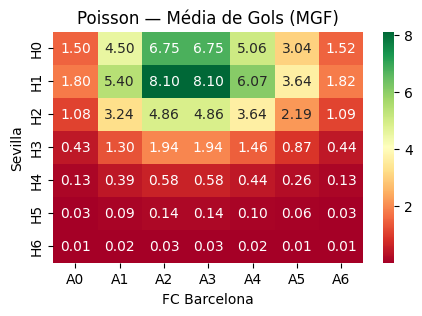


⚽ OVER / UNDER — MGF
Over 0.5: 95.13% | Under 4.87%
Over 1.5: 88.83% | Under 11.17%
Over 2.5: 75.60% | Under 24.40%
Over 3.5: 57.08% | Under 42.92%
Over 4.5: 37.64% | Under 62.36%

🔁 BTTS — MGF
Sim: 64.04% | Não: 35.96%

🧤 CLEAN SHEET — MGF
Home: 4.98%
Away: 29.11%

🏆 TOP 6 PLACARES — ATK x DEF
    Gols_Home Gols_Away  Prob%
15          1         2   9.76
8           1         1   9.29
14          0         2   8.13
7           0         1   7.75
22          1         3   6.83
16          2         2   5.86

📐 MATRIZ DE POISSON — ATK × DEF


,A0,A1,A2,A3,A4,A5,A6
H0,3.69,7.75,8.13,5.69,2.99,1.26,0.44
H1,4.43,9.29,9.76,6.83,3.59,1.51,0.53
H2,2.66,5.58,5.86,4.10,2.15,0.90,0.32
H3,1.06,2.23,2.34,1.64,0.86,0.36,0.13
H4,0.32,0.67,0.70,0.49,0.26,0.11,0.04
H5,0.08,0.16,0.17,0.12,0.06,0.03,0.01
H6,0.02,0.03,0.03,0.02,0.01,0.01,0.00


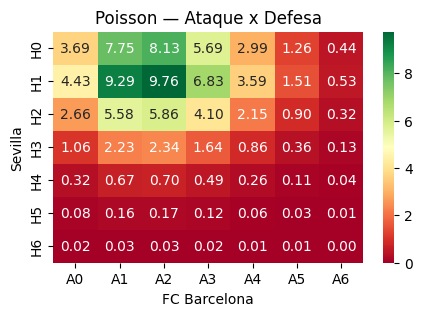


⚽ OVER / UNDER — ATK x DEF
Over 0.5: 95.70% | Under 4.30%
Over 1.5: 83.53% | Under 16.47%
Over 2.5: 63.45% | Under 36.55%
Over 3.5: 41.36% | Under 58.64%
Over 4.5: 23.13% | Under 76.87%

🔁 BTTS — ATK x DEF
Sim: 60.89% | Não: 39.11%

🧤 CLEAN SHEET — ATK x DEF
Home: 12.24%
Away: 29.94%

🏆 TOP 6 PLACARES — VG
    Gols_Home Gols_Away  Prob%
14          0         2  14.22
21          0         3  13.70
28          0         4   9.90
7           0         1   9.84
15          1         2   6.97
22          1         3   6.71

📐 MATRIZ DE POISSON — VG


,A0,A1,A2,A3,A4,A5,A6
H0,3.40,9.84,14.22,13.70,9.90,5.72,2.76
H1,1.67,4.82,6.97,6.71,4.85,2.80,1.35
H2,0.41,1.18,1.71,1.64,1.19,0.69,0.33
H3,0.07,0.19,0.28,0.27,0.19,0.11,0.05
H4,0.01,0.02,0.03,0.03,0.02,0.01,0.01
H5,0.00,0.00,0.00,0.00,0.00,0.00,0.00
H6,0.00,0.00,0.00,0.00,0.00,0.00,0.00


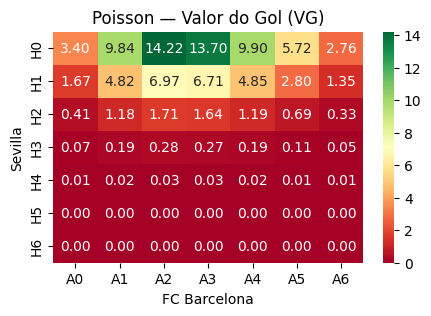


🎯 FULL TIME RESULT (VG)
Casa:   3.91% | Odd Justa: 25.58
Empate: 10.23% | Odd Justa: 9.78
Fora:   83.04% | Odd Justa: 1.2

⚽ OVER / UNDER — VG
Over 0.5: 93.77% | Under 6.23%
Over 1.5: 82.26% | Under 17.74%
Over 2.5: 62.81% | Under 37.19%
Over 3.5: 40.90% | Under 59.10%
Over 4.5: 22.38% | Under 77.62%

🔁 BTTS — VG
Sim: 35.49% | Não: 64.51%

🧤 CLEAN SHEET — VG
Home: 5.56%
Away: 59.53%


In [ ]:
# =========================================================
# BLOCO 8 — VERIFICADOR DETALHADO DE JOGO (PADRÃO V12)
# MODELO: ATK x DEF (IDÊNTICO AO BLOCO 10)
# BASE: df (histórico completo)
# =========================================================

import pandas as pd
import numpy as np
from scipy.stats import poisson
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# PARÂMETROS
# ---------------------------------------------------------
MAX_GOLS = 6

# =========================================================
# FUNÇÃO DEFINITIVA — MGF REAL (5 JOGOS)
# =========================================================
# =========================================================
# FUNÇÃO DEFINITIVA — MGF REAL (VIA PIPELINE CORRETO)
# =========================================================
def calcular_mgf_real(df, team_home, team_away, game_datetime):

    linha = df[
        (df['Home_Team'] == team_home) &
        (df['Visitor_Team'] == team_away) &
        (df['Hour'].dt.floor('min') == pd.to_datetime(game_datetime).floor('min'))
    ]

    if linha.empty:
        return np.nan, np.nan, np.nan, np.nan

    linha = linha.iloc[0]

    return (
        linha["MGF_H"],
        linha["MGC_H"],
        linha["MGF_A"],
        linha["MGC_A"]
    )
# ---------------------------------------------------------
# GARANTE DATETIME
# ---------------------------------------------------------
df['Hour'] = pd.to_datetime(df['Hour'], dayfirst=True, errors='coerce')

# ---------------------------------------------------------
# FUNÇÃO BLINDADA TEXTO → FLOAT
# ---------------------------------------------------------
def to_float(x):
    if pd.isna(x):
        return np.nan
    try:
        return float(str(x).replace(',', '.'))
    except:
        return np.nan

# ---------------------------------------------------------
# DEFINIÇÃO DO JOGO
# ---------------------------------------------------------
Team_Home = 'Sevilla'
Team_Away = 'FC Barcelona'
DATA_TESTE = pd.to_datetime('2026-09-19').date()
# ---------------------------------------------------------
# JOGO DO DIA (ODDS / CONTEXTO)
# ---------------------------------------------------------
jogo = df[
    (df['Home_Team'] == Team_Home) &
    (df['Visitor_Team'] == Team_Away) &
    (df['Hour'].dt.date == DATA_TESTE)
]

if jogo.empty:
    raise RuntimeError("❌ Jogo do dia não encontrado")

jogo = jogo.iloc[0]

MGF_H, MGC_H, MGF_A, MGC_A = calcular_mgf_real(
    df,
    Team_Home,
    Team_Away,
    jogo['Hour']
)

# ---------------------------------------------------------
# OVER / UNDER
# ---------------------------------------------------------
def over_under(lim):
    return sum(matriz_vg[i][j] for i in range(MAX_GOLS+1) for j in range(MAX_GOLS+1) if i+j > lim)
# ---------------------------------------------------------
# ODDS (JOGO DO DIA)
# ---------------------------------------------------------
Odd_H = to_float(jogo.get('Odds_Casa'))
Odd_A = to_float(jogo.get('Odds_Visitante'))
Odd_E = to_float(jogo.get('Odds_Empate'))

Odd_Over_15FT = to_float(jogo.get('Odd_Over_1,5FT'))
Odds_Over_25FT = to_float(jogo.get('Odds_Over_2,5FT'))
Odd_BTTS_YES  = to_float(jogo.get('Odd_BTTS_YES'))
Odd_Over_05HT = to_float(jogo.get('Odd_Over_0,5HT'))

Coef_15FT = (
    to_float(jogo.get('COEF_OVER1FT'))
    if 'COEF_OVER1FT' in jogo.index
    else to_float(jogo.get('Coeficiente_Over_1,5FT'))
    )

# =========================================================
# FUNÇÃO DEFINITIVA — MGF REAL (5 JOGOS)
# =========================================================
def calcular_mgf_real(df, team_home, team_away, game_datetime):

    # HOME — últimos 5 em casa
    jogos_home = (
        df[
            (df['Home_Team'] == team_home) &
            (df['Hour'] < game_datetime)
        ]
        .sort_values('Hour', ascending=False)
        .head(5)
    )

    MGF_H = jogos_home['Result Home'].mean()
    MGC_H = jogos_home['Result Visitor'].mean()

    # AWAY — últimos 5 fora
    jogos_away = (
        df[
            (df['Visitor_Team'] == team_away) &
            (df['Hour'] < game_datetime)
        ]
        .sort_values('Hour', ascending=False)
        .head(5)
    )

    MGF_A = jogos_away['Result Visitor'].mean()
    MGC_A = jogos_away['Result Home'].mean()

    return MGF_H, MGC_H, MGF_A, MGC_A

Media_VG_H = jogo.get('Media_VG_H')
Media_VG_A = jogo.get('Media_VG_A')


CHM = to_float(jogo.get('CHM'))
CAM = to_float(jogo.get('CAM'))
CHS = to_float(jogo.get('CHS'))
CAS = to_float(jogo.get('CAS'))

VR01 = to_float(jogo.get('VR01'))
Coef_15FT = to_float(jogo.get('COEF_OVER1FT'))

# ---------------------------------------------------------
# ExG — MODELOS
# ---------------------------------------------------------
ExG_ATK_DEF_H = round((MGF_H + MGC_A) / 2, 2)
ExG_ATK_DEF_A = round((MGF_A + MGC_H) / 2, 2)

Odd_H = to_float(jogo['Odds_Casa'])
Odd_A = to_float(jogo['Odds_Visitante'])

ExG_Home_VG = round(Media_VG_H * Odd_A, 2) if pd.notna(Media_VG_H) and pd.notna(Odd_A) else np.nan
ExG_Away_VG = round(Media_VG_A * Odd_H, 2) if pd.notna(Media_VG_A) and pd.notna(Odd_H) else np.nan

# ---------------------------------------------------------
# MATRIZES DE POISSON
# ---------------------------------------------------------
def matriz_poisson(lh, la):
    return np.outer(
        [poisson.pmf(i, lh) for i in range(MAX_GOLS+1)],
        [poisson.pmf(j, la) for j in range(MAX_GOLS+1)]
    )

matriz_mgf = matriz_poisson(MGF_H, MGF_A)
matriz_exg = matriz_poisson(ExG_ATK_DEF_H, ExG_ATK_DEF_A)
matriz_vg  = matriz_poisson(ExG_Home_VG, ExG_Away_VG)

# ---------------------------------------------------------
# TOP PLACARES
# ---------------------------------------------------------
def top_placares(matriz, n=6):
    dfp = (pd.DataFrame((matriz * 100).round(2))
        .reset_index().melt(id_vars='index').rename(columns={'index': 'Gols_Home','variable': 'Gols_Away','value': 'Prob%'})
        .sort_values('Prob%', ascending=False).head(n))
    return dfp


# ---------------------------------------------------------
# PROBABILIDADES FT (VG)
# ---------------------------------------------------------
prob_home = sum(matriz_vg[i][j] for i in range(MAX_GOLS+1) for j in range(i))
prob_draw = sum(matriz_vg[i][i] for i in range(MAX_GOLS+1))
prob_away = sum(matriz_vg[i][j] for i in range(MAX_GOLS+1) for j in range(i+1, MAX_GOLS+1))

def safe_odds(p):
    return round(1/p, 2) if p > 0 else np.nan


# ---------------------------------------------------------
# SAÍDA ORGANIZADA
# ---------------------------------------------------------
print("="*90)
print(f"🎯 {Team_Home} x {Team_Away} — {DATA_TESTE}")
print("="*90)

print("\n📌 ODDS")
print(f"Casa: {Odd_H} | Empate: {Odd_E} | Visitante: {Odd_A}")
print(f"Over 1.5FT: {Odd_Over_15FT} | Over 2.5FT: {Odds_Over_25FT}")
print(f"BTTS YES: {Odd_BTTS_YES} | Over 0.5HT: {Odd_Over_05HT}")
print(f"Coef Over 1.5FT: {round(Coef_15FT, 2)}")
print(f"VR01: {round(VR01, 2)}")

print("\n📊 CHUTES - ESTATÍSTICAS")
print(f"CHM: {round(CHM, 2)} | CAM: {round(CAM, 2)}")
print(f"CHS: {round(CHS, 2)} | CAS: {round(CAS, 2)}")



print("\n📊 MÉTRICAS BASE")
print(f"MGF_H: {MGF_H} | MGF_A: {MGF_A}")
print(f"MGC_H: {MGC_H} | MGC_A: {MGC_A}")

print("\n⚙️ ExG")
print(f"ATK×DEF → Home: {ExG_ATK_DEF_H} | Away: {ExG_ATK_DEF_A}")
print(f"VG       → Home: {ExG_Home_VG} | Away: {ExG_Away_VG}")

print("\n🏆 TOP 6 PLACARES — MGF")
print(top_placares(matriz_mgf))

print("\n📐 MATRIZ DE POISSON — MGF")

df_matriz_mgf = pd.DataFrame(
    (matriz_mgf * 100).round(2),
    index=[f'H{i}' for i in range(MAX_GOLS+1)],
    columns=[f'A{j}' for j in range(MAX_GOLS+1)]
)

display(df_matriz_mgf)

plt.figure(figsize=(5,3))
sns.heatmap(df_matriz_mgf, annot=True, fmt=".2f", cmap="RdYlGn")
plt.title("Poisson — Média de Gols (MGF)")
plt.xlabel(Team_Away)
plt.ylabel(Team_Home)
plt.show()

print("\n⚽ OVER / UNDER — MGF")
for l in [0.5,1.5,2.5,3.5,4.5]:
    o = sum(
        matriz_mgf[i][j]
        for i in range(MAX_GOLS+1)
        for j in range(MAX_GOLS+1)
        if i + j > l
    )
    print(f"Over {l}: {o*100:.2f}% | Under {(1-o)*100:.2f}%")

print("\n🔁 BTTS — MGF")
btts_mgf = sum(
    matriz_mgf[i][j]
    for i in range(1,MAX_GOLS+1)
    for j in range(1,MAX_GOLS+1)
)
print(f"Sim: {btts_mgf*100:.2f}% | Não: {(1-btts_mgf)*100:.2f}%")

print("\n🧤 CLEAN SHEET — MGF")
cs_home_mgf = matriz_mgf[:,0].sum()
cs_away_mgf = matriz_mgf[0,:].sum()
print(f"Home: {cs_home_mgf*100:.2f}%")
print(f"Away: {cs_away_mgf*100:.2f}%")


print("\n🏆 TOP 6 PLACARES — ATK x DEF")
print(top_placares(matriz_exg))

print("\n📐 MATRIZ DE POISSON — ATK × DEF")

df_matriz_exg = pd.DataFrame(
 (matriz_exg * 100).round(2),
    index=[f'H{i}' for i in range(MAX_GOLS+1)],
    columns=[f'A{j}' for j in range(MAX_GOLS+1)])

display(df_matriz_exg)

plt.figure(figsize=(5,3))
sns.heatmap(df_matriz_exg, annot=True, fmt=".2f", cmap="RdYlGn")
plt.title("Poisson — Ataque x Defesa")
plt.xlabel(Team_Away)
plt.ylabel(Team_Home)
plt.show()

print("\n⚽ OVER / UNDER — ATK x DEF")
for l in [0.5,1.5,2.5,3.5,4.5]:
    o = sum(
        matriz_exg[i][j]
        for i in range(MAX_GOLS+1)
        for j in range(MAX_GOLS+1)
        if i + j > l
    )
    print(f"Over {l}: {o*100:.2f}% | Under {(1-o)*100:.2f}%")

print("\n🔁 BTTS — ATK x DEF")
btts_exg = sum(
    matriz_exg[i][j]
    for i in range(1,MAX_GOLS+1)
    for j in range(1,MAX_GOLS+1)
)
print(f"Sim: {btts_exg*100:.2f}% | Não: {(1-btts_exg)*100:.2f}%")

print("\n🧤 CLEAN SHEET — ATK x DEF")
cs_home_exg = matriz_exg[:,0].sum()
cs_away_exg = matriz_exg[0,:].sum()
print(f"Home: {cs_home_exg*100:.2f}%")
print(f"Away: {cs_away_exg*100:.2f}%")

print("\n🏆 TOP 6 PLACARES — VG")
print(top_placares(matriz_vg))

print("\n📐 MATRIZ DE POISSON — VG")

df_matriz_vg = pd.DataFrame(
    (matriz_vg * 100).round(2),
    index=[f'H{i}' for i in range(MAX_GOLS+1)],
    columns=[f'A{j}' for j in range(MAX_GOLS+1)]
)

display(df_matriz_vg)

plt.figure(figsize=(5,3))
sns.heatmap(df_matriz_vg, annot=True, fmt=".2f", cmap="RdYlGn")
plt.title("Poisson — Valor do Gol (VG)")
plt.xlabel(Team_Away)
plt.ylabel(Team_Home)
plt.show()



print("\n🎯 FULL TIME RESULT (VG)")
print(f"Casa:   {prob_home*100:.2f}% | Odd Justa: {safe_odds(prob_home)}")
print(f"Empate: {prob_draw*100:.2f}% | Odd Justa: {safe_odds(prob_draw)}")
print(f"Fora:   {prob_away*100:.2f}% | Odd Justa: {safe_odds(prob_away)}")

print("\n⚽ OVER / UNDER — VG")
for l in [0.5,1.5,2.5,3.5,4.5]:
    o = sum(
        matriz_vg[i][j]
        for i in range(MAX_GOLS+1)
        for j in range(MAX_GOLS+1)
        if i + j > l
    )
    print(f"Over {l}: {o*100:.2f}% | Under {(1-o)*100:.2f}%")

print("\n🔁 BTTS — VG")
btts_vg = sum(
    matriz_vg[i][j]
    for i in range(1,MAX_GOLS+1)
    for j in range(1,MAX_GOLS+1)
)
print(f"Sim: {btts_vg*100:.2f}% | Não: {(1-btts_vg)*100:.2f}%")

print("\n🧤 CLEAN SHEET — VG")
cs_home_vg = matriz_vg[:,0].sum()
cs_away_vg = matriz_vg[0,:].sum()
print(f"Home: {cs_home_vg*100:.2f}%")
print(f"Away: {cs_away_vg*100:.2f}%")



# **8.1º - FILTRO FAV-DIA HOME**

In [ ]:
# =========================================================
# BLOCO 8.1 — FAV-HOME (VERSÃO DEFINITIVA DO V18)
# BASE: df (igual BLOCO 8.2)
# =========================================================

# GARANTE DATETIME (DE VERDADE)
df['Hour'] = pd.to_datetime(df['Hour'], dayfirst=True, errors='coerce')

df_dia = df.loc[df['Hour'].dt.date == DATA_TESTE].copy()


print(f"📅 Jogos no dia {DATA_TESTE}: {len(df_dia)}")


# =========================================================
# CONVERSÃO NUMÉRICA (HOME)
# =========================================================
cols_numeric = [
    'Odds_Casa',
    'Media_CG_H_01','CV_CG_H_01',
    'Posse_Bola_Home','Precisao_CG_H',
    'Clean_Games_H','FS_Win_H',
    'MGF_H','CV_GF_H',
    'PPJH','FAH','FDH'
]

for c in cols_numeric:
    if c in df_dia.columns:
        df_dia[c] = pd.to_numeric(df_dia[c], errors='coerce')


# =========================================================
# FILTRO FAV-HOME
# =========================================================
flt = (
    df_dia['Odds_Casa'].between(1.01, 2.10) &
    df_dia['Media_CG_H_01'].between(2.80, 6.00) &
    df_dia['CV_CG_H_01'].between(0.00, 1.00) &
    df_dia['Posse_Bola_Home'].between(45, 100) &
    df_dia['Precisao_CG_H'].between(38, 100) &
    df_dia['Clean_Games_H'].between(40, 100) &
    df_dia['FS_Win_H'].between(40, 100) &
    df_dia['MGF_H'].between(1.4, 10.0) &
    df_dia['CV_GF_H'].between(0.00, 1.00) &
    df_dia['PPJH'].between(1.6, 3.00) &
    df_dia['FAH'].between(50, 100) &
    df_dia['FDH'].between(50, 100)
)


df_filtrado = df_dia.loc[flt].copy()


# =========================================================
# MOSTRAR SÓ COLUNAS DO FILTRO
# =========================================================
cols_flt = [
    'League','Hour','Home_Team','Result Home',
    'Result Visitor','Visitor_Team',
    'Odds_Casa','Media_CG_H_01','CV_CG_H_01',
    'Posse_Bola_Home','Precisao_CG_H',
    'Clean_Games_H','FS_Win_H',
    'MGF_H','CV_GF_H',
    'PPJH','FAH','FDH']

cols_flt = [c for c in cols_flt if c in df_filtrado.columns]
print("✅ Jogos aprovados (HOME):", len(df_filtrado))
display(df_filtrado[cols_flt])


📅 Jogos no dia 2026-09-19: 458
✅ Jogos aprovados (HOME): 29


,League,Hour,Home_Team,Result Home,Result Visitor,Visitor_Team,Odds_Casa,Media_CG_H_01,CV_CG_H_01,Posse_Bola_Home,Precisao_CG_H,Clean_Games_H,FS_Win_H,MGF_H,CV_GF_H,PPJH,FAH,FDH
66241,Northern Territory Premier League,2026-09-19 07:30:00,Uni Azzurri,2.0,4.0,Mindil Aces,1.63,4.60,0.72,100.0,48.0,40.0,100.0,3.8,0.68,3.0,100.0,77.0
66258,2. Bundesliga,2026-09-19 08:00:00,Kaiserslautern,1.0,0.0,Eintracht Braunschweig,1.97,4.37,0.92,80.0,50.0,80.0,60.0,1.6,0.95,2.0,54.0,100.0
66282,Google Pixel Frauen-Bundesliga,2026-09-19 09:00:00,Bayern Munich W,5.0,2.0,Köln W,1.13,3.63,0.72,100.0,55.0,60.0,100.0,2.0,0.61,2.6,88.0,84.0
66294,2nd Division,2026-09-19 09:00:00,Middelfart,1.0,1.0,VSK Århus,1.93,5.82,0.48,100.0,57.0,40.0,60.0,2.6,0.52,2.0,95.0,70.0
66316,3. Division - Group 4,2026-09-19 10:00:00,Vindbjart,0.0,1.0,Mandalskameratene,1.76,4.03,0.50,80.0,58.0,40.0,60.0,3.2,0.56,2.4,95.0,70.0
66336,Kakkonen,2026-09-19 10:00:00,Huima / Urho,3.0,5.0,GBK,1.68,5.49,0.19,100.0,55.0,80.0,100.0,4.2,0.20,3.0,100.0,100.0
66410,Enterprise National League,2026-09-19 11:00:00,Barrow,1.0,0.0,Aldershot Town,1.80,3.08,0.60,75.0,47.0,40.0,40.0,1.4,0.64,1.8,75.0,56.0
66392,1. Lig,2026-09-19 11:00:00,Keçiörengücü,1.0,1.0,Sivasspor,1.68,4.12,0.80,60.0,50.0,40.0,60.0,2.2,0.67,2.2,75.0,77.0
66419,League One,2026-09-19 11:00:00,Oxford United,1.0,1.0,Cambridge United,2.08,4.13,0.58,100.0,58.0,40.0,80.0,2.2,0.67,2.6,95.0,77.0
66476,1. HNL,2026-09-19 12:00:00,Varaždin,0.0,0.0,Osijek,1.92,4.45,0.71,80.0,41.0,60.0,80.0,1.8,0.61,2.6,61.0,84.0


# **8.2º - FILTRO FAV-DIA AWAY**

In [ ]:
# =========================================================
# BLOCO 8.2 — FAV-AWAY (VERSÃO DEFINITIVA DO V18)
# BASE: df (igual BLOCO 8.2)
# =========================================================

# GARANTE DATETIME (DE VERDADE)
df['Hour'] = pd.to_datetime(df['Hour'], dayfirst=True, errors='coerce')

df_dia = df.loc[df['Hour'].dt.date == DATA_TESTE].copy()


print(f"📅 Jogos no dia {DATA_TESTE}: {len(df_dia)}")


cols_numeric = [
    'Odds_Visitante',
    'Media_CG_A_01','CV_CG_A_01',
    'Posse_Bola_Away','Precisao_CG_A',
    'Clean_Games_A','FS_Win_A',
    'MGF_A','CV_GF_A',
    'PPJA','FAA','FDA'
]

for c in cols_numeric:
    if c in df_dia.columns:
        df_dia[c] = pd.to_numeric(df_dia[c], errors='coerce')


flt = (
    df_dia['Odds_Visitante'].between(1.01, 2.30) &
    df_dia['Media_CG_A_01'].between(2.80, 6.00) &
    df_dia['CV_CG_A_01'].between(0.00, 1.30) &
    df_dia['Posse_Bola_Away'].between(40, 100) &
    df_dia['Precisao_CG_A'].between(38, 100) &
    df_dia['Clean_Games_A'].between(0, 100) &
    df_dia['FS_Win_A'].between(40, 100) &
    df_dia['MGF_A'].between(1.4, 10.0) &
    df_dia['CV_GF_A'].between(0.00, 1.30) &
    df_dia['PPJA'].between(1.6, 3.00) &
    df_dia['FAA'].between(50, 100) &
    df_dia['FDA'].between(50, 100)
)

df_filtrado = df_dia.loc[flt].copy()

cols_flt = [
    'League','Hour','Home_Team','Result Home',
    'Result Visitor','Visitor_Team',
    'Odds_Visitante',
    'Media_CG_A_01','CV_CG_A_01',
    'Posse_Bola_Away','Precisao_CG_A',
    'Clean_Games_A','FS_Win_A',
    'MGF_A','CV_GF_A',
    'PPJA','FAA','FDA'
]

cols_flt = [c for c in cols_flt if c in df_filtrado.columns]

print("✅ Jogos aprovados:", len(df_filtrado))

display(df_filtrado[cols_flt])




📅 Jogos no dia 2026-09-19: 458
✅ Jogos aprovados: 14


,League,Hour,Home_Team,Result Home,Result Visitor,Visitor_Team,Odds_Visitante,Media_CG_A_01,CV_CG_A_01,Posse_Bola_Away,Precisao_CG_A,Clean_Games_A,FS_Win_A,MGF_A,CV_GF_A,PPJA,FAA,FDA
66253,Superettan,2026-09-19 08:00:00,Öster,1.0,3.0,Norrköping,1.72,4.84,0.37,80.0,38.0,40.0,60.0,2.4,0.48,2.6,75.0,84.0
66272,Super League Women,2026-09-19 08:30:00,St. Liege W,0.0,5.0,OH Leuven W,1.35,3.05,1.00,60.0,48.0,40.0,40.0,1.6,0.95,1.8,61.0,77.0
66313,Allsvenskan,2026-09-19 10:00:00,Västerås SK,2.0,0.0,Malmö FF,2.00,3.75,0.32,60.0,57.0,40.0,80.0,1.4,0.39,2.6,75.0,77.0
66335,Ykkösliiga,2026-09-19 10:00:00,MP,1.0,0.0,JIPPO,1.90,3.04,0.63,60.0,55.0,40.0,60.0,1.6,0.71,2.0,54.0,70.0
66349,Chance Liga,2026-09-19 10:00:00,SK Artis Brno,0.0,0.0,Slovan Liberec,1.62,5.70,1.04,80.0,47.0,80.0,100.0,1.6,0.56,3.0,54.0,100.0
66378,League One,2026-09-19 11:00:00,Sheffield Wednesday,0.0,0.0,Stockport County,2.13,4.61,0.85,60.0,58.0,40.0,60.0,1.8,0.91,1.8,61.0,56.0
66433,League One,2026-09-19 11:00:00,Cove Rangers,0.0,2.0,Ross County,1.38,4.09,0.43,80.0,60.0,20.0,60.0,2.2,0.38,2.6,68.0,70.0
66481,Allsvenskan,2026-09-19 12:30:00,Örgryte,1.0,2.0,Sirius,1.43,4.07,0.50,40.0,60.0,60.0,80.0,2.2,0.38,2.4,75.0,70.0
66500,Superliga,2026-09-19 13:00:00,Odense BK,1.0,1.0,FC Midtjylland,1.69,4.86,0.72,80.0,46.0,40.0,40.0,3.0,0.85,2.2,100.0,84.0
66528,Super Lig,2026-09-19 14:00:00,Trabzonspor,4.0,0.0,Galatasaray,2.16,3.43,0.73,100.0,52.0,20.0,40.0,1.8,0.91,1.8,88.0,56.0


In [ ]:
print("DATA_TESTE:", DATA_TESTE)
print("Min df:", df['Hour'].min())
print("Max df:", df['Hour'].max())


DATA_TESTE: 2026-09-19
Min df: 2025-02-01 00:00:00
Max df: 2026-10-13 23:00:00


# **8.3º - ZEBRA HOME (ODDS ESTRANHAS)**

In [ ]:
if 'DATA_TESTE' not in globals():
    raise RuntimeError("❌ ERRO: DATA_TESTE não foi definida. Execute o BLOCO 1 antes do BLOCO 8.")

print(f"📅 DATA_TESTE ATIVA: {DATA_TESTE}")

# =========================================================
# FUNÇÃO PADRÃO — TEXTO → FLOAT (BLINDAGEM TOTAL)
# =========================================================
def to_float(x):
    if pd.isna(x):
        return np.nan
    x = str(x).strip().replace(',', '.')
    try:
        return float(x)
    except:
        return np.nan

# =========================================================
# GARANTE DATETIME
# =========================================================
pd.to_datetime(df['Hour'], dayfirst=True, errors='coerce')

# =========================================================
# FILTRA APENAS JOGOS DO DIA (HISTÓRICO)
# ⚠️ DATA_TESTE é date → usar .dt.date
# =========================================================
df_dia = df[df['Hour'].dt.date == DATA_TESTE].copy()

print(f"📅✅☑️ Jogos históricos no dia {DATA_TESTE}: {len(df_dia)}")

# =========================================================
# COLUNAS NUMÉRICAS USADAS NO FILTRO
# =========================================================
cols_numeric = [
    'Odds_Casa',
    'Media_CG_H_01','CV_CG_H_01',
    'Posse_Bola_Home','Precisao_CG_H',
    'Clean_Games_H','FS_Win_H',
    'MGF_H','CV_GF_H',
    'PPJH','FAH','FDH'
]

for c in cols_numeric:
    if c in df_dia.columns:
        df_dia[c] = df_dia[c].apply(to_float)

# =========================================================
# LISTA DE TIMES DO DIA (HOME)
# =========================================================
times_dia = df_teams['Home_Team'].dropna().unique().tolist()
print("🏠 Times do dia (Home):", len(times_dia))

# =========================================================
# FILTRO AVANÇADO — CORE DO BLOCO 8
# =========================================================
flt = (
    df_dia['Home_Team'].isin(times_dia) &
    df_dia['Odds_Casa'].between(2.00, 5.00) &
    df_dia['Media_CG_H_01'].between(3.00, 6.00) &
    df_dia['CV_CG_H_01'].between(0.00, 1.00) &
    df_dia['Posse_Bola_Home'].between(60, 100) &
    df_dia['Precisao_CG_H'].between(38, 100) &
    df_dia['Clean_Games_H'].between(40, 100) &
    df_dia['FS_Win_H'].between(40, 100) &
    df_dia['MGF_H'].between(1.6, 10.0) &
    df_dia['CV_GF_H'].between(0.00, 1.00) &
    df_dia['PPJH'].between(1.6, 3.00) &
    df_dia['FAH'].between(60, 100) &
    df_dia['FDH'].between(50, 100)
)

df_filtrado = df_dia[flt].copy()

print("✅☑️ Jogos aprovados no BLOCO 8:", len(df_filtrado))

# =========================================================
# COLUNAS DE EXIBIÇÃO
# =========================================================
cols_exibir = [
    'League','Hour',
    'Home_Team','Visitor_Team',
    'Result Home','Result Visitor',
    'Odds_Casa','Odds_Visitante','Odds_Empate',
    'FAH','FDH',
    'MGF_H','CV_GF_H','MGC_H','CV_GC_H',
    'Media_VG_H','PPJH'
]

cols_exibir = [c for c in cols_exibir if c in df_filtrado.columns]

display(df_filtrado[cols_exibir])

📅 DATA_TESTE ATIVA: 2026-09-19
📅✅☑️ Jogos históricos no dia 2026-09-19: 458
🏠 Times do dia (Home): 102
✅☑️ Jogos aprovados no BLOCO 8: 1


,League,Hour,Home_Team,Visitor_Team,Result Home,Result Visitor,Odds_Casa,Odds_Visitante,Odds_Empate,FAH,FDH,MGF_H,CV_GF_H,MGC_H,CV_GC_H,Media_VG_H,PPJH
66506,Serie A,2026-09-19 13:00:00,Roma,Inter,2.0,2.0,2.7,2.59,3.4,88.0,100.0,2.6,0.52,0.4,1.38,0.5,2.6


**9º - RESULTADOS SEM PROBABILIDADES FORMATADOS**

In [ ]:
# =========================================================
# FUNÇÃO DEFINITIVA — MGF REAL
# ÚLTIMOS 5 JOGOS ANTERIORES À PARTIDA
# =========================================================
def calcular_mgf_real(df, team_home, team_away, game_datetime):

    # 🔵 HOME → últimos 5 jogos do time COMO HOME
    jogos_home = (
        df[
            (df['Home_Team'] == team_home) &
            (df['Hour'] < game_datetime)
        ]
        .sort_values('Hour', ascending=False)
        .head(5)
    )

    # 🔴 AWAY → últimos 5 jogos do time COMO AWAY
    jogos_away = (
        df[
            (df['Visitor_Team'] == team_away) &
            (df['Hour'] < game_datetime)
        ]
        .sort_values('Hour', ascending=False)
        .head(5)
    )

    # Precisamos dos 5 jogos completos
    if len(jogos_home) < 5 or len(jogos_away) < 5:
        return np.nan, np.nan, np.nan, np.nan

    # 🔵 HOME
    MGF_H = jogos_home['Result Home'].mean()
    MGC_H = jogos_home['Result Visitor'].mean()

    # 🔴 AWAY
    MGF_A = jogos_away['Result Visitor'].mean()
    MGC_A = jogos_away['Result Home'].mean()

    return MGF_H, MGC_H, MGF_A, MGC_A


# =========================================================
# 9º — BLOCO FINAL ÚNICO (PADRÃO 9.1 REAL)
# FUNÇÃO: ENRIQUECER df_v_teams + EXPORTAR
# DF USADOS: df | df_v_teams
# =========================================================

# =========================================================
# FUNÇÕES
# =========================================================
def safe_odds(prob, min_prob=0.01):
    if pd.isna(prob):
        return np.nan
    prob = max(prob, min_prob)
    return round(1 / prob, 2)


# =========================================================
# FULL TIME (mantido)
# =========================================================
def calcular_probabilidades_ft(exg_home, exg_away, max_goals=8):

    if pd.isna(exg_home) or pd.isna(exg_away):
        return np.nan, np.nan, np.nan

    prob_home = prob_draw = prob_away = 0.0

    for gh in range(max_goals + 1):
        for ga in range(max_goals + 1):
            p = poisson.pmf(gh, exg_home) * poisson.pmf(ga, exg_away)

            if gh > ga:
                prob_home += p
            elif gh == ga:
                prob_draw += p
            else:
                prob_away += p

    return prob_home, prob_draw, prob_away


# =========================================================
# 🔥 OVER / UNDER — AGORA EXATO (SEM TRUNCAMENTO)
# =========================================================
def calcular_over_under(exg_home, exg_away, limite):

    if pd.isna(exg_home) or pd.isna(exg_away):
        return np.nan, np.nan

    lam = exg_home + exg_away

    under = poisson.cdf(int(limite), lam)
    over  = 1 - under

    return round(over * 100, 2), round(under * 100, 2)


# =========================================================
# 🔥 BTTS — NOVO (EXATO)
# =========================================================
def calcular_btts(exg_home, exg_away):

    if pd.isna(exg_home) or pd.isna(exg_away):
        return np.nan

    p_h0 = poisson.pmf(0, exg_home)
    p_a0 = poisson.pmf(0, exg_away)

    btts = 1 - p_h0 - p_a0 + (p_h0 * p_a0)

    return round(btts * 100, 2)

# =========================================================
# 🔥 PRIMEIRO GOL
# =========================================================
def calcular_primeiro_gol(
    exg_home, exg_away, matriz,
    CHM=None, CAM=None
):

    if pd.isna(exg_home) or pd.isna(exg_away):
        return np.nan, np.nan

    lam_total = exg_home + exg_away
    if lam_total == 0:
        return np.nan, np.nan

    p_zero = matriz[0,0] if matriz.size else 0

    base_home = exg_home / lam_total
    base_away = exg_away / lam_total

    ajuste_home = 1
    ajuste_away = 1

    if pd.notna(CHM) and pd.notna(CAM):

        total = CHM + CAM
        if total > 0:
            ajuste_home = CHM / total
            ajuste_away = CAM / total

    home = (0.7 * base_home + 0.3 * ajuste_home) * (1 - p_zero)
    away = (0.7 * base_away + 0.3 * ajuste_away) * (1 - p_zero)

    return round(home*100,2), round(away*100,2)

# =========================================================
# ORDEM TRAVADA DAS COLUNAS
# =========================================================
ORDEM_COLUNAS_EXCEL = [
    'Home_Team','Visitor_Team',
    'ExG_Home_VG','ExG_Away_VG',
    'Odds_Home','Odds_Draw','Odds_Away','Odds_Empate',
    'PPJH','PPJA',
    'MGF_H','CV_GF_H','MGC_H','CV_GC_H',
    'MGF_A','CV_GF_A','MGC_A','CV_GC_A',
    'Media_CG_H_01','CV_CG_H_01','Media_CG_A_01','CV_CG_A_01',
    'FAH','FAA','FDH','FDA',
    'CHM','CAM','CHS','CAS',
    'VR01',
    'COEF_OVER1FT',
    'Odd_Over_1,5FT','Odd_BTTS_YES','Odd_Over_0,5HT',
    'Melhor_Aposta',
    'Over_0.5','Under_0.5',
    'Over_1.5','Under_1.5',
    'Over_2.5','Under_2.5',
    'Over_3.5','Under_3.5',
    'Over_4.5','Under_4.5',
    'BTTS_%',                      # 🔥 NOVO
    'Clean_Sheet_Home','Clean_Sheet_Away'
]


# =========================================================
# BASE
# =========================================================
df_resultados = df_v_teams.copy()

# 🔧 CORRIGIDO — esse rename procurava 'Coeficiente_Over_1,5FT', nome que nunca
# existiu no df (a coluna real sempre foi 'COEF_OVER1,5FT'), então nunca disparava
# e 'COEF_OVER1FT' ficava sem valor. Já resolvido na origem (Bloco 4, onde a
# coluna é criada), então esse bloco não é mais necessário.

for c in ORDEM_COLUNAS_EXCEL:
    if c not in df_resultados.columns:
        df_resultados[c] = np.nan


# =========================================================
# LOOP
# =========================================================
for idx, row in df_resultados.iterrows():

    Team_Home = row['Home_Team']
    Team_Away = row['Visitor_Team']
    game_datetime = row['Hour']

    MGF_H, MGC_H, MGF_A, MGC_A = calcular_mgf_real(
    df,
    Team_Home,
    Team_Away,
    game_datetime
)

    try:

        df_resultados.at[idx,'MGF_H'] = MGF_H
        df_resultados.at[idx,'MGC_H'] = MGC_H
        df_resultados.at[idx,'MGF_A'] = MGF_A
        df_resultados.at[idx,'MGC_A'] = MGC_A


        Odd_H = float(str(row['Odds_Casa']).replace(',', '.'))
        Odd_A = float(str(row['Odds_Visitante']).replace(',', '.'))
        Odd_D = float(str(row['Odds_Empate']).replace(',', '.'))

        ExG_H = np.sqrt(MGF_H * MGC_A)
        ExG_A = np.sqrt(MGF_A * MGC_H)

        # CAP DE ESTABILIDADE
        ExG_H = min(ExG_H, 5)
        ExG_A = min(ExG_A, 5)


        pH, pD, pA = calcular_probabilidades_ft(ExG_H, ExG_A)

        df_resultados.at[idx,'ExG_Home_VG'] = round(ExG_H,2)
        df_resultados.at[idx,'ExG_Away_VG'] = round(ExG_A,2)

        df_resultados.at[idx,'Odds_Home'] = safe_odds(pH)
        df_resultados.at[idx,'Odds_Draw'] = safe_odds(pD)
        df_resultados.at[idx,'Odds_Away'] = safe_odds(pA)
        df_resultados.at[idx,'Odds_Empate'] = Odd_D


        # OVER/UNDER EXATO
        for lim in [0.5,1.5,2.5,3.5,4.5]:
            over, under = calcular_over_under(ExG_H, ExG_A, lim)
            df_resultados.at[idx,f'Over_{lim}'] = over
            df_resultados.at[idx,f'Under_{lim}'] = under


        # BTTS EXATO
        df_resultados.at[idx,'BTTS_%'] = calcular_btts(ExG_H, ExG_A)


        # CLEAN SHEET (já correto)
        df_resultados.at[idx,'Clean_Sheet_Home'] = round(poisson.pmf(0, ExG_A)*100,2)
        df_resultados.at[idx,'Clean_Sheet_Away'] = round(poisson.pmf(0, ExG_H)*100,2)

    except:
        continue


# =========================================================
# EXPORTAÇÕES
# =========================================================
df_resultados.to_excel('JOGOS_IA_COMPLETO.xlsx', index=False)

df_saida = df_resultados.dropna(
    subset=['ExG_Home_VG','ExG_Away_VG']
)[ORDEM_COLUNAS_EXCEL]

df_saida.to_excel('RESULTADOS_SEM_PROBS.xlsx', index=False)

wb = load_workbook('RESULTADOS_SEM_PROBS.xlsx')
ws = wb.active

for row in ws.iter_rows():
    for cell in row:
        cell.font = Font(size=16)
        cell.alignment = Alignment(horizontal='center', vertical='center')

wb.save('RESULTADOS_SEM_PROBS_FORMATADO.xlsx')

print("✅☑️ BLOCO 9 FINAL — CORRIGIDO SEM QUEBRAR NADA")


✅☑️ BLOCO 9 FINAL — CORRIGIDO SEM QUEBRAR NADA


 **10º - MATRIZ - CS SCORE E BTTS**

In [ ]:
# =========================================================
# BLOCO 10 — POISSON FINAL (PADRÃO V9 / V12 DEFINITIVO)
# =========================================================

def interpretar_forca_mix(home, away,
                          prob_home, prob_away,
                          odd_home, odd_away,
                          exg_h, exg_a,
                          vr01, coef):

    frases = []

    # =========================
    # SCORE HÍBRIDO (FORÇA)
    # =========================
    edge_prob = prob_home - prob_away
    edge_odds = (1/odd_home if odd_home else 0) - (1/odd_away if odd_away else 0)
    edge_exg  = (exg_h - exg_a) / 3

    score = edge_prob*0.5 + edge_odds*0.3 + edge_exg*0.2

    if score > 0.35:
        frases.append(f"Domínio do {home}")
    elif score > 0.15:
        frases.append(f"{home} favorito")
    elif score < -0.35:
        frases.append(f"Domínio do {away}")
    elif score < -0.15:
        frases.append(f"{away} favorito")
    else:
        frases.append("Jogo equilibrado")

    # =========================
    # MERCADO DE GOLS (COEF)
    # =========================
    if pd.notna(coef):
        if coef >= 1.95:
            frases.append("Tendência Over 1,5FT")
        elif coef <= 1.70:
            frases.append("Tendência Under")

    # =========================
    # VR01 (estrutura BTTS x favorito)
    # =========================
    if pd.notna(vr01):
        if vr01 >= 0.12:
            frases.append("Gols do Favorito")
        elif vr01 <= -0.10:
            frases.append("BTTS / Jogo Aberto")

    return " | ".join(frases)


# =========================
# PARÂMETROS
# =========================
MAX_GOLS = 5
TOP_CS = 6

def score_defensivo(fd, clean_sheet, chs, mgc):

    if pd.isna(fd): fd = 50
    if pd.isna(clean_sheet): clean_sheet = 30
    if pd.isna(chs) or chs == 0: chs = 10
    if pd.isna(mgc) or mgc == 0: mgc = 1

    resistencia = min((chs / 15) * 100, 100)
    concessao = max(0, 100 - (mgc * 40))

    score = (
        fd * 0.35 +
        clean_sheet * 0.25 +
        resistencia * 0.20 +
        concessao * 0.20
    )

    return round(score,1)


# =========================================================
# FUNÇÕES AUXILIARES
# =========================================================

def matriz_poisson(lh, la):
    return np.outer(
        [poisson.pmf(i, lh) for i in range(MAX_GOLS + 1)],
        [poisson.pmf(j, la) for j in range(MAX_GOLS + 1)]
    )


# =====================================================
# POISSON DE CANTOS
# =====================================================

MAX_CANTOS = 12

def matriz_poisson_cantos(lh, la):

    return np.outer(
        [poisson.pmf(i, lh) for i in range(MAX_CANTOS + 1)],
        [poisson.pmf(j, la) for j in range(MAX_CANTOS + 1)]
    )


def placar_cantos_mais_provavel(matriz):

    if matriz.size == 0 or np.all(np.isnan(matriz)):
        return np.nan

    i, j = np.unravel_index(np.argmax(matriz), matriz.shape)

    return f"{i}x{j}"


def prob_over_cantos(matriz, linha):

    prob = 0

    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):

            if (i + j) > linha:
                prob += matriz[i][j]

    return prob


def safe_odds(p):
    return round(1 / p, 2) if pd.notna(p) and p > 0 else np.nan


def placar_mais_provavel(matriz):
    if matriz.size == 0 or np.all(np.isnan(matriz)):
        return np.nan
    i, j = np.unravel_index(np.argmax(matriz), matriz.shape)
    return f'{i}x{j}'


def criterio_lay(matriz, top_n=5):
    pares = [
        (
            matriz[i][j],
            i,
            j
        )
        for i in range(matriz.shape[0])
        for j in range(matriz.shape[1])
    ]

    top = sorted(pares, reverse=True)[:top_n]

    home_win = any(i > j for _, i, j in top)
    away_win = any(i < j for _, i, j in top)

    return (not home_win), (not away_win)


# BTTS (TESTE)
def calcular_btts_e_odd(matriz):
    prob = sum(
        matriz[i][j]
        for i in range(1, MAX_GOLS + 1)
        for j in range(1, MAX_GOLS + 1)
    )

    pct = prob * 100
    odd = safe_odds(prob)

    return round(pct, 2), odd


# =========================================================
# BASE DOS JOGOS DO DIA (FORA DO LOOP)
# =========================================================
df_jogos = df_v_teams.copy()

# =========================================
# 🔎 FILTRO DIRETO (SEM FUNÇÃO) ELIMINAR JOGOS SEM ODDS 1X2 SUPER FAVORITOS X SUPER ZEBRAS
# =========================================

df_jogos = df_jogos[
    ~df_jogos["Home_Team"].str.lower().str.contains("u19|u18|women| w", na=False) &
    ~df_jogos["Visitor_Team"].str.lower().str.contains("u19|u18|women| w", na=False)
]

df_jogos = df_jogos[
    (df_jogos["Odds_Casa"] >= 1.01) & (df_jogos["Odds_Casa"] <= 42.00) &
    (df_jogos["Odds_Visitante"] >= 1.01) & (df_jogos["Odds_Visitante"] <= 42.00)
]

df_jogos['Hour'] = pd.to_datetime(
    df_jogos['Hour'], dayfirst=True, errors='coerce'
)
df['Hour'] = pd.to_datetime(df['Hour'], dayfirst=True, errors='coerce')

# =========================================
# 🧹 FILTRO SIMPLES — ODDS VAZIAS
# =========================================

df_jogos = df_jogos[
    df_jogos["Odds_Casa"].notna() &
    df_jogos["Odds_Visitante"].notna()
]

print('✅ Após filtro de odds válidas:', len(df_jogos))

print('📅 Jogos recebidos no Bloco 10:', len(df_jogos))
# =========================================================
def calcular_primeiro_gol(
    matriz, H, A, jogo,
    MGF_H, MGF_A, MGC_H, MGC_A,
    CHM, CAM, CHS, CAS, EPS
):

    # Check for NaN values before calculations
    if any(pd.isna(x) for x in [MGF_H, MGF_A, MGC_H, MGC_A, CHM, CAM, CHS, CAS]):
        return np.nan, np.nan

    # =========================
    # PROBABILIDADE 0x0
    # =========================
    if matriz.size == 0 or np.all(np.isnan(matriz)):
        p_zero = np.nan
    else:
        p_zero = matriz[0,0]

    # =========================
    # ATAQUE / DEFESA
    # =========================
    ATAQUE_H = MGF_H
    ATAQUE_A = MGF_A

    DEFESA_H = MGC_H
    DEFESA_A = MGC_A

    # =========================
    # INTENSIDADE INICIAL
    # =========================
    INT_H = H.get('GF_0NaN5_Home',0) + H.get('GF_16-30_Home',0)
    INT_A = A.get('GF_0NaN5_Away',0) + A.get('GF_16-30_Away',0)

    DEF_INT_H = H.get('GC_0NaN5_Home',0) + H.get('GC_16-30_Home',0)
    DEF_INT_A = A.get('GC_0NaN5_Away',0) + A.get('GC_16-30_Away',0)

    # =========================
    # HISTÓRICO PRIMEIRO GOL
    # =========================
    HIST_H = H.get('Scored_First_H',0) / (
        H.get('Scored_First_H',0) +
        H.get('Conceded_First_H',0) + EPS
    )

    HIST_A = A.get('Scored_First_A',0) / (
        A.get('Scored_First_A',0) +
        A.get('Conceded_First_A',0) + EPS
    )

    # =========================
    # PRESSÃO OFENSIVA
    # =========================

    Precisao_CG_H = jogo.get('Precisao_CG_H', 0)
    Precisao_CG_A = jogo.get('Precisao_CG_A', 0)

    Eficiencia_H = jogo.get('Eficiência_H', jogo.get('Eficiencia_H', 0))
    Eficiencia_A = jogo.get('Eficiência_A', jogo.get('Eficiencia_A', 0))


    OFEN_H = (
    (Precisao_CG_H/100) *
    (Eficiencia_H/100) *
    np.sqrt(CHM))

    OFEN_A = (
    (Precisao_CG_A/100) *
    (Eficiencia_A/100) *
    np.sqrt(CAM))

    # =================================================
    # FGI (SEU MODELO)
    # =================================================
    FGI_H = OFEN_H * (DEF_INT_A + CAS + DEFESA_A) * (INT_H + HIST_H + ATAQUE_H)
    FGI_A = OFEN_A * (DEF_INT_H + CHS + DEFESA_H) * (INT_A + HIST_A + ATAQUE_A)

    if (FGI_H + FGI_A) == 0:
        return np.nan, np.nan

    # =================================================
    # NORMALIZAÇÃO FGI
    # =================================================
    metric_home = FGI_H / (FGI_H + FGI_A)
    metric_away = FGI_A / (FGI_H + FGI_A)

    # =================================================
    # SHARE POISSON
    # =================================================
    lambda_home = (MGF_H + MGC_A) / 2
    lambda_away = (MGF_A + MGC_H) / 2

    if (lambda_home + lambda_away) == 0:
        return np.nan, np.nan

    total_lambda = lambda_home + lambda_away + EPS

    poisson_home = lambda_home / total_lambda
    poisson_away = lambda_away / total_lambda

    # =================================================
    # MESCLA 70 / 30
    # =================================================
    home_share = (0.7 * poisson_home) + (0.3 * metric_home)
    away_share = (0.7 * poisson_away) + (0.3 * metric_away)

    # =================================================
    # AJUSTE 0x0
    # =================================================
    fator_gol = (1 - p_zero) if pd.notna(p_zero) else 1

    home = home_share * fator_gol
    away = away_share * fator_gol

    return round(home*100,2), round(away*100,2)

# =========================================================
# MÉTRICAS HT - FUNÇÕES
# =========================================================
def calcular_lambda_ht(jogo, H, A, consenso):

    def safe(x):
        return 0 if pd.isna(x) else x

        # ===== ATAQUE HT =====
    atk_home = (
        safe(H.get("MCGS_HT_H")) * 0.35 +
        (safe(H.get("Eficiência_HT_H")) / 100) * 0.25 +
        (safe(H.get("GF_0-15_Home")) +
         safe(H.get("GF_16-30_Home")) +
         safe(H.get("GF_31-45_Home"))) * 1.2
    )

    atk_away = (
        safe(A.get("MCGS_HT_A")) * 0.35 +
        (safe(A.get("Eficiência_HT_A")) / 100) * 0.25 +
        (safe(A.get("GF_0-15_Away")) +
         safe(A.get("GF_16-30_Away")) +
         safe(A.get("GF_31-45_Away"))) * 1.2
    )

    # ===== FRAGILIDADE DEFENSIVA =====
    def_home = (
        safe(H.get("MCGC_HT_H")) * 0.5 +
        safe(H.get("CFHT_H")) * 0.5
    )

    def_away = (
        safe(A.get("MCGC_HT_A")) * 0.5 +
        safe(A.get("CFHT_A")) * 0.5
    )

    # ===== PRESSÃO INICIAL =====
    press_home = (
        safe(jogo.get("Posse_Bola_Home")) * 0.3 +
        safe(jogo.get("Pressão_Média_Home")) * 0.4 +
        safe(jogo.get("APPM_Home")) * 0.3
    )

    press_away = (
        safe(jogo.get("Posse_Bola_Away")) * 0.3 +
        safe(jogo.get("Pressão_Média_Away")) * 0.4 +
        safe(jogo.get("APPM_Away")) * 0.3
    )

    # ===== INTENSIDADE DO JOGO =====
    exg_total = safe(consenso.get("ExG_Total"))
    score = safe(consenso.get("Score_Ofensivo"))
    tendencia = consenso.get("Tendencia_Gols")

    intensidade = (
        exg_total * 1.2 +
        score * 0.5 +
        (12 if tendencia in ["ALTA","ALTÍSSIMA"] else 0)
    )

    # ===== FORÇA FINAL =====
    forca_home = atk_home*0.4 + def_away*0.3 + press_home*0.2 + intensidade*0.1
    forca_away = atk_away*0.4 + def_home*0.3 + press_away*0.2 + intensidade*0.1

    # normaliza para escala de gols HT
    lambda_home = max(forca_home / 25, 0)
    lambda_away = max(forca_away / 25, 0)

    return lambda_home, lambda_away


def poisson_ht(lambda_home, lambda_away):

    matriz = np.outer(
        [poisson.pmf(i, lambda_home) for i in range(3)],
        [poisson.pmf(j, lambda_away) for j in range(3)]
    )

    prob_0x0 = matriz[0,0]

    prob_gol = 1 - prob_0x0
    prob_home = matriz[1:, :].sum()
    prob_away = matriz[:, 1:].sum()

    return (
        round(prob_gol*100,2),
        round(prob_0x0*100,2),
        round(prob_home*100,2),
        round(prob_away*100,2)
    )


# =========================================
# 🧠 POISSON INTELLIGENCE (CORRIGIDO)
# =========================================
def poisson_intelligence(matriz):

    pares = [
        (matriz[i][j], i, j)
        for i in range(matriz.shape[0])
        for j in range(matriz.shape[1])
    ]

    top = sorted(pares, reverse=True)[:6]

    home_wins = sum(p for p, i, j in top if i > j)
    away_wins = sum(p for p, i, j in top if i < j)

    direcao = []

    if home_wins > away_wins:
        direcao.append("Lay Away")
    elif away_wins > home_wins:
        direcao.append("Lay Home")

    return top, None, direcao

# =========================================
# 🤖 DIREÇÃO IA (COM EMOJI + SEM VAZIO)
# =========================================
def direcao_ia_peso(sinais_mgf, sinais_exg, sinais_vg):

    def get_dir(s):
        try:
            if not s:
                return None

            for item in s:
                if isinstance(item, list):
                    for val in item:
                        if isinstance(val, str):
                            if "Lay Home" in val:
                                return "Lay Home"
                            if "Lay Away" in val:
                                return "Lay Away"
            return None
        except:
            return None

    d_mgf = get_dir(sinais_mgf)
    d_exg = get_dir(sinais_exg)
    d_vg  = get_dir(sinais_vg)

    pesos = {
        "MGF": 0.40,
        "EXG": 0.35,
        "VG":  0.25
    }

    score = {}

    if d_mgf:
        score[d_mgf] = score.get(d_mgf, 0) + pesos["MGF"]

    if d_exg:
        score[d_exg] = score.get(d_exg, 0) + pesos["EXG"]

    if d_vg:
        score[d_vg] = score.get(d_vg, 0) + pesos["VG"]

    # 🔥 NÃO DEIXA MAIS VAZIO
    if not score:
        return "❌ Sem sinal"

    direcao_final = max(score, key=score.get)
    confianca = score[direcao_final]

    if confianca >= 0.80:
        return f"🔥🔥 {direcao_final} ({round(confianca*100)}%)"
    elif confianca >= 0.60:
        return f"🔥 {direcao_final} ({round(confianca*100)}%)"
    elif confianca > 0:
        return f"⚠️ {direcao_final} ({round(confianca*100)}%)"

    return "❌ Sem sinal"


# =========================================================
# PROCESSAMENTO
# =========================================================
saida_mgf = []
saida_exg = []
saida_vg = []
saida_consenso = []   # ⭐ NOVO
scores_brutos = [] # Initialize scores_brutos here
saida_ht = [] # Initialize saida_ht here
saida_cantos = []

for _, jogo in df_jogos.iterrows():

    Team_Home = jogo["Home_Team"]
    Team_Away = jogo["Visitor_Team"]

    game_datetime = jogo["Hour"]

    # =========================================
    # HISTÓRICO ATÉ O JOGO
    # =========================================

    df_hist = df[
        df["Hour"] < game_datetime
    ].copy()

    # =========================================
    # MGF REAL
    # =========================================

    MGF_H, MGC_H, MGF_A, MGC_A = calcular_mgf_real(
        df_hist,
        Team_Home,
        Team_Away,
        game_datetime
    )

    # =========================================
    # ÚLTIMO JOGO EM CASA
    # =========================================

    H = df_hist[
        df_hist["Home_Team"] == Team_Home
    ].sort_values(
        "Hour"
    ).iloc[-1:]

    # =========================================
    # ÚLTIMO JOGO FORA
    # =========================================

    A = df_hist[
        df_hist["Visitor_Team"] == Team_Away
    ].sort_values(
        "Hour"
    ).iloc[-1:]

    # =========================================
    # VALIDAÇÃO
    # =========================================

    if H.empty or A.empty:
        continue

    H = H.iloc[0]
    A = A.iloc[0]

    # =========================
    # MÉTRICAS
    # =========================

    CV_GF_H = H.get("CV_GF_H")
    CV_GC_H = H.get("CV_GC_H")
    CV_GF_A = A.get("CV_GF_A")
    CV_GC_A = A.get("CV_GC_A")


    # =========================
    # HISTÓRICO EXTRA
    # =========================
    VR01 = H.get('VR01')

    CHM = round(H['CHM'], 2) if pd.notna(H.get('CHM')) else np.nan
    CHS = round(H['CHS'], 2) if pd.notna(H.get('CHS')) else np.nan
    CAM = round(A['CAM'], 2) if pd.notna(A.get('CAM')) else np.nan
    CAS = round(A['CAS'], 2) if pd.notna(A.get('CAS')) else np.nan

    COEF_OVER1FT = round(H['COEF_OVER1FT'], 2) if pd.notna(H.get('COEF_OVER1FT')) else np.nan


    # =========================
    # ODDS DO JOGO
    # =========================
    Odd_Over_15FT = jogo.get('Odd_Over_1,5FT')
    Odds_Over_25FT = jogo.get('Odds_Over_2,5FT')
    Odds_Under_25FT = jogo.get('Odds_Under_2,5FT')
    Odd_BTTS_YES = jogo.get('Odd_BTTS_YES')




    # =====================================================
    # BASE CRUA
    # =====================================================
    base = {
        'League': jogo.get('League'),
        'Hour': jogo.get('Hour'),
        'Home_Team': jogo.get('Home_Team'),
        'Result Home': jogo.get('Result Home'),
        'Result Visitor': jogo.get('Result Visitor'),
        'Visitor_Team': jogo.get('Visitor_Team'),
        'Result_Home_HT': jogo.get('Result_Home_HT'),
        'Result_Visitor_HT': jogo.get('Result_Visitor_HT'),
        'Odds_Casa': jogo.get('Odds_Casa'),
        'Odds_Empate': jogo.get('Odds_Empate'),
        'Odds_Visitante': jogo.get('Odds_Visitante'),
        'Odd_Over_1,5FT': Odd_Over_15FT,
        'Odds_Over_2,5FT': Odds_Over_25FT,
        'Odds_Under_2,5FT': Odds_Under_25FT,
        'Odd_BTTS_YES': Odd_BTTS_YES,
        'VR01': VR01,
        'COEF_OVER1FT': COEF_OVER1FT,
        'CHM': CHM,
        'CAM': CAM,
        'CHS': CHS,
        'CAS': CAS,
        'MGF_H': MGF_H,
        'CV_GF_H': CV_GF_H,
        'MGC_H': MGC_H,
        'CV_GC_H': CV_GC_H,
        'MGF_A': MGF_A,
        'CV_GF_A': CV_GF_A,
        'MGC_A': MGC_A,
        'CV_GC_A': CV_GC_A,
        'Media_CG_H_01': H.get('Media_CG_H_01'),
        'CV_CG_H_01': H.get('CV_CG_H_01'),
        'Media_CG_A_01': A.get('Media_CG_A_01'),
        'CV_CG_A_01': A.get('CV_CG_A_01'),
        'Media_CG_H_02': H.get('Media_CG_H_02'),
        'CV_CG_H_02': H.get('CV_CG_H_02'),
        'Media_CG_A_02': A.get('Media_CG_A_02'),
        'CV_CG_A_02': A.get('CV_CG_A_02'),
    }

    # Initialize with base data to ensure all keys exist
    linha_mgf = base.copy()
    linha_exg = base.copy()
    linha_vg = base.copy()


    # =====================================================
    # ESCANTEIOS
    # =====================================================

    linha_cantos = base.copy()

    linha_cantos.update({

        'VR01': VR01,

'CHM': CHM,
'CAM': CAM,
'CHS': CHS,
'CAS': CAS,

'PPJH': jogo.get('PPJH'),
'PPJA': jogo.get('PPJA'),

'FAH': jogo.get('FAH'),
'FAA': jogo.get('FAA'),
'FDH': jogo.get('FDH'),
'FDA': jogo.get('FDA'),

'Posse_Bola_Home': jogo.get('Posse_Bola_Home'),
'Posse_Bola_Away': jogo.get('Posse_Bola_Away'),

'Chutes Pro Gol - Casa': jogo.get('Chutes Pro Gol - Casa'),
'Chutes Pro Gol - Visitante': jogo.get('Chutes Pro Gol - Visitante'),

'Chutes Sofridos - Casa': jogo.get('Chutes Sofridos - Casa'),
'Chutes Sofridos - Visitante': jogo.get('Chutes Sofridos - Visitante'),

'Pressão_Média_Home': jogo.get('Pressão_Média_Home'),
'Pressão_Média_Away': jogo.get('Pressão_Média_Away'),

'APPM_Home': jogo.get('APPM_Home'),
'APPM_Away': jogo.get('APPM_Away'),

# =========================
# EXPECTATIVA
# =========================

'Expectativa_Cantos': jogo.get('Expectativa_Cantos'),

# =========================
# MÉDIAS HT
# =========================

'MF_Cantos_HT_Home': H.get('MF_Cantos_HT_Home'),
'MF_Cantos_HT_Away': A.get('MF_Cantos_HT_Away'),

'MC_Cantos_HT_Home': H.get('MC_Cantos_HT_Home'),
'MC_Cantos_HT_Away': A.get('MC_Cantos_HT_Away'),

# =========================
# MÉDIAS FT
# =========================

'MF_Cantos_FT_Home': H.get('MF_Cantos_FT_Home'),
'MF_Cantos_FT_Away': A.get('MF_Cantos_FT_Away'),

'MC_Cantos_FT_Home': H.get('MC_Cantos_FT_Home'),
'MC_Cantos_FT_Away': A.get('MC_Cantos_FT_Away'),

# =========================
# TIME COM MAIS CANTOS
# =========================

'Mais_Cantos_Home': H.get('Mais_Cantos_Home'),
'Mais_Cantos_Away': A.get('Mais_Cantos_Away'),

# =========================
# CV
# =========================

'CV_Cantos_HT_Home': H.get('CV_Cantos_HT_Home'),
'CV_Cantos_HT_Away': A.get('CV_Cantos_HT_Away'),

'CV_Cantos_FT_Home': H.get('CV_Cantos_FT_Home'),
'CV_Cantos_FT_Away': A.get('CV_Cantos_FT_Away'),

# =========================
# JANELAS DE TEMPO
# =========================

'MF_Cantos_37HT_Home': H.get('MF_Cantos_37HT_Home'),
'MF_Cantos_37HT_Away': A.get('MF_Cantos_37HT_Away'),

'MC_Cantos_37HT_Home': H.get('MC_Cantos_37HT_Home'),
'MC_Cantos_37HT_Away': A.get('MC_Cantos_37HT_Away'),

'MF_Cantos_80FT_Home': H.get('MF_Cantos_80FT_Home'),
'MF_Cantos_80FT_Away': A.get('MF_Cantos_80FT_Away'),

'MC_Cantos_80FT_Home': H.get('MC_Cantos_80FT_Home'),
'MC_Cantos_80FT_Away': A.get('MC_Cantos_80FT_Away'),

'MF_Cantos_87FT_Home': H.get('MF_Cantos_87FT_Home'),
'MF_Cantos_87FT_Away': A.get('MF_Cantos_87FT_Away'),

'MC_Cantos_87FT_Home': H.get('MC_Cantos_87FT_Home'),
'MC_Cantos_87FT_Away': A.get('MC_Cantos_87FT_Away'),

# =========================
# DISTRIBUIÇÕES
# =========================

'R3_Home': H.get('R3_Home'),
'R3_Away': A.get('R3_Away'),

'R5_Home': H.get('R5_Home'),
'R5_Away': A.get('R5_Away'),

'R7_Home': H.get('R7_Home'),
'R7_Away': A.get('R7_Away'),

'R9_Home': H.get('R9_Home'),
'R9_Away': A.get('R9_Away'),

# =========================
# MERCADOS
# =========================

'M4_Cantos_HT': jogo.get('M4_Cantos_HT'),
'M5_Cantos_HT': jogo.get('M5_Cantos_HT'),

'M4_Cantos_2NDT': jogo.get('M4_Cantos_2NDT'),
'M5_Cantos_2NDT': jogo.get('M5_Cantos_2NDT'),

'M7,5_Cantos_FT': jogo.get('M7,5_Cantos_FT'),
'M8,5_Cantos_FT': jogo.get('M8,5_Cantos_FT'),
'M9,5_Cantos_FT': jogo.get('M9,5_Cantos_FT'),

    })

    saida_cantos.append(linha_cantos)

    # =====================================================
    # POISSON — MÉDIA DE GOLS (MGF)
    # =====================================================
    if pd.notna(MGF_H) and pd.notna(MGF_A):

        matriz = matriz_poisson(MGF_H, MGF_A)

        home_fp, away_fp = calcular_primeiro_gol(
            matriz, H, A, jogo,
            MGF_H, MGF_A, MGC_H, MGC_A,
            CHM, CAM, CHS, CAS, EPS
        )

        linha_mgf['Home_Abrir_Placar'] = home_fp
        linha_mgf['Away_Abrir_Placar'] = away_fp


        prob_home = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i)
        )
        prob_draw = sum(
            matriz[i][i]
            for i in range(MAX_GOLS + 1)
        )
        prob_away = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i + 1, MAX_GOLS + 1)
        )
        btts_pct, btts_odd = calcular_btts_e_odd(matriz)

        linha_mgf.update({

    'ExG_Home_MGF': round(MGF_H, 2),
    'ExG_Away_MGF': round(MGF_A, 2),

    'Placar_Mais_Provavel': placar_mais_provavel(matriz),
    'BTTS_%': round(btts_pct, 2),
    'Odd_Justa_BTTS': btts_odd,

    'Odd_Justa_Home': safe_odds(prob_home),
    'Odd_Justa_Draw': safe_odds(prob_draw),
    'Odd_Justa_Away': safe_odds(prob_away),

    'Clean_Sheet_Home_%': round(matriz[:, 0].sum() * 100, 2),
    'Clean_Sheet_Away_%': round(matriz[0, :].sum() * 100, 2),

    'Interpretacao': interpretar_forca_mix(
        jogo["Home_Team"],
        jogo["Visitor_Team"],
        prob_home,
        prob_away,
        jogo.Odds_Casa,
        jogo.Odds_Visitante,
        MGF_H,
        MGF_A,
        VR01,
        COEF_OVER1FT
    )
})
        # 🔒 CAMPOS DO JOGO — PRESERVADOS
        for col in [
            'PPJH','PPJA','FAH','FAA','FDH','FDA',
            'Posse_Bola_Home','Posse_Bola_Away',
            'Precisao_CG_H','Precisao_CG_A',
            'Clean_Games_H','Clean_Games_A'
        ]:
            linha_mgf[col] = jogo.get(col)
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_mgf[f'{i}x{j}'] = round(matriz[i][j] * 100, 2)

    else:
        # Ensure ExG and BTTS related fields are NaN if condition not met
        linha_mgf.update({
            'ExG_Home_MGF': np.nan,
            'ExG_Away_MGF': np.nan,
            'Placar_Mais_Provavel': np.nan,
            'BTTS_%': np.nan,
            'Odd_Justa_BTTS': np.nan,
            'Odd_Justa_Home': np.nan,
            'Odd_Justa_Draw': np.nan,
            'Odd_Justa_Away': np.nan,
            'Clean_Sheet_Home_%': np.nan,
            'Clean_Sheet_Away_%': np.nan,
            'Home_Abrir_Placar': np.nan,
            'Away_Abrir_Placar': np.nan,
            'Interpretacao': "Dados insuficientes para MGF"
        })
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_mgf[f'{i}x{j}'] = np.nan


    saida_mgf.append(linha_mgf)

    # =====================================================
    # POISSON — ATAQUE x DEFESA
    # =====================================================
    # Ensure ExG_H and ExG_A are calculated or set to NaN
    if pd.notna(MGF_H) and pd.notna(MGC_A) and pd.notna(MGF_A) and pd.notna(MGC_H):
        ExG_H_atkdef = (MGF_H + MGC_A) / 2
        ExG_A_atkdef = (MGF_A + MGC_H) / 2
    else:
        ExG_H_atkdef = np.nan
        ExG_A_atkdef = np.nan

    if pd.notna(ExG_H_atkdef) and pd.notna(ExG_A_atkdef):
        matriz = matriz_poisson(ExG_H_atkdef, ExG_A_atkdef)

        home_fp, away_fp = calcular_primeiro_gol(
            matriz, H, A, jogo,
            ExG_H_atkdef, ExG_A_atkdef, MGC_H, MGC_A,
            CHM, CAM, CHS, CAS, EPS
        )

        linha_exg['Home_Abrir_Placar'] = home_fp
        linha_exg['Away_Abrir_Placar'] = away_fp


        prob_home = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i)
        )
        prob_draw = sum(
            matriz[i][i]
            for i in range(MAX_GOLS + 1)
        )
        prob_away = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i + 1, MAX_GOLS + 1)
        )
        btts_pct, btts_odd = calcular_btts_e_odd(matriz)

        linha_exg.update({
            'ExG_Home_ATKxDEF': round(ExG_H_atkdef, 2),
            'ExG_Away_ATKxDEF': round(ExG_A_atkdef, 2),

            'Placar_Mais_Provavel': placar_mais_provavel(matriz),
            'BTTS_%': round(btts_pct, 2),
            'Odd_Justa_BTTS': btts_odd,

            'Odd_Justa_Home': safe_odds(prob_home),
            'Odd_Justa_Draw': safe_odds(prob_draw),
            'Odd_Justa_Away': safe_odds(prob_away),

            'Clean_Sheet_Home_%': round(matriz[:, 0].sum() * 100, 2),
            'Clean_Sheet_Away_%': round(matriz[0, :].sum() * 100, 2),

            'Interpretacao': interpretar_forca_mix(
                jogo['Home_Team'],
                jogo['Visitor_Team'],
                prob_home,
                prob_away,
                jogo['Odds_Casa'],
                jogo['Odds_Visitante'],
                ExG_H_atkdef,
                ExG_A_atkdef,
                VR01,
                COEF_OVER1FT
            )
        })

        # 🔒 CAMPOS DO JOGO — PRESERVADOS
        for col in [
            'PPJH','PPJA','FAH','FAA','FDH','FDA',
            'Posse_Bola_Home','Posse_Bola_Away',
            'Precisao_CG_H','Precisao_CG_A',
            'Clean_Games_H','Clean_Games_A'
        ]:
            linha_exg[col] = jogo.get(col)

        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_exg[f'{i}x{j}'] = round(matriz[i][j] * 100, 2)
    else:
        # Ensure ExG and BTTS related fields are NaN if condition not met
        linha_exg.update({
            'ExG_Home_ATKxDEF': np.nan,
            'ExG_Away_ATKxDEF': np.nan,
            'Placar_Mais_Provavel': np.nan,
            'BTTS_%': np.nan,
            'Odd_Justa_BTTS': np.nan,
            'Odd_Justa_Home': np.nan,
            'Odd_Justa_Draw': np.nan,
            'Odd_Justa_Away': np.nan,
            'Clean_Sheet_Home_%': np.nan,
            'Clean_Sheet_Away_%': np.nan,
            'Home_Abrir_Placar': np.nan,
            'Away_Abrir_Placar': np.nan,
            'Interpretacao': "Dados insuficientes para ATKxDEF"
        })
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_exg[f'{i}x{j}'] = np.nan

    saida_exg.append(linha_exg)


    # =====================================================
    # POISSON — VALOR DO GOL (VG)
    # =====================================================
    ExG_H_vg = np.nan
    ExG_A_vg = np.nan

    if pd.notna(H.get('Media_VG_H')) and pd.notna(A.get('Media_VG_A')) and pd.notna(jogo.get('Odds_Casa')) and pd.notna(jogo.get('Odds_Visitante')):
        Odd_H_jogo = jogo.get('Odds_Casa')
        Odd_A_jogo = jogo.get('Odds_Visitante')

        ExG_H_vg = H.get('Media_VG_H') * Odd_A_jogo
        ExG_A_vg = A.get('Media_VG_A') * Odd_H_jogo

    if pd.notna(ExG_H_vg) and pd.notna(ExG_A_vg):

        matriz = matriz_poisson(ExG_H_vg, ExG_A_vg)

        home_fp, away_fp = calcular_primeiro_gol(
            matriz, H, A, jogo,
            ExG_H_vg, ExG_A_vg, MGC_H, MGC_A,
            CHM, CAM, CHS, CAS, EPS
        )

        linha_vg['Home_Abrir_Placar'] = home_fp
        linha_vg['Away_Abrir_Placar'] = away_fp



        prob_home = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i)
        )
        prob_draw = sum(
            matriz[i][i]
            for i in range(MAX_GOLS + 1)
        )
        prob_away = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i + 1, MAX_GOLS + 1)
        )
        btts_pct, btts_odd = calcular_btts_e_odd(matriz)

        linha_vg.update({
            'ExG_Home_VG': round(ExG_H_vg, 2),
            'ExG_Away_VG': round(ExG_A_vg, 2),

            'Placar_Mais_Provavel': placar_mais_provavel(matriz),
            'BTTS_%': round(btts_pct, 2),
            'Odd_Justa_BTTS': btts_odd,

            'Odd_Justa_Home': safe_odds(prob_home),
            'Odd_Justa_Draw': safe_odds(prob_draw),
            'Odd_Justa_Away': safe_odds(prob_away),

            'Clean_Sheet_Home_%': round(matriz[:, 0].sum() * 100, 2),
            'Clean_Sheet_Away_%': round(matriz[0, :].sum() * 100, 2),
            'BTTS_%': round(btts_pct, 2),
            'Odd_Justa_BTTS': btts_odd,
            'Interpretacao': interpretar_forca_mix(
                jogo.get('Home_Team'),
                jogo.get('Visitor_Team'),
                prob_home,
                prob_away,
                Odd_H_jogo,
                Odd_A_jogo,
                ExG_H_vg,
                ExG_A_vg,
                VR01,
                COEF_OVER1FT
            )
        })

        # 🔒 CAMPOS DO JOGO — PRESERVADOS
        for col in [
            'PPJH','PPJA','FAH','FAA','FDH','FDA',
            'Posse_Bola_Home','Posse_Bola_Away',
            'Precisao_CG_H','Precisao_CG_A',
            'Clean_Games_H','Clean_Games_A'
        ]:
            linha_vg[col] = jogo.get(col)

        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_vg[f'{i}x{j}'] = round(matriz[i][j] * 100, 2)
    else:
        # Ensure ExG and BTTS related fields are NaN if condition not met
        linha_vg.update({
            'ExG_Home_VG': np.nan,
            'ExG_Away_VG': np.nan,
            'Placar_Mais_Provavel': np.nan,
            'BTTS_%': np.nan,
            'Odd_Justa_BTTS': np.nan,
            'Odd_Justa_Home': np.nan,
            'Odd_Justa_Draw': np.nan,
            'Odd_Justa_Away': np.nan,
            'Clean_Sheet_Home_%': np.nan,
            'Clean_Sheet_Away_%': np.nan,
            'Home_Abrir_Placar': np.nan,
            'Away_Abrir_Placar': np.nan,
            'Interpretacao': "Dados insuficientes para VG"
        })
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_vg[f'{i}x{j}'] = np.nan

    saida_vg.append(linha_vg)


    # =====================================================
    # RADAR CONSENSO
    # =====================================================

    def eficiencia(x):
        if pd.isna(x) or x == 0:
            return 0
        return (1 / x) * 100

    def norm_exg(x):
        if pd.isna(x):
            return np.nan
        return min(x * 40, 100)

    def norm_shots(x):
        if pd.isna(x):
            return np.nan
        return min((x / 15) * 100, 100)

    def safe(x):
        return float(x) if pd.notna(x) else np.nan


    # 🔵 HOME
    radar_home = np.nanmean(
        [
            [
                safe(eficiencia(CHM)),
                safe(norm_exg(linha_mgf.get('ExG_Home_MGF'))),
                safe(norm_shots(CHM)),
                safe(jogo.get('Precisao_CG_H', 0)),
                safe(linha_mgf.get('BTTS_%'))
            ],
            [
                safe(linha_exg.get('FAH', 0)),
                safe(norm_exg(linha_exg.get('ExG_Home_ATKxDEF'))),
                safe(norm_shots(CHM)),
                safe(linha_exg.get('Precisao_CG_H', 0)),
                safe(linha_exg.get('BTTS_%'))
            ],
            [
                safe(jogo.get('FAH', 0)),
                safe(norm_exg(linha_vg.get('ExG_Home_VG'))),
                safe(norm_shots(CHM)),
                safe(jogo.get('Precisao_CG_H', 0)),
                safe(linha_vg.get('BTTS_%'))
            ]
        ],
        axis=0
    )


    # 🔴 AWAY
    radar_away = np.nanmean(
        [
            [
                safe(eficiencia(CAM)),
                safe(norm_exg(linha_mgf.get('ExG_Away_MGF'))),
                safe(norm_shots(CAM)),
                safe(jogo.get('Precisao_CG_A', 0)),
                safe(linha_mgf.get('BTTS_%'))
            ],
            [
                safe(linha_exg.get('FAA', 0)),
                safe(norm_exg(linha_exg.get('ExG_Away_ATKxDEF'))),
                safe(norm_shots(CAM)),
                safe(linha_exg.get('Precisao_CG_A', 0)),
                safe(linha_exg.get('BTTS_%'))
            ],
            [
                safe(jogo.get('FAA', 0)),
                safe(norm_exg(linha_vg.get('ExG_Away_VG'))),
                safe(norm_shots(CAM)),
                safe(jogo.get('Precisao_CG_A', 0)),
                safe(linha_vg.get('BTTS_%'))
            ]
        ],
        axis=0
    )


    # =====================================================
    # SCORE BRUTO (BASE DO SCORE OFENSIVO)
    # =====================================================
    score_bruto = np.nan

    if not pd.isna(radar_home).all() and not pd.isna(radar_away).all():
        score_bruto = ((np.nansum(radar_home)/5 + np.nansum(radar_away)/5) / 2)

    scores_brutos.append(score_bruto)

    # =====================================================
    # EFICIÊNCIA REAL
    # =====================================================
    ief_home = radar_home[0] if not pd.isna(radar_home).all() else np.nan
    ief_away = radar_away[0] if not pd.isna(radar_away).all() else np.nan

    # =====================================================
    # TIME LETAL
    # =====================================================
    letal_home = (ief_home > 45 and linha_mgf.get("ExG_Home_MGF", -1) > 1.2) if pd.notna(ief_home) else False
    letal_away = (ief_away > 45 and linha_mgf.get("ExG_Away_MGF", -1) > 1.2) if pd.notna(ief_away) else False

    if letal_home and letal_away:
        time_letal = "HOME|AWAY"
    elif letal_home:
        time_letal = "HOME"
    elif letal_away:
        time_letal = "AWAY"
    else:
        time_letal = "—"

    # =====================================================
    # CONSENSO (OFENSIVO)
    # =====================================================

    lambda_home = np.nanmean([
    linha_mgf.get('ExG_Home_MGF'),
    linha_exg.get('ExG_Home_ATKxDEF'),
    linha_vg.get('ExG_Home_VG')
    ])

    lambda_away = np.nanmean([
    linha_mgf.get('ExG_Away_MGF'),
    linha_exg.get('ExG_Away_ATKxDEF'),
    linha_vg.get('ExG_Away_VG')
    ])

    exg_total = round(lambda_home + lambda_away, 2) if pd.notna(lambda_home) and pd.notna(lambda_away) else np.nan

    # =====================================================
    # TENDÊNCIA
    # =====================================================
    if pd.isna(exg_total) or pd.isna(ief_home) or pd.isna(ief_away):
        tendencia = "—"
    elif exg_total > 2.6 and (ief_home + ief_away) > 70:
        tendencia = "ALTÍSSIMA"
    elif exg_total > 2.2:
        tendencia = "ALTA"
    elif exg_total > 1.8:
        tendencia = "MODERADA"
    else:
        tendencia = "BAIXA"



    # =========================
    # DEFESA CONSENSO (APP REAL)
    # =========================

    FDH = jogo.get("FDH", 50)
    FDA = jogo.get("FDA", 50)
    FAA = jogo.get("FAA", 50)
    FAH = jogo.get("FAH", 50)

    clean_games_h = H.get("Clean_Games_H", 0)
    clean_games_a = A.get("Clean_Games_A", 0)

    clean_home = linha_mgf.get("Clean_Sheet_Home_%", 0)
    clean_away = linha_mgf.get("Clean_Sheet_Away_%", 0)

    # núcleo defensivo
    base_home = score_defensivo(FDH, clean_games_h, CHS, MGC_H)
    base_away = score_defensivo(FDA, clean_games_a, CAS, MGC_A)

    # estrutura
    estrutura_home = max(min((FDH - FAA + 100) / 2, 100), 0)
    estrutura_away = max(min((FDA - FAH + 100) / 2, 100), 0)

    # ⭐ fórmula REAL do app
    defesa_home = round(base_home*0.5 + estrutura_home*0.3 + clean_home*0.2, 1)
    defesa_away = round(base_away*0.5 + estrutura_away*0.3 + clean_away*0.2, 1)


    # =====================================================
    # DOMÍNIO
    # =====================================================
    if not pd.isna(radar_home).all() and not pd.isna(radar_away).all():
        if np.nansum(radar_home) > np.nansum(radar_away) * 1.15:
            dominio = "HOME"
        elif np.nansum(radar_away) > np.nansum(radar_home) * 1.15:
            dominio = "AWAY"
        else:
            dominio = "EQUILIBRADO"
    else:
        dominio = "—"



    linha_consenso = base.copy()

    linha_consenso.update({

        'ExG_Home_Consenso': round(lambda_home, 2) if pd.notna(lambda_home) else np.nan,
        'ExG_Away_Consenso': round(lambda_away, 2) if pd.notna(lambda_away) else np.nan,
        'ExG_Total': exg_total,
        'Dominio_Ofensivo': dominio,
        'Time_Letal': time_letal,
        'Tendencia_Gols': tendencia,
        'Defesa_Home': defesa_home,
        'Defesa_Away': defesa_away,

        # =====================================================
        # 🧠 CONSENSO TEMPORAL
        # =====================================================

        "GF_0-15_Home": H.get("GF_0-15_Home"),
        "GF_0-15_Away": A.get("GF_0-15_Away"),

        "GF_16-30_Home": H.get("GF_16-30_Home"),
        "GF_16-30_Away": A.get("GF_16-30_Away"),

        "GF_31-45_Home": H.get("GF_31-45_Home"),
        "GF_31-45_Away": A.get("GF_31-45_Away"),

        "GF_46-60_Home": H.get("GF_46-60_Home"),
        "GF_46-60_Away": A.get("GF_46-60_Away"),

        "GF_61-75_Home": H.get("GF_61-75_Home"),
        "GF_61-75_Away": A.get("GF_61-75_Away"),

        "GF_76-90_Home": H.get("GF_76-90_Home"),
        "GF_76-90_Away": A.get("GF_76-90_Away"),

        # =====================================================
        # GC
        # =====================================================

        "GC_0-15_Home": H.get("GC_0-15_Home"),
        "GC_0-15_Away": A.get("GC_0-15_Away"),

        "GC_16-30_Home": H.get("GC_16-30_Home"),
        "GC_16-30_Away": A.get("GC_16-30_Away"),

        "GC_31-45_Home": H.get("GC_31-45_Home"),
        "GC_31-45_Away": A.get("GC_31-45_Away"),

        "GC_46-60_Home": H.get("GC_46-60_Home"),
        "GC_46-60_Away": A.get("GC_46-60_Away"),

        "GC_61-75_Home": H.get("GC_61-75_Home"),
        "GC_61-75_Away": A.get("GC_61-75_Away"),

        "GC_76-90_Home": H.get("GC_76-90_Home"),
        "GC_76-90_Away": A.get("GC_76-90_Away"),

        # =====================================================
        # 🧠 EFICIÊNCIA
        # =====================================================

        "Eficiência_HT_H": H.get("Eficiência_HT_H"),
        "Eficiência_HT_A": A.get("Eficiência_HT_A"),

        "Eficiência_2nd_H": H.get("Eficiência_2nd_H"),
        "Eficiência_2nd_A": A.get("Eficiência_2nd_A"),

        "Eficiência_H": H.get("Eficiência_H"),
        "Eficiência_A": A.get("Eficiência_A"),

        # =====================================================
        # 🧠 COMPORTAMENTAL
        # =====================================================

        "FS_Win_H": H.get("FS_Win_H"),
        "FS_Win_A": A.get("FS_Win_A"),

        "Changer_H": H.get("Changer_H"),
        "Changer_A": A.get("Changer_A"),

        "Clean_Games_H": H.get("Clean_Games_H"),
        "Clean_Games_A": A.get("Clean_Games_A"),

        "NS_Games_H": H.get("NS_Games_H"),
        "NS_Games_A": A.get("NS_Games_A"),

        "Win4_H": H.get("Win4_H"),
        "Win4_A": A.get("Win4_A"),

        "Los4_H": H.get("Los4_H"),
        "Los4_A": A.get("Los4_A"),

        # =====================================================
        # 🧠 CONSENSOS
        # =====================================================

        "Home_Abrir_Placar_Consenso": np.nanmean([
            linha_mgf.get("Home_Abrir_Placar"),
            linha_exg.get("Home_Abrir_Placar"),
            linha_vg.get("Home_Abrir_Placar")
        ]),

        "Away_Abrir_Placar_Consenso": np.nanmean([
            linha_mgf.get("Away_Abrir_Placar"),
            linha_exg.get("Away_Abrir_Placar"),
            linha_vg.get("Away_Abrir_Placar")
        ]),

        "Clean_Sheet_Home_Consenso": np.nanmean([
            linha_mgf.get("Clean_Sheet_Home_%"),
            linha_exg.get("Clean_Sheet_Home_%"),
            linha_vg.get("Clean_Sheet_Home_%")
        ]),

        "Clean_Sheet_Away_Consenso": np.nanmean([
            linha_mgf.get("Clean_Sheet_Away_%"),
            linha_exg.get("Clean_Sheet_Away_%"),
            linha_vg.get("Clean_Sheet_Away_%")
        ]),

        # 🔹 MGF
        "ExG_Home_MGF": linha_mgf.get("ExG_Home_MGF"),
        "ExG_Away_MGF": linha_mgf.get("ExG_Away_MGF"),

        # 🔹 ATK x DEF
        "ExG_Home_ATKxDEF": linha_exg.get("ExG_Home_ATKxDEF"),
        "ExG_Away_ATKxDEF": linha_exg.get("ExG_Away_ATKxDEF"),

        # 🔹 VG
        "ExG_Home_VG": linha_vg.get("ExG_Home_VG"),
        "ExG_Away_VG": linha_vg.get("ExG_Away_VG"),
    })

    for col in [
        'PPJH','PPJA','FAH','FAA','FDH','FDA',
        'Posse_Bola_Home','Posse_Bola_Away',
        'Precisao_CG_H','Precisao_CG_A',
        'Clean_Games_H','Clean_Games_A'
    ]:
        linha_consenso[col] = jogo.get(col)

    saida_consenso.append(linha_consenso)

    # =========================
    # POISSON HT
    # =========================

    lambda_ht_home, lambda_ht_away = calcular_lambda_ht(
        jogo, H, A, linha_consenso
    )

    prob_gol_ht, prob_0x0_ht, gol_home_ht, gol_away_ht = poisson_ht(
        lambda_ht_home, lambda_ht_away
    )

    linha_ht = base.copy()

    linha_ht.update({
        "Odd_Over_0,5HT": jogo.get("Odd_Over_0,5HT"),
        "Odd_Over_1,5HT": jogo.get("Odd_Over_1,5HT"),
        "Odd_Home_HT": jogo.get("Odd_Home_HT"),
        "Odd_Empate_HT": jogo.get("Odd_Empate_HT"),
        "Odd_Visitor_HT": jogo.get("Odd_Visitor_HT"),

        'MGF_HT_Home': H.get('MGF_HT_Home'),
        'CV_MGF_HT_Home': H.get('CV_MGF_HT_Home'),
        'MGF_HT_Away': A.get('MGF_HT_Away'),
        'CV_MGF_HT_Away': A.get('CV_MGF_HT_Away'),

        'MGC_HT_Home': A.get('MGC_HT_Home'),
        'CV_MGC_HT_Home': A.get('CV_MGC_HT_Home'),
        'MGC_HT_Away': A.get('MGC_HT_Away'),
        'CV_MGC_HT_Away': A.get('CV_MGC_HT_Away'),

        "Prob_Gol_HT": prob_gol_ht,
        "Prob_0x0_HT": prob_0x0_ht,
        "Gol_HT_Home_%": gol_home_ht,
        "Gol_HT_Away_%": gol_away_ht
    })

    # =========================
    # SELO HT
    # =========================
    if prob_gol_ht >= 72:
        linha_ht["Selo_HT"] = "🔥 GOL HT FORTE"
    elif prob_gol_ht >= 58:
        linha_ht["Selo_HT"] = "🔥 GOL HT"
    elif prob_0x0_ht >= 55:
        linha_ht["Selo_HT"] = "❄️ 0x0 HT"
    else:
        linha_ht["Selo_HT"] = ""

    saida_ht.append(linha_ht) # Append linha_ht to saida_ht

# =====================================================
# CRIA DF CONSENSO
# =====================================================
df_consenso = pd.DataFrame(saida_consenso)

scores_array = np.array(scores_brutos, dtype=float)

media_score = np.nanmean(scores_array)
desvio_score = np.nanstd(scores_array)

df_consenso["Score_Ofensivo"] = np.nan

if desvio_score != 0:
    z = (scores_array - media_score) / desvio_score
    score_final = np.clip(50 + (z * 18), 0, 100)
    df_consenso.loc[~np.isnan(scores_array), "Score_Ofensivo"] = np.round(score_final, 1)

# =========================================
# 🎯 DIREÇÃO POISSON + IA (BLOCO FINAL SEGURO)
# =========================================

def calc_direcao_poisson(row):
    try:
        m1 = matriz_poisson(row["ExG_Home_MGF"], row["ExG_Away_MGF"])
        m2 = matriz_poisson(row["ExG_Home_ATKxDEF"], row["ExG_Away_ATKxDEF"])
        m3 = matriz_poisson(row["ExG_Home_VG"], row["ExG_Away_VG"])

        s1 = poisson_intelligence(m1)
        s2 = poisson_intelligence(m2)
        s3 = poisson_intelligence(m3)

        direcao = []
        direcao += s1[2]
        direcao += s2[2]
        direcao += s3[2]

        direcao = list(set(direcao))

        if not direcao:
            return ""

        if len(direcao) == 1:
            return f"💀 {direcao[0]}"

        if "Lay Home" in direcao and "Lay Away" in direcao:
            return "⚔️ Conflito"

        return " | ".join([f"💀 {d}" for d in direcao])

    except:
        return ""


def calc_direcao_ia(row):

    # 🚨 REGRA PRIORITÁRIA
    if str(row.get("Poisson_Direcao", "")).strip() == "⚔️ Conflito":
        return "🟡 Analisar no Live"

    try:
        m1 = matriz_poisson(row["ExG_Home_MGF"], row["ExG_Away_MGF"])
        m2 = matriz_poisson(row["ExG_Home_ATKxDEF"], row["ExG_Away_ATKxDEF"])
        m3 = matriz_poisson(row["ExG_Home_VG"], row["ExG_Away_VG"])

        s1 = poisson_intelligence(m1)
        s2 = poisson_intelligence(m2)
        s3 = poisson_intelligence(m3)

        return direcao_ia_peso(s1, s2, s3)

    except:
        return ""

# =========================================
# 🔥 APLICA SEM QUEBRAR NADA
# =========================================

df_consenso["Poisson_Direcao"] = df_consenso.apply(calc_direcao_poisson, axis=1)
df_consenso["IA_Direcao"] = df_consenso.apply(calc_direcao_ia, axis=1)

# =====================================================
# SCORE OFENSIVO — SOMENTE CONSENSO (IGUAL AO APP)
# =====================================================
scores_array = np.array(scores_brutos, dtype=float)

media_score = np.nanmean(scores_array)
desvio_score = np.nanstd(scores_array)

df_consenso["Score_Ofensivo"] = np.nan

if desvio_score != 0:
    z_scores = (scores_array - media_score) / desvio_score
    scores_final = np.clip(50 + (z_scores * 18), 0, 100)
    df_consenso.loc[~np.isnan(scores_array), "Score_Ofensivo"] = np.round(scores_final, 1)



# =========================================================
# EXPORTAÇÃO PRINCIPAL
# =========================================================
df_mgf = pd.DataFrame(saida_mgf)
df_exg = pd.DataFrame(saida_exg)
df_vg = pd.DataFrame(saida_vg)
df_ht = pd.DataFrame(saida_ht)
df_cantos = pd.DataFrame(saida_cantos)

# =========================================
# 🔗 SINCRONIZA  IA NAS BASES
# =========================================
df_mgf["Direcao_IA"] = df_consenso["IA_Direcao"].values
df_exg["Direcao_IA"] = df_consenso["IA_Direcao"].values
df_vg["Direcao_IA"]  = df_consenso["IA_Direcao"].values

# SINCRONIZA DOMÍNIO OFENSIVO
# =====================================================

df_cantos["Dominio_Ofensivo"] = df_consenso["Dominio_Ofensivo"].values

# =====================================================
# CONVERSÃO DOMÍNIO OFENSIVO → NUMÉRICO
# =====================================================
map_dom = {"HOME": 1.15,"AWAY": 1.15,"EQUILIBRADO": 1.00}

df_cantos["Dominio_Ofensivo_Num"] = (
    df_cantos["Dominio_Ofensivo"]
    .map(map_dom)
    .fillna(1.0))

# =====================================================
# SCORE DE CANTOS (ESCALA 0–100)
# =====================================================
def normalizar_100(series):

    p5 = series.quantile(0.05)
    p95 = series.quantile(0.95)

    if p95 - p5 == 0:
        return 50

    score = (series - p5) / (p95 - p5) * 100

    return score.clip(0,100)


# NORMALIZAÇÃO DAS VARIÁVEIS
df_cantos["FAH_N"] = normalizar_100(df_cantos["FAH"])
df_cantos["FAA_N"] = normalizar_100(df_cantos["FAA"])

df_cantos["PRESS_H_N"] = normalizar_100(df_cantos["Pressão_Média_Home"])
df_cantos["PRESS_A_N"] = normalizar_100(df_cantos["Pressão_Média_Away"])

df_cantos["POSSE_H_N"] = normalizar_100(df_cantos["Posse_Bola_Home"])
df_cantos["POSSE_A_N"] = normalizar_100(df_cantos["Posse_Bola_Away"])

df_cantos["APPM_H_N"] = normalizar_100(df_cantos["APPM_Home"])
df_cantos["APPM_A_N"] = normalizar_100(df_cantos["APPM_Away"])

df_cantos["CANTOS_H_N"] = normalizar_100(df_cantos["MF_Cantos_FT_Home"])
df_cantos["CANTOS_A_N"] = normalizar_100(df_cantos["MF_Cantos_FT_Away"])


# SCORE FINAL

df_cantos["Score_Cantos_Home"] = (
    0.30 * df_cantos["FAH_N"] +
    0.20 * df_cantos["PRESS_H_N"] +
    0.15 * df_cantos["POSSE_H_N"] +
    0.15 * df_cantos["APPM_H_N"] +
    0.20 * df_cantos["CANTOS_H_N"]
)

df_cantos["Score_Cantos_Away"] = (
    0.30 * df_cantos["FAA_N"] +
    0.20 * df_cantos["PRESS_A_N"] +
    0.15 * df_cantos["POSSE_A_N"] +
    0.15 * df_cantos["APPM_A_N"] +
    0.20 * df_cantos["CANTOS_A_N"]
)


# =====================================================
# DOMÍNIO DE CANTOS
# =====================================================

def dominio_cantos(row):

    h = row["Score_Cantos_Home"]
    a = row["Score_Cantos_Away"]

    if pd.isna(h) or pd.isna(a):
        return "—"

    if h > a * 1.12:
        return "HOME"

    elif a > h * 1.12:
        return "AWAY"

    return "EQUILIBRADO"

df_cantos["Dominio_Cantos"] = df_cantos.apply(dominio_cantos, axis=1)


# =====================================================
# CORNER PRESSURE INDEX
# =====================================================
df_cantos["CPI_Home"] = (
    df_cantos["FAH"] *
    (df_cantos["Pressão_Média_Home"] / 100) *
    np.sqrt(df_cantos["FDA"] + 1)
) / 25

df_cantos["CPI_Away"] = (
    df_cantos["FAA"] *
    (df_cantos["Pressão_Média_Away"] / 100) *
    np.sqrt(df_cantos["FDH"] + 1)
) / 25

df_cantos["CPI_Total"] = df_cantos["CPI_Home"] + df_cantos["CPI_Away"]


# =====================================================
# CORNER PRESSURE GRADIENT (CPG)
# =====================================================
df_cantos["CPG"] = (abs(df_cantos["CPI_Home"] - df_cantos["CPI_Away"]) /
    (df_cantos["CPI_Total"] + 1e-6)) * 100


# =====================================================
# RACE DOMINANCE INDEX
# =====================================================

df_cantos["Race_Dom_Home"] = (
    df_cantos["R3_Home"] * 0.15 +
    df_cantos["R5_Home"] * 0.25 +
    df_cantos["R7_Home"] * 0.30 +
    df_cantos["R9_Home"] * 0.30
)

df_cantos["Race_Dom_Away"] = (
    df_cantos["R3_Away"] * 0.15 +
    df_cantos["R5_Away"] * 0.25 +
    df_cantos["R7_Away"] * 0.30 +
    df_cantos["R9_Away"] * 0.30
)


# =====================================================
# DOMÍNIO DAS CORRIDAS
# =====================================================

df_cantos["Dominio_Race"] = "EQUILIBRADO"

df_cantos.loc[
    df_cantos["Race_Dom_Home"] > df_cantos["Race_Dom_Away"] * 1.10,
    "Dominio_Race"
] = "HOME"

df_cantos.loc[
    df_cantos["Race_Dom_Away"] > df_cantos["Race_Dom_Home"] * 1.10,
    "Dominio_Race"
] = "AWAY"
# =====================================================
# RACE TOTAL (CORRIGIDO)
# =====================================================
df_cantos["Race_Total"] = (
    0.40 * (df_cantos["R3_Home"] + df_cantos["R3_Away"]) +
    0.30 * (df_cantos["R5_Home"] + df_cantos["R5_Away"]) +
    0.20 * (df_cantos["R7_Home"] + df_cantos["R7_Away"]) +
    0.10 * (df_cantos["R9_Home"] + df_cantos["R9_Away"]))

# =====================================================
# CORNER PACE FACTOR (RITMO DO JOGO)
# =====================================================
df_cantos["Corner_Pace_Factor"] = (
    0.35 * (df_cantos["FAH_N"] + df_cantos["FAA_N"]) +
    0.25 * (df_cantos["PRESS_H_N"] + df_cantos["PRESS_A_N"]) +
    0.20 * df_cantos["Race_Total"] +
    0.20 * df_cantos["Dominio_Ofensivo_Num"])

# normalização
df_cantos["Corner_Pace_Factor"] = (
    df_cantos["Corner_Pace_Factor"] /
    df_cantos["Corner_Pace_Factor"].mean()
).clip(0.75,1.35)

# =====================================================
# CORNER EXPLOSION INDEX
# =====================================================
df_cantos["Corner_Explosion_Index"] = (
    0.40 * df_cantos["CPI_Total"] +
    0.30 * (df_cantos["FAH_N"] + df_cantos["FAA_N"]) +
    0.20 * df_cantos["Race_Total"] +
    0.10 * df_cantos["CPG"])

# =====================================================
# CORNER MOMENTUM INDEX
# =====================================================
df_cantos["CMI"] = (
    0.40 * (
        df_cantos["MF_Cantos_37HT_Home"] +
        df_cantos["MF_Cantos_37HT_Away"]
    )
    +
    0.35 * (
        df_cantos["MF_Cantos_87FT_Home"] +
        df_cantos["MF_Cantos_87FT_Away"]
    )
    +
    0.25 * (
        df_cantos["FAH_N"] + df_cantos["FAA_N"]
    )
)

# =====================================================
# VALUE SIGNAL
# =====================================================

def value_signal(row):

    cpg = row["CPG"]

    if pd.isna(cpg):
        return ""

    if cpg >= 45:
        return "🔥 OVER 8.5 / 💣 OVER 9.5"

    elif cpg >= 30:
        return "⚡ OVER 8.5"

    elif cpg >= 18:
        return "⚠️ OVER MODERADO"

    return "❌ SEM VALOR"

df_cantos["Value_Signal"] = df_cantos.apply(
    value_signal,
    axis=1
)

# =====================================================
# TRAP SIGNAL
# =====================================================

df_cantos["Trap_Signal"] = ""

df_cantos.loc[
    (df_cantos["PPJH"] < df_cantos["PPJA"]) &
    (df_cantos["FAH"] > df_cantos["FAA"]) &
    (df_cantos["Score_Cantos_Home"] > df_cantos["Score_Cantos_Away"]),
    "Trap_Signal"
] = "🪤 HOME CORNER TRAP"

df_cantos.loc[
    (df_cantos["PPJA"] < df_cantos["PPJH"]) &
    (df_cantos["FAA"] > df_cantos["FAH"]) &
    (df_cantos["Score_Cantos_Away"] > df_cantos["Score_Cantos_Home"]),
    "Trap_Signal"
] = "🪤 AWAY CORNER TRAP"


# =====================================================
# POISSON DE CANTOS
# =====================================================
df_cantos["Lambda_Cantos_Home"] = (
    0.60 * df_cantos["MF_Cantos_FT_Home"] +
    0.25 * (df_cantos["Score_Cantos_Home"] / 100) +
    0.10 * (df_cantos["CPI_Home"] / 100) +
    0.05 * (df_cantos["CPG"] / 100)
)

df_cantos["Lambda_Cantos_Away"] = (
    0.60 * df_cantos["MF_Cantos_FT_Away"] +
    0.25 * (df_cantos["Score_Cantos_Away"] / 100) +
    0.10 * (df_cantos["CPI_Away"] / 100) +
    0.05 * (df_cantos["CPG"] / 100))


# CALIBRAÇÃO GLOBAL DO MODELO
CALIBRACAO_CANTOS = 1.23
df_cantos["Lambda_Cantos_Home"] *= CALIBRACAO_CANTOS
df_cantos["Lambda_Cantos_Away"] *= CALIBRACAO_CANTOS

# CORNER PACE FACTOR (RITMO DO JOGO)
# =====================================================
PACE_WEIGHT = 0.20
df_cantos["Lambda_Cantos_Home"] *= (1 + (df_cantos["Corner_Pace_Factor"] - 1) * PACE_WEIGHT)
df_cantos["Lambda_Cantos_Away"] *= (1 + (df_cantos["Corner_Pace_Factor"] - 1) * PACE_WEIGHT)

# LIMITES DE SEGURANÇA
# =====================================================
df_cantos["Lambda_Cantos_Home"] = df_cantos["Lambda_Cantos_Home"].clip(0.5,10)
df_cantos["Lambda_Cantos_Away"] = df_cantos["Lambda_Cantos_Away"].clip(0.5,10)

# =====================================================
# MATRIZ POISSON DE CANTOS
# =====================================================

from scipy.stats import poisson
import numpy as np

MAX_CANTOS = 12


def matriz_poisson_cantos(lh, la):

    matriz = np.zeros((MAX_CANTOS + 1, MAX_CANTOS + 1))

    for i in range(MAX_CANTOS + 1):
        for j in range(MAX_CANTOS + 1):

            matriz[i][j] = (
                poisson.pmf(i, lh) *
                poisson.pmf(j, la)
            )

    return matriz


def placar_cantos_mais_provavel(matriz):

    idx = np.unravel_index(np.argmax(matriz), matriz.shape)

    return f"{idx[0]}x{idx[1]}"


def prob_over_cantos(matriz, linha):

    prob = 0

    for i in range(MAX_CANTOS + 1):
        for j in range(MAX_CANTOS + 1):

            if i + j > linha:
                prob += matriz[i][j]

    return prob


def safe_odds(prob):

    if prob <= 0 or pd.isna(prob):
        return None

    return round(1 / prob, 3)


for idx, row in df_cantos.iterrows():

    lh = row["Lambda_Cantos_Home"]
    la = row["Lambda_Cantos_Away"]

    if pd.isna(lh) or pd.isna(la):
        continue

    matriz = matriz_poisson_cantos(lh, la)

    df_cantos.loc[idx,"Placar_Cantos_Mais_Provavel"] = placar_cantos_mais_provavel(matriz)

    prob85 = prob_over_cantos(matriz,8.5)
    prob95 = prob_over_cantos(matriz,9.5)
    prob105 = prob_over_cantos(matriz,10.5)

    df_cantos.loc[idx,"Prob_Over8_5_Cantos"] = round(prob85*100,2)
    df_cantos.loc[idx,"Prob_Over9_5_Cantos"] = round(prob95*100,2)
    df_cantos.loc[idx,"Prob_Over10_5_Cantos"] = round(prob105*100,2)

    df_cantos.loc[idx,"Odd_Justa_Over8_5_Cantos"] = safe_odds(prob85)
    df_cantos.loc[idx,"Odd_Justa_Over9_5_Cantos"] = safe_odds(prob95)
    df_cantos.loc[idx,"Odd_Justa_Over10_5_Cantos"] = safe_odds(prob105)

    for i in range(MAX_CANTOS + 1):
        for j in range(MAX_CANTOS + 1):

            df_cantos.loc[idx,f"Cantos_{i}x{j}"] = round(
                matriz[i][j] * 100,
                2
            )

# =====================================================
# POISSON CANTOS HT COMPLETO + VALUE + ACCELERATION
# =====================================================

import numpy as np
from scipy.stats import poisson

MAX_CANTOS_HT = 6

# =====================================================
# SAFE ODDS
# =====================================================

def safe_odds(prob):

    if prob <= 0 or pd.isna(prob):
        return np.nan

    return round(1 / prob, 3)

# =====================================================
# LAMBDA HT MELHORADO
# =====================================================

df_cantos["Lambda_Cantos_HT_Home"] = (
    0.30 * df_cantos["MF_Cantos_HT_Home"] +
    0.18 * df_cantos["MC_Cantos_HT_Away"] +
    0.14 * (df_cantos["Expectativa_Cantos"] * 0.45) +
    0.10 * (df_cantos["Posse_Bola_Home"] / 50) +
    0.08 * (df_cantos["Pressão_Média_Home"] / 10) +
    0.08 * (df_cantos["FAH"] / 10) +
    0.06 * (df_cantos["FDA"] / 10) +
    0.04 * (df_cantos["M4_Cantos_HT"] / 20) +
    0.02 * (df_cantos["M5_Cantos_HT"] / 20)
)

df_cantos["Lambda_Cantos_HT_Away"] = (
    0.30 * df_cantos["MF_Cantos_HT_Away"] +
    0.18 * df_cantos["MC_Cantos_HT_Home"] +
    0.14 * (df_cantos["Expectativa_Cantos"] * 0.45) +
    0.10 * (df_cantos["Posse_Bola_Away"] / 50) +
    0.08 * (df_cantos["Pressão_Média_Away"] / 10) +
    0.08 * (df_cantos["FAA"] / 10) +
    0.06 * (df_cantos["FDH"] / 10) +
    0.04 * (df_cantos["M4_Cantos_HT"] / 20) +
    0.02 * (df_cantos["M5_Cantos_HT"] / 20)
)

df_cantos["Lambda_Cantos_HT_Home"] = df_cantos["Lambda_Cantos_HT_Home"].clip(0.2,6)
df_cantos["Lambda_Cantos_HT_Away"] = df_cantos["Lambda_Cantos_HT_Away"].clip(0.2,6)

# =====================================================
# ANTI OVERFITTING (SHRINKAGE)
# =====================================================

lambda_media_ht = (
    df_cantos["Lambda_Cantos_HT_Home"].mean() +
    df_cantos["Lambda_Cantos_HT_Away"].mean()) / 2

df_cantos["Lambda_Cantos_HT_Home"] = (
    0.75 * df_cantos["Lambda_Cantos_HT_Home"] +
    0.25 * lambda_media_ht)

df_cantos["Lambda_Cantos_HT_Away"] = (
    0.75 * df_cantos["Lambda_Cantos_HT_Away"] +
    0.25 * lambda_media_ht)

# =====================================================
# CORNER PRESSURE DIFFERENTIAL
# =====================================================

df_cantos["CPD_Home"] = (
    df_cantos["MF_Cantos_HT_Home"] -
    df_cantos["MC_Cantos_HT_Away"]
)

df_cantos["CPD_Away"] = (
    df_cantos["MF_Cantos_HT_Away"] -
    df_cantos["MC_Cantos_HT_Home"]
)

df_cantos["CPD_Total"] = (
    df_cantos["CPD_Home"] -
    df_cantos["CPD_Away"]
)
# =====================================================
# CPD SIGNAL
# =====================================================

def cpd_signal(row):

    cpd = row["CPD_Total"]

    if pd.isna(cpd):
        return ""

    if cpd >= 1.2:
        return "🔥 HOME CORNER PRESSURE"

    if cpd >= 0.6:
        return "⚡ HOME PRESSURE"

    if cpd <= -1.2:
        return "🔥 AWAY CORNER PRESSURE"

    if cpd <= -0.6:
        return "⚡ AWAY PRESSURE"

    return "EQUILIBRADO"

df_cantos["CPD_Signal"] = df_cantos.apply(cpd_signal, axis=1)
# =====================================================
# MATRIZ POISSON HT
# =====================================================

def matriz_poisson_cantos_ht(lh, la):

    matriz = np.zeros((MAX_CANTOS_HT + 1, MAX_CANTOS_HT + 1))

    for i in range(MAX_CANTOS_HT + 1):
        for j in range(MAX_CANTOS_HT + 1):

            matriz[i][j] = poisson.pmf(i, lh) * poisson.pmf(j, la)

    return matriz

# =====================================================
# PLACAR HT MAIS PROVÁVEL
# =====================================================

def placar_cantos_ht_mais_provavel(matriz):

    idx = np.unravel_index(np.argmax(matriz), matriz.shape)

    return f"{idx[0]}x{idx[1]}"

# =====================================================
# PROB OVER HT
# =====================================================

def prob_over_cantos_ht(matriz, linha):

    prob = 0

    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):

            if (i + j) > linha:
                prob += matriz[i][j]

    return prob

# =====================================================
# PROCESSAMENTO POISSON HT
# =====================================================

for idx, row in df_cantos.iterrows():

    lh = row["Lambda_Cantos_HT_Home"]
    la = row["Lambda_Cantos_HT_Away"]

    if pd.isna(lh) or pd.isna(la):
        continue

    matriz = matriz_poisson_cantos_ht(lh, la)

    df_cantos.loc[idx,"Placar_Cantos_HT_Mais_Provavel"] = placar_cantos_ht_mais_provavel(matriz)

    prob25 = prob_over_cantos_ht(matriz,2.5)
    prob35 = prob_over_cantos_ht(matriz,3.5)
    prob45 = prob_over_cantos_ht(matriz,4.5)

    df_cantos.loc[idx,"Prob_Over2_5_Cantos_HT"] = round(prob25*100,2)
    df_cantos.loc[idx,"Prob_Over3_5_Cantos_HT"] = round(prob35*100,2)
    df_cantos.loc[idx,"Prob_Over4_5_Cantos_HT"] = round(prob45*100,2)

    df_cantos.loc[idx,"Odd_Justa_Over2_5_HT"] = safe_odds(prob25)
    df_cantos.loc[idx,"Odd_Justa_Over3_5_HT"] = safe_odds(prob35)
    df_cantos.loc[idx,"Odd_Justa_Over4_5_HT"] = safe_odds(prob45)

    for i in range(MAX_CANTOS_HT + 1):
        for j in range(MAX_CANTOS_HT + 1):

            df_cantos.loc[idx,f"Cantos_HT_{i}x{j}"] = round(matriz[i][j] * 100, 2)

# =====================================================
# HT CORNER VALUE SIGNAL
# =====================================================

def ht_corner_value(row):

    p35 = row["Prob_Over3_5_Cantos_HT"]
    p45 = row["Prob_Over4_5_Cantos_HT"]
    exp = row["Expectativa_Cantos"]

    if pd.isna(p35):
        return ""

    if p45 >= 60 and exp >= 9:
        return "💣 EXPLOSÃO HT"

    elif p35 >= 65:
        return "🔥 OVER 3.5 HT FORTE"

    elif p35 >= 55:
        return "⚡ OVER 3.5 HT"

    return ""

df_cantos["HT_Corner_Value"] = df_cantos.apply(ht_corner_value, axis=1)

# =====================================================
# HT CORNER ACCELERATION MODEL
# Detecta avalanche de cantos cedo
# =====================================================

df_cantos["Early_Corner_Ratio_Home"] = (
    df_cantos["MF_Cantos_37HT_Home"] /
    df_cantos["MF_Cantos_HT_Home"]
)

df_cantos["Early_Corner_Ratio_Away"] = (
    df_cantos["MF_Cantos_37HT_Away"] /
    df_cantos["MF_Cantos_HT_Away"]
)

def ht_corner_acceleration(row):

    h = row["Early_Corner_Ratio_Home"]
    a = row["Early_Corner_Ratio_Away"]

    if pd.isna(h) or pd.isna(a):
        return ""

    if h > 0.75 or a > 0.75:
        return "🚀 PRESSÃO INICIAL"

    if h > 0.65 or a > 0.65:
        return "⚡ INÍCIO FORTE"

    return ""

df_cantos["HT_Corner_Acceleration"] = df_cantos.apply(ht_corner_acceleration, axis=1)

# =====================================================
# PADRONIZAÇÃO VISUAL (2 CASAS DECIMAIS)
# =====================================================
cols_round2 = [
    "Score_Cantos_Home","Score_Cantos_Away",
    "CPI_Home","CPI_Away","CPI_Total",
    "CPG",
    "Race_Dom_Home","Race_Dom_Away","Race_Total",
    "Corner_Explosion_Index",
    "CMI",
    "Lambda_Cantos_Home","Lambda_Cantos_Away",
    "Prob_Over8_5_Cantos","Prob_Over9_5_Cantos","Prob_Over10_5_Cantos",
    "Odd_Justa_Over8_5_Cantos","Odd_Justa_Over9_5_Cantos","Odd_Justa_Over10_5_Cantos"]

for col in cols_round2:
    if col in df_cantos.columns:
        df_cantos[col] = df_cantos[col].round(2)

# =====================================================
# REMOVER COLUNAS DA SAÍDA
# =====================================================
cols_aux = [
    "FAH_N","FAA_N",
    "PRESS_H_N","PRESS_A_N",
    "POSSE_H_N","POSSE_A_N",
    "APPM_H_N","APPM_A_N",
    "CANTOS_H_N","CANTOS_A_N","Dominio_Race",
]

df_cantos.drop(columns=[c for c in cols_aux if c in df_cantos.columns], inplace=True)

# =====================================================
# 🔥 CALIBRAÇÃO PROFISSIONAL HT
# =====================================================
scores_ht = df_ht["Prob_Gol_HT"].astype(float)

media_ht = np.nanmean(scores_ht)
desvio_ht = np.nanstd(scores_ht)

if desvio_ht != 0:
    z = (scores_ht - media_ht) / desvio_ht

    prob_calibrada = np.clip(55 + (z * 18), 8, 92)

    df_ht["Prob_Gol_HT"] = np.round(prob_calibrada,1)

# recalcula 0x0 com base calibrada
df_ht["Prob_0x0_HT"] = np.round(100 - df_ht["Prob_Gol_HT"],1)

arquivo = f'POISSON_DUAS_MATRIZES_{DATA_ALVO.strftime("%Y-%m-%d")}.xlsx'

with pd.ExcelWriter(arquivo, engine='openpyxl') as writer:
    df_mgf.to_excel(
        writer,
        'Poisson_Media_Gols',
        index=False
    )

    df_exg.drop(
        columns=['LAY_HOME', 'LAY_AWAY'],
        errors='ignore'
    ).to_excel(
        writer,
        'Poisson_Ataque_Defesa',
        index=False
    )

    df_vg.to_excel(
        writer,
        'Poisson_VG',
        index=False
    )

    df_consenso.to_excel(
    writer,
    'Poisson_Consenso',
    index=False
    )
        # ⭐ ADICIONE ISTO
    df_ht.to_excel(writer,'Poisson_HT',index=False)

    df_cantos.to_excel(
    writer,
    'Escanteios',
    index=False
    )

# =========================================================
# FORMATAÇÃO TOP PLACARES
# =========================================================
bold = Font(bold=True)

PLACARES_CS = [f'{i}x{j}' for i in range(5) for j in range(5)]
GRADIENTE_VERDE = ['006100','1F7A1F','4CAF50','81C784','C8E6C9']

wb = load_workbook(arquivo)

for aba in [
    'Poisson_Media_Gols',
    'Poisson_Ataque_Defesa',
    'Poisson_VG',
    'Poisson_Consenso'
]:

    ws = wb[aba]

    placar_cols = {
        cell.value:
        idx + 1 for idx, cell in enumerate(ws[1]) if cell.value in PLACARES_CS
    }

    for row in range(2, ws.max_row + 1):
        valores = [
            (ws.cell(row=row, column=c).value,
                ws.cell(row=row, column=c))
            for c in placar_cols.values()
            if isinstance(ws.cell(row=row, column=c).value,
                (int, float))
        ]

        if not valores:
            continue

        top = sorted(
            valores,
            key=lambda x: x[0],
            reverse=True
        )[:TOP_CS]

        for i, (_, cell) in enumerate(top):
            cor = (
                GRADIENTE_VERDE[i]
                if i < len(GRADIENTE_VERDE)
                else GRADIENTE_VERDE[-1]
            )

            cell.fill = PatternFill(
                start_color=cor,
                end_color=cor,
                fill_type='solid'
            )
            cell.font = bold

wb.save(arquivo)

print("✅☑️Matriz POISSON gerada com sucesso e considerando as cinco abas")

from google.colab import files
files.download(arquivo)

print(df[
    (df["Home_Team"]=="Universidad Católica") &
    (df["Visitor_Team"]=="Independiente del Valle")
][["Hour","MGF_H"]])

tempo_total = time.time() - inicio_execucao

print(f"⏱️ Tempo total de execução: {tempo_total:.2f} segundos")

✅ Após filtro de odds válidas: 79
📅 Jogos recebidos no Bloco 10: 79
✅☑️Matriz POISSON gerada com sucesso e considerando as cinco abas


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

                     Hour  MGF_H
16336 2025-06-29 17:30:00    1.4
34327 2025-12-14 18:30:00    1.2
51109 2026-05-01 18:30:00    1.8
⏱️ Tempo total de execução: 158.24 segundos


In [ ]:
# =========================================================
# BLOCO 10B — SETUP PRA VER OS TIERS SEM STREAMLIT
# (roda logo depois do BLOCO 10; usa df_consenso e df_ht que
#  já ficam na memória depois que o Bloco 10 termina)
# =========================================================
import os
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# 1) RANKINGS (mesmos arquivos que o app_original.py usa)
#    Ajuste os caminhos se estiverem em outra pasta do Drive.
# ---------------------------------------------------------
RANKING_LA_PATH = "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/ranking_times_base_TOP600_LIMPO.xlsx"
RANKING_LH_PATH = "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/ranking_away_base_TOP200_LIMPO.xlsx"

if os.path.exists(RANKING_LA_PATH):
    df_rank_la = pd.read_excel(RANKING_LA_PATH)
    df_rank_la["Home_Key"] = df_rank_la["Home"].astype(str).str.strip().str.lower()
else:
    print(f"⚠️ Ranking LA não encontrado em {RANKING_LA_PATH} — Tier_LA ficará sempre vazio.")
    df_rank_la = pd.DataFrame()

if os.path.exists(RANKING_LH_PATH):
    df_rank_lh = pd.read_excel(RANKING_LH_PATH)
    df_rank_lh["Away_Key"] = df_rank_lh["Away"].astype(str).str.strip().str.lower()
else:
    print(f"⚠️ Ranking LH não encontrado em {RANKING_LH_PATH} — Tier_LH ficará sempre vazio.")
    df_rank_lh = pd.DataFrame()

# ---------------------------------------------------------
# 2) df_clean = df_consenso (Bloco 10) + MGF_HT_Home/MGF_HT_Away
#    (só o Tier_HA usa esses dois campos, e eles só existem em
#    df_ht, não em df_consenso)
# ---------------------------------------------------------
df_clean = df_consenso.merge(
    df_ht[["Home_Team", "Visitor_Team", "MGF_HT_Home", "MGF_HT_Away"]],
    on=["Home_Team", "Visitor_Team"],
    how="left",
).copy()

# ---------------------------------------------------------
# 3) Classificação CG (mesma função do app_original.py)
# ---------------------------------------------------------
def classificar_filtro_duplo(media1, cv1, media2, cv2):
    emojis = []
    if media1 < 2.00:
        emojis.append("☃")
    elif 2.00 <= media1 < 2.70:
        emojis.append("🟨")
    elif 2.70 <= media1 <= 3.00 and cv1 <= 0.90:
        emojis.append("🚀")
    elif 2.80 <= media1 <= 5.50 and cv1 <= 0.80:
        emojis.append("🌋")
    elif media1 > 5.50:
        emojis.append("🌊")

    if media2 < 0.90:
        emojis.append("❄")
    elif 0.90 <= media2 <= 2.00 and cv2 <= 0.80:
        emojis.append("🔥")
    elif media2 > 2.00:
        emojis.append("🌬")

    return "".join(emojis) if emojis else "—"


df_clean["Perfil_Home"] = df_clean.apply(
    lambda x: classificar_filtro_duplo(
        x["Media_CG_H_01"], x["CV_CG_H_01"], x["Media_CG_H_02"], x["CV_CG_H_02"]
    ),
    axis=1,
)
df_clean["Perfil_Away"] = df_clean.apply(
    lambda x: classificar_filtro_duplo(
        x["Media_CG_A_01"], x["CV_CG_A_01"], x["Media_CG_A_02"], x["CV_CG_A_02"]
    ),
    axis=1,
)

print(f"✅ df_clean pronto: {len(df_clean)} jogos | ranking LA: {len(df_rank_la)} times | ranking LH: {len(df_rank_lh)} times")

✅ df_clean pronto: 75 jogos | ranking LA: 674 times | ranking LH: 422 times


In [ ]:
# =========================================================
# BLOCO 10C — TIERS LA / LH / HA (mesma regra do app_original.py,
# só que em pandas puro, sem nenhum st.*)
# =========================================================

def _linha_valida(row):
    """Mesmo 'filtro lixo' do classificar_jogo(): descarta jogo com
    odd zerada/ausente em qualquer uma dessas 4 colunas."""
    def g(x):
        v = row.get(x, 0)
        return 0 if pd.isna(v) else v

    return not (
        g("Odd_BTTS_YES") == 0
        or g("Odds_Over_2,5FT") == 0
        or g("Odds_Casa") == 0
        or g("Odds_Visitante") == 0
    )


BLACKLIST_KEYWORDS = [
    "u17", "u19", "u20", "u21", "u23", "youth", "juniores", "juvenil",
    "women", "woman", "feminino", "fem",
    "reserve", "reserves",
    "friendly", "amistoso",
    "serie c", "serie d", "nwsl", "copa paulista",
]


def _is_lay_away(x):
    return isinstance(x, str) and "lay away" in x.lower()


def _is_lay_home(x):
    return isinstance(x, str) and "lay home" in x.lower()


lista = []

for _, row in df_clean.iterrows():

    if not _linha_valida(row):
        continue

    dir_poisson = str(row.get("Poisson_Direcao", ""))
    dir_ia = str(row.get("IA_Direcao", ""))

    passou_filtro_la = True
    passou_filtro_lh = True

    # ---- conflito / analisar ----
    if "conflito" in dir_poisson.lower():
        passou_filtro_la = False
        passou_filtro_lh = False
    if "conflito" in dir_ia.lower():
        passou_filtro_la = False
        passou_filtro_lh = False
    if "analisar" in dir_ia.lower():
        passou_filtro_la = False
        passou_filtro_lh = False

    # ---- precisa ser lay away / lay home nas duas direções ----
    if not (_is_lay_away(dir_poisson) and _is_lay_away(dir_ia)):
        passou_filtro_la = False
    if not (_is_lay_home(dir_poisson) or _is_lay_home(dir_ia)):
        passou_filtro_lh = False

    # ---- blacklist de liga ----
    league = str(row.get("League", "")).lower()
    if any(word in league for word in BLACKLIST_KEYWORDS):
        passou_filtro_la = False
        passou_filtro_lh = False

    # ---- under 2,5 > 8.50 ----
    odd_under25 = row.get("Odds_Under_2,5FT", np.nan)
    if pd.notna(odd_under25) and odd_under25 > 8.50:
        passou_filtro_la = False
        passou_filtro_lh = False

    # ---- CV away ----
    CV_CG_A_01 = row.get("CV_CG_A_01", np.nan)
    Media_CG_A_01 = row.get("Media_CG_A_01", np.nan)
    if pd.notna(CV_CG_A_01) and CV_CG_A_01 > 2.00:
        passou_filtro_la = False

    def away_is_rocket():
        return 2.70 <= Media_CG_A_01 <= 3.00 and CV_CG_A_01 <= 0.90

    def away_is_volcano():
        return 2.80 <= Media_CG_A_01 <= 5.50 and CV_CG_A_01 <= 0.80

    if away_is_rocket():
        passou_filtro_la = False
    if away_is_volcano():
        passou_filtro_la = False

    # ---- CV home / classificação home ----
    CV_CG_H_01 = row.get("CV_CG_H_01", np.nan)
    Media_CG_H_01 = row.get("Media_CG_H_01", np.nan)
    Media_CG_H_02 = row.get("Media_CG_H_02", np.nan)
    CV_CG_H_02 = row.get("CV_CG_H_02", np.nan)

    def home_tem_classificacao():
        condicoes = [
            Media_CG_H_01 < 2.00,
            2.00 <= Media_CG_H_01 < 2.70,
            2.70 <= Media_CG_H_01 <= 3.00 and CV_CG_H_01 <= 0.90,
            2.80 <= Media_CG_H_01 <= 5.50 and CV_CG_H_01 <= 0.80,
            Media_CG_H_01 > 5.50,
            Media_CG_H_02 < 0.90,
            0.90 <= Media_CG_H_02 <= 2.00 and CV_CG_H_02 <= 0.80,
            Media_CG_H_02 > 2.00,
        ]
        return any(condicoes)

    if not home_tem_classificacao():
        passou_filtro_la = False

    if pd.notna(CV_CG_H_01) and CV_CG_H_01 > 2.00:
        passou_filtro_lh = False

    def home_is_rocket():
        return 2.70 <= Media_CG_H_01 <= 3.00 and CV_CG_H_01 <= 0.90

    def home_is_volcano():
        return 2.80 <= Media_CG_H_01 <= 5.50 and CV_CG_H_01 <= 0.80

    if home_is_rocket():
        passou_filtro_lh = False
    if home_is_volcano():
        passou_filtro_lh = False

    # ---- elite bloqueado (resgate LA via ranking600) ----
    elite_bloqueado_la = False
    if _is_lay_away(dir_poisson) or _is_lay_away(dir_ia):
        if not df_rank_la.empty:
            home_key = str(row["Home_Team"]).strip().lower()
            linha_rank_elite = df_rank_la[df_rank_la["Home_Key"] == home_key]
            if not linha_rank_elite.empty:
                bloqueado_cv = pd.notna(CV_CG_A_01) and CV_CG_A_01 > 2.00
                bloqueado_rocket = away_is_rocket()
                bloqueado_volcano = away_is_volcano()
                if (not passou_filtro_la) and (bloqueado_cv or bloqueado_rocket or bloqueado_volcano):
                    elite_bloqueado_la = True

    # ---- Tier LA ----
    tier_la = ""
    if passou_filtro_la or elite_bloqueado_la:
        if "lay away" in dir_ia.lower():
            fah = row.get("FAH", np.nan)
            if pd.isna(fah) or fah < 35:
                tier_la = ""
                passou_filtro_la = False
            else:
                odd_home = row.get("Odds_Casa", np.nan)
                if pd.notna(odd_home) and (1.13 < odd_home < 5.01):
                    if not df_rank_la.empty:
                        home_key = str(row["Home_Team"]).strip().lower()
                        linha_rank = df_rank_la[df_rank_la["Home_Key"] == home_key]
                        if not linha_rank.empty:
                            tier_original = linha_rank.iloc[0].get("Tier_LA", "")
                            tier_original = "" if tier_original is None or pd.isna(tier_original) else str(tier_original).strip()

                            if passou_filtro_la:
                                tier_la = tier_original
                            else:
                                if "⭐⭐⭐⭐⭐" in tier_original:
                                    tier_la = "LA💜💜💜💜💜"
                                elif "⭐⭐⭐" in tier_original:
                                    tier_la = "LA💜💜💜"
                                elif "⭐" in tier_original:
                                    tier_la = "LA💜"
                                else:
                                    tier_la = ""

    # ---- Tier LH ----
    tier_lh = ""
    if passou_filtro_lh:
        if "lay home" in dir_ia.lower():
            faa = row.get("FAA", np.nan)
            if pd.isna(faa) or faa < 40:
                tier_lh = ""
                passou_filtro_lh = False
            else:
                odd_away = row.get("Odds_Visitante", np.nan)
                if pd.notna(odd_away) and odd_away > 1.13:
                    if not df_rank_lh.empty:
                        away_key = str(row["Visitor_Team"]).strip().lower()
                        linha_rank = df_rank_lh[df_rank_lh["Away_Key"] == away_key]
                        if not linha_rank.empty:
                            tier_lh = linha_rank.iloc[0].get("Tier_LH", "")
                            tier_lh = "" if tier_lh is None or pd.isna(tier_lh) else str(tier_lh).strip()

    # ---- Tier HA (handicap / score zebra) ----
    tier_ha = ""
    score_zebra = np.nan
    try:
        vr01 = row.get("VR01", np.nan)
        odd_home = row.get("Odds_Casa", np.nan)
        odd_away = row.get("Odds_Visitante", np.nan)
        mgf_h = row.get("MGF_H", np.nan)
        mgf_a = row.get("MGF_A", np.nan)
        mgc_h = row.get("MGC_H", np.nan)
        mgc_a = row.get("MGC_A", np.nan)
        ht_h = row.get("MGF_HT_Home", np.nan)
        ht_a = row.get("MGF_HT_Away", np.nan)

        valores = [vr01, odd_home, odd_away, mgf_h, mgf_a, mgc_h, mgc_a, ht_h, ht_a]

        if not any(pd.isna(v) for v in valores):
            if odd_home < odd_away:
                odd_fav = odd_home
                favorito_mgf, zebra_mgf = mgf_h, mgf_a
                favorito_mgc, zebra_mgc = mgc_h, mgc_a
                favorito_ht, zebra_ht = ht_h, ht_a
            else:
                odd_fav = odd_away
                favorito_mgf, zebra_mgf = mgf_a, mgf_h
                favorito_mgc, zebra_mgc = mgc_a, mgc_h
                favorito_ht, zebra_ht = ht_a, ht_h

            score_zebra = (
                (abs(vr01) * 2.2)
                + (zebra_mgf - favorito_mgf)
                + ((zebra_ht - favorito_ht) * 1.4)
                + ((favorito_mgc - zebra_mgc) * 0.8)
            )

            if vr01 < 0 and odd_fav < 2.30:
                if score_zebra >= 1.20:
                    tier_ha = "🔥 HA+1.25 ELITE"
                elif score_zebra >= 0.80:
                    tier_ha = "🟢 HA+1.25 FORTE"
                elif score_zebra >= 0.35:
                    tier_ha = "🟡 HA+1.25 VALUE"
    except Exception:
        pass

    lista.append({
        "Poisson_Direcao": dir_poisson,
        "IA_Direcao": dir_ia,
        "Tier_LA": tier_la,
        "Tier_LH": tier_lh,
        "Tier_HA": tier_ha,
        "Home_Team": row.get("Home_Team", ""),
        "Away_Team": row.get("Visitor_Team", ""),
        "League": row.get("League", ""),
        "Odds_Casa": row.get("Odds_Casa", ""),
        "Odds_Visitante": row.get("Odds_Visitante", ""),
        "Score_Zebra": round(score_zebra, 2) if pd.notna(score_zebra) else np.nan,
    })

df_tiers = pd.DataFrame(lista)

# ---------------------------------------------------------
# só os jogos com pelo menos 1 tier preenchido
# ---------------------------------------------------------
df_tiers_ativos = df_tiers[
    (df_tiers["Tier_LA"] != "") | (df_tiers["Tier_LH"] != "") | (df_tiers["Tier_HA"] != "")
].reset_index(drop=True)

print(f"🎯 {len(df_tiers_ativos)} jogo(s) com algum tier, de {len(df_tiers)} avaliados.")
df_tiers_ativos

🎯 26 jogo(s) com algum tier, de 74 avaliados.


,Poisson_Direcao,IA_Direcao,Tier_LA,Tier_LH,Tier_HA,Home_Team,Away_Team,League,Odds_Casa,Odds_Visitante,Score_Zebra
0,⚔️ Conflito,🟡 Analisar no Live,,,🔥 HA+1.25 ELITE,Melbourne Victory,Seoul,AFC Champions League Two,1.57,4.59,2.30
1,💀 Lay Away,🔥🔥 Lay Away (100%),,,🔥 HA+1.25 ELITE,Preußen Münster,Fortuna Düsseldorf,3. Liga,2.79,2.27,2.19
2,💀 Lay Away,🔥🔥 Lay Away (100%),LA💜💜💜,,,Keçiörengücü,Iğdır FK,1. Lig,2.06,3.14,-1.32
3,💀 Lay Home,🔥🔥 Lay Home (100%),,,🔥 HA+1.25 ELITE,Waldhof Mannheim,Ingolstadt,3. Liga,1.93,3.25,1.78
4,💀 Lay Home,🔥🔥 Lay Home (100%),,,🔥 HA+1.25 ELITE,Verl,Jahn Regensburg,3. Liga,2.18,2.71,1.67
5,⚔️ Conflito,🟡 Analisar no Live,,,🟡 HA+1.25 VALUE,Queens Park Rangers,Derby County,Championship,1.66,4.93,0.45
6,💀 Lay Away,🔥🔥 Lay Away (100%),LA⭐,,,Manchester City,Paris Saint Germain,Champions League,2.03,3.29,-1.18
7,⚔️ Conflito,🟡 Analisar no Live,,,🔥 HA+1.25 ELITE,Aston Villa,Fenerbahçe,Champions League,1.70,4.73,1.57
8,💀 Lay Home,🔥🔥 Lay Home (100%),,LH ⚠,🟡 HA+1.25 VALUE,Lincoln City,West Ham United,Championship,4.65,1.69,0.66
9,💀 Lay Away,🔥🔥 Lay Away (100%),LA⭐⭐⭐,,🔥 HA+1.25 ELITE,Roma,Real Madrid,Champions League,3.63,1.93,2.75


**BLOCO 12 - MOTOR FINAL**

In [ ]:
# =========================================
# 🚀 MOTOR BLOCO 10.1
# ALINHADO AO BLOCO 10 / APP
# S1 + S2 + S3
# + MÉTRICAS CG HISTÓRICAS H / A
# + DEBUG COMPLETO
# =========================================
def motor_bloco_10_1(jogo, df, debug=False):

    import numpy as np
    import pandas as pd

    data_jogo = jogo["Hour"]

    if debug:
        print(
            f"\n🚀 INICIO: "
            f"{jogo.get('Home_Team')} x "
            f"{jogo.get('Visitor_Team')} | "
            f"{data_jogo}"
        )

    # =========================
    # 🛑 VALIDA BASE
    # =========================
    if len(df) < 5:
        if debug:
            print("❌ Base insuficiente")
        return None, None, None

    Team_Home = jogo["Home_Team"]
    Team_Away = jogo["Visitor_Team"]

    # =========================
    # ⚙️ MGF
    # =========================
    try:

        MGF_H, MGC_H, MGF_A, MGC_A = calcular_mgf_real(
            df,
            Team_Home,
            Team_Away,
            data_jogo
        )

    except Exception as e:

        if debug:
            print("❌ erro MGF:", e)

        return None, None, None

    # =========================
    # 🛑 VALIDA MGF
    # =========================
    if any(
        pd.isna(x)
        for x in [MGF_H, MGF_A, MGC_H, MGC_A]
    ):

        if debug:
            print("❌ MGF NaN")

        return None, None, None

    if debug:
        print(
            "✅ MGF calculado:",
            MGF_H,
            MGF_A
        )

    # =========================================
    # 🔧 HISTÓRICO ANTERIOR AO JOGO
    # =========================================
    df_hist = df[
        df["Hour"] < data_jogo
    ].copy()

    # =========================================
    # 🔧 ÚLTIMO JOGO DO HOME COMO HOME
    # =========================================
    H = (
        df_hist[
            df_hist["Home_Team"] == Team_Home
        ]
        .sort_values("Hour")
        .iloc[-1:]
    )

    # =========================================
    # 🔧 ÚLTIMO JOGO DO AWAY COMO AWAY
    # =========================================
    A = (
        df_hist[
            df_hist["Visitor_Team"] == Team_Away
        ]
        .sort_values("Hour")
        .iloc[-1:]
    )

    if H.empty or A.empty:

        if debug:
            print("❌ sem último jogo H/A histórico")

        return None, None, None

    H = H.iloc[0]
    A = A.iloc[0]

    # =====================================================
    # 📊 MÉTRICAS CG — REFERÊNCIA HISTÓRICA
    # =====================================================
    # IMPORTANTE:
    # NÃO pega CG da linha atual "jogo".
    #
    # HOME -> último jogo anterior como HOME
    # AWAY -> último jogo anterior como AWAY
    #
    # Exemplo Al Ahli x Pakhtakor:
    #
    # Al Ahli:
    # último HOME anterior = 11/09
    #
    # Pakhtakor:
    # último AWAY anterior = 09/09
    # =====================================================

    Media_CG_H_01 = H.get(
        "Media_CG_H_01",
        np.nan
    )

    CV_CG_H_01 = H.get(
        "CV_CG_H_01",
        np.nan
    )

    Media_CG_H_02 = H.get(
        "Media_CG_H_02",
        np.nan
    )

    CV_CG_H_02 = H.get(
        "CV_CG_H_02",
        np.nan
    )

    Media_CG_A_01 = A.get(
        "Media_CG_A_01",
        np.nan
    )

    CV_CG_A_01 = A.get(
        "CV_CG_A_01",
        np.nan
    )

    Media_CG_A_02 = A.get(
        "Media_CG_A_02",
        np.nan
    )

    CV_CG_A_02 = A.get(
        "CV_CG_A_02",
        np.nan
    )

    # =========================
    # 🧠 MATRIZES
    # =========================
    try:

        # =====================================
        # 🔵 S1 — MGF
        # =====================================
        ExG_H_mgf = MGF_H
        ExG_A_mgf = MGF_A

        m1 = matriz_poisson(
            ExG_H_mgf,
            ExG_A_mgf
        )

        # =====================================
        # 🟠 S2 — ATK x DEF
        # =====================================
        ExG_H_atkdef = (
            MGF_H + MGC_A
        ) / 2

        ExG_A_atkdef = (
            MGF_A + MGC_H
        ) / 2

        m2 = matriz_poisson(
            ExG_H_atkdef,
            ExG_A_atkdef
        )

        # =====================================
        # 🟣 S3 — VG
        # =====================================
        Odd_H = jogo.get("Odds_Casa")
        Odd_A = jogo.get("Odds_Visitante")

        if pd.isna(Odd_H) or pd.isna(Odd_A):

            if debug:
                print("❌ odds NaN")

            return None, None, None

        # =====================================
        # VG — ÚLTIMA LINHA HISTÓRICA
        # =====================================
        Media_VG_H = H.get(
            "Media_VG_H"
        )

        Media_VG_A = A.get(
            "Media_VG_A"
        )

        Media_VG_H = (
            np.nan
            if pd.isna(Media_VG_H)
            else Media_VG_H
        )

        Media_VG_A = (
            np.nan
            if pd.isna(Media_VG_A)
            else Media_VG_A
        )

        # =====================================
        # VG — MESMA FÓRMULA DO BLOCO 10
        # =====================================
        ExG_H_vg = (
            Media_VG_H * Odd_A
        )

        ExG_A_vg = (
            Media_VG_A * Odd_H
        )

        m3 = matriz_poisson(
            ExG_H_vg,
            ExG_A_vg
        )

    except Exception as e:

        if debug:
            print("❌ erro matriz:", e)

        return None, None, None

    # =========================================
    # 🔎 DEBUG DOS DADOS HISTÓRICOS
    # =========================================
    if debug:

        print("\n----------------------------------------")
        print("📚 REFERÊNCIA HISTÓRICA")
        print("----------------------------------------")

        print(
            "HOME REF:",
            H.get("Hour"),
            "|",
            H.get("Home_Team"),
            "x",
            H.get("Visitor_Team")
        )

        print(
            "AWAY REF:",
            A.get("Hour"),
            "|",
            A.get("Home_Team"),
            "x",
            A.get("Visitor_Team")
        )

        print("\n🏠 CG HOME")
        print(
            "Media_CG_H_01:",
            Media_CG_H_01
        )
        print(
            "CV_CG_H_01:",
            CV_CG_H_01
        )
        print(
            "Media_CG_H_02:",
            Media_CG_H_02
        )
        print(
            "CV_CG_H_02:",
            CV_CG_H_02
        )

        print("\n✈️ CG AWAY")
        print(
            "Media_CG_A_01:",
            Media_CG_A_01
        )
        print(
            "CV_CG_A_01:",
            CV_CG_A_01
        )
        print(
            "Media_CG_A_02:",
            Media_CG_A_02
        )
        print(
            "CV_CG_A_02:",
            CV_CG_A_02
        )

    # =========================
    # 🔎 DEBUG DOS LAMBDAS
    # =========================
    if debug:

        print("\n✅ Matrizes OK")

        print("\n----------------------------------------")
        print("🔵 S1 — MGF")
        print("----------------------------------------")
        print("λ HOME:", ExG_H_mgf)
        print("λ AWAY:", ExG_A_mgf)

        print("\n----------------------------------------")
        print("🟠 S2 — ATK x DEF")
        print("----------------------------------------")
        print("MGC HOME:", MGC_H)
        print("MGC AWAY:", MGC_A)
        print("λ HOME:", ExG_H_atkdef)
        print("λ AWAY:", ExG_A_atkdef)

        print("\n----------------------------------------")
        print("🟣 S3 — VG")
        print("----------------------------------------")
        print("Media_VG_H:", Media_VG_H)
        print("Media_VG_A:", Media_VG_A)
        print("Odd HOME:", Odd_H)
        print("Odd AWAY:", Odd_A)
        print("λ HOME:", ExG_H_vg)
        print("λ AWAY:", ExG_A_vg)

    # =========================
    # 🧠 POISSON
    # =========================
    try:

        s1 = poisson_intelligence(m1)
        s2 = poisson_intelligence(m2)
        s3 = poisson_intelligence(m3)

    except Exception as e:

        if debug:
            print("❌ erro poisson:", e)

        return None, None, None

    # =========================
    # 🔎 SINAIS
    # =========================
    if debug:

        print("\n----------------------------------------")
        print("📡 SINAIS")
        print("----------------------------------------")

        print("S1:", s1[2])
        print("S2:", s2[2])
        print("S3:", s3[2])

    # =========================
    # 🧠 DIREÇÃO
    # =========================
    direcao = []

    direcao += s1[2]
    direcao += s2[2]
    direcao += s3[2]

    direcao = list(set(direcao))

    if not direcao:

        return None, None, None

    if len(direcao) == 1:

        dir_poisson = (
            f"💀 {direcao[0]}"
        )

    elif (
        "Lay Home" in direcao
        and
        "Lay Away" in direcao
    ):

        dir_poisson = "⚔️ Conflito"

    else:

        dir_poisson = " | ".join(
            [
                f"💀 {d}"
                for d in direcao
            ]
        )

    # =========================
    # 🤖 IA
    # =========================
    if (
        str(dir_poisson).strip()
        == "⚔️ Conflito"
    ):

        dir_ia = "🟡 Analisar no Live"

    else:

        dir_ia = direcao_ia_peso(
            s1,
            s2,
            s3
        )

    if debug:

        print(
            "\n🎯 RESULTADO:",
            dir_poisson,
            "|",
            dir_ia
        )

    # =========================
    # 📊 DEBUG DATA COMPLETO
    # =========================
    debug_data = {

        "Home": jogo.get("Home_Team"),
        "Away": jogo.get("Visitor_Team"),
        "Data": data_jogo,

        # =====================
        # REFERÊNCIAS
        # =====================
        "Ref_H_Data": H.get("Hour"),
        "Ref_H_Home": H.get("Home_Team"),
        "Ref_H_Away": H.get("Visitor_Team"),

        "Ref_A_Data": A.get("Hour"),
        "Ref_A_Home": A.get("Home_Team"),
        "Ref_A_Away": A.get("Visitor_Team"),

        # =====================
        # BASE
        # =====================
        "MGF_H": MGF_H,
        "MGC_H": MGC_H,
        "MGF_A": MGF_A,
        "MGC_A": MGC_A,

        # =====================
        # CG HOME
        # =====================
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        # =====================
        # CG AWAY
        # =====================
        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "Media_CG_A_02": Media_CG_A_02,
        "CV_CG_A_02": CV_CG_A_02,

        # =====================
        # S1 — MGF
        # =====================
        "S1_H": ExG_H_mgf,
        "S1_A": ExG_A_mgf,

        # =====================
        # S2 — ATK x DEF
        # =====================
        "S2_H": ExG_H_atkdef,
        "S2_A": ExG_A_atkdef,

        # =====================
        # S3 — VG
        # =====================
        "Media_VG_H": Media_VG_H,
        "Media_VG_A": Media_VG_A,

        "Odd_H": Odd_H,
        "Odd_A": Odd_A,

        "S3_H": ExG_H_vg,
        "S3_A": ExG_A_vg,

        # =====================
        # SINAIS
        # =====================
        "S1": s1[2],
        "S2": s2[2],
        "S3": s3[2],

        # =====================
        # RESULTADO
        # =====================
        "Poisson": dir_poisson,
        "IA": dir_ia
    }

    return (
        dir_poisson,
        dir_ia,
        debug_data
    )

In [ ]:
# ============================================================
# 🔎 DEBUG COMPLETO — AL AHLI x PAKHTAKOR
# OBJETIVO:
# descobrir de onde estão vindo Media_CG / CV_CG do AWAY
# NÃO ALTERA NADA NO DF
# ============================================================

import pandas as pd
import numpy as np

HOME_TEST = "Al Ahli"
AWAY_TEST = "Pakhtakor"
DATA_TEST = pd.Timestamp("2026-09-14")

# ------------------------------------------------------------
# 1. LOCALIZA O JOGO
# ------------------------------------------------------------

df_debug = df.copy()

df_debug["Hour"] = pd.to_datetime(
    df_debug["Hour"],
    errors="coerce"
)

mask = (
    df_debug["Home_Team"]
    .astype(str)
    .str.strip()
    .str.contains(HOME_TEST, case=False, na=False)
    &
    df_debug["Visitor_Team"]
    .astype(str)
    .str.strip()
    .str.contains(AWAY_TEST, case=False, na=False)
    &
    (df_debug["Hour"].dt.date == DATA_TEST.date())
)

jogos = df_debug.loc[mask].copy()

print("=" * 100)
print("🎯 DEBUG AL AHLI x PAKHTAKOR")
print("=" * 100)

if jogos.empty:
    print("❌ JOGO NÃO ENCONTRADO")

else:

    print(f"\n✅ QUANTIDADE DE LINHAS ENCONTRADAS: {len(jogos)}")

    # --------------------------------------------------------
    # 2. MOSTRA TODAS AS LINHAS ENCONTRADAS
    # --------------------------------------------------------

    cols_jogo = [
        "Hour",
        "Home_Team",
        "Visitor_Team",

        "Media_CG_H_01",
        "CV_CG_H_01",
        "Media_CG_H_02",
        "CV_CG_H_02",

        "Media_CG_A_01",
        "CV_CG_A_01",
        "Media_CG_A_02",
        "CV_CG_A_02",

        "MGF_H",
        "MGC_H",
        "MGF_A",
        "MGC_A",

        "Odds_Casa",
        "Odds_Visitante"
    ]

    cols_jogo = [
        c for c in cols_jogo
        if c in df_debug.columns
    ]

    print("\n" + "=" * 100)
    print("📌 LINHA(S) DO JOGO NO DF")
    print("=" * 100)

    print(
        jogos[cols_jogo]
        .to_string(index=True)
    )

    # pega exatamente a primeira linha encontrada
    idx_jogo = jogos.index[0]
    jogo = df_debug.loc[idx_jogo]
    data_jogo = jogo["Hour"]

    print("\n" + "=" * 100)
    print("🎯 LINHA USADA PELO BACKTEST")
    print("=" * 100)

    print("INDEX.............:", idx_jogo)
    print("DATA..............:", data_jogo)
    print("HOME..............:", jogo.get("Home_Team"))
    print("AWAY..............:", jogo.get("Visitor_Team"))

    print("\n🏠 HOME — VALORES DA LINHA")
    print("Media_CG_H_01.....:", jogo.get("Media_CG_H_01"))
    print("CV_CG_H_01........:", jogo.get("CV_CG_H_01"))
    print("Media_CG_H_02.....:", jogo.get("Media_CG_H_02"))
    print("CV_CG_H_02........:", jogo.get("CV_CG_H_02"))

    print("\n✈️ AWAY — VALORES DA LINHA")
    print("Media_CG_A_01.....:", jogo.get("Media_CG_A_01"))
    print("CV_CG_A_01........:", jogo.get("CV_CG_A_01"))
    print("Media_CG_A_02.....:", jogo.get("Media_CG_A_02"))
    print("CV_CG_A_02........:", jogo.get("CV_CG_A_02"))

    # --------------------------------------------------------
    # 3. TESTA ROCKET / VOLCANO COM OS VALORES REAIS DA LINHA
    # --------------------------------------------------------

    Media_CG_A_01 = jogo.get("Media_CG_A_01", np.nan)
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    away_rocket = (
        pd.notna(Media_CG_A_01)
        and pd.notna(CV_CG_A_01)
        and 2.70 <= Media_CG_A_01 <= 3.00
        and CV_CG_A_01 <= 0.90
    )

    away_volcano = (
        pd.notna(Media_CG_A_01)
        and pd.notna(CV_CG_A_01)
        and 2.80 <= Media_CG_A_01 <= 5.50
        and CV_CG_A_01 <= 0.80
    )

    print("\n" + "=" * 100)
    print("🚦 CLASSIFICAÇÃO AWAY COM A LINHA REAL")
    print("=" * 100)

    print("Media_CG_A_01:", Media_CG_A_01)
    print("CV_CG_A_01...:", CV_CG_A_01)

    print("\n🚀 ROCKET.....:", away_rocket)
    print("🌋 VOLCANO....:", away_volcano)

    # --------------------------------------------------------
    # 4. HISTÓRICO DO PAKHTAKOR COMO AWAY
    # --------------------------------------------------------

    hist_away = df_debug[
        (df_debug["Hour"] < data_jogo)
        &
        (
            df_debug["Visitor_Team"]
            .astype(str)
            .str.strip()
            ==
            str(jogo["Visitor_Team"]).strip()
        )
    ].sort_values("Hour")

    print("\n" + "=" * 100)
    print("✈️ ÚLTIMOS 10 JOGOS DO PAKHTAKOR COMO AWAY")
    print("=" * 100)

    cols_hist_away = [
        "Hour",
        "Home_Team",
        "Visitor_Team",
        "Result Home",
        "Result Visitor",
        "Media_CG_A_01",
        "CV_CG_A_01",
        "Media_CG_A_02",
        "CV_CG_A_02"
    ]

    cols_hist_away = [
        c for c in cols_hist_away
        if c in df_debug.columns
    ]

    if hist_away.empty:
        print("❌ Nenhum histórico Away encontrado")
    else:
        print(
            hist_away[cols_hist_away]
            .tail(10)
            .to_string(index=True)
        )

    # --------------------------------------------------------
    # 5. HISTÓRICO DO AL AHLI COMO HOME
    # --------------------------------------------------------

    hist_home = df_debug[
        (df_debug["Hour"] < data_jogo)
        &
        (
            df_debug["Home_Team"]
            .astype(str)
            .str.strip()
            ==
            str(jogo["Home_Team"]).strip()
        )
    ].sort_values("Hour")

    print("\n" + "=" * 100)
    print("🏠 ÚLTIMOS 10 JOGOS DO AL AHLI COMO HOME")
    print("=" * 100)

    cols_hist_home = [
        "Hour",
        "Home_Team",
        "Visitor_Team",
        "Result Home",
        "Result Visitor",
        "Media_CG_H_01",
        "CV_CG_H_01",
        "Media_CG_H_02",
        "CV_CG_H_02"
    ]

    cols_hist_home = [
        c for c in cols_hist_home
        if c in df_debug.columns
    ]

    if hist_home.empty:
        print("❌ Nenhum histórico Home encontrado")
    else:
        print(
            hist_home[cols_hist_home]
            .tail(10)
            .to_string(index=True)
        )

    # --------------------------------------------------------
    # 6. COMPARAÇÃO COM O QUE O SKYNET MOSTRA
    # --------------------------------------------------------

    print("\n" + "=" * 100)
    print("🧠 COMPARAÇÃO COM O SKYNET")
    print("=" * 100)

    print("\nSKYNET — AL AHLI")
    print("Media_CG_H_01 esperado: 3.93")
    print("CV_CG_H_01 esperado...: 0.47")
    print("Media_CG_H_02 esperado: 2.01")
    print("CV_CG_H_02 esperado...: 0.37")

    print("\nSKYNET — PAKHTAKOR")
    print("Media_CG_A_01 esperado: 1.60")
    print("CV_CG_A_01 esperado...: 1.24")
    print("Media_CG_A_02 esperado: 0.63")
    print("CV_CG_A_02 esperado...: 0.76")

    print("\nDF — LINHA DO JOGO")
    print("Media_CG_H_01:", jogo.get("Media_CG_H_01"))
    print("CV_CG_H_01...:", jogo.get("CV_CG_H_01"))
    print("Media_CG_H_02:", jogo.get("Media_CG_H_02"))
    print("CV_CG_H_02...:", jogo.get("CV_CG_H_02"))

    print("Media_CG_A_01:", jogo.get("Media_CG_A_01"))
    print("CV_CG_A_01...:", jogo.get("CV_CG_A_01"))
    print("Media_CG_A_02:", jogo.get("Media_CG_A_02"))
    print("CV_CG_A_02...:", jogo.get("CV_CG_A_02"))

    print("\n" + "=" * 100)
    print("✅ DEBUG FINALIZADO")
    print("=" * 100)

🎯 DEBUG AL AHLI x PAKHTAKOR

✅ QUANTIDADE DE LINHAS ENCONTRADAS: 1

📌 LINHA(S) DO JOGO NO DF
                     Hour Home_Team Visitor_Team  Media_CG_H_01  CV_CG_H_01  Media_CG_H_02  CV_CG_H_02  Media_CG_A_01  CV_CG_A_01  Media_CG_A_02  CV_CG_A_02  MGF_H  MGC_H  MGF_A  MGC_A  Odds_Casa  Odds_Visitante
65765 2026-09-14 15:15:00   Al Ahli    Pakhtakor           3.91        0.47           2.01        0.37           2.77        0.89           0.97        0.58    3.2    0.2    1.4    0.6       1.24            9.13

🎯 LINHA USADA PELO BACKTEST
INDEX.............: 65765
DATA..............: 2026-09-14 15:15:00
HOME..............: Al Ahli
AWAY..............: Pakhtakor

🏠 HOME — VALORES DA LINHA
Media_CG_H_01.....: 3.91
CV_CG_H_01........: 0.47
Media_CG_H_02.....: 2.01
CV_CG_H_02........: 0.37

✈️ AWAY — VALORES DA LINHA
Media_CG_A_01.....: 2.77
CV_CG_A_01........: 0.89
Media_CG_A_02.....: 0.97
CV_CG_A_02........: 0.58

🚦 CLASSIFICAÇÃO AWAY COM A LINHA REAL
Media_CG_A_01: 2.77
CV_CG_A_01...: 0

**BLOCO 13 - TESTE PARA ANÁLISE**

In [ ]:
# =========================================
# 🔎 TESTE DIRETO — MATRIZES S1 / S2 / S3
# =========================================

import pandas as pd

HOME_TEST = "Bahia"
DATA_TEST = "2026-10-11"

# garante datetime
df["Hour"] = pd.to_datetime(df["Hour"], errors="coerce")

# ordena
df = df.sort_values("Hour").reset_index(drop=True)

# pega o jogo pelo NOME EXATO do Home
mask = (
    df["Home_Team"].astype(str).str.strip().str.casefold()
        .eq(HOME_TEST.strip().casefold())
    & df["Hour"].dt.strftime("%Y-%m-%d").eq(DATA_TEST)
)

jogo_df = df[mask]

if jogo_df.empty:
    print("❌ JOGO NÃO ENCONTRADO:", HOME_TEST, DATA_TEST)

else:

    jogo = jogo_df.iloc[0]
    data_jogo = jogo["Hour"]

    # histórico somente ANTES do jogo
    df_hist = df[df["Hour"] < data_jogo].copy()

    print("\n" + "="*80)
    print("🎯 TESTE MATRIZES")
    print("HOME:", jogo.get("Home_Team"))
    print("AWAY:", jogo.get("Visitor_Team"))
    print("DATA:", data_jogo)
    print("HIST SIZE:", len(df_hist))
    print("="*80)

    dir_poisson, dir_ia, dbg = motor_bloco_10_1(
        jogo,
        df_hist,
        debug=True
    )

    print("\n📊 RESULTADO FINAL:")
    print("Poisson:", dir_poisson)
    print("IA:", dir_ia)

    if dbg:

        print("\n" + "-"*80)
        print("⚽ MGF BASE")
        print("-"*80)

        print("MGF HOME:", dbg.get("MGF_H"))
        print("MGF AWAY:", dbg.get("MGF_A"))

        print("\n" + "-"*80)
        print("🔵 S1 — MGF")
        print("-"*80)

        print("λ HOME:", dbg.get("S1_H"))
        print("λ AWAY:", dbg.get("S1_A"))
        print("SINAIS:", dbg.get("S1"))

        print("\n" + "-"*80)
        print("🟠 S2 — ATK × DEF")
        print("-"*80)

        print("λ HOME:", dbg.get("S2_H"))
        print("λ AWAY:", dbg.get("S2_A"))
        print("SINAIS:", dbg.get("S2"))

        print("\n" + "-"*80)
        print("🟣 S3 — VG")
        print("-"*80)

        print("λ HOME:", dbg.get("S3_H"))
        print("λ AWAY:", dbg.get("S3_A"))
        print("SINAIS:", dbg.get("S3"))

    print("\n" + "="*80)


🎯 TESTE MATRIZES
HOME: Bahia
AWAY: Mirassol
DATA: 2026-10-11 19:30:00
HIST SIZE: 69367

🚀 INICIO: Bahia x Mirassol | 2026-10-11 19:30:00
✅ MGF calculado: 1.6 0.8

----------------------------------------
📚 REFERÊNCIA HISTÓRICA
----------------------------------------
HOME REF: 2026-09-14 20:00:00 | Bahia x Remo
AWAY REF: 2026-10-07 19:30:00 | Bragantino x Mirassol

🏠 CG HOME
Media_CG_H_01: 2.92
CV_CG_H_01: 0.69
Media_CG_H_02: 1.07
CV_CG_H_02: 0.55

✈️ CG AWAY
Media_CG_A_01: 3.04
CV_CG_A_01: 0.92
Media_CG_A_02: 0.5
CV_CG_A_02: 0.94

✅ Matrizes OK

----------------------------------------
🔵 S1 — MGF
----------------------------------------
λ HOME: 1.6
λ AWAY: 0.8

----------------------------------------
🟠 S2 — ATK x DEF
----------------------------------------
MGC HOME: 0.8
MGC AWAY: 1.0
λ HOME: 1.3
λ AWAY: 0.8

----------------------------------------
🟣 S3 — VG
----------------------------------------
Media_VG_H: 0.38
Media_VG_A: 0.39
Odd HOME: 1.66
Odd AWAY: 4.84
λ HOME: 1.8392
λ AWA

In [ ]:
print("Executou até aqui")

raise SystemExit("⛔ HOLD POINT")

print("Isso não executa")

Executou até aqui


SystemExit: ⛔ HOLD POINT

In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST LAY AWAY - APENAS TIMES DO RANKING - ATENÇÃOOOOOOOO!!! (SUPER FILTRO - PROJETO 300K)
# 🔧 VERSÃO CORRIGIDA — alinhada 1:1 com o filtro do Streamlit
#    (mesma regra do BLOCO 10C / app_original.py)
#
# O QUE MUDOU EM RELAÇÃO AO BLOCO ORIGINAL (só isso, nada além):
#   1) Adicionado o "filtro lixo" (_linha_valida): descarta jogo com
#      Odd_BTTS_YES / Odds_Over_2,5FT / Odds_Casa / Odds_Visitante
#      zeradas ou ausentes — o app_original.py sempre aplica isso
#      antes de qualquer outra coisa.
#   2) Adicionado o filtro FAH >= 35: no app, NENHUM jogo vira Tier_LA
#      se FAH < 35. Esse bloco não tinha essa checagem.
#   3) BLACKLIST_KEYWORDS trocada pela lista exata do app_original.py
#      (inclui "u20"/"u23", "serie c", "serie d", "nwsl",
#      "copa paulista" — faltavam aqui) e removido o bloco extra
#      "blacklist_ligas" com nomes exatos de liga (ex.: "Premier
#      League Cup", "Sao Paolo Youth Cup"), que NÃO existe no app e
#      estava descartando jogos que lá aparecem normalmente.
#   4) TOP600 agora só aceita o time se a própria linha da planilha de
#      ranking tiver Tier_LA preenchido (antes bastava o nome constar
#      no arquivo, mesmo sem estrela nenhuma).
#   5) Comparações de "conflito"/"analisar" em minúsculo (.lower()),
#      igual ao app.
#
# A regra central deste bloco (o "método mãe") continua igual:
# home_tem_classificacao() == True  E  away NÃO é rocket nem volcano
# (away_is_rocket() or away_is_volcano(): continue) — isso é o
# caminho ⭐ normal do Tier_LA, sem o resgate 💜 de elite.
#
# Todo o resto (motor_bloco_10_1, cálculo de PL, stake, exportação
# em Excel, ranking de times, curva de banca) permanece EXATAMENTE
# como no bloco original.
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2026-09-27")
DATA_FIM    = pd.to_datetime("2026-10-02")

resultados = []

# =========================================
# 🏆 TOP600 — só entram times com Tier_LA preenchido (🔧 CORREÇÃO 4)
# =========================================
ranking_times_base_TOP600_LIMPO = pd.read_excel(
    "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/ranking_times_base_TOP600_LIMPO.xlsx"
)

ranking_times_base_TOP600_LIMPO["Home_Key"] = (
    ranking_times_base_TOP600_LIMPO["Home"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_rank_la = ranking_times_base_TOP600_LIMPO[
    ranking_times_base_TOP600_LIMPO["Tier_LA"].notna()
    & (ranking_times_base_TOP600_LIMPO["Tier_LA"].astype(str).str.strip() != "")
].copy()

TOP600 = set(df_rank_la["Home_Key"])

# =========================================
# 🚫 PALAVRAS BLOQUEADAS — lista igual ao app_original.py (🔧 CORREÇÃO 3)
# =========================================
BLACKLIST_KEYWORDS = [
    "u17", "u19", "u20", "u21", "u23", "youth", "juniores", "juvenil",
    "women", "woman", "feminino", "fem",
    "reserve", "reserves",
    "friendly", "amistoso",
    "serie c", "serie d", "nwsl", "copa paulista",
]

# =========================================
# 🔎 FUNÇÕES AUXILIARES
# =========================================
def is_lay_away(x):
    return isinstance(x, str) and "lay away" in x.lower()


def linha_valida(jogo):
    """Mesmo 'filtro lixo' do app_original.py (🔧 CORREÇÃO 1)."""
    def g(col):
        v = jogo.get(col, 0)
        return 0 if pd.isna(v) else v

    return not (
        g("Odd_BTTS_YES") == 0
        or g("Odds_Over_2,5FT") == 0
        or g("Odds_Casa") == 0
        or g("Odds_Visitante") == 0
    )


# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 FILTRO LIXO (odds ausentes/zeradas) — 🔧 CORREÇÃO 1
    # =========================================
    if not linha_valida(jogo):
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS — 🔧 CORREÇÃO 3
    # =========================================
    league = str(jogo.get("League", "")).lower()

    if any(word in league for word in BLACKLIST_KEYWORDS):
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):
        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):
        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, dados_motor = motor_bloco_10_1(
        jogo,
        df_hist)

    # =========================================
    # 🛑 BLOQUEIO DE CONFLITO — 🔧 CORREÇÃO 5 (.lower())
    # =========================================
    if "conflito" in str(dir_poisson).lower():
        continue

    if "conflito" in str(dir_ia).lower():
        continue

    if "analisar" in str(dir_ia).lower():
        continue

    # =========================================
    # 🎯 FILTRO LAY AWAY
    # =========================================
    if not is_lay_away(dir_poisson):
        continue

    if not is_lay_away(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO CLASSIFICAÇÃO (NUMÉRICO)
    # =========================================

    Media_CG_H_01 = dados_motor["Media_CG_H_01"]
    CV_CG_H_01    = dados_motor["CV_CG_H_01"]

    Media_CG_H_02 = dados_motor["Media_CG_H_02"]
    CV_CG_H_02    = dados_motor["CV_CG_H_02"]

    Media_CG_A_01 = dados_motor["Media_CG_A_01"]
    CV_CG_A_01    = dados_motor["CV_CG_A_01"]

    def home_tem_classificacao():

        condicoes = []

        condicoes.append(Media_CG_H_01 < 2.00)

        condicoes.append(
            2.00 <= Media_CG_H_01 < 2.70
        )

        condicoes.append(
            2.70 <= Media_CG_H_01 <= 3.00
            and CV_CG_H_01 <= 0.90
        )

        condicoes.append(
            2.80 <= Media_CG_H_01 <= 5.50
            and CV_CG_H_01 <= 0.80
        )

        condicoes.append(
            Media_CG_H_01 > 5.50
        )

        condicoes.append(
            Media_CG_H_02 < 0.90
        )

        condicoes.append(
            0.90 <= Media_CG_H_02 <= 2.00
            and CV_CG_H_02 <= 0.80
        )

        condicoes.append(
            Media_CG_H_02 > 2.00
        )

        return any(condicoes)

    def away_is_rocket():
        return (
            2.70 <= Media_CG_A_01 <= 3.00
            and CV_CG_A_01 <= 0.90
        )

    def away_is_volcano():
        return (
            2.80 <= Media_CG_A_01 <= 5.50
            and CV_CG_A_01 <= 0.80
        )

    # =========================================
    # 🚫 AWAY NÃO PODE SER ROCKET NEM VOLCANO
    # (caminho ⭐ normal do Tier_LA — sem resgate de elite)
    # =========================================
    if away_is_rocket() or away_is_volcano():
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    # =========================================
    # 🏆 FILTRO TOP600 (com Tier_LA preenchido)
    # =========================================
    if str(home).strip().lower() not in TOP600:
        continue

    # =========================================
    # 🚫 FILTRO FAH >= 35 — 🔧 CORREÇÃO 2 (faltava por completo)
    # =========================================
    fah = jogo.get("FAH", np.nan)

    if pd.isna(fah) or fah < 35:
        continue

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa")
    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    # =========================================
    # 🎯 FILTRO ODDS HOME
    # =========================================

    if pd.isna(odd_home):
        continue

    if odd_home <= 1.13:
        continue

    if odd_home >= 5.01:
        continue

    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)
    odd_btts = jogo.get("Odd_BTTS_YES", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)
    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)
    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)
    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    if any(pd.isna(x) for x in [res_home, res_away, odd_away]):
        continue

    if odd_away <= 1:
        continue

    # =========================================
    # 📊 RESULTADO FINAL
    # =========================================
    resultado_final = res_home - res_away

    # =========================================
    # 💰 STAKE VARIÁVEL
    # =========================================
    stake = 200

    if 1.00 <= odd_home < 1.12:
        stake = 100

    elif 1.12 <= odd_home < 1.20:
        stake = 180

    elif 1.20 <= odd_home < 1.30:
        stake = 220

    elif 1.30 <= odd_home < 1.40:
        stake = 240

    elif 1.40 <= odd_home < 1.50:
        stake = 160

    elif 1.50 <= odd_home < 1.60:
        stake = 220

    elif 1.60 <= odd_home < 1.70:
        stake = 350

    elif 1.70 <= odd_home < 1.80:
        stake = 280

    elif 1.80 <= odd_home < 1.90:
        stake = 240

    elif 1.90 <= odd_home < 2.00:
        stake = 160

    elif 2.00 <= odd_home < 2.20:
        stake = 300

    elif 2.20 <= odd_home < 2.50:
        stake = 500

    elif 2.50 <= odd_home < 3.00:
        stake = 280

    elif 3.00 <= odd_home <= 5.00:
        stake = 450

    # =========================================
    # 💰 RESULTADO REAL LAY AWAY
    # =========================================

    if res_away > res_home:

        resultado_final = -1

        pl = -stake

        status = "LOSS"

    else:

        resultado_final = 1

        pl = stake / (odd_away - 1)

        status = "WIN"

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        # 📊 ODDS
        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        # 📊 MÉTRICAS CG
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        # 🧠 DIREÇÕES
        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        # 📊 RESULTADO
        "Resultado_Final": resultado_final,

        # 💰 FINANCEIRO
        "Stake": stake,
        "PL": pl,
        "Status": status
    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))
print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())

# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )
# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times = df_bt.groupby("Home").agg(
    Pais=("Country", lambda x: x.mode().iloc[0]),
    Liga=("League", lambda x: x.mode().iloc[0]),
    Jogos=("Status", "count"),
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum"),
    Stake_Total=("Stake", "sum")
).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🔑 HOME KEY
# =========================================================

df_times["Home_Key"] = (
    df_times["Home"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =========================================================
# ⭐ TIER
# =========================================================

def gerar_tier(score):

    if score >= 80:
        return "LA⭐⭐⭐⭐⭐"

    elif score >= 65:
        return "LA⭐⭐⭐"

    elif score >= 50:
        return "LA⭐"

    else:
        return ""

df_times["Tier_LA"] = (
    df_times["Score"]
    .apply(gerar_tier)
)

# =========================================================
# 📊 ORDEM DAS COLUNAS
# =========================================================

df_times = df_times[
    [
        "Pais",
        "Liga",
        "Home",
        "Home_Key",
        "Jogos",
        "Greens",
        "Reds",
        "Lucro",
        "Stake_Total",
        "Winrate",
        "ROI",
        "Lucro_Op",
        "Score",
        "Tier_LA"
    ]
]

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
).reset_index(drop=True)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))

# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_300K_LAY_AWAY.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_TOP600.xlsx"

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_TOP600.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False
    )

    df_dia.to_excel(
        writer,
        sheet_name="Por_Dia",
        index=False
    )

    df_mes.to_excel(
        writer,
        sheet_name="Por_Mes",
        index=False
    )

    df_ligas.to_excel(
        writer,
        sheet_name="Ranking_Ligas",
        index=False
    )

    df_curva.to_excel(
        writer,
        sheet_name="Curva",
        index=False
    )

    df_times.to_excel(
        writer,
        sheet_name="Ranking_Times",
        index=False
    )

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================

    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(
        data,
        titles_from_data=True
    )

    worksheet.add_chart(
        chart,
        "E2"
    )

print(f"📁 Arquivo salvo: {arquivo}")

try:

    from google.colab import files

    files.download(arquivo)

    print("📥 Download iniciado")

except Exception as e:

    print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST LAY HOME (SUPER FILTRO - PROJETO 300K)
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2026-08-01")
DATA_FIM    = pd.to_datetime("2026-09-27")

resultados = []

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    # =========================================
    # 🚫 PALAVRAS BLOQUEADAS
    # =========================================
    blacklist_keywords = [

        "u17",
        "u19",
        "u20",
        "u21",
        "u23",
        "youth",
        "juniores",
        "juvenil",

        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    if any(word in league for word in blacklist_keywords):
        continue

    # =========================================
    # 🚫 LIGAS ESPECÍFICAS RUINS
    # =========================================
    blacklist_ligas = [

        "MLS Next Pro",
        "Professional Development League",
        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "World Cup Women Qualification Europe"

    ]

    if jogo.get("League") in blacklist_ligas:
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):

        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, dados_motor = motor_bloco_10_1(
        jogo,
        df_hist
    )

    if not dir_poisson or not dir_ia:
        continue

    # =========================================
    # 🛑 BLOQUEIO DE CONFLITO
    # =========================================
    if "Conflito" in str(dir_poisson):
        continue

    if "Conflito" in str(dir_ia):
        continue

    if "Analisar" in str(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO LAY HOME
    # =========================================
    def is_lay_home(x):
        return isinstance(x, str) and "lay home" in x.lower()

    if not is_lay_home(dir_poisson):
        continue

    if not is_lay_home(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO CLASSIFICAÇÃO (NUMÉRICO)
    # CGs VINDOS DO MOTOR / BLOCO 10
    # =========================================
    Media_CG_H_01 = dados_motor["Media_CG_H_01"]
    CV_CG_H_01    = dados_motor["CV_CG_H_01"]

    Media_CG_H_02 = dados_motor["Media_CG_H_02"]
    CV_CG_H_02    = dados_motor["CV_CG_H_02"]

    Media_CG_A_01 = dados_motor["Media_CG_A_01"]
    CV_CG_A_01    = dados_motor["CV_CG_A_01"]

    Media_CG_A_02 = dados_motor["Media_CG_A_02"]
    CV_CG_A_02    = dados_motor["CV_CG_A_02"]

    def away_tem_classificacao():

        condicoes = []

        condicoes.append(
            Media_CG_A_01 < 2.00
        )

        condicoes.append(
            2.00 <= Media_CG_A_01 < 2.70
        )

        condicoes.append(
            2.70 <= Media_CG_A_01 <= 3.00
            and CV_CG_A_01 <= 0.90
        )

        condicoes.append(
            2.80 <= Media_CG_A_01 <= 5.50
            and CV_CG_A_01 <= 0.80
        )

        condicoes.append(
            Media_CG_A_01 > 5.50
        )

        condicoes.append(
            Media_CG_A_02 < 0.90
        )

        condicoes.append(
            0.90 <= Media_CG_A_02 <= 2.00
            and CV_CG_A_02 <= 0.80
        )

        condicoes.append(
            Media_CG_A_02 > 2.00
        )

        return any(condicoes)

    def home_is_rocket():

        return (
            2.70 <= Media_CG_H_01 <= 3.00
            and CV_CG_H_01 <= 0.90
        )

    def home_is_volcano():

        return (
            2.80 <= Media_CG_H_01 <= 5.50
            and CV_CG_H_01 <= 0.80
        )

    if not away_tem_classificacao():
        continue

    if home_is_rocket() or home_is_volcano():
        continue

    # =========================================
    # 🚫 FILTRO CV HOME
    # USA O CV HISTÓRICO DO MOTOR
    # =========================================
    if pd.notna(CV_CG_H_01):
        if CV_CG_H_01 > 2.00:
            continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa")
    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)
    odd_btts = jogo.get("Odd_BTTS_YES", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)
    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)
    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)
    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)


    if any(pd.isna(x) for x in [res_home, res_away, odd_home]):
        continue

    if odd_home <= 1:
        continue

    # =========================================
    # 📊 RESULTADO FINAL
    # =========================================
    resultado_final = res_home - res_away

    # =========================================
    # 💰 STAKE VARIÁVEL
    # =========================================
    stake = 200

    if 1.00 <= odd_away < 1.12:
        stake = 100

    elif 1.12 <= odd_away < 1.20:
        stake = 180

    elif 1.20 <= odd_away < 1.30:
        stake = 220

    elif 1.30 <= odd_away < 1.40:
        stake = 240

    elif 1.40 <= odd_away < 1.50:
        stake = 160

    elif 1.50 <= odd_away < 1.60:
        stake = 220

    elif 1.60 <= odd_away < 1.70:
        stake = 350

    elif 1.70 <= odd_away < 1.80:
        stake = 280

    elif 1.80 <= odd_away < 1.90:
        stake = 240

    elif 1.90 <= odd_away < 2.00:
        stake = 160

    elif 2.00 <= odd_away < 2.20:
        stake = 300

    elif 2.20 <= odd_away < 2.50:
        stake = 500

    elif 2.50 <= odd_away < 3.00:
        stake = 280

    elif 3.00 <= odd_away <= 5.00:
        stake = 450

    # =========================================
    # 💰 RESULTADO REAL LAY HOME
    # =========================================

    if res_home > res_away:

        resultado_final = -1

        pl = -stake

        status = "LOSS"

    else:

        resultado_final = 1

        pl = stake / (odd_home - 1)

        status = "WIN"

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "Media_CG_A_02": Media_CG_A_02,
        "CV_CG_A_02": CV_CG_A_02,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        "Resultado_Final": resultado_final,

        "Stake": stake,
        "PL": pl,
        "Status": status
    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))
print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())

# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )

# =========================================================
# 🏆 RANKING POR TIMES (LAY HOME)
# =========================================================

df_times = df_bt.groupby("Away").agg(
    Pais=("Country", lambda x: x.mode().iloc[0]),
    Liga=("League", lambda x: x.mode().iloc[0]),
    Jogos=("Status", "count"),
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum"),
    Stake_Total=("Stake", "sum")
).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🏷 CLASSIFICAÇÃO
# =========================================================

def classificar_score(x):

    if x >= 80:
        return "🔥 ELITE"

    elif x >= 65:
        return "✅ BOA"

    elif x >= 50:
        return "⚠ MÉDIA"

    else:
        return "❌ BLACKLIST"

df_times["Classificacao"] = (
    df_times["Score"]
    .apply(classificar_score)
)

# =========================================================
# 🔑 AWAY KEY
# =========================================================

df_times["Away_Key"] = (
    df_times["Away"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =========================================================
# ⭐ TIER LH
# =========================================================

def gerar_tier_lh(score):

    if score >= 80:
        return "LH⭐⭐⭐⭐⭐"

    elif score >= 65:
        return "LH⭐⭐⭐"

    elif score >= 50:
        return "LH⭐"

    else:
        return ""

df_times["Tier_LH"] = (
    df_times["Score"]
    .apply(gerar_tier_lh)
)

# =========================================================
# 📊 ORDEM DAS COLUNAS
# =========================================================

df_times = df_times[
    [
        "Pais",
        "Liga",
        "Away",
        "Away_Key",
        "Jogos",
        "Greens",
        "Reds",
        "Lucro",
        "Stake_Total",
        "Winrate",
        "ROI",
        "Lucro_Op",
        "Score",
        "Classificacao",
        "Tier_LH"
    ]
]

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
).reset_index(drop=True)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))

# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_300K_LAY_HOME.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_HOME_V2.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False
    )

    df_dia.to_excel(
        writer,
        sheet_name="Por_Dia",
        index=False
    )

    df_mes.to_excel(
        writer,
        sheet_name="Por_Mes",
        index=False
    )

    df_ligas.to_excel(
        writer,
        sheet_name="Ranking_Ligas",
        index=False
    )

    df_curva.to_excel(
        writer,
        sheet_name="Curva",
        index=False
    )

    df_times.to_excel(
        writer,
        sheet_name="Ranking_Times",
        index=False
    )

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================

    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(
        data,
        titles_from_data=True
    )

    worksheet.add_chart(
        chart,
        "E2"
    )

print(f"📁 Arquivo salvo: {arquivo}")

try:

    from google.colab import files

    files.download(arquivo)

    print("📥 Download iniciado")

except Exception as e:

    print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST LAY AWAY - GLOBAL - PROJETO 300K)
# 🔧 VERSÃO CORRIGIDA — alinhada 1:1 com o filtro do Streamlit
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2025-03-01")
DATA_FIM    = pd.to_datetime("2026-09-18")

resultados = []

# =========================================
# 🚫 PALAVRAS BLOQUEADAS — lista igual ao app_original.py (🔧 CORREÇÃO 3)
# =========================================
BLACKLIST_KEYWORDS = [
    "u17", "u19", "u20", "u21", "u23", "youth", "juniores", "juvenil",
    "women", "woman", "feminino", "fem",
    "reserve", "reserves",
    "friendly", "amistoso",
    "serie c", "serie d", "nwsl", "copa paulista",
]

# =========================================
# 🔎 FUNÇÕES AUXILIARES
# =========================================
def is_lay_away(x):
    return isinstance(x, str) and "lay away" in x.lower()


def linha_valida(jogo):
    """Mesmo 'filtro lixo' do app_original.py (🔧 CORREÇÃO 1)."""
    def g(col):
        v = jogo.get(col, 0)
        return 0 if pd.isna(v) else v

    return not (
        g("Odd_BTTS_YES") == 0
        or g("Odds_Over_2,5FT") == 0
        or g("Odds_Casa") == 0
        or g("Odds_Visitante") == 0
    )


# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 FILTRO LIXO (odds ausentes/zeradas) — 🔧 CORREÇÃO 1
    # =========================================
    if not linha_valida(jogo):
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS — 🔧 CORREÇÃO 3
    # =========================================
    league = str(jogo.get("League", "")).lower()

    if any(word in league for word in BLACKLIST_KEYWORDS):
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):
        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):
        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, dados_motor = motor_bloco_10_1(
        jogo,
        df_hist)

    # =========================================
    # 🛑 BLOQUEIO DE CONFLITO — 🔧 CORREÇÃO 5 (.lower())
    # =========================================
    if "conflito" in str(dir_poisson).lower():
        continue

    if "conflito" in str(dir_ia).lower():
        continue

    if "analisar" in str(dir_ia).lower():
        continue

    # =========================================
    # 🎯 FILTRO LAY AWAY
    # =========================================
    if not is_lay_away(dir_poisson):
        continue

    if not is_lay_away(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO CLASSIFICAÇÃO (NUMÉRICO)
    # =========================================

    Media_CG_H_01 = dados_motor["Media_CG_H_01"]
    CV_CG_H_01    = dados_motor["CV_CG_H_01"]

    Media_CG_H_02 = dados_motor["Media_CG_H_02"]
    CV_CG_H_02    = dados_motor["CV_CG_H_02"]

    Media_CG_A_01 = dados_motor["Media_CG_A_01"]
    CV_CG_A_01    = dados_motor["CV_CG_A_01"]

    def home_tem_classificacao():

        condicoes = []

        condicoes.append(Media_CG_H_01 < 2.00)

        condicoes.append(
            2.00 <= Media_CG_H_01 < 2.70
        )

        condicoes.append(
            2.70 <= Media_CG_H_01 <= 3.00
            and CV_CG_H_01 <= 0.90
        )

        condicoes.append(
            2.80 <= Media_CG_H_01 <= 5.50
            and CV_CG_H_01 <= 0.80
        )

        condicoes.append(
            Media_CG_H_01 > 5.50
        )

        condicoes.append(
            Media_CG_H_02 < 0.90
        )

        condicoes.append(
            0.90 <= Media_CG_H_02 <= 2.00
            and CV_CG_H_02 <= 0.80
        )

        condicoes.append(
            Media_CG_H_02 > 2.00
        )

        return any(condicoes)

    def away_is_rocket():
        return (
            2.70 <= Media_CG_A_01 <= 3.00
            and CV_CG_A_01 <= 0.90
        )

    def away_is_volcano():
        return (
            2.80 <= Media_CG_A_01 <= 5.50
            and CV_CG_A_01 <= 0.80
        )

    # =========================================
    # 🚫 AWAY NÃO PODE SER ROCKET NEM VOLCANO
    # (caminho ⭐ normal do Tier_LA — sem resgate de elite)
    # =========================================
    if away_is_rocket() or away_is_volcano():
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")


    # =========================================
    # 🚫 FILTRO FAH >= 35 — 🔧 CORREÇÃO 2 (faltava por completo)
    # =========================================
    fah = jogo.get("FAH", np.nan)

    if pd.isna(fah) or fah < 35:
        continue

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa")
    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    # =========================================
    # 🎯 FILTRO ODDS HOME
    # =========================================

    if pd.isna(odd_home):
        continue

    if odd_home <= 1.13:
        continue

    if odd_home >= 5.01:
        continue

    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)
    odd_btts = jogo.get("Odd_BTTS_YES", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)
    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)
    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)
    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    if any(pd.isna(x) for x in [res_home, res_away, odd_away]):
        continue

    if odd_away <= 1:
        continue

    # =========================================
    # 📊 RESULTADO FINAL
    # =========================================
    resultado_final = res_home - res_away

    # =========================================
    # 💰 STAKE VARIÁVEL
    # =========================================
    stake = 200

    if 1.00 <= odd_home < 1.12:
        stake = 100

    elif 1.12 <= odd_home < 1.20:
        stake = 180

    elif 1.20 <= odd_home < 1.30:
        stake = 220

    elif 1.30 <= odd_home < 1.40:
        stake = 240

    elif 1.40 <= odd_home < 1.50:
        stake = 160

    elif 1.50 <= odd_home < 1.60:
        stake = 220

    elif 1.60 <= odd_home < 1.70:
        stake = 350

    elif 1.70 <= odd_home < 1.80:
        stake = 280

    elif 1.80 <= odd_home < 1.90:
        stake = 240

    elif 1.90 <= odd_home < 2.00:
        stake = 160

    elif 2.00 <= odd_home < 2.20:
        stake = 300

    elif 2.20 <= odd_home < 2.50:
        stake = 500

    elif 2.50 <= odd_home < 3.00:
        stake = 280

    elif 3.00 <= odd_home <= 5.00:
        stake = 450

    # =========================================
    # 💰 RESULTADO REAL LAY AWAY
    # =========================================

    if res_away > res_home:

        resultado_final = -1

        pl = -stake

        status = "LOSS"

    else:

        resultado_final = 1

        pl = stake / (odd_away - 1)

        status = "WIN"

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        # 📊 ODDS
        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        # 📊 MÉTRICAS CG
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        # 🧠 DIREÇÕES
        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        # 📊 RESULTADO
        "Resultado_Final": resultado_final,

        # 💰 FINANCEIRO
        "Stake": stake,
        "PL": pl,
        "Status": status
    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))
print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())

# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )
# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times = df_bt.groupby("Home").agg(
    Pais=("Country", lambda x: x.mode().iloc[0]),
    Liga=("League", lambda x: x.mode().iloc[0]),
    Jogos=("Status", "count"),
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum"),
    Stake_Total=("Stake", "sum")
).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🔑 HOME KEY
# =========================================================

df_times["Home_Key"] = (
    df_times["Home"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =========================================================
# ⭐ TIER
# =========================================================

def gerar_tier(score):

    if score >= 80:
        return "LA⭐⭐⭐⭐⭐"

    elif score >= 65:
        return "LA⭐⭐⭐"

    elif score >= 50:
        return "LA⭐"

    else:
        return ""

df_times["Tier_LA"] = (
    df_times["Score"]
    .apply(gerar_tier)
)

# =========================================================
# 📊 ORDEM DAS COLUNAS
# =========================================================

df_times = df_times[
    [
        "Pais",
        "Liga",
        "Home",
        "Home_Key",
        "Jogos",
        "Greens",
        "Reds",
        "Lucro",
        "Stake_Total",
        "Winrate",
        "ROI",
        "Lucro_Op",
        "Score",
        "Tier_LA"
    ]
]

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
).reset_index(drop=True)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))

# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_300K_LAY_AWAY.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_GLOBAL.xlsx"

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_GLOBAL.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False
    )

    df_dia.to_excel(
        writer,
        sheet_name="Por_Dia",
        index=False
    )

    df_mes.to_excel(
        writer,
        sheet_name="Por_Mes",
        index=False
    )

    df_ligas.to_excel(
        writer,
        sheet_name="Ranking_Ligas",
        index=False
    )

    df_curva.to_excel(
        writer,
        sheet_name="Curva",
        index=False
    )

    df_times.to_excel(
        writer,
        sheet_name="Ranking_Times",
        index=False
    )

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================

    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(
        data,
        titles_from_data=True
    )

    worksheet.add_chart(
        chart,
        "E2"
    )

print(f"📁 Arquivo salvo: {arquivo}")

try:

    from google.colab import files

    files.download(arquivo)

    print("📥 Download iniciado")

except Exception as e:

    print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🔎 DEBUG — DESCOBRIR ONDE O BACKTEST ELIMINA OS JOGOS
# NÃO ALTERA O BACKTEST
# =========================================================

import numpy as np
import pandas as pd

ALVOS_DEBUG = [
    "Universidad Católica",
    "Al Ahli"
]

for HOME_DEBUG in ALVOS_DEBUG:

    print("\n")
    print("=" * 100)
    print("🔎 DEBUG:", HOME_DEBUG)
    print("=" * 100)

    # =====================================================
    # 🔍 LOCALIZA O JOGO NO DIA 14/09/2026
    # =====================================================
    mask = (
        df["Home_Team"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq(HOME_DEBUG.strip().lower())
        &
        (pd.to_datetime(df["Hour"], errors="coerce").dt.date ==
         pd.Timestamp("2026-09-14").date())
    )

    jogos_debug = df[mask].copy()

    if jogos_debug.empty:
        print("❌ JOGO NÃO ENCONTRADO NO DF")
        continue

    jogo = jogos_debug.iloc[0]

    data_jogo = jogo["Hour"]
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    print("⚽ JOGO:", home, "x", away)
    print("📅 DATA:", data_jogo)

    # =====================================================
    # 1. FILTRO DE PERÍODO
    # =====================================================
    DATA_INICIO_DEBUG = pd.to_datetime("2026-09-14")
    DATA_FIM_DEBUG = pd.to_datetime("2026-09-15")

    if data_jogo < DATA_INICIO_DEBUG or data_jogo > DATA_FIM_DEBUG:
        print("❌ ELIMINADO: FILTRO DE PERÍODO")
        continue

    print("✅ PERÍODO")

    # =====================================================
    # 2. FILTRO LIXO
    # =====================================================
    if not linha_valida(jogo):
        print("❌ ELIMINADO: FILTRO LIXO")

        print("Odd_BTTS_YES:", jogo.get("Odd_BTTS_YES"))
        print("Odds_Over_2,5FT:", jogo.get("Odds_Over_2,5FT"))
        print("Odds_Casa:", jogo.get("Odds_Casa"))
        print("Odds_Visitante:", jogo.get("Odds_Visitante"))

        continue

    print("✅ FILTRO LIXO")

    # =====================================================
    # 3. BLACKLIST
    # =====================================================
    league = str(jogo.get("League", "")).lower()

    if any(word in league for word in BLACKLIST_KEYWORDS):
        print("❌ ELIMINADO: BLACKLIST")
        print("League:", jogo.get("League"))
        continue

    print("✅ BLACKLIST")

    # =====================================================
    # 4. UNDER 2.5
    # =====================================================
    odd_under25 = jogo.get(
        "Odds_Under_2,5FT",
        np.nan
    )

    if pd.notna(odd_under25):

        if odd_under25 > 8.50:
            print("❌ ELIMINADO: UNDER 2.5 > 8.50")
            print("Odd Under 2.5:", odd_under25)
            continue

    print(
        "✅ UNDER 2.5:",
        odd_under25
    )

    # =====================================================
    # 5. CV AWAY
    # =====================================================
    CV_CG_A_01 = jogo.get(
        "CV_CG_A_01",
        np.nan
    )

    if pd.notna(CV_CG_A_01):

        if CV_CG_A_01 > 2.00:
            print("❌ ELIMINADO: CV AWAY > 2.00")
            print("CV_CG_A_01:", CV_CG_A_01)
            continue

    print(
        "✅ CV AWAY:",
        CV_CG_A_01
    )

    # =====================================================
    # 6. HISTÓRICO
    # =====================================================
    df_hist = df[
        df["Hour"] < data_jogo
    ].copy()

    if len(df_hist) < 20:
        print("❌ ELIMINADO: HISTÓRICO < 20")
        continue

    print(
        "✅ HISTÓRICO:",
        len(df_hist)
    )

    # =====================================================
    # 7. MOTOR
    # =====================================================
    dir_poisson, dir_ia, dbg = motor_bloco_10_1(
        jogo,
        df_hist,
        debug=False
    )

    print("\n🧠 MOTOR")
    print("Poisson:", dir_poisson)
    print("IA:", dir_ia)

    if not dir_poisson or not dir_ia:
        print("❌ ELIMINADO: MOTOR SEM DIREÇÃO")
        continue

    print("✅ MOTOR")

    # =====================================================
    # 8. CONFLITO
    # =====================================================
    if "conflito" in str(dir_poisson).lower():
        print("❌ ELIMINADO: CONFLITO POISSON")
        continue

    if "conflito" in str(dir_ia).lower():
        print("❌ ELIMINADO: CONFLITO IA")
        continue

    if "analisar" in str(dir_ia).lower():
        print("❌ ELIMINADO: ANALISAR NO LIVE")
        continue

    print("✅ SEM CONFLITO")

    # =====================================================
    # 9. LAY AWAY
    # =====================================================
    if not is_lay_away(dir_poisson):
        print("❌ ELIMINADO: POISSON NÃO É LAY AWAY")
        continue

    print("✅ POISSON = LAY AWAY")

    if not is_lay_away(dir_ia):
        print("❌ ELIMINADO: IA NÃO É LAY AWAY")
        continue

    print("✅ IA = LAY AWAY")

    # =====================================================
    # 10. MÉTRICAS DE CLASSIFICAÇÃO
    # =====================================================
    Media_CG_H_01 = jogo.get(
        "Media_CG_H_01",
        np.nan
    )

    CV_CG_H_01 = jogo.get(
        "CV_CG_H_01",
        np.nan
    )

    Media_CG_H_02 = jogo.get(
        "Media_CG_H_02",
        np.nan
    )

    CV_CG_H_02 = jogo.get(
        "CV_CG_H_02",
        np.nan
    )

    Media_CG_A_01 = jogo.get(
        "Media_CG_A_01",
        np.nan
    )

    CV_CG_A_01 = jogo.get(
        "CV_CG_A_01",
        np.nan
    )

    print("\n📊 CLASSIFICAÇÃO")
    print("Media_CG_H_01:", Media_CG_H_01)
    print("CV_CG_H_01:", CV_CG_H_01)
    print("Media_CG_H_02:", Media_CG_H_02)
    print("CV_CG_H_02:", CV_CG_H_02)
    print("Media_CG_A_01:", Media_CG_A_01)
    print("CV_CG_A_01:", CV_CG_A_01)

    # =====================================================
    # MESMAS FUNÇÕES DO BACKTEST
    # =====================================================
    def home_tem_classificacao_debug():

        condicoes = []

        condicoes.append(
            Media_CG_H_01 < 2.00
        )

        condicoes.append(
            2.00 <= Media_CG_H_01 < 2.70
        )

        condicoes.append(
            2.70 <= Media_CG_H_01 <= 3.00
            and CV_CG_H_01 <= 0.90
        )

        condicoes.append(
            2.80 <= Media_CG_H_01 <= 5.50
            and CV_CG_H_01 <= 0.80
        )

        condicoes.append(
            Media_CG_H_01 > 5.50
        )

        condicoes.append(
            Media_CG_H_02 < 0.90
        )

        condicoes.append(
            0.90 <= Media_CG_H_02 <= 2.00
            and CV_CG_H_02 <= 0.80
        )

        condicoes.append(
            Media_CG_H_02 > 2.00
        )

        return any(condicoes)

    def away_is_rocket_debug():

        return (
            2.70 <= Media_CG_A_01 <= 3.00
            and CV_CG_A_01 <= 0.90
        )

    def away_is_volcano_debug():

        return (
            2.80 <= Media_CG_A_01 <= 5.50
            and CV_CG_A_01 <= 0.80
        )

    # =====================================================
    # 11. HOME CLASSIFICAÇÃO
    # =====================================================
    home_classificado = (
        home_tem_classificacao_debug()
    )

    print(
        "Home classificação:",
        home_classificado
    )

    if not home_classificado:
        print(
            "❌ ELIMINADO: HOME SEM CLASSIFICAÇÃO"
        )
        continue

    print("✅ HOME CLASSIFICADO")

    # =====================================================
    # 12. AWAY ROCKET / VOLCANO
    # =====================================================
    rocket = away_is_rocket_debug()
    volcano = away_is_volcano_debug()

    print(
        "Away Rocket:",
        rocket
    )

    print(
        "Away Volcano:",
        volcano
    )

    if rocket or volcano:
        print(
            "❌ ELIMINADO: AWAY ROCKET/VOLCANO"
        )
        continue

    print(
        "✅ AWAY NÃO É ROCKET/VOLCANO"
    )

    # =====================================================
    # 13. TOP600
    # =====================================================
    home_key = (
        str(home)
        .strip()
        .lower()
    )

    print("\n🏆 TOP600")
    print("Home_Key:", home_key)
    print(
        "Está no TOP600:",
        home_key in TOP600
    )

    if home_key not in TOP600:
        print(
            "❌ ELIMINADO: NÃO ESTÁ NO TOP600"
        )
        continue

    print("✅ TOP600")

    # =====================================================
    # 14. FAH
    # =====================================================
    fah = jogo.get(
        "FAH",
        np.nan
    )

    print("FAH:", fah)

    if pd.isna(fah):
        print(
            "❌ ELIMINADO: FAH NaN"
        )
        continue

    if fah < 35:
        print(
            "❌ ELIMINADO: FAH < 35"
        )
        continue

    print("✅ FAH")

    # =====================================================
    # 15. ODD HOME
    # =====================================================
    odd_home = jogo.get(
        "Odds_Casa",
        np.nan
    )

    print(
        "Odd Home:",
        odd_home
    )

    if pd.isna(odd_home):
        print(
            "❌ ELIMINADO: ODD HOME NaN"
        )
        continue

    if odd_home <= 1.13:
        print(
            "❌ ELIMINADO: ODD HOME <= 1.13"
        )
        continue

    if odd_home >= 5.01:
        print(
            "❌ ELIMINADO: ODD HOME >= 5.01"
        )
        continue

    print("✅ ODD HOME")

    # =====================================================
    # 16. RESULTADOS / ODD AWAY
    # =====================================================
    res_home = jogo.get(
        "Result Home"
    )

    res_away = jogo.get(
        "Result Visitor"
    )

    odd_away = jogo.get(
        "Odds_Visitante"
    )

    print("\n⚽ RESULTADO")
    print(
        "Resultado:",
        res_home,
        "x",
        res_away
    )

    print(
        "Odd Away:",
        odd_away
    )

    if any(
        pd.isna(x)
        for x in [
            res_home,
            res_away,
            odd_away
        ]
    ):
        print(
            "❌ ELIMINADO: RESULTADO/ODD AWAY NaN"
        )
        continue

    if odd_away <= 1:
        print(
            "❌ ELIMINADO: ODD AWAY <= 1"
        )
        continue

    # =====================================================
    # 🟢 PASSOU EM TUDO
    # =====================================================
    print("\n" + "🟢" * 30)
    print(
        "🟢 PASSOU EM TODOS OS FILTROS DO BACKTEST"
    )
    print(
        "⚽",
        home,
        "x",
        away
    )
    print(
        "🧠",
        dir_poisson,
        "|",
        dir_ia
    )
    print("🟢" * 30)

**BLOCO 14 - BACKTESTE LAY AWAY - APENAS TIMES DO RANKING**

In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST LAY AWAY - APENAS TIMES DO RANKING X AWAY VOLCANO E ROCKET
# 🔧 VERSÃO CORRIGIDA — alinhada 1:1 com o filtro do Streamlit
#    (mesma regra do BLOCO 10C / app_original.py)
#
# O QUE MUDOU EM RELAÇÃO AO BLOCO ORIGINAL (só isso, nada além):
#   1) Adicionado o "filtro lixo" (_linha_valida): descarta jogo com
#      Odd_BTTS_YES / Odds_Over_2,5FT / Odds_Casa / Odds_Visitante
#      zeradas ou ausentes — o app_original.py sempre aplica isso
#      antes de qualquer outra coisa.
#   2) Adicionado o filtro FAH >= 35: no app, NENHUM jogo vira Tier_LA
#      (nem o normal ⭐, nem o "resgatado" 💜) se FAH < 35. Esse bloco
#      não tinha essa checagem — por isso apareciam jogos aqui que o
#      Streamlit nunca mostraria.
#   3) BLACKLIST_KEYWORDS trocada pela lista exata do app_original.py
#      (inclui "serie c", "serie d", "nwsl", "copa paulista", que
#      faltavam aqui) e removido o bloco extra "blacklist_ligas" com
#      nomes exatos de liga (ex.: "MLS Next Pro", "Premier League Cup"),
#      que NÃO existe no app e estava descartando jogos que lá aparecem.
#   4) TOP600 agora só aceita o time se a própria linha da planilha de
#      ranking tiver Tier_LA preenchido (antes bastava o nome constar
#      no arquivo, mesmo sem estrela nenhuma).
#   5) Comparações de "conflito"/"analisar" em minúsculo (.lower()),
#      igual ao app — antes eram sensíveis a maiúsculas/minúsculas.
#
# Todo o resto (motor_bloco_10_1, cálculo de PL, stake, exportação
# em Excel, ranking de times, curva de banca) permanece EXATAMENTE
# como no bloco original.
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2025-03-01")
DATA_FIM    = pd.to_datetime("2026-09-18")

resultados = []

# =========================================
# 🏆 TOP600 — só entram times com Tier_LA preenchido (🔧 CORREÇÃO 4)
# =========================================
ranking_times_base_TOP600_LIMPO = pd.read_excel(
    "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/ranking_times_base_TOP600_LIMPO.xlsx"
)

ranking_times_base_TOP600_LIMPO["Home_Key"] = (
    ranking_times_base_TOP600_LIMPO["Home"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df_rank_la = ranking_times_base_TOP600_LIMPO[
    ranking_times_base_TOP600_LIMPO["Tier_LA"].notna()
    & (ranking_times_base_TOP600_LIMPO["Tier_LA"].astype(str).str.strip() != "")
].copy()

TOP600 = set(df_rank_la["Home_Key"])

# =========================================
# 🚫 PALAVRAS BLOQUEADAS — lista igual ao app_original.py (🔧 CORREÇÃO 3)
# =========================================
BLACKLIST_KEYWORDS = [
    "u17", "u19", "u20", "u21", "u23", "youth", "juniores", "juvenil",
    "women", "woman", "feminino", "fem",
    "reserve", "reserves",
    "friendly", "amistoso",
    "serie c", "serie d", "nwsl", "copa paulista",
]

# =========================================
# 🔎 FUNÇÕES AUXILIARES
# =========================================
def is_lay_away(x):
    return isinstance(x, str) and "lay away" in x.lower()


def linha_valida(jogo):
    """Mesmo 'filtro lixo' do app_original.py (🔧 CORREÇÃO 1)."""
    def g(col):
        v = jogo.get(col, 0)
        return 0 if pd.isna(v) else v

    return not (
        g("Odd_BTTS_YES") == 0
        or g("Odds_Over_2,5FT") == 0
        or g("Odds_Casa") == 0
        or g("Odds_Visitante") == 0
    )


# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 FILTRO LIXO (odds ausentes/zeradas) — 🔧 CORREÇÃO 1
    # =========================================
    if not linha_valida(jogo):
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS — 🔧 CORREÇÃO 3
    # =========================================
    league = str(jogo.get("League", "")).lower()

    if any(word in league for word in BLACKLIST_KEYWORDS):
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):
        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):
        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, _ = motor_bloco_10_1(jogo, df_hist)

    if not dir_poisson or not dir_ia:
        continue

    # =========================================
    # 🛑 BLOQUEIO DE CONFLITO — 🔧 CORREÇÃO 5 (.lower())
    # =========================================
    if "conflito" in str(dir_poisson).lower():
        continue

    if "conflito" in str(dir_ia).lower():
        continue

    if "analisar" in str(dir_ia).lower():
        continue

    # =========================================
    # 🎯 FILTRO LAY AWAY
    # =========================================
    if not is_lay_away(dir_poisson):
        continue

    if not is_lay_away(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO CLASSIFICAÇÃO (NUMÉRICO)
    # =========================================

    Media_CG_H_01 = jogo.get("Media_CG_H_01", np.nan)
    CV_CG_H_01    = jogo.get("CV_CG_H_01", np.nan)

    Media_CG_H_02 = jogo.get("Media_CG_H_02", np.nan)
    CV_CG_H_02    = jogo.get("CV_CG_H_02", np.nan)

    Media_CG_A_01 = jogo.get("Media_CG_A_01", np.nan)
    CV_CG_A_01    = jogo.get("CV_CG_A_01", np.nan)

    def home_tem_classificacao():

        condicoes = []

        condicoes.append(Media_CG_H_01 < 2.00)

        condicoes.append(
            2.00 <= Media_CG_H_01 < 2.70
        )

        condicoes.append(
            2.70 <= Media_CG_H_01 <= 3.00
            and CV_CG_H_01 <= 0.90
        )

        condicoes.append(
            2.80 <= Media_CG_H_01 <= 5.50
            and CV_CG_H_01 <= 0.80
        )

        condicoes.append(
            Media_CG_H_01 > 5.50
        )

        condicoes.append(
            Media_CG_H_02 < 0.90
        )

        condicoes.append(
            0.90 <= Media_CG_H_02 <= 2.00
            and CV_CG_H_02 <= 0.80
        )

        condicoes.append(
            Media_CG_H_02 > 2.00
        )

        return any(condicoes)

    def away_is_rocket():
        return (
            2.70 <= Media_CG_A_01 <= 3.00
            and CV_CG_A_01 <= 0.90
        )

    def away_is_volcano():
        return (
            2.80 <= Media_CG_A_01 <= 5.50
            and CV_CG_A_01 <= 0.80
        )

    if not home_tem_classificacao():
        continue

    # =========================================
    # 🚀 APENAS AWAY ROCKET OU VOLCANO
    # =========================================
    if not (
        away_is_rocket()
        or
        away_is_volcano()
    ):
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    # =========================================
    # 🏆 FILTRO TOP600 (com Tier_LA preenchido)
    # =========================================
    if str(home).strip().lower() not in TOP600:
        continue

    # =========================================
    # 🚫 FILTRO FAH >= 35 — 🔧 CORREÇÃO 2 (faltava por completo)
    # =========================================
    fah = jogo.get("FAH", np.nan)

    if pd.isna(fah) or fah < 35:
        continue

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa")
    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    # =========================================
    # 🎯 FILTRO ODDS HOME
    # =========================================

    if pd.isna(odd_home):
        continue

    if odd_home <= 1.13:
        continue

    if odd_home >= 5.01:
        continue

    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)
    odd_btts = jogo.get("Odd_BTTS_YES", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)
    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)
    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)
    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    if any(pd.isna(x) for x in [res_home, res_away, odd_away]):
        continue

    if odd_away <= 1:
        continue

    # =========================================
    # 📊 RESULTADO FINAL
    # =========================================
    resultado_final = res_home - res_away

    # =========================================
    # 💰 STAKE VARIÁVEL
    # =========================================
    stake = 200

    if 1.00 <= odd_home < 1.12:
        stake = 100

    elif 1.12 <= odd_home < 1.20:
        stake = 180

    elif 1.20 <= odd_home < 1.30:
        stake = 220

    elif 1.30 <= odd_home < 1.40:
        stake = 240

    elif 1.40 <= odd_home < 1.50:
        stake = 160

    elif 1.50 <= odd_home < 1.60:
        stake = 220

    elif 1.60 <= odd_home < 1.70:
        stake = 350

    elif 1.70 <= odd_home < 1.80:
        stake = 280

    elif 1.80 <= odd_home < 1.90:
        stake = 240

    elif 1.90 <= odd_home < 2.00:
        stake = 160

    elif 2.00 <= odd_home < 2.20:
        stake = 300

    elif 2.20 <= odd_home < 2.50:
        stake = 500

    elif 2.50 <= odd_home < 3.00:
        stake = 280

    elif 3.00 <= odd_home <= 5.00:
        stake = 450

    # =========================================
    # 💰 RESULTADO REAL LAY AWAY
    # =========================================

    if res_away > res_home:

        resultado_final = -1

        pl = -stake

        status = "LOSS"

    else:

        resultado_final = 1

        pl = stake / (odd_away - 1)

        status = "WIN"

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        # 📊 ODDS
        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        # 📊 MÉTRICAS CG
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        # 🧠 DIREÇÕES
        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        # 📊 RESULTADO
        "Resultado_Final": resultado_final,

        # 💰 FINANCEIRO
        "Stake": stake,
        "PL": pl,
        "Status": status
    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))
print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())

# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )
# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times = df_bt.groupby("Home").agg(
    Pais=("Country", lambda x: x.mode().iloc[0]),
    Liga=("League", lambda x: x.mode().iloc[0]),
    Jogos=("Status", "count"),
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum"),
    Stake_Total=("Stake", "sum")
).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🏷 CLASSIFICAÇÃO
# =========================================================

def classificar_score(x):

    if x >= 80:
        return "🔥 ELITE"

    elif x >= 65:
        return "✅ BOA"

    elif x >= 50:
        return "⚠ MÉDIA"

    else:
        return "❌ BLACKLIST"

df_times["Classificacao"] = (
    df_times["Score"]
    .apply(classificar_score)
)

# =========================================================
# 🔑 HOME KEY
# =========================================================

df_times["Home_Key"] = (
    df_times["Home"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =========================================================
# ⭐ TIER
# =========================================================

def gerar_tier(score):

    if score >= 80:
        return "LA⭐⭐⭐⭐⭐"

    elif score >= 65:
        return "LA⭐⭐⭐"

    elif score >= 50:
        return "LA⭐"

    else:
        return ""

df_times["Tier_LA"] = (
    df_times["Score"]
    .apply(gerar_tier)
)

# =========================================================
# 📊 ORDEM DAS COLUNAS
# =========================================================

df_times = df_times[
    [
        "Pais",
        "Liga",
        "Home",
        "Home_Key",
        "Jogos",
        "Greens",
        "Reds",
        "Lucro",
        "Stake_Total",
        "Winrate",
        "ROI",
        "Lucro_Op",
        "Score",
        "Classificacao",
        "Tier_LA"
    ]
]

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
).reset_index(drop=True)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))


# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_300K_LAY_AWAY.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_TOP600_RK_VK.xlsx"

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_TOP600_RK_VK.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False
    )

    df_dia.to_excel(
        writer,
        sheet_name="Por_Dia",
        index=False
    )

    df_mes.to_excel(
        writer,
        sheet_name="Por_Mes",
        index=False
    )

    df_ligas.to_excel(
        writer,
        sheet_name="Ranking_Ligas",
        index=False
    )

    df_curva.to_excel(
        writer,
        sheet_name="Curva",
        index=False
    )

    df_times.to_excel(
        writer,
        sheet_name="Ranking_Times",
        index=False
    )

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================

    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(
        data,
        titles_from_data=True
    )

    worksheet.add_chart(
        chart,
        "E2"
    )

print(f"📁 Arquivo salvo: {arquivo}")

try:

    from google.colab import files

    files.download(arquivo)

    print("📥 Download iniciado")

except Exception as e:

    print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST LAY AWAY - APENAS TIMES DO RANKING - ATENÇÃOOOOOOOO!!! (SUPER FILTRO - PROJETO 300K)
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2025-03-01")
DATA_FIM    = pd.to_datetime("2026-09-05")

resultados = []

# =========================================
# 🏆 TOP600 LIMPO
# =========================================

ranking_times_base_TOP600_LIMPO = pd.read_excel(
    "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/ranking_times_base_TOP600_LIMPO.xlsx"
)

TOP600 = set(ranking_times_base_TOP600_LIMPO["Home"]
    .astype(str)
    .str.strip()
    .str.lower())

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    # =========================================
    # 🚫 PALAVRAS BLOQUEADAS
    # =========================================
    blacklist_keywords = [

        # SUB / BASE
        "u17",
        "u19",
        "u21",
        "youth",
        "juniores",
        "juvenil",

        # FEMININO
        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        # LIGAS RUINS / CAÓTICAS
        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    # =========================================
    # 🚫 REMOVE BLACKLIST
    # =========================================
    if any(word in league for word in blacklist_keywords):
        continue

    # =========================================
    # 🚫 LIGAS ESPECÍFICAS RUINS
    # =========================================
    blacklist_ligas = [

        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "NWSL",
        "World Cup Women Qualification Europe"

    ]

    if jogo.get("League") in blacklist_ligas:
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):

        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):

        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, _ = motor_bloco_10_1(jogo, df_hist)

    if not dir_poisson or not dir_ia:
        continue

    # =========================================
    # 🛑 BLOQUEIO DE CONFLITO
    # =========================================
    if "Conflito" in str(dir_poisson):
        continue

    if "Conflito" in str(dir_ia):
        continue

    if "Analisar" in str(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO LAY AWAY
    # =========================================
    def is_lay_away(x):
        return isinstance(x, str) and "lay away" in x.lower()

    if not is_lay_away(dir_poisson):
        continue

    if not is_lay_away(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO CLASSIFICAÇÃO (NUMÉRICO)
    # =========================================

    Media_CG_H_01 = jogo.get("Media_CG_H_01", np.nan)
    CV_CG_H_01    = jogo.get("CV_CG_H_01", np.nan)

    Media_CG_H_02 = jogo.get("Media_CG_H_02", np.nan)
    CV_CG_H_02    = jogo.get("CV_CG_H_02", np.nan)

    Media_CG_A_01 = jogo.get("Media_CG_A_01", np.nan)
    CV_CG_A_01    = jogo.get("CV_CG_A_01", np.nan)

    def home_tem_classificacao():

        condicoes = []

        condicoes.append(Media_CG_H_01 < 2.00)

        condicoes.append(
            2.00 <= Media_CG_H_01 < 2.70
        )

        condicoes.append(
            2.70 <= Media_CG_H_01 <= 3.00
            and CV_CG_H_01 <= 0.90
        )

        condicoes.append(
            2.80 <= Media_CG_H_01 <= 5.50
            and CV_CG_H_01 <= 0.80
        )

        condicoes.append(
            Media_CG_H_01 > 5.50
        )

        condicoes.append(
            Media_CG_H_02 < 0.90
        )

        condicoes.append(
            0.90 <= Media_CG_H_02 <= 2.00
            and CV_CG_H_02 <= 0.80
        )

        condicoes.append(
            Media_CG_H_02 > 2.00
        )

        return any(condicoes)

    def away_is_rocket():
        return (
            2.70 <= Media_CG_A_01 <= 3.00
            and CV_CG_A_01 <= 0.90
        )

    def away_is_volcano():
        return (
            2.80 <= Media_CG_A_01 <= 5.50
            and CV_CG_A_01 <= 0.80
        )

    if not home_tem_classificacao():
        continue

    if away_is_rocket() or away_is_volcano():
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    # =========================================
    # 🏆 FILTRO TOP600
    # =========================================
    if str(home).strip().lower() not in TOP600:
        continue

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa")
    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    # =========================================
    # 🎯 FILTRO ODDS HOME
    # =========================================

    if pd.isna(odd_home):
        continue

    if odd_home <= 1.13:
        continue

    if odd_home >= 5.01:
        continue

    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)
    odd_btts = jogo.get("Odd_BTTS_YES", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)
    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)
    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)
    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    if any(pd.isna(x) for x in [res_home, res_away, odd_away]):
        continue

    if odd_away <= 1:
        continue

    # =========================================
    # 📊 RESULTADO FINAL
    # =========================================
    resultado_final = res_home - res_away

    # =========================================
    # 💰 STAKE VARIÁVEL
    # =========================================
    stake = 200

    if 1.00 <= odd_home < 1.12:
        stake = 100

    elif 1.12 <= odd_home < 1.20:
        stake = 180

    elif 1.20 <= odd_home < 1.30:
        stake = 220

    elif 1.30 <= odd_home < 1.40:
        stake = 240

    elif 1.40 <= odd_home < 1.50:
        stake = 160

    elif 1.50 <= odd_home < 1.60:
        stake = 220

    elif 1.60 <= odd_home < 1.70:
        stake = 350

    elif 1.70 <= odd_home < 1.80:
        stake = 280

    elif 1.80 <= odd_home < 1.90:
        stake = 240

    elif 1.90 <= odd_home < 2.00:
        stake = 160

    elif 2.00 <= odd_home < 2.20:
        stake = 300

    elif 2.20 <= odd_home < 2.50:
        stake = 500

    elif 2.50 <= odd_home < 3.00:
        stake = 280

    elif 3.00 <= odd_home <= 5.00:
        stake = 450

    # =========================================
    # 💰 RESULTADO REAL LAY AWAY
    # =========================================

    if res_away > res_home:

        resultado_final = -1

        pl = -stake

        status = "LOSS"

    else:

        resultado_final = 1

        pl = stake / (odd_away - 1)

        status = "WIN"

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        # 📊 ODDS
        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        # 📊 MÉTRICAS CG
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        # 🧠 DIREÇÕES
        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        # 📊 RESULTADO
        "Resultado_Final": resultado_final,

        # 💰 FINANCEIRO
        "Stake": stake,
        "PL": pl,
        "Status": status
    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))
print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())

# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )
# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times = df_bt.groupby("Home").agg(
    Pais=("Country", lambda x: x.mode().iloc[0]),
    Liga=("League", lambda x: x.mode().iloc[0]),
    Jogos=("Status", "count"),
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum"),
    Stake_Total=("Stake", "sum")
).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🏷 CLASSIFICAÇÃO
# =========================================================

def classificar_score(x):

    if x >= 80:
        return "🔥 ELITE"

    elif x >= 65:
        return "✅ BOA"

    elif x >= 50:
        return "⚠ MÉDIA"

    else:
        return "❌ BLACKLIST"

df_times["Classificacao"] = (
    df_times["Score"]
    .apply(classificar_score)
)

# =========================================================
# 🔑 HOME KEY
# =========================================================

df_times["Home_Key"] = (
    df_times["Home"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =========================================================
# ⭐ TIER
# =========================================================

def gerar_tier(score):

    if score >= 80:
        return "LA⭐⭐⭐⭐⭐"

    elif score >= 65:
        return "LA⭐⭐⭐"

    elif score >= 50:
        return "LA⭐"

    else:
        return ""

df_times["Tier_LA"] = (
    df_times["Score"]
    .apply(gerar_tier)
)

# =========================================================
# 📊 ORDEM DAS COLUNAS
# =========================================================

df_times = df_times[
    [
        "Pais",
        "Liga",
        "Home",
        "Home_Key",
        "Jogos",
        "Greens",
        "Reds",
        "Lucro",
        "Stake_Total",
        "Winrate",
        "ROI",
        "Lucro_Op",
        "Score",
        "Classificacao",
        "Tier_LA"
    ]
]

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
).reset_index(drop=True)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))

# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_300K_LAY_AWAY.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_TOP600.xlsx"

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_TOP600.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False
    )

    df_dia.to_excel(
        writer,
        sheet_name="Por_Dia",
        index=False
    )

    df_mes.to_excel(
        writer,
        sheet_name="Por_Mes",
        index=False
    )

    df_ligas.to_excel(
        writer,
        sheet_name="Ranking_Ligas",
        index=False
    )

    df_curva.to_excel(
        writer,
        sheet_name="Curva",
        index=False
    )

    df_times.to_excel(
        writer,
        sheet_name="Ranking_Times",
        index=False
    )

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================

    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(
        data,
        titles_from_data=True
    )

    worksheet.add_chart(
        chart,
        "E2"
    )

print(f"📁 Arquivo salvo: {arquivo}")

try:

    from google.colab import files

    files.download(arquivo)

    print("📥 Download iniciado")

except Exception as e:

    print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST LAY AWAY - TODOS OS TIMES (SUPER FILTRO - PROJETO 300K)
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2025-03-01")
DATA_FIM    = pd.to_datetime("2026-09-06")

resultados = []

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    # =========================================
    # 🚫 PALAVRAS BLOQUEADAS
    # =========================================
    blacklist_keywords = [

        # SUB / BASE
        "u17",
        "u19",
        "u20",
        "u21",
        "u23",
        "youth",
        "juniores",
        "juvenil",

        # FEMININO
        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        # LIGAS RUINS / CAÓTICAS
        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    # =========================================
    # 🚫 REMOVE BLACKLIST
    # =========================================
    if any(word in league for word in blacklist_keywords):
        continue

    # =========================================
    # 🚫 LIGAS ESPECÍFICAS RUINS
    # =========================================
    blacklist_ligas = [

        "Professional Development League",
        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "World Cup Women Qualification Europe"]

    if jogo.get("League") in blacklist_ligas:
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):

        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):

        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, _ = motor_bloco_10_1(jogo, df_hist)

    if not dir_poisson or not dir_ia:
        continue

    # =========================================
    # 🛑 BLOQUEIO DE CONFLITO
    # =========================================
    if "Conflito" in str(dir_poisson):
        continue

    if "Conflito" in str(dir_ia):
        continue

    if "Analisar" in str(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO LAY AWAY
    # =========================================
    def is_lay_away(x):
        return isinstance(x, str) and "lay away" in x.lower()

    if not is_lay_away(dir_poisson):
        continue

    if not is_lay_away(dir_ia):
        continue

    # =========================================
    # 🎯 FILTRO CLASSIFICAÇÃO (NUMÉRICO)
    # =========================================

    Media_CG_H_01 = jogo.get("Media_CG_H_01", np.nan)
    CV_CG_H_01    = jogo.get("CV_CG_H_01", np.nan)

    Media_CG_H_02 = jogo.get("Media_CG_H_02", np.nan)
    CV_CG_H_02    = jogo.get("CV_CG_H_02", np.nan)

    Media_CG_A_01 = jogo.get("Media_CG_A_01", np.nan)
    CV_CG_A_01    = jogo.get("CV_CG_A_01", np.nan)

    def home_tem_classificacao():

        condicoes = []

        condicoes.append(Media_CG_H_01 < 2.00)

        condicoes.append(
            2.00 <= Media_CG_H_01 < 2.70
        )

        condicoes.append(
            2.70 <= Media_CG_H_01 <= 3.00
            and CV_CG_H_01 <= 0.90
        )

        condicoes.append(
            2.80 <= Media_CG_H_01 <= 5.50
            and CV_CG_H_01 <= 0.80
        )

        condicoes.append(
            Media_CG_H_01 > 5.50
        )

        condicoes.append(
            Media_CG_H_02 < 0.90
        )

        condicoes.append(
            0.90 <= Media_CG_H_02 <= 2.00
            and CV_CG_H_02 <= 0.80
        )

        condicoes.append(
            Media_CG_H_02 > 2.00
        )

        return any(condicoes)

    def away_is_rocket():
        return (
            2.70 <= Media_CG_A_01 <= 3.00
            and CV_CG_A_01 <= 0.90
        )

    def away_is_volcano():
        return (
            2.80 <= Media_CG_A_01 <= 5.50
            and CV_CG_A_01 <= 0.80
        )

    if not home_tem_classificacao():
        continue

    if away_is_rocket() or away_is_volcano():
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa")
    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    # =========================================
    # 🎯 FILTRO ODDS HOME
    # =========================================

    if pd.isna(odd_home):
        continue

    if odd_home <= 1.13:
        continue

    if odd_home >= 5.01:
        continue

    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)
    odd_btts = jogo.get("Odd_BTTS_YES", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)
    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)
    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)
    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    if any(pd.isna(x) for x in [res_home, res_away, odd_away]):
        continue

    if odd_away <= 1:
        continue

    # =========================================
    # 📊 RESULTADO FINAL
    # =========================================
    resultado_final = res_home - res_away

    # =========================================
    # 💰 STAKE VARIÁVEL
    # =========================================
    stake = 200

    if 1.00 <= odd_home < 1.12:
        stake = 100

    elif 1.12 <= odd_home < 1.20:
        stake = 180

    elif 1.20 <= odd_home < 1.30:
        stake = 220

    elif 1.30 <= odd_home < 1.40:
        stake = 240

    elif 1.40 <= odd_home < 1.50:
        stake = 160

    elif 1.50 <= odd_home < 1.60:
        stake = 220

    elif 1.60 <= odd_home < 1.70:
        stake = 350

    elif 1.70 <= odd_home < 1.80:
        stake = 280

    elif 1.80 <= odd_home < 1.90:
        stake = 240

    elif 1.90 <= odd_home < 2.00:
        stake = 160

    elif 2.00 <= odd_home < 2.20:
        stake = 300

    elif 2.20 <= odd_home < 2.50:
        stake = 500

    elif 2.50 <= odd_home < 3.00:
        stake = 280

    elif 3.00 <= odd_home <= 5.00:
        stake = 450

    # =========================================
    # 💰 RESULTADO REAL LAY AWAY
    # =========================================

    if res_away > res_home:

        resultado_final = -1

        pl = -stake

        status = "LOSS"

    else:

        resultado_final = 1

        pl = stake / (odd_away - 1)

        status = "WIN"

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        # 📊 ODDS
        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        # 📊 MÉTRICAS CG
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        # 🧠 DIREÇÕES
        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        # 📊 RESULTADO
        "Resultado_Final": resultado_final,

        # 💰 FINANCEIRO
        "Stake": stake,
        "PL": pl,
        "Status": status
    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))
print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())

# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )
# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times = df_bt.groupby("Home").agg(
    Pais=("Country", lambda x: x.mode().iloc[0]),
    Liga=("League", lambda x: x.mode().iloc[0]),
    Jogos=("Status", "count"),
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum"),
    Stake_Total=("Stake", "sum")
).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🏷 CLASSIFICAÇÃO
# =========================================================

def classificar_score(x):

    if x >= 80:
        return "🔥 ELITE"

    elif x >= 65:
        return "✅ BOA"

    elif x >= 50:
        return "⚠ MÉDIA"

    else:
        return "❌ BLACKLIST"

df_times["Classificacao"] = (
    df_times["Score"]
    .apply(classificar_score)
)

# =========================================================
# 🔑 HOME KEY
# =========================================================

df_times["Home_Key"] = (
    df_times["Home"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =========================================================
# ⭐ TIER
# =========================================================

def gerar_tier(score):

    if score >= 80:
        return "LA⭐⭐⭐⭐⭐"

    elif score >= 65:
        return "LA⭐⭐⭐"

    elif score >= 50:
        return "LA⭐"

    else:
        return ""

df_times["Tier_LA"] = (
    df_times["Score"]
    .apply(gerar_tier)
)

# =========================================================
# 📊 ORDEM DAS COLUNAS
# =========================================================

df_times = df_times[
    [
        "Pais",
        "Liga",
        "Home",
        "Home_Key",
        "Jogos",
        "Greens",
        "Reds",
        "Lucro",
        "Stake_Total",
        "Winrate",
        "ROI",
        "Lucro_Op",
        "Score",
        "Classificacao",
        "Tier_LA"
    ]
]

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
).reset_index(drop=True)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))


# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_300K_LAY_AWAY_09-26.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_09-26.xlsx"

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_300K_LAY_AWAY_09-26.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False
    )

    df_dia.to_excel(
        writer,
        sheet_name="Por_Dia",
        index=False
    )

    df_mes.to_excel(
        writer,
        sheet_name="Por_Mes",
        index=False
    )

    df_ligas.to_excel(
        writer,
        sheet_name="Ranking_Ligas",
        index=False
    )

    df_curva.to_excel(
        writer,
        sheet_name="Curva",
        index=False
    )

    df_times.to_excel(
        writer,
        sheet_name="Ranking_Times",
        index=False
    )

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================

    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(
        data,
        titles_from_data=True
    )

    worksheet.add_chart(
        chart,
        "E2"
    )

print(f"📁 Arquivo salvo: {arquivo}")

try:

    from google.colab import files

    files.download(arquivo)

    print("📥 Download iniciado")

except Exception as e:

    print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🟣 BLOCO SUPER — ANÁLISE DESCRITIVA DE CONFLITOS (TODOS OS TIMES)
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2025-08-01")
DATA_FIM    = pd.to_datetime("2026-08-14")

resultados_conflito = []

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    blacklist_keywords = [

        # SUB / BASE
        "u17",
        "u19",
        "u20",
        "u21",
        "u23",
        "youth",
        "juniores",
        "juvenil",

        # FEMININO
        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        # LIGAS RUINS / CAÓTICAS
        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    if any(word in league for word in blacklist_keywords):
        continue

    blacklist_ligas = [

        "MLS Next Pro",
        "Professional Development League",
        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "World Cup Women Qualification Europe"

    ]

    if jogo.get("League") in blacklist_ligas:
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):

        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):

        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL) — COM DEBUG_DATA
    # =========================================
    dir_poisson, dir_ia, debug_data = motor_bloco_10_1(jogo, df_hist)

    if not dir_poisson or debug_data is None:
        continue

    # =========================================
    # 🎯 FILTRO — SÓ INTERESSA O CONFLITO
    # =========================================
    if "Conflito" not in str(dir_poisson):
        continue

    # =========================================
    # 🎯 FILTRO ODDS HOME (mesmo do bloco original)
    # =========================================
    odd_home = jogo.get("Odds_Casa")

    if pd.isna(odd_home):
        continue

    if odd_home <= 1.13:
        continue

    if odd_home >= 5.01:
        continue

    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    if any(pd.isna(x) for x in [res_home, res_away, odd_away]):
        continue

    if odd_away <= 1:
        continue

    # =========================================
    # 🔎 ONDE ESTÁ O CONFLITO — sinal de cada matriz
    # =========================================
    s1_sinais = debug_data.get("S1", [])
    s2_sinais = debug_data.get("S2", [])
    s3_sinais = debug_data.get("S3", [])

    def _fmt_sinais(sinais):
        return ", ".join(sinais) if sinais else "—"

    matrizes_lay_home = [
        nome for nome, sinais in [("S1", s1_sinais), ("S2", s2_sinais), ("S3", s3_sinais)]
        if "Lay Home" in sinais
    ]

    matrizes_lay_away = [
        nome for nome, sinais in [("S1", s1_sinais), ("S2", s2_sinais), ("S3", s3_sinais)]
        if "Lay Away" in sinais
    ]

    padrao_conflito = (
        f"LayHome:{','.join(matrizes_lay_home) if matrizes_lay_home else '-'}"
        f" | LayAway:{','.join(matrizes_lay_away) if matrizes_lay_away else '-'}"
    )

    # =========================================
    # 📊 RESULTADO REAL DO JOGO (sem apostar — só pra validar)
    # =========================================
    if res_home > res_away:
        resultado_real = "Home"
    elif res_away > res_home:
        resultado_real = "Away"
    else:
        resultado_real = "Draw"

    home_nao_venceu = int(res_home <= res_away)   # "lay home" teria dado green
    away_nao_venceu = int(res_away <= res_home)   # "lay away" teria dado green

    # =========================================
    # 🧠 QUEM TINHA RAZÃO? (por matriz, só nesses jogos de conflito)
    # =========================================
    def _matriz_acertou(sinais):
        # matriz disse "Lay Home" (achava away mais forte) -> acertou se away nao perdeu (away_nao_venceu não é o certo aqui)
        # "Lay Home" = aposta que HOME não vence -> acerta se home_nao_venceu == 1
        # "Lay Away" = aposta que AWAY não vence -> acerta se away_nao_venceu == 1
        if "Lay Home" in sinais and "Lay Away" in sinais:
            return np.nan  # matriz ambígua sozinha, não conta pro placar individual
        if "Lay Home" in sinais:
            return home_nao_venceu
        if "Lay Away" in sinais:
            return away_nao_venceu
        return np.nan  # matriz não opinou sobre Home/Away

    s1_acertou = _matriz_acertou(s1_sinais)
    s2_acertou = _matriz_acertou(s2_sinais)
    s3_acertou = _matriz_acertou(s3_sinais)

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados_conflito.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,
        "Resultado_Real": resultado_real,

        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        # 🔎 onde está o conflito
        "S1_Sinal": _fmt_sinais(s1_sinais),
        "S2_Sinal": _fmt_sinais(s2_sinais),
        "S3_Sinal": _fmt_sinais(s3_sinais),
        "Padrao_Conflito": padrao_conflito,

        # 🎯 validação (como "lay away" / "lay home", sem apostar)
        "Home_Nao_Venceu": home_nao_venceu,
        "Away_Nao_Venceu": away_nao_venceu,

        # 🧠 quem tinha razão, por matriz
        "S1_Acertou": s1_acertou,
        "S2_Acertou": s2_acertou,
        "S3_Acertou": s3_acertou,

        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        "Media_CG_H_01": jogo.get("Media_CG_H_01", np.nan),
        "Media_CG_A_01": jogo.get("Media_CG_A_01", np.nan),
        "CV_CG_H_01": jogo.get("CV_CG_H_01", np.nan),
        "CV_CG_A_01": CV_CG_A_01,
    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_conflito = pd.DataFrame(resultados_conflito)

print("📊 Jogos em CONFLITO encontrados:", len(df_conflito))

if len(df_conflito) == 0:
    print("⚠ Nenhum jogo de conflito passou nos filtros — revisar período/filtros.")
else:

    # =========================================================
    # 📊 DISTRIBUIÇÃO REAL DO RESULTADO NOS JOGOS DE CONFLITO
    # =========================================================
    print("\n==============================")
    print("📊 DISTRIBUIÇÃO REAL (Casa/Empate/Fora) NOS CONFLITOS")
    print("==============================")
    print(df_conflito["Resultado_Real"].value_counts())
    print(df_conflito["Resultado_Real"].value_counts(normalize=True).round(4))

    # =========================================================
    # 📊 TAXA DE ACERTO POR MATRIZ (SÓ NOS JOGOS DE CONFLITO)
    # =========================================================
    print("\n==============================")
    print("🧠 TAXA DE ACERTO DE CADA MATRIZ NOS CONFLITOS")
    print("(quando a matriz opinou Home ou Away — exclui NaN/ambíguo)")
    print("==============================")
    for col in ["S1_Acertou", "S2_Acertou", "S3_Acertou"]:
        serie = df_conflito[col].dropna()
        print(f"{col}: {len(serie)} opiniões | acerto = {round(serie.mean(), 4) if len(serie) else '—'}")

    # =========================================================
    # 📊 PADRÕES DE CONFLITO MAIS COMUNS
    # =========================================================
    print("\n==============================")
    print("🔎 PADRÕES DE CONFLITO MAIS FREQUENTES")
    print("==============================")
    print(df_conflito["Padrao_Conflito"].value_counts())

    # =========================================================
    # 📊 RANKING DE LIGAS COM MAIS CONFLITO
    # =========================================================
    print("\n==============================")
    print("🏆 LIGAS COM MAIS JOGOS DE CONFLITO")
    print("==============================")
    print(df_conflito["League"].value_counts().head(20))

    # =========================================================
    # 💾 EXPORT EXCEL
    # =========================================================
    arquivo_conflito = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_CONFLITO_DESCRITIVO.xlsx"

    with pd.ExcelWriter(arquivo_conflito, engine="openpyxl") as writer:

        df_conflito.to_excel(writer, sheet_name="Jogos_Conflito", index=False)

        df_conflito["Resultado_Real"].value_counts().rename("Qtd").to_frame().to_excel(
            writer, sheet_name="Distribuicao_Resultado"
        )

        df_conflito["Padrao_Conflito"].value_counts().rename("Qtd").to_frame().to_excel(
            writer, sheet_name="Padroes_Conflito"
        )

        df_conflito["League"].value_counts().rename("Qtd").to_frame().to_excel(
            writer, sheet_name="Ligas"
        )

    print(f"\n📁 Arquivo salvo: {arquivo_conflito}")

    try:
        from google.colab import files
        files.download(arquivo_conflito)
        print("📥 Download iniciado")
    except Exception as e:
        print("⚠ Download não iniciado:", e)

print("\n✅ ANÁLISE DE CONFLITO FINALIZADA")

In [ ]:

# =========================================================
# BLOCO 10.9
# =========================================================

def interpretar_forca_mix(home, away,
                          prob_home, prob_away,
                          odd_home, odd_away,
                          exg_h, exg_a,
                          vr01, coef):

    frases = []

    # =========================
    # SCORE HÍBRIDO (FORÇA)
    # =========================
    edge_prob = prob_home - prob_away
    edge_odds = (1/odd_home if odd_home else 0) - (1/odd_away if odd_away else 0)
    edge_exg  = (exg_h - exg_a) / 3

    score = edge_prob*0.5 + edge_odds*0.3 + edge_exg*0.2

    if score > 0.35:
        frases.append(f"Domínio do {home}")
    elif score > 0.15:
        frases.append(f"{home} favorito")
    elif score < -0.35:
        frases.append(f"Domínio do {away}")
    elif score < -0.15:
        frases.append(f"{away} favorito")
    else:
        frases.append("Jogo equilibrado")

    # =========================
    # MERCADO DE GOLS (COEF)
    # =========================
    if pd.notna(coef):
        if coef >= 1.95:
            frases.append("Tendência Over 1,5FT")
        elif coef <= 1.70:
            frases.append("Tendência Under")

    # =========================
    # VR01 (estrutura BTTS x favorito)
    # =========================
    if pd.notna(vr01):
        if vr01 >= 0.12:
            frases.append("Gols do Favorito")
        elif vr01 <= -0.10:
            frases.append("BTTS / Jogo Aberto")

    return " | ".join(frases)


# =========================
# PARÂMETROS
# =========================
MAX_GOLS = 5
TOP_CS = 6

def score_defensivo(fd, clean_sheet, chs, mgc):

    if pd.isna(fd): fd = 50
    if pd.isna(clean_sheet): clean_sheet = 30
    if pd.isna(chs) or chs == 0: chs = 10
    if pd.isna(mgc) or mgc == 0: mgc = 1

    resistencia = min((chs / 15) * 100, 100)
    concessao = max(0, 100 - (mgc * 40))

    score = (
        fd * 0.35 +
        clean_sheet * 0.25 +
        resistencia * 0.20 +
        concessao * 0.20
    )

    return round(score,1)


# =========================================================
# FUNÇÕES AUXILIARES
# =========================================================

def matriz_poisson(lh, la):
    return np.outer(
        [poisson.pmf(i, lh) for i in range(MAX_GOLS + 1)],
        [poisson.pmf(j, la) for j in range(MAX_GOLS + 1)]
    )


# =====================================================
# POISSON DE CANTOS
# =====================================================

MAX_CANTOS = 12

def matriz_poisson_cantos(lh, la):

    return np.outer(
        [poisson.pmf(i, lh) for i in range(MAX_CANTOS + 1)],
        [poisson.pmf(j, la) for j in range(MAX_CANTOS + 1)]
    )


def placar_cantos_mais_provavel(matriz):

    if matriz.size == 0 or np.all(np.isnan(matriz)):
        return np.nan

    i, j = np.unravel_index(np.argmax(matriz), matriz.shape)

    return f"{i}x{j}"


def prob_over_cantos(matriz, linha):

    prob = 0

    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):

            if (i + j) > linha:
                prob += matriz[i][j]

    return prob


def safe_odds(p):
    return round(1 / p, 2) if pd.notna(p) and p > 0 else np.nan


def placar_mais_provavel(matriz):
    if matriz.size == 0 or np.all(np.isnan(matriz)):
        return np.nan
    i, j = np.unravel_index(np.argmax(matriz), matriz.shape)
    return f'{i}x{j}'


def criterio_lay(matriz, top_n=5):
    pares = [
        (
            matriz[i][j],
            i,
            j
        )
        for i in range(matriz.shape[0])
        for j in range(matriz.shape[1])
    ]

    top = sorted(pares, reverse=True)[:top_n]

    home_win = any(i > j for _, i, j in top)
    away_win = any(i < j for _, i, j in top)

    return (not home_win), (not away_win)


# BTTS (TESTE)
def calcular_btts_e_odd(matriz):
    prob = sum(
        matriz[i][j]
        for i in range(1, MAX_GOLS + 1)
        for j in range(1, MAX_GOLS + 1)
    )

    pct = prob * 100
    odd = safe_odds(prob)

    return round(pct, 2), odd


# =========================================================
# BASE HISTÓRICA POR PERÍODO
# =========================================================

DATA_INICIO = "2026-04-01"
DATA_FIM    = "2026-06-28"

df["Hour"] = pd.to_datetime(
    df["Hour"],
    dayfirst=True,
    errors="coerce"
)

df_jogos = (
    df[
        (df["Hour"] >= DATA_INICIO) &
        (df["Hour"] <= DATA_FIM)
    ]
    .sort_values("Hour")
    .copy()
)

# =========================================
# 🔎 FILTRO DIRETO (SEM FUNÇÃO)
# =========================================

df_jogos = df_jogos[
    ~df_jogos["Home_Team"].str.lower().str.contains("u19|u18|women| w", na=False) &
    ~df_jogos["Visitor_Team"].str.lower().str.contains("u19|u18|women| w", na=False)
]

df_jogos = df_jogos[
    (df_jogos["Odds_Casa"] >= 1.01) & (df_jogos["Odds_Casa"] <= 15.00) &
    (df_jogos["Odds_Visitante"] >= 1.01) & (df_jogos["Odds_Visitante"] <= 15.00)
]

df_jogos['Hour'] = pd.to_datetime(
    df_jogos['Hour'], dayfirst=True, errors='coerce'
)
df['Hour'] = pd.to_datetime(df['Hour'], dayfirst=True, errors='coerce')

# =========================================
# 🧹 FILTRO SIMPLES — ODDS VAZIAS
# =========================================

df_jogos = df_jogos[
    df_jogos["Odds_Casa"].notna() &
    df_jogos["Odds_Visitante"].notna()
]

print('✅ Após filtro de odds válidas:', len(df_jogos))

print('📅 Jogos recebidos no Bloco 10:', len(df_jogos))
# =========================================================
def calcular_primeiro_gol(
    matriz, H, A, jogo,
    MGF_H, MGF_A, MGC_H, MGC_A,
    CHM, CAM, CHS, CAS, EPS
):

    # Check for NaN values before calculations
    if any(pd.isna(x) for x in [MGF_H, MGF_A, MGC_H, MGC_A, CHM, CAM, CHS, CAS]):
        return np.nan, np.nan

    # =========================
    # PROBABILIDADE 0x0
    # =========================
    if matriz.size == 0 or np.all(np.isnan(matriz)):
        p_zero = np.nan
    else:
        p_zero = matriz[0,0]

    # =========================
    # ATAQUE / DEFESA
    # =========================
    ATAQUE_H = MGF_H
    ATAQUE_A = MGF_A

    DEFESA_H = MGC_H
    DEFESA_A = MGC_A

    # =========================
    # INTENSIDADE INICIAL
    # =========================
    INT_H = H.get('GF_0NaN5_Home',0) + H.get('GF_16-30_Home',0)
    INT_A = A.get('GF_0NaN5_Away',0) + A.get('GF_16-30_Away',0)

    DEF_INT_H = H.get('GC_0NaN5_Home',0) + H.get('GC_16-30_Home',0)
    DEF_INT_A = A.get('GC_0NaN5_Away',0) + A.get('GC_16-30_Away',0)

    # =========================
    # HISTÓRICO PRIMEIRO GOL
    # =========================
    HIST_H = H.get('Scored_First_H',0) / (
        H.get('Scored_First_H',0) +
        H.get('Conceded_First_H',0) + EPS
    )

    HIST_A = A.get('Scored_First_A',0) / (
        A.get('Scored_First_A',0) +
        A.get('Conceded_First_A',0) + EPS
    )

    # =========================
    # PRESSÃO OFENSIVA
    # =========================

    Precisao_CG_H = jogo.get('Precisao_CG_H', 0)
    Precisao_CG_A = jogo.get('Precisao_CG_A', 0)

    Eficiencia_H = jogo.get('Eficiência_H', jogo.get('Eficiencia_H', 0))
    Eficiencia_A = jogo.get('Eficiência_A', jogo.get('Eficiencia_A', 0))


    OFEN_H = (
    (Precisao_CG_H/100) *
    (Eficiencia_H/100) *
    np.sqrt(CHM))

    OFEN_A = (
    (Precisao_CG_A/100) *
    (Eficiencia_A/100) *
    np.sqrt(CAM))

    # =================================================
    # FGI (SEU MODELO)
    # =================================================
    FGI_H = OFEN_H * (DEF_INT_A + CAS + DEFESA_A) * (INT_H + HIST_H + ATAQUE_H)
    FGI_A = OFEN_A * (DEF_INT_H + CHS + DEFESA_H) * (INT_A + HIST_A + ATAQUE_A)

    if (FGI_H + FGI_A) == 0:
        return np.nan, np.nan

    # =================================================
    # NORMALIZAÇÃO FGI
    # =================================================
    metric_home = FGI_H / (FGI_H + FGI_A)
    metric_away = FGI_A / (FGI_H + FGI_A)

    # =================================================
    # SHARE POISSON
    # =================================================
    lambda_home = (MGF_H + MGC_A) / 2
    lambda_away = (MGF_A + MGC_H) / 2

    if (lambda_home + lambda_away) == 0:
        return np.nan, np.nan

    total_lambda = lambda_home + lambda_away + EPS

    poisson_home = lambda_home / total_lambda
    poisson_away = lambda_away / total_lambda

    # =================================================
    # MESCLA 70 / 30
    # =================================================
    home_share = (0.7 * poisson_home) + (0.3 * metric_home)
    away_share = (0.7 * poisson_away) + (0.3 * metric_away)

    # =================================================
    # AJUSTE 0x0
    # =================================================
    fator_gol = (1 - p_zero) if pd.notna(p_zero) else 1

    home = home_share * fator_gol
    away = away_share * fator_gol

    return round(home*100,2), round(away*100,2)

# =========================================================
# MÉTRICAS HT - FUNÇÕES
# =========================================================
def calcular_lambda_ht(jogo, H, A, consenso):

    def safe(x):
        return 0 if pd.isna(x) else x

        # ===== ATAQUE HT =====
    atk_home = (
        safe(H.get("MCGS_HT_H")) * 0.35 +
        (safe(H.get("Eficiência_HT_H")) / 100) * 0.25 +
        (safe(H.get("GF_0-15_Home")) +
         safe(H.get("GF_16-30_Home")) +
         safe(H.get("GF_31-45_Home"))) * 1.2
    )

    atk_away = (
        safe(A.get("MCGS_HT_A")) * 0.35 +
        (safe(A.get("Eficiência_HT_A")) / 100) * 0.25 +
        (safe(A.get("GF_0-15_Away")) +
         safe(A.get("GF_16-30_Away")) +
         safe(A.get("GF_31-45_Away"))) * 1.2
    )

    # ===== FRAGILIDADE DEFENSIVA =====
    def_home = (
        safe(H.get("MCGC_HT_H")) * 0.5 +
        safe(H.get("CFHT_H")) * 0.5
    )

    def_away = (
        safe(A.get("MCGC_HT_A")) * 0.5 +
        safe(A.get("CFHT_A")) * 0.5
    )

    # ===== PRESSÃO INICIAL =====
    press_home = (
        safe(jogo.get("Posse_Bola_Home")) * 0.3 +
        safe(jogo.get("Pressão_Média_Home")) * 0.4 +
        safe(jogo.get("APPM_Home")) * 0.3
    )

    press_away = (
        safe(jogo.get("Posse_Bola_Away")) * 0.3 +
        safe(jogo.get("Pressão_Média_Away")) * 0.4 +
        safe(jogo.get("APPM_Away")) * 0.3
    )

    # ===== INTENSIDADE DO JOGO =====
    exg_total = safe(consenso.get("ExG_Total"))
    score = safe(consenso.get("Score_Ofensivo"))
    tendencia = consenso.get("Tendencia_Gols")

    intensidade = (
        exg_total * 1.2 +
        score * 0.5 +
        (12 if tendencia in ["ALTA","ALTÍSSIMA"] else 0)
    )

    # ===== FORÇA FINAL =====
    forca_home = atk_home*0.4 + def_away*0.3 + press_home*0.2 + intensidade*0.1
    forca_away = atk_away*0.4 + def_home*0.3 + press_away*0.2 + intensidade*0.1

    # normaliza para escala de gols HT
    lambda_home = max(forca_home / 25, 0)
    lambda_away = max(forca_away / 25, 0)

    return lambda_home, lambda_away


def poisson_ht(lambda_home, lambda_away):

    matriz = np.outer(
        [poisson.pmf(i, lambda_home) for i in range(3)],
        [poisson.pmf(j, lambda_away) for j in range(3)]
    )

    prob_0x0 = matriz[0,0]

    prob_gol = 1 - prob_0x0
    prob_home = matriz[1:, :].sum()
    prob_away = matriz[:, 1:].sum()

    return (
        round(prob_gol*100,2),
        round(prob_0x0*100,2),
        round(prob_home*100,2),
        round(prob_away*100,2)
    )


# =========================================
# 🧠 POISSON INTELLIGENCE (CORRIGIDO)
# =========================================
def poisson_intelligence(matriz):

    pares = [
        (matriz[i][j], i, j)
        for i in range(matriz.shape[0])
        for j in range(matriz.shape[1])
    ]

    top = sorted(pares, reverse=True)[:6]

    home_wins = sum(p for p, i, j in top if i > j)
    away_wins = sum(p for p, i, j in top if i < j)

    direcao = []

    if home_wins > away_wins:
        direcao.append("Lay Away")
    elif away_wins > home_wins:
        direcao.append("Lay Home")

    return top, None, direcao

# =========================================
# 🤖 DIREÇÃO IA (COM EMOJI + SEM VAZIO)
# =========================================
def direcao_ia_peso(sinais_mgf, sinais_exg, sinais_vg):

    def get_dir(s):
        try:
            if not s:
                return None

            for item in s:
                if isinstance(item, list):
                    for val in item:
                        if isinstance(val, str):
                            if "Lay Home" in val:
                                return "Lay Home"
                            if "Lay Away" in val:
                                return "Lay Away"
            return None
        except:
            return None

    d_mgf = get_dir(sinais_mgf)
    d_exg = get_dir(sinais_exg)
    d_vg  = get_dir(sinais_vg)

    pesos = {
        "MGF": 0.40,
        "EXG": 0.35,
        "VG":  0.25
    }

    score = {}

    if d_mgf:
        score[d_mgf] = score.get(d_mgf, 0) + pesos["MGF"]

    if d_exg:
        score[d_exg] = score.get(d_exg, 0) + pesos["EXG"]

    if d_vg:
        score[d_vg] = score.get(d_vg, 0) + pesos["VG"]

    # 🔥 NÃO DEIXA MAIS VAZIO
    if not score:
        return "❌ Sem sinal"

    direcao_final = max(score, key=score.get)
    confianca = score[direcao_final]

    if confianca >= 0.80:
        return f"🔥🔥 {direcao_final} ({round(confianca*100)}%)"
    elif confianca >= 0.60:
        return f"🔥 {direcao_final} ({round(confianca*100)}%)"
    elif confianca > 0:
        return f"⚠️ {direcao_final} ({round(confianca*100)}%)"

    return "❌ Sem sinal"


# =========================================================
# PROCESSAMENTO
# =========================================================
saida_mgf = []
saida_exg = []
saida_vg = []
saida_consenso = []   # ⭐ NOVO
scores_brutos = [] # Initialize scores_brutos here
saida_ht = [] # Initialize saida_ht here
saida_cantos = []

# Ordena UMA VEZ
df = df.sort_values("Hour").reset_index(drop=True)

# Usa itertuples (3~5x mais rápido)
for _, jogo in df_jogos.iterrows():

    Team_Home = jogo.Home_Team
    Team_Away = jogo.Visitor_Team
    game_datetime = jogo.Hour

    # Não faz copy
    df_hist = df.loc[df["Hour"] < game_datetime]

    # MGF REAL
    MGF_H, MGC_H, MGF_A, MGC_A = calcular_mgf_real(
        df_hist,
        Team_Home,
        Team_Away,
        game_datetime)


    H = df_hist[
    (df['Home_Team'] == Team_Home) &
    (df['Hour'] < game_datetime)
    ].sort_values('Hour').iloc[-1:]

    A = df_hist[(df['Visitor_Team'] == Team_Away) &
    (df['Hour'] < game_datetime)
    ].sort_values('Hour').iloc[-1:]

    if H.empty or A.empty:
        continue
    H = H.iloc[0]
    A = A.iloc[0]

    # =========================
    # MÉTRICAS
    # =========================
    CV_GF_H = H.get('CV_GF_H')
    CV_GC_H = H.get('CV_GC_H')
    CV_GF_A = A.get('CV_GF_A')
    CV_GC_A = A.get('CV_GC_A')


    # =========================
    # HISTÓRICO EXTRA
    # =========================
    VR01 = H.get('VR01')

    CHM = round(H['CHM'], 2) if pd.notna(H.get('CHM')) else np.nan
    CHS = round(H['CHS'], 2) if pd.notna(H.get('CHS')) else np.nan
    CAM = round(A['CAM'], 2) if pd.notna(A.get('CAM')) else np.nan
    CAS = round(A['CAS'], 2) if pd.notna(A.get('CAS')) else np.nan

    COEF_OVER1FT = round(H['COEF_OVER1FT'], 2) if pd.notna(H.get('COEF_OVER1FT')) else np.nan


    # =========================
    # ODDS DO JOGO
    # =========================
    Odd_Over_15FT = jogo.get('Odd_Over_1,5FT')
    Odds_Over_25FT = jogo.get('Odds_Over_2,5FT')
    Odds_Under_25FT = jogo.get('Odds_Under_2,5FT')
    Odd_BTTS_YES = jogo.get('Odd_BTTS_YES')




    # =====================================================
    # BASE CRUA
    # =====================================================
    base = {
        'League': jogo.get('League'),
        'Hour': jogo.get('Hour'),
        'Home_Team': jogo.get('Home_Team'),
        'Result Home': jogo.get('Result Home'),
        'Result Visitor': jogo.get('Result Visitor'),
        'Visitor_Team': jogo.get('Visitor_Team'),
        'Result_Home_HT': jogo.get('Result_Home_HT'),
        'Result_Visitor_HT': jogo.get('Result_Visitor_HT'),
        'Odds_Casa': jogo.get('Odds_Casa'),
        'Odds_Empate': jogo.get('Odds_Empate'),
        'Odds_Visitante': jogo.get('Odds_Visitante'),
        'Odd_Over_1,5FT': Odd_Over_15FT,
        'Odds_Over_2,5FT': Odds_Over_25FT,
        'Odds_Under_2,5FT': Odds_Under_25FT,
        'Odd_BTTS_YES': Odd_BTTS_YES,
        'VR01': VR01,
        'COEF_OVER1FT': COEF_OVER1FT,
        'CHM': CHM,
        'CAM': CAM,
        'CHS': CHS,
        'CAS': CAS,
        'MGF_H': MGF_H,
        'CV_GF_H': CV_GF_H,
        'MGC_H': MGC_H,
        'CV_GC_H': CV_GC_H,
        'MGF_A': MGF_A,
        'CV_GF_A': CV_GF_A,
        'MGC_A': MGC_A,
        'CV_GC_A': CV_GC_A,
        'Media_CG_H_01': H.get('Media_CG_H_01'),
        'CV_CG_H_01': H.get('CV_CG_H_01'),
        'Media_CG_A_01': A.get('Media_CG_A_01'),
        'CV_CG_A_01': A.get('CV_CG_A_01'),
        'Media_CG_H_02': H.get('Media_CG_H_02'),
        'CV_CG_H_02': H.get('CV_CG_H_02'),
        'Media_CG_A_02': A.get('Media_CG_A_02'),
        'CV_CG_A_02': A.get('CV_CG_A_02'),
    }

    # Initialize with base data to ensure all keys exist
    linha_mgf = base.copy()
    linha_exg = base.copy()
    linha_vg = base.copy()


    # =====================================================
    # ESCANTEIOS
    # =====================================================

    linha_cantos = base.copy()

    linha_cantos.update({

        'VR01': VR01,

'CHM': CHM,
'CAM': CAM,
'CHS': CHS,
'CAS': CAS,

'PPJH': jogo.get('PPJH'),
'PPJA': jogo.get('PPJA'),

'FAH': jogo.get('FAH'),
'FAA': jogo.get('FAA'),
'FDH': jogo.get('FDH'),
'FDA': jogo.get('FDA'),

'Posse_Bola_Home': jogo.get('Posse_Bola_Home'),
'Posse_Bola_Away': jogo.get('Posse_Bola_Away'),

'Chutes Pro Gol - Casa': jogo.get('Chutes Pro Gol - Casa'),
'Chutes Pro Gol - Visitante': jogo.get('Chutes Pro Gol - Visitante'),

'Chutes Sofridos - Casa': jogo.get('Chutes Sofridos - Casa'),
'Chutes Sofridos - Visitante': jogo.get('Chutes Sofridos - Visitante'),

'Pressão_Média_Home': jogo.get('Pressão_Média_Home'),
'Pressão_Média_Away': jogo.get('Pressão_Média_Away'),

'APPM_Home': jogo.get('APPM_Home'),
'APPM_Away': jogo.get('APPM_Away'),

# =========================
# EXPECTATIVA
# =========================

'Expectativa_Cantos': jogo.get('Expectativa_Cantos'),

# =========================
# MÉDIAS HT
# =========================

'MF_Cantos_HT_Home': H.get('MF_Cantos_HT_Home'),
'MF_Cantos_HT_Away': A.get('MF_Cantos_HT_Away'),

'MC_Cantos_HT_Home': H.get('MC_Cantos_HT_Home'),
'MC_Cantos_HT_Away': A.get('MC_Cantos_HT_Away'),

# =========================
# MÉDIAS FT
# =========================

'MF_Cantos_FT_Home': H.get('MF_Cantos_FT_Home'),
'MF_Cantos_FT_Away': A.get('MF_Cantos_FT_Away'),

'MC_Cantos_FT_Home': H.get('MC_Cantos_FT_Home'),
'MC_Cantos_FT_Away': A.get('MC_Cantos_FT_Away'),

# =========================
# TIME COM MAIS CANTOS
# =========================

'Mais_Cantos_Home': H.get('Mais_Cantos_Home'),
'Mais_Cantos_Away': A.get('Mais_Cantos_Away'),

# =========================
# CV
# =========================

'CV_Cantos_HT_Home': H.get('CV_Cantos_HT_Home'),
'CV_Cantos_HT_Away': A.get('CV_Cantos_HT_Away'),

'CV_Cantos_FT_Home': H.get('CV_Cantos_FT_Home'),
'CV_Cantos_FT_Away': A.get('CV_Cantos_FT_Away'),

# =========================
# JANELAS DE TEMPO
# =========================

'MF_Cantos_37HT_Home': H.get('MF_Cantos_37HT_Home'),
'MF_Cantos_37HT_Away': A.get('MF_Cantos_37HT_Away'),

'MC_Cantos_37HT_Home': H.get('MC_Cantos_37HT_Home'),
'MC_Cantos_37HT_Away': A.get('MC_Cantos_37HT_Away'),

'MF_Cantos_80FT_Home': H.get('MF_Cantos_80FT_Home'),
'MF_Cantos_80FT_Away': A.get('MF_Cantos_80FT_Away'),

'MC_Cantos_80FT_Home': H.get('MC_Cantos_80FT_Home'),
'MC_Cantos_80FT_Away': A.get('MC_Cantos_80FT_Away'),

'MF_Cantos_87FT_Home': H.get('MF_Cantos_87FT_Home'),
'MF_Cantos_87FT_Away': A.get('MF_Cantos_87FT_Away'),

'MC_Cantos_87FT_Home': H.get('MC_Cantos_87FT_Home'),
'MC_Cantos_87FT_Away': A.get('MC_Cantos_87FT_Away'),

# =========================
# DISTRIBUIÇÕES
# =========================

'R3_Home': H.get('R3_Home'),
'R3_Away': A.get('R3_Away'),

'R5_Home': H.get('R5_Home'),
'R5_Away': A.get('R5_Away'),

'R7_Home': H.get('R7_Home'),
'R7_Away': A.get('R7_Away'),

'R9_Home': H.get('R9_Home'),
'R9_Away': A.get('R9_Away'),

# =========================
# MERCADOS
# =========================

'M4_Cantos_HT': jogo.get('M4_Cantos_HT'),
'M5_Cantos_HT': jogo.get('M5_Cantos_HT'),

'M4_Cantos_2NDT': jogo.get('M4_Cantos_2NDT'),
'M5_Cantos_2NDT': jogo.get('M5_Cantos_2NDT'),

'M7,5_Cantos_FT': jogo.get('M7,5_Cantos_FT'),
'M8,5_Cantos_FT': jogo.get('M8,5_Cantos_FT'),
'M9,5_Cantos_FT': jogo.get('M9,5_Cantos_FT'),

    })

    saida_cantos.append(linha_cantos)

    # =====================================================
    # POISSON — MÉDIA DE GOLS (MGF)
    # =====================================================
    if pd.notna(MGF_H) and pd.notna(MGF_A):

        matriz = matriz_poisson(MGF_H, MGF_A)

        home_fp, away_fp = calcular_primeiro_gol(
            matriz, H, A, jogo,
            MGF_H, MGF_A, MGC_H, MGC_A,
            CHM, CAM, CHS, CAS, EPS
        )

        linha_mgf['Home_Abrir_Placar'] = home_fp
        linha_mgf['Away_Abrir_Placar'] = away_fp


        prob_home = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i)
        )
        prob_draw = sum(
            matriz[i][i]
            for i in range(MAX_GOLS + 1)
        )
        prob_away = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i + 1, MAX_GOLS + 1)
        )
        btts_pct, btts_odd = calcular_btts_e_odd(matriz)

        linha_mgf.update({

    'ExG_Home_MGF': round(MGF_H, 2),
    'ExG_Away_MGF': round(MGF_A, 2),

    'Placar_Mais_Provavel': placar_mais_provavel(matriz),
    'BTTS_%': round(btts_pct, 2),
    'Odd_Justa_BTTS': btts_odd,

    'Odd_Justa_Home': safe_odds(prob_home),
    'Odd_Justa_Draw': safe_odds(prob_draw),
    'Odd_Justa_Away': safe_odds(prob_away),

    'Clean_Sheet_Home_%': round(matriz[:, 0].sum() * 100, 2),
    'Clean_Sheet_Away_%': round(matriz[0, :].sum() * 100, 2),

    'Interpretacao': interpretar_forca_mix(
        jogo.Home_Team,
        jogo.Visitor_Team,
        prob_home,
        prob_away,
        jogo.Odds_Casa,
        jogo.Odds_Visitante,
        MGF_H,
        MGF_A,
        VR01,
        COEF_OVER1FT
    )
})
        # 🔒 CAMPOS DO JOGO — PRESERVADOS
        for col in [
            'PPJH','PPJA','FAH','FAA','FDH','FDA',
            'Posse_Bola_Home','Posse_Bola_Away',
            'Precisao_CG_H','Precisao_CG_A',
            'Clean_Games_H','Clean_Games_A'
        ]:
            linha_mgf[col] = jogo.get(col)
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_mgf[f'{i}x{j}'] = round(matriz[i][j] * 100, 2)

    else:
        # Ensure ExG and BTTS related fields are NaN if condition not met
        linha_mgf.update({
            'ExG_Home_MGF': np.nan,
            'ExG_Away_MGF': np.nan,
            'Placar_Mais_Provavel': np.nan,
            'BTTS_%': np.nan,
            'Odd_Justa_BTTS': np.nan,
            'Odd_Justa_Home': np.nan,
            'Odd_Justa_Draw': np.nan,
            'Odd_Justa_Away': np.nan,
            'Clean_Sheet_Home_%': np.nan,
            'Clean_Sheet_Away_%': np.nan,
            'Home_Abrir_Placar': np.nan,
            'Away_Abrir_Placar': np.nan,
            'Interpretacao': "Dados insuficientes para MGF"
        })
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_mgf[f'{i}x{j}'] = np.nan


    saida_mgf.append(linha_mgf)

    # =====================================================
    # POISSON — ATAQUE x DEFESA
    # =====================================================
    # Ensure ExG_H and ExG_A are calculated or set to NaN
    if pd.notna(MGF_H) and pd.notna(MGC_A) and pd.notna(MGF_A) and pd.notna(MGC_H):
        ExG_H_atkdef = (MGF_H + MGC_A) / 2
        ExG_A_atkdef = (MGF_A + MGC_H) / 2
    else:
        ExG_H_atkdef = np.nan
        ExG_A_atkdef = np.nan

    if pd.notna(ExG_H_atkdef) and pd.notna(ExG_A_atkdef):
        matriz = matriz_poisson(ExG_H_atkdef, ExG_A_atkdef)

        home_fp, away_fp = calcular_primeiro_gol(
            matriz, H, A, jogo,
            ExG_H_atkdef, ExG_A_atkdef, MGC_H, MGC_A,
            CHM, CAM, CHS, CAS, EPS
        )

        linha_exg['Home_Abrir_Placar'] = home_fp
        linha_exg['Away_Abrir_Placar'] = away_fp


        prob_home = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i)
        )
        prob_draw = sum(
            matriz[i][i]
            for i in range(MAX_GOLS + 1)
        )
        prob_away = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i + 1, MAX_GOLS + 1)
        )
        btts_pct, btts_odd = calcular_btts_e_odd(matriz)

        linha_exg.update({
            'ExG_Home_ATKxDEF': round(ExG_H_atkdef, 2),
            'ExG_Away_ATKxDEF': round(ExG_A_atkdef, 2),

            'Placar_Mais_Provavel': placar_mais_provavel(matriz),
            'BTTS_%': round(btts_pct, 2),
            'Odd_Justa_BTTS': btts_odd,

            'Odd_Justa_Home': safe_odds(prob_home),
            'Odd_Justa_Draw': safe_odds(prob_draw),
            'Odd_Justa_Away': safe_odds(prob_away),

            'Clean_Sheet_Home_%': round(matriz[:, 0].sum() * 100, 2),
            'Clean_Sheet_Away_%': round(matriz[0, :].sum() * 100, 2),

            'Interpretacao': interpretar_forca_mix(
                jogo['Home_Team'],
                jogo['Visitor_Team'],
                prob_home,
                prob_away,
                jogo['Odds_Casa'],
                jogo['Odds_Visitante'],
                ExG_H_atkdef,
                ExG_A_atkdef,
                VR01,
                COEF_OVER1FT
            )
        })

        # 🔒 CAMPOS DO JOGO — PRESERVADOS
        for col in [
            'PPJH','PPJA','FAH','FAA','FDH','FDA',
            'Posse_Bola_Home','Posse_Bola_Away',
            'Precisao_CG_H','Precisao_CG_A',
            'Clean_Games_H','Clean_Games_A'
        ]:
            linha_exg[col] = jogo.get(col)

        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_exg[f'{i}x{j}'] = round(matriz[i][j] * 100, 2)
    else:
        # Ensure ExG and BTTS related fields are NaN if condition not met
        linha_exg.update({
            'ExG_Home_ATKxDEF': np.nan,
            'ExG_Away_ATKxDEF': np.nan,
            'Placar_Mais_Provavel': np.nan,
            'BTTS_%': np.nan,
            'Odd_Justa_BTTS': np.nan,
            'Odd_Justa_Home': np.nan,
            'Odd_Justa_Draw': np.nan,
            'Odd_Justa_Away': np.nan,
            'Clean_Sheet_Home_%': np.nan,
            'Clean_Sheet_Away_%': np.nan,
            'Home_Abrir_Placar': np.nan,
            'Away_Abrir_Placar': np.nan,
            'Interpretacao': "Dados insuficientes para ATKxDEF"
        })
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_exg[f'{i}x{j}'] = np.nan

    saida_exg.append(linha_exg)


    # =====================================================
    # POISSON — VALOR DO GOL (VG)
    # =====================================================
    ExG_H_vg = np.nan
    ExG_A_vg = np.nan

    if pd.notna(H.get('Media_VG_H')) and pd.notna(A.get('Media_VG_A')) and pd.notna(jogo.get('Odds_Casa')) and pd.notna(jogo.get('Odds_Visitante')):
        Odd_H_jogo = jogo.get('Odds_Casa')
        Odd_A_jogo = jogo.get('Odds_Visitante')

        ExG_H_vg = H.get('Media_VG_H') * Odd_A_jogo
        ExG_A_vg = A.get('Media_VG_A') * Odd_H_jogo

    if pd.notna(ExG_H_vg) and pd.notna(ExG_A_vg):

        matriz = matriz_poisson(ExG_H_vg, ExG_A_vg)

        home_fp, away_fp = calcular_primeiro_gol(
            matriz, H, A, jogo,
            ExG_H_vg, ExG_A_vg, MGC_H, MGC_A,
            CHM, CAM, CHS, CAS, EPS
        )

        linha_vg['Home_Abrir_Placar'] = home_fp
        linha_vg['Away_Abrir_Placar'] = away_fp



        prob_home = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i)
        )
        prob_draw = sum(
            matriz[i][i]
            for i in range(MAX_GOLS + 1)
        )
        prob_away = sum(
            matriz[i][j]
            for i in range(MAX_GOLS + 1)
            for j in range(i + 1, MAX_GOLS + 1)
        )
        btts_pct, btts_odd = calcular_btts_e_odd(matriz)

        linha_vg.update({
            'ExG_Home_VG': round(ExG_H_vg, 2),
            'ExG_Away_VG': round(ExG_A_vg, 2),

            'Placar_Mais_Provavel': placar_mais_provavel(matriz),
            'BTTS_%': round(btts_pct, 2),
            'Odd_Justa_BTTS': btts_odd,

            'Odd_Justa_Home': safe_odds(prob_home),
            'Odd_Justa_Draw': safe_odds(prob_draw),
            'Odd_Justa_Away': safe_odds(prob_away),

            'Clean_Sheet_Home_%': round(matriz[:, 0].sum() * 100, 2),
            'Clean_Sheet_Away_%': round(matriz[0, :].sum() * 100, 2),
            'BTTS_%': round(btts_pct, 2),
            'Odd_Justa_BTTS': btts_odd,
            'Interpretacao': interpretar_forca_mix(
                jogo.get('Home_Team'),
                jogo.get('Visitor_Team'),
                prob_home,
                prob_away,
                Odd_H_jogo,
                Odd_A_jogo,
                ExG_H_vg,
                ExG_A_vg,
                VR01,
                COEF_OVER1FT
            )
        })

        # 🔒 CAMPOS DO JOGO — PRESERVADOS
        for col in [
            'PPJH','PPJA','FAH','FAA','FDH','FDA',
            'Posse_Bola_Home','Posse_Bola_Away',
            'Precisao_CG_H','Precisao_CG_A',
            'Clean_Games_H','Clean_Games_A'
        ]:
            linha_vg[col] = jogo.get(col)

        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_vg[f'{i}x{j}'] = round(matriz[i][j] * 100, 2)
    else:
        # Ensure ExG and BTTS related fields are NaN if condition not met
        linha_vg.update({
            'ExG_Home_VG': np.nan,
            'ExG_Away_VG': np.nan,
            'Placar_Mais_Provavel': np.nan,
            'BTTS_%': np.nan,
            'Odd_Justa_BTTS': np.nan,
            'Odd_Justa_Home': np.nan,
            'Odd_Justa_Draw': np.nan,
            'Odd_Justa_Away': np.nan,
            'Clean_Sheet_Home_%': np.nan,
            'Clean_Sheet_Away_%': np.nan,
            'Home_Abrir_Placar': np.nan,
            'Away_Abrir_Placar': np.nan,
            'Interpretacao': "Dados insuficientes para VG"
        })
        for i in range(MAX_GOLS + 1):
            for j in range(MAX_GOLS + 1):
                linha_vg[f'{i}x{j}'] = np.nan

    saida_vg.append(linha_vg)


    # =====================================================
    # RADAR CONSENSO
    # =====================================================

    def eficiencia(x):
        if pd.isna(x) or x == 0:
            return 0
        return (1 / x) * 100

    def norm_exg(x):
        if pd.isna(x):
            return np.nan
        return min(x * 40, 100)

    def norm_shots(x):
        if pd.isna(x):
            return np.nan
        return min((x / 15) * 100, 100)

    def safe(x):
        return float(x) if pd.notna(x) else np.nan


    # 🔵 HOME
    radar_home = np.nanmean(
        [
            [
                safe(eficiencia(CHM)),
                safe(norm_exg(linha_mgf.get('ExG_Home_MGF'))),
                safe(norm_shots(CHM)),
                safe(jogo.get('Precisao_CG_H', 0)),
                safe(linha_mgf.get('BTTS_%'))
            ],
            [
                safe(linha_exg.get('FAH', 0)),
                safe(norm_exg(linha_exg.get('ExG_Home_ATKxDEF'))),
                safe(norm_shots(CHM)),
                safe(linha_exg.get('Precisao_CG_H', 0)),
                safe(linha_exg.get('BTTS_%'))
            ],
            [
                safe(jogo.get('FAH', 0)),
                safe(norm_exg(linha_vg.get('ExG_Home_VG'))),
                safe(norm_shots(CHM)),
                safe(jogo.get('Precisao_CG_H', 0)),
                safe(linha_vg.get('BTTS_%'))
            ]
        ],
        axis=0
    )


    # 🔴 AWAY
    radar_away = np.nanmean(
        [
            [
                safe(eficiencia(CAM)),
                safe(norm_exg(linha_mgf.get('ExG_Away_MGF'))),
                safe(norm_shots(CAM)),
                safe(jogo.get('Precisao_CG_A', 0)),
                safe(linha_mgf.get('BTTS_%'))
            ],
            [
                safe(linha_exg.get('FAA', 0)),
                safe(norm_exg(linha_exg.get('ExG_Away_ATKxDEF'))),
                safe(norm_shots(CAM)),
                safe(linha_exg.get('Precisao_CG_A', 0)),
                safe(linha_exg.get('BTTS_%'))
            ],
            [
                safe(jogo.get('FAA', 0)),
                safe(norm_exg(linha_vg.get('ExG_Away_VG'))),
                safe(norm_shots(CAM)),
                safe(jogo.get('Precisao_CG_A', 0)),
                safe(linha_vg.get('BTTS_%'))
            ]
        ],
        axis=0
    )


    # =====================================================
    # SCORE BRUTO (BASE DO SCORE OFENSIVO)
    # =====================================================
    score_bruto = np.nan

    if not pd.isna(radar_home).all() and not pd.isna(radar_away).all():
        score_bruto = ((np.nansum(radar_home)/5 + np.nansum(radar_away)/5) / 2)

    scores_brutos.append(score_bruto)

    # =====================================================
    # EFICIÊNCIA REAL
    # =====================================================
    ief_home = radar_home[0] if not pd.isna(radar_home).all() else np.nan
    ief_away = radar_away[0] if not pd.isna(radar_away).all() else np.nan

    # =====================================================
    # TIME LETAL
    # =====================================================
    letal_home = (ief_home > 45 and linha_mgf.get("ExG_Home_MGF", -1) > 1.2) if pd.notna(ief_home) else False
    letal_away = (ief_away > 45 and linha_mgf.get("ExG_Away_MGF", -1) > 1.2) if pd.notna(ief_away) else False

    if letal_home and letal_away:
        time_letal = "HOME|AWAY"
    elif letal_home:
        time_letal = "HOME"
    elif letal_away:
        time_letal = "AWAY"
    else:
        time_letal = "—"

    # =====================================================
    # CONSENSO (OFENSIVO)
    # =====================================================

    lambda_home = np.nanmean([
    linha_mgf.get('ExG_Home_MGF'),
    linha_exg.get('ExG_Home_ATKxDEF'),
    linha_vg.get('ExG_Home_VG')
    ])

    lambda_away = np.nanmean([
    linha_mgf.get('ExG_Away_MGF'),
    linha_exg.get('ExG_Away_ATKxDEF'),
    linha_vg.get('ExG_Away_VG')
    ])

    exg_total = round(lambda_home + lambda_away, 2) if pd.notna(lambda_home) and pd.notna(lambda_away) else np.nan

    # =====================================================
    # TENDÊNCIA
    # =====================================================
    if pd.isna(exg_total) or pd.isna(ief_home) or pd.isna(ief_away):
        tendencia = "—"
    elif exg_total > 2.6 and (ief_home + ief_away) > 70:
        tendencia = "ALTÍSSIMA"
    elif exg_total > 2.2:
        tendencia = "ALTA"
    elif exg_total > 1.8:
        tendencia = "MODERADA"
    else:
        tendencia = "BAIXA"



    # =========================
    # DEFESA CONSENSO (APP REAL)
    # =========================

    FDH = jogo.get("FDH", 50)
    FDA = jogo.get("FDA", 50)
    FAA = jogo.get("FAA", 50)
    FAH = jogo.get("FAH", 50)

    clean_games_h = H.get("Clean_Games_H", 0)
    clean_games_a = A.get("Clean_Games_A", 0)

    clean_home = linha_mgf.get("Clean_Sheet_Home_%", 0)
    clean_away = linha_mgf.get("Clean_Sheet_Away_%", 0)

    # núcleo defensivo
    base_home = score_defensivo(FDH, clean_games_h, CHS, MGC_H)
    base_away = score_defensivo(FDA, clean_games_a, CAS, MGC_A)

    # estrutura
    estrutura_home = max(min((FDH - FAA + 100) / 2, 100), 0)
    estrutura_away = max(min((FDA - FAH + 100) / 2, 100), 0)

    # ⭐ fórmula REAL do app
    defesa_home = round(base_home*0.5 + estrutura_home*0.3 + clean_home*0.2, 1)
    defesa_away = round(base_away*0.5 + estrutura_away*0.3 + clean_away*0.2, 1)


    # =====================================================
    # DOMÍNIO
    # =====================================================
    if not pd.isna(radar_home).all() and not pd.isna(radar_away).all():
        if np.nansum(radar_home) > np.nansum(radar_away) * 1.15:
            dominio = "HOME"
        elif np.nansum(radar_away) > np.nansum(radar_home) * 1.15:
            dominio = "AWAY"
        else:
            dominio = "EQUILIBRADO"
    else:
        dominio = "—"



    linha_consenso = base.copy()

    linha_consenso.update({

        'ExG_Home_Consenso': round(lambda_home, 2) if pd.notna(lambda_home) else np.nan,
        'ExG_Away_Consenso': round(lambda_away, 2) if pd.notna(lambda_away) else np.nan,
        'ExG_Total': exg_total,
        'Dominio_Ofensivo': dominio,
        'Time_Letal': time_letal,
        'Tendencia_Gols': tendencia,
        'Defesa_Home': defesa_home,
        'Defesa_Away': defesa_away,

        # =====================================================
        # 🧠 CONSENSO TEMPORAL
        # =====================================================

        "GF_0-15_Home": H.get("GF_0-15_Home"),
        "GF_0-15_Away": A.get("GF_0-15_Away"),

        "GF_16-30_Home": H.get("GF_16-30_Home"),
        "GF_16-30_Away": A.get("GF_16-30_Away"),

        "GF_31-45_Home": H.get("GF_31-45_Home"),
        "GF_31-45_Away": A.get("GF_31-45_Away"),

        "GF_46-60_Home": H.get("GF_46-60_Home"),
        "GF_46-60_Away": A.get("GF_46-60_Away"),

        "GF_61-75_Home": H.get("GF_61-75_Home"),
        "GF_61-75_Away": A.get("GF_61-75_Away"),

        "GF_76-90_Home": H.get("GF_76-90_Home"),
        "GF_76-90_Away": A.get("GF_76-90_Away"),

        # =====================================================
        # GC
        # =====================================================

        "GC_0-15_Home": H.get("GC_0-15_Home"),
        "GC_0-15_Away": A.get("GC_0-15_Away"),

        "GC_16-30_Home": H.get("GC_16-30_Home"),
        "GC_16-30_Away": A.get("GC_16-30_Away"),

        "GC_31-45_Home": H.get("GC_31-45_Home"),
        "GC_31-45_Away": A.get("GC_31-45_Away"),

        "GC_46-60_Home": H.get("GC_46-60_Home"),
        "GC_46-60_Away": A.get("GC_46-60_Away"),

        "GC_61-75_Home": H.get("GC_61-75_Home"),
        "GC_61-75_Away": A.get("GC_61-75_Away"),

        "GC_76-90_Home": H.get("GC_76-90_Home"),
        "GC_76-90_Away": A.get("GC_76-90_Away"),

        # =====================================================
        # 🧠 EFICIÊNCIA
        # =====================================================

        "Eficiência_HT_H": H.get("Eficiência_HT_H"),
        "Eficiência_HT_A": A.get("Eficiência_HT_A"),

        "Eficiência_2nd_H": H.get("Eficiência_2nd_H"),
        "Eficiência_2nd_A": A.get("Eficiência_2nd_A"),

        "Eficiência_H": H.get("Eficiência_H"),
        "Eficiência_A": A.get("Eficiência_A"),

        # =====================================================
        # 🧠 COMPORTAMENTAL
        # =====================================================

        "FS_Win_H": H.get("FS_Win_H"),
        "FS_Win_A": A.get("FS_Win_A"),

        "Changer_H": H.get("Changer_H"),
        "Changer_A": A.get("Changer_A"),

        "Clean_Games_H": H.get("Clean_Games_H"),
        "Clean_Games_A": A.get("Clean_Games_A"),

        "NS_Games_H": H.get("NS_Games_H"),
        "NS_Games_A": A.get("NS_Games_A"),

        "Win4_H": H.get("Win4_H"),
        "Win4_A": A.get("Win4_A"),

        "Los4_H": H.get("Los4_H"),
        "Los4_A": A.get("Los4_A"),

        # =====================================================
        # 🧠 CONSENSOS
        # =====================================================

        "Home_Abrir_Placar_Consenso": np.nanmean([
            linha_mgf.get("Home_Abrir_Placar"),
            linha_exg.get("Home_Abrir_Placar"),
            linha_vg.get("Home_Abrir_Placar")
        ]),

        "Away_Abrir_Placar_Consenso": np.nanmean([
            linha_mgf.get("Away_Abrir_Placar"),
            linha_exg.get("Away_Abrir_Placar"),
            linha_vg.get("Away_Abrir_Placar")
        ]),

        "Clean_Sheet_Home_Consenso": np.nanmean([
            linha_mgf.get("Clean_Sheet_Home_%"),
            linha_exg.get("Clean_Sheet_Home_%"),
            linha_vg.get("Clean_Sheet_Home_%")
        ]),

        "Clean_Sheet_Away_Consenso": np.nanmean([
            linha_mgf.get("Clean_Sheet_Away_%"),
            linha_exg.get("Clean_Sheet_Away_%"),
            linha_vg.get("Clean_Sheet_Away_%")
        ]),

        # 🔹 MGF
        "ExG_Home_MGF": linha_mgf.get("ExG_Home_MGF"),
        "ExG_Away_MGF": linha_mgf.get("ExG_Away_MGF"),

        # 🔹 ATK x DEF
        "ExG_Home_ATKxDEF": linha_exg.get("ExG_Home_ATKxDEF"),
        "ExG_Away_ATKxDEF": linha_exg.get("ExG_Away_ATKxDEF"),

        # 🔹 VG
        "ExG_Home_VG": linha_vg.get("ExG_Home_VG"),
        "ExG_Away_VG": linha_vg.get("ExG_Away_VG"),
    })

    for col in [
        'PPJH','PPJA','FAH','FAA','FDH','FDA',
        'Posse_Bola_Home','Posse_Bola_Away',
        'Precisao_CG_H','Precisao_CG_A',
        'Clean_Games_H','Clean_Games_A'
    ]:
        linha_consenso[col] = jogo.get(col)

    saida_consenso.append(linha_consenso)

    # =========================
    # POISSON HT
    # =========================

    lambda_ht_home, lambda_ht_away = calcular_lambda_ht(
        jogo, H, A, linha_consenso
    )

    prob_gol_ht, prob_0x0_ht, gol_home_ht, gol_away_ht = poisson_ht(
        lambda_ht_home, lambda_ht_away
    )

    linha_ht = base.copy()

    linha_ht.update({
        "Odd_Over_0,5HT": jogo.get("Odd_Over_0,5HT"),
        "Odd_Over_1,5HT": jogo.get("Odd_Over_1,5HT"),
        "Odd_Home_HT": jogo.get("Odd_Home_HT"),
        "Odd_Empate_HT": jogo.get("Odd_Empate_HT"),
        "Odd_Visitor_HT": jogo.get("Odd_Visitor_HT"),

        'MGF_HT_Home': H.get('MGF_HT_Home'),
        'CV_MGF_HT_Home': H.get('CV_MGF_HT_Home'),
        'MGF_HT_Away': A.get('MGF_HT_Away'),
        'CV_MGF_HT_Away': A.get('CV_MGF_HT_Away'),

        'MGC_HT_Home': A.get('MGC_HT_Home'),
        'CV_MGC_HT_Home': A.get('CV_MGC_HT_Home'),
        'MGC_HT_Away': A.get('MGC_HT_Away'),
        'CV_MGC_HT_Away': A.get('CV_MGC_HT_Away'),

        "Prob_Gol_HT": prob_gol_ht,
        "Prob_0x0_HT": prob_0x0_ht,
        "Gol_HT_Home_%": gol_home_ht,
        "Gol_HT_Away_%": gol_away_ht
    })

    # =========================
    # SELO HT
    # =========================
    if prob_gol_ht >= 72:
        linha_ht["Selo_HT"] = "🔥 GOL HT FORTE"
    elif prob_gol_ht >= 58:
        linha_ht["Selo_HT"] = "🔥 GOL HT"
    elif prob_0x0_ht >= 55:
        linha_ht["Selo_HT"] = "❄️ 0x0 HT"
    else:
        linha_ht["Selo_HT"] = ""

    saida_ht.append(linha_ht) # Append linha_ht to saida_ht

# =====================================================
# CRIA DF CONSENSO
# =====================================================
df_consenso = pd.DataFrame(saida_consenso)

scores_array = np.array(scores_brutos, dtype=float)

media_score = np.nanmean(scores_array)
desvio_score = np.nanstd(scores_array)

df_consenso["Score_Ofensivo"] = np.nan

if desvio_score != 0:
    z = (scores_array - media_score) / desvio_score
    score_final = np.clip(50 + (z * 18), 0, 100)
    df_consenso.loc[~np.isnan(scores_array), "Score_Ofensivo"] = np.round(score_final, 1)

# =========================================
# 🎯 DIREÇÃO POISSON + IA (BLOCO FINAL SEGURO)
# =========================================

def calc_direcao_poisson(row):
    try:
        m1 = matriz_poisson(row["ExG_Home_MGF"], row["ExG_Away_MGF"])
        m2 = matriz_poisson(row["ExG_Home_ATKxDEF"], row["ExG_Away_ATKxDEF"])
        m3 = matriz_poisson(row["ExG_Home_VG"], row["ExG_Away_VG"])

        s1 = poisson_intelligence(m1)
        s2 = poisson_intelligence(m2)
        s3 = poisson_intelligence(m3)

        direcao = []
        direcao += s1[2]
        direcao += s2[2]
        direcao += s3[2]

        direcao = list(set(direcao))

        if not direcao:
            return ""

        if len(direcao) == 1:
            return f"💀 {direcao[0]}"

        if "Lay Home" in direcao and "Lay Away" in direcao:
            return "⚔️ Conflito"

        return " | ".join([f"💀 {d}" for d in direcao])

    except:
        return ""


def calc_direcao_ia(row):

    # 🚨 REGRA PRIORITÁRIA
    if str(row.get("Poisson_Direcao", "")).strip() == "⚔️ Conflito":
        return "🟡 Analisar no Live"

    try:
        m1 = matriz_poisson(row["ExG_Home_MGF"], row["ExG_Away_MGF"])
        m2 = matriz_poisson(row["ExG_Home_ATKxDEF"], row["ExG_Away_ATKxDEF"])
        m3 = matriz_poisson(row["ExG_Home_VG"], row["ExG_Away_VG"])

        s1 = poisson_intelligence(m1)
        s2 = poisson_intelligence(m2)
        s3 = poisson_intelligence(m3)

        return direcao_ia_peso(s1, s2, s3)

    except:
        return ""

# =========================================
# 🔥 APLICA SEM QUEBRAR NADA
# =========================================

df_consenso["Poisson_Direcao"] = df_consenso.apply(calc_direcao_poisson, axis=1)
df_consenso["IA_Direcao"] = df_consenso.apply(calc_direcao_ia, axis=1)

# =====================================================
# SCORE OFENSIVO — SOMENTE CONSENSO (IGUAL AO APP)
# =====================================================
scores_array = np.array(scores_brutos, dtype=float)

media_score = np.nanmean(scores_array)
desvio_score = np.nanstd(scores_array)

df_consenso["Score_Ofensivo"] = np.nan

if desvio_score != 0:
    z_scores = (scores_array - media_score) / desvio_score
    scores_final = np.clip(50 + (z_scores * 18), 0, 100)
    df_consenso.loc[~np.isnan(scores_array), "Score_Ofensivo"] = np.round(scores_final, 1)



# =========================================================
# EXPORTAÇÃO PRINCIPAL
# =========================================================
df_mgf = pd.DataFrame(saida_mgf)
df_exg = pd.DataFrame(saida_exg)
df_vg = pd.DataFrame(saida_vg)
df_ht = pd.DataFrame(saida_ht)
df_cantos = pd.DataFrame(saida_cantos)

# =========================================
# 🔗 SINCRONIZA  IA NAS BASES
# =========================================
df_mgf["Direcao_IA"] = df_consenso["IA_Direcao"].values
df_exg["Direcao_IA"] = df_consenso["IA_Direcao"].values
df_vg["Direcao_IA"]  = df_consenso["IA_Direcao"].values

# SINCRONIZA DOMÍNIO OFENSIVO
# =====================================================

df_cantos["Dominio_Ofensivo"] = df_consenso["Dominio_Ofensivo"].values

# =====================================================
# CONVERSÃO DOMÍNIO OFENSIVO → NUMÉRICO
# =====================================================
map_dom = {"HOME": 1.15,"AWAY": 1.15,"EQUILIBRADO": 1.00}

df_cantos["Dominio_Ofensivo_Num"] = (
    df_cantos["Dominio_Ofensivo"]
    .map(map_dom)
    .fillna(1.0))

# =====================================================
# SCORE DE CANTOS (ESCALA 0–100)
# =====================================================
def normalizar_100(series):

    p5 = series.quantile(0.05)
    p95 = series.quantile(0.95)

    if p95 - p5 == 0:
        return 50

    score = (series - p5) / (p95 - p5) * 100

    return score.clip(0,100)


# NORMALIZAÇÃO DAS VARIÁVEIS
df_cantos["FAH_N"] = normalizar_100(df_cantos["FAH"])
df_cantos["FAA_N"] = normalizar_100(df_cantos["FAA"])

df_cantos["PRESS_H_N"] = normalizar_100(df_cantos["Pressão_Média_Home"])
df_cantos["PRESS_A_N"] = normalizar_100(df_cantos["Pressão_Média_Away"])

df_cantos["POSSE_H_N"] = normalizar_100(df_cantos["Posse_Bola_Home"])
df_cantos["POSSE_A_N"] = normalizar_100(df_cantos["Posse_Bola_Away"])

df_cantos["APPM_H_N"] = normalizar_100(df_cantos["APPM_Home"])
df_cantos["APPM_A_N"] = normalizar_100(df_cantos["APPM_Away"])

df_cantos["CANTOS_H_N"] = normalizar_100(df_cantos["MF_Cantos_FT_Home"])
df_cantos["CANTOS_A_N"] = normalizar_100(df_cantos["MF_Cantos_FT_Away"])


# SCORE FINAL

df_cantos["Score_Cantos_Home"] = (
    0.30 * df_cantos["FAH_N"] +
    0.20 * df_cantos["PRESS_H_N"] +
    0.15 * df_cantos["POSSE_H_N"] +
    0.15 * df_cantos["APPM_H_N"] +
    0.20 * df_cantos["CANTOS_H_N"]
)

df_cantos["Score_Cantos_Away"] = (
    0.30 * df_cantos["FAA_N"] +
    0.20 * df_cantos["PRESS_A_N"] +
    0.15 * df_cantos["POSSE_A_N"] +
    0.15 * df_cantos["APPM_A_N"] +
    0.20 * df_cantos["CANTOS_A_N"]
)


# =====================================================
# DOMÍNIO DE CANTOS
# =====================================================

def dominio_cantos(row):

    h = row["Score_Cantos_Home"]
    a = row["Score_Cantos_Away"]

    if pd.isna(h) or pd.isna(a):
        return "—"

    if h > a * 1.12:
        return "HOME"

    elif a > h * 1.12:
        return "AWAY"

    return "EQUILIBRADO"

df_cantos["Dominio_Cantos"] = df_cantos.apply(dominio_cantos, axis=1)


# =====================================================
# CORNER PRESSURE INDEX
# =====================================================
df_cantos["CPI_Home"] = (
    df_cantos["FAH"] *
    (df_cantos["Pressão_Média_Home"] / 100) *
    np.sqrt(df_cantos["FDA"] + 1)
) / 25

df_cantos["CPI_Away"] = (
    df_cantos["FAA"] *
    (df_cantos["Pressão_Média_Away"] / 100) *
    np.sqrt(df_cantos["FDH"] + 1)
) / 25

df_cantos["CPI_Total"] = df_cantos["CPI_Home"] + df_cantos["CPI_Away"]


# =====================================================
# CORNER PRESSURE GRADIENT (CPG)
# =====================================================
df_cantos["CPG"] = (abs(df_cantos["CPI_Home"] - df_cantos["CPI_Away"]) /
    (df_cantos["CPI_Total"] + 1e-6)) * 100


# =====================================================
# RACE DOMINANCE INDEX
# =====================================================

df_cantos["Race_Dom_Home"] = (
    df_cantos["R3_Home"] * 0.15 +
    df_cantos["R5_Home"] * 0.25 +
    df_cantos["R7_Home"] * 0.30 +
    df_cantos["R9_Home"] * 0.30
)

df_cantos["Race_Dom_Away"] = (
    df_cantos["R3_Away"] * 0.15 +
    df_cantos["R5_Away"] * 0.25 +
    df_cantos["R7_Away"] * 0.30 +
    df_cantos["R9_Away"] * 0.30
)


# =====================================================
# DOMÍNIO DAS CORRIDAS
# =====================================================

df_cantos["Dominio_Race"] = "EQUILIBRADO"

df_cantos.loc[
    df_cantos["Race_Dom_Home"] > df_cantos["Race_Dom_Away"] * 1.10,
    "Dominio_Race"
] = "HOME"

df_cantos.loc[
    df_cantos["Race_Dom_Away"] > df_cantos["Race_Dom_Home"] * 1.10,
    "Dominio_Race"
] = "AWAY"
# =====================================================
# RACE TOTAL (CORRIGIDO)
# =====================================================
df_cantos["Race_Total"] = (
    0.40 * (df_cantos["R3_Home"] + df_cantos["R3_Away"]) +
    0.30 * (df_cantos["R5_Home"] + df_cantos["R5_Away"]) +
    0.20 * (df_cantos["R7_Home"] + df_cantos["R7_Away"]) +
    0.10 * (df_cantos["R9_Home"] + df_cantos["R9_Away"]))

# =====================================================
# CORNER PACE FACTOR (RITMO DO JOGO)
# =====================================================
df_cantos["Corner_Pace_Factor"] = (
    0.35 * (df_cantos["FAH_N"] + df_cantos["FAA_N"]) +
    0.25 * (df_cantos["PRESS_H_N"] + df_cantos["PRESS_A_N"]) +
    0.20 * df_cantos["Race_Total"] +
    0.20 * df_cantos["Dominio_Ofensivo_Num"])

# normalização
df_cantos["Corner_Pace_Factor"] = (
    df_cantos["Corner_Pace_Factor"] /
    df_cantos["Corner_Pace_Factor"].mean()
).clip(0.75,1.35)

# =====================================================
# CORNER EXPLOSION INDEX
# =====================================================
df_cantos["Corner_Explosion_Index"] = (
    0.40 * df_cantos["CPI_Total"] +
    0.30 * (df_cantos["FAH_N"] + df_cantos["FAA_N"]) +
    0.20 * df_cantos["Race_Total"] +
    0.10 * df_cantos["CPG"])

# =====================================================
# CORNER MOMENTUM INDEX
# =====================================================
df_cantos["CMI"] = (
    0.40 * (
        df_cantos["MF_Cantos_37HT_Home"] +
        df_cantos["MF_Cantos_37HT_Away"]
    )
    +
    0.35 * (
        df_cantos["MF_Cantos_87FT_Home"] +
        df_cantos["MF_Cantos_87FT_Away"]
    )
    +
    0.25 * (
        df_cantos["FAH_N"] + df_cantos["FAA_N"]
    )
)

# =====================================================
# VALUE SIGNAL
# =====================================================

def value_signal(row):

    cpg = row["CPG"]

    if pd.isna(cpg):
        return ""

    if cpg >= 45:
        return "🔥 OVER 8.5 / 💣 OVER 9.5"

    elif cpg >= 30:
        return "⚡ OVER 8.5"

    elif cpg >= 18:
        return "⚠️ OVER MODERADO"

    return "❌ SEM VALOR"

df_cantos["Value_Signal"] = df_cantos.apply(
    value_signal,
    axis=1
)

# =====================================================
# TRAP SIGNAL
# =====================================================

df_cantos["Trap_Signal"] = ""

df_cantos.loc[
    (df_cantos["PPJH"] < df_cantos["PPJA"]) &
    (df_cantos["FAH"] > df_cantos["FAA"]) &
    (df_cantos["Score_Cantos_Home"] > df_cantos["Score_Cantos_Away"]),
    "Trap_Signal"
] = "🪤 HOME CORNER TRAP"

df_cantos.loc[
    (df_cantos["PPJA"] < df_cantos["PPJH"]) &
    (df_cantos["FAA"] > df_cantos["FAH"]) &
    (df_cantos["Score_Cantos_Away"] > df_cantos["Score_Cantos_Home"]),
    "Trap_Signal"
] = "🪤 AWAY CORNER TRAP"


# =====================================================
# POISSON DE CANTOS
# =====================================================
df_cantos["Lambda_Cantos_Home"] = (
    0.60 * df_cantos["MF_Cantos_FT_Home"] +
    0.25 * (df_cantos["Score_Cantos_Home"] / 100) +
    0.10 * (df_cantos["CPI_Home"] / 100) +
    0.05 * (df_cantos["CPG"] / 100)
)

df_cantos["Lambda_Cantos_Away"] = (
    0.60 * df_cantos["MF_Cantos_FT_Away"] +
    0.25 * (df_cantos["Score_Cantos_Away"] / 100) +
    0.10 * (df_cantos["CPI_Away"] / 100) +
    0.05 * (df_cantos["CPG"] / 100))


# CALIBRAÇÃO GLOBAL DO MODELO
CALIBRACAO_CANTOS = 1.23
df_cantos["Lambda_Cantos_Home"] *= CALIBRACAO_CANTOS
df_cantos["Lambda_Cantos_Away"] *= CALIBRACAO_CANTOS

# CORNER PACE FACTOR (RITMO DO JOGO)
# =====================================================
PACE_WEIGHT = 0.20
df_cantos["Lambda_Cantos_Home"] *= (1 + (df_cantos["Corner_Pace_Factor"] - 1) * PACE_WEIGHT)
df_cantos["Lambda_Cantos_Away"] *= (1 + (df_cantos["Corner_Pace_Factor"] - 1) * PACE_WEIGHT)

# LIMITES DE SEGURANÇA
# =====================================================
df_cantos["Lambda_Cantos_Home"] = df_cantos["Lambda_Cantos_Home"].clip(0.5,10)
df_cantos["Lambda_Cantos_Away"] = df_cantos["Lambda_Cantos_Away"].clip(0.5,10)

# =====================================================
# MATRIZ POISSON DE CANTOS
# =====================================================

from scipy.stats import poisson
import numpy as np

MAX_CANTOS = 12


def matriz_poisson_cantos(lh, la):

    matriz = np.zeros((MAX_CANTOS + 1, MAX_CANTOS + 1))

    for i in range(MAX_CANTOS + 1):
        for j in range(MAX_CANTOS + 1):

            matriz[i][j] = (
                poisson.pmf(i, lh) *
                poisson.pmf(j, la)
            )

    return matriz


def placar_cantos_mais_provavel(matriz):

    idx = np.unravel_index(np.argmax(matriz), matriz.shape)

    return f"{idx[0]}x{idx[1]}"


def prob_over_cantos(matriz, linha):

    prob = 0

    for i in range(MAX_CANTOS + 1):
        for j in range(MAX_CANTOS + 1):

            if i + j > linha:
                prob += matriz[i][j]

    return prob


def safe_odds(prob):

    if prob <= 0 or pd.isna(prob):
        return None

    return round(1 / prob, 3)


for idx, row in df_cantos.iterrows():

    lh = row["Lambda_Cantos_Home"]
    la = row["Lambda_Cantos_Away"]

    if pd.isna(lh) or pd.isna(la):
        continue

    matriz = matriz_poisson_cantos(lh, la)

    df_cantos.loc[idx,"Placar_Cantos_Mais_Provavel"] = placar_cantos_mais_provavel(matriz)

    prob85 = prob_over_cantos(matriz,8.5)
    prob95 = prob_over_cantos(matriz,9.5)
    prob105 = prob_over_cantos(matriz,10.5)

    df_cantos.loc[idx,"Prob_Over8_5_Cantos"] = round(prob85*100,2)
    df_cantos.loc[idx,"Prob_Over9_5_Cantos"] = round(prob95*100,2)
    df_cantos.loc[idx,"Prob_Over10_5_Cantos"] = round(prob105*100,2)

    df_cantos.loc[idx,"Odd_Justa_Over8_5_Cantos"] = safe_odds(prob85)
    df_cantos.loc[idx,"Odd_Justa_Over9_5_Cantos"] = safe_odds(prob95)
    df_cantos.loc[idx,"Odd_Justa_Over10_5_Cantos"] = safe_odds(prob105)

    for i in range(MAX_CANTOS + 1):
        for j in range(MAX_CANTOS + 1):

            df_cantos.loc[idx,f"Cantos_{i}x{j}"] = round(
                matriz[i][j] * 100,
                2
            )

# =====================================================
# POISSON CANTOS HT COMPLETO + VALUE + ACCELERATION
# =====================================================

import numpy as np
from scipy.stats import poisson

MAX_CANTOS_HT = 6

# =====================================================
# SAFE ODDS
# =====================================================

def safe_odds(prob):

    if prob <= 0 or pd.isna(prob):
        return np.nan

    return round(1 / prob, 3)

# =====================================================
# LAMBDA HT MELHORADO
# =====================================================

df_cantos["Lambda_Cantos_HT_Home"] = (
    0.30 * df_cantos["MF_Cantos_HT_Home"] +
    0.18 * df_cantos["MC_Cantos_HT_Away"] +
    0.14 * (df_cantos["Expectativa_Cantos"] * 0.45) +
    0.10 * (df_cantos["Posse_Bola_Home"] / 50) +
    0.08 * (df_cantos["Pressão_Média_Home"] / 10) +
    0.08 * (df_cantos["FAH"] / 10) +
    0.06 * (df_cantos["FDA"] / 10) +
    0.04 * (df_cantos["M4_Cantos_HT"] / 20) +
    0.02 * (df_cantos["M5_Cantos_HT"] / 20)
)

df_cantos["Lambda_Cantos_HT_Away"] = (
    0.30 * df_cantos["MF_Cantos_HT_Away"] +
    0.18 * df_cantos["MC_Cantos_HT_Home"] +
    0.14 * (df_cantos["Expectativa_Cantos"] * 0.45) +
    0.10 * (df_cantos["Posse_Bola_Away"] / 50) +
    0.08 * (df_cantos["Pressão_Média_Away"] / 10) +
    0.08 * (df_cantos["FAA"] / 10) +
    0.06 * (df_cantos["FDH"] / 10) +
    0.04 * (df_cantos["M4_Cantos_HT"] / 20) +
    0.02 * (df_cantos["M5_Cantos_HT"] / 20)
)

df_cantos["Lambda_Cantos_HT_Home"] = df_cantos["Lambda_Cantos_HT_Home"].clip(0.2,6)
df_cantos["Lambda_Cantos_HT_Away"] = df_cantos["Lambda_Cantos_HT_Away"].clip(0.2,6)

# =====================================================
# ANTI OVERFITTING (SHRINKAGE)
# =====================================================

lambda_media_ht = (
    df_cantos["Lambda_Cantos_HT_Home"].mean() +
    df_cantos["Lambda_Cantos_HT_Away"].mean()) / 2

df_cantos["Lambda_Cantos_HT_Home"] = (
    0.75 * df_cantos["Lambda_Cantos_HT_Home"] +
    0.25 * lambda_media_ht)

df_cantos["Lambda_Cantos_HT_Away"] = (
    0.75 * df_cantos["Lambda_Cantos_HT_Away"] +
    0.25 * lambda_media_ht)

# =====================================================
# CORNER PRESSURE DIFFERENTIAL
# =====================================================

df_cantos["CPD_Home"] = (
    df_cantos["MF_Cantos_HT_Home"] -
    df_cantos["MC_Cantos_HT_Away"]
)

df_cantos["CPD_Away"] = (
    df_cantos["MF_Cantos_HT_Away"] -
    df_cantos["MC_Cantos_HT_Home"]
)

df_cantos["CPD_Total"] = (
    df_cantos["CPD_Home"] -
    df_cantos["CPD_Away"]
)
# =====================================================
# CPD SIGNAL
# =====================================================

def cpd_signal(row):

    cpd = row["CPD_Total"]

    if pd.isna(cpd):
        return ""

    if cpd >= 1.2:
        return "🔥 HOME CORNER PRESSURE"

    if cpd >= 0.6:
        return "⚡ HOME PRESSURE"

    if cpd <= -1.2:
        return "🔥 AWAY CORNER PRESSURE"

    if cpd <= -0.6:
        return "⚡ AWAY PRESSURE"

    return "EQUILIBRADO"

df_cantos["CPD_Signal"] = df_cantos.apply(cpd_signal, axis=1)
# =====================================================
# MATRIZ POISSON HT
# =====================================================

def matriz_poisson_cantos_ht(lh, la):

    matriz = np.zeros((MAX_CANTOS_HT + 1, MAX_CANTOS_HT + 1))

    for i in range(MAX_CANTOS_HT + 1):
        for j in range(MAX_CANTOS_HT + 1):

            matriz[i][j] = poisson.pmf(i, lh) * poisson.pmf(j, la)

    return matriz

# =====================================================
# PLACAR HT MAIS PROVÁVEL
# =====================================================

def placar_cantos_ht_mais_provavel(matriz):

    idx = np.unravel_index(np.argmax(matriz), matriz.shape)

    return f"{idx[0]}x{idx[1]}"

# =====================================================
# PROB OVER HT
# =====================================================

def prob_over_cantos_ht(matriz, linha):

    prob = 0

    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):

            if (i + j) > linha:
                prob += matriz[i][j]

    return prob

# =====================================================
# PROCESSAMENTO POISSON HT
# =====================================================

for idx, row in df_cantos.iterrows():

    lh = row["Lambda_Cantos_HT_Home"]
    la = row["Lambda_Cantos_HT_Away"]

    if pd.isna(lh) or pd.isna(la):
        continue

    matriz = matriz_poisson_cantos_ht(lh, la)

    df_cantos.loc[idx,"Placar_Cantos_HT_Mais_Provavel"] = placar_cantos_ht_mais_provavel(matriz)

    prob25 = prob_over_cantos_ht(matriz,2.5)
    prob35 = prob_over_cantos_ht(matriz,3.5)
    prob45 = prob_over_cantos_ht(matriz,4.5)

    df_cantos.loc[idx,"Prob_Over2_5_Cantos_HT"] = round(prob25*100,2)
    df_cantos.loc[idx,"Prob_Over3_5_Cantos_HT"] = round(prob35*100,2)
    df_cantos.loc[idx,"Prob_Over4_5_Cantos_HT"] = round(prob45*100,2)

    df_cantos.loc[idx,"Odd_Justa_Over2_5_HT"] = safe_odds(prob25)
    df_cantos.loc[idx,"Odd_Justa_Over3_5_HT"] = safe_odds(prob35)
    df_cantos.loc[idx,"Odd_Justa_Over4_5_HT"] = safe_odds(prob45)

    for i in range(MAX_CANTOS_HT + 1):
        for j in range(MAX_CANTOS_HT + 1):

            df_cantos.loc[idx,f"Cantos_HT_{i}x{j}"] = round(matriz[i][j] * 100, 2)

# =====================================================
# HT CORNER VALUE SIGNAL
# =====================================================

def ht_corner_value(row):

    p35 = row["Prob_Over3_5_Cantos_HT"]
    p45 = row["Prob_Over4_5_Cantos_HT"]
    exp = row["Expectativa_Cantos"]

    if pd.isna(p35):
        return ""

    if p45 >= 60 and exp >= 9:
        return "💣 EXPLOSÃO HT"

    elif p35 >= 65:
        return "🔥 OVER 3.5 HT FORTE"

    elif p35 >= 55:
        return "⚡ OVER 3.5 HT"

    return ""

df_cantos["HT_Corner_Value"] = df_cantos.apply(ht_corner_value, axis=1)

# =====================================================
# HT CORNER ACCELERATION MODEL
# Detecta avalanche de cantos cedo
# =====================================================

df_cantos["Early_Corner_Ratio_Home"] = (
    df_cantos["MF_Cantos_37HT_Home"] /
    df_cantos["MF_Cantos_HT_Home"]
)

df_cantos["Early_Corner_Ratio_Away"] = (
    df_cantos["MF_Cantos_37HT_Away"] /
    df_cantos["MF_Cantos_HT_Away"]
)

def ht_corner_acceleration(row):

    h = row["Early_Corner_Ratio_Home"]
    a = row["Early_Corner_Ratio_Away"]

    if pd.isna(h) or pd.isna(a):
        return ""

    if h > 0.75 or a > 0.75:
        return "🚀 PRESSÃO INICIAL"

    if h > 0.65 or a > 0.65:
        return "⚡ INÍCIO FORTE"

    return ""

df_cantos["HT_Corner_Acceleration"] = df_cantos.apply(ht_corner_acceleration, axis=1)

# =====================================================
# PADRONIZAÇÃO VISUAL (2 CASAS DECIMAIS)
# =====================================================
cols_round2 = [
    "Score_Cantos_Home","Score_Cantos_Away",
    "CPI_Home","CPI_Away","CPI_Total",
    "CPG",
    "Race_Dom_Home","Race_Dom_Away","Race_Total",
    "Corner_Explosion_Index",
    "CMI",
    "Lambda_Cantos_Home","Lambda_Cantos_Away",
    "Prob_Over8_5_Cantos","Prob_Over9_5_Cantos","Prob_Over10_5_Cantos",
    "Odd_Justa_Over8_5_Cantos","Odd_Justa_Over9_5_Cantos","Odd_Justa_Over10_5_Cantos"]

for col in cols_round2:
    if col in df_cantos.columns:
        df_cantos[col] = df_cantos[col].round(2)

# =====================================================
# REMOVER COLUNAS DA SAÍDA
# =====================================================
cols_aux = [
    "FAH_N","FAA_N",
    "PRESS_H_N","PRESS_A_N",
    "POSSE_H_N","POSSE_A_N",
    "APPM_H_N","APPM_A_N",
    "CANTOS_H_N","CANTOS_A_N","Dominio_Race",
]

df_cantos.drop(columns=[c for c in cols_aux if c in df_cantos.columns], inplace=True)

# =====================================================
# 🔥 CALIBRAÇÃO PROFISSIONAL HT
# =====================================================
scores_ht = df_ht["Prob_Gol_HT"].astype(float)

media_ht = np.nanmean(scores_ht)
desvio_ht = np.nanstd(scores_ht)

if desvio_ht != 0:
    z = (scores_ht - media_ht) / desvio_ht

    prob_calibrada = np.clip(55 + (z * 18), 8, 92)

    df_ht["Prob_Gol_HT"] = np.round(prob_calibrada,1)

# recalcula 0x0 com base calibrada
df_ht["Prob_0x0_HT"] = np.round(100 - df_ht["Prob_Gol_HT"],1)

arquivo = f'POISSON_GLOBAL_MATRIZES_{DATA_ALVO.strftime("%Y-%m-%d")}.xlsx'

with pd.ExcelWriter(arquivo, engine='openpyxl') as writer:
    df_mgf.to_excel(
        writer,
        'Poisson_Media_Gols',
        index=False
    )

    df_exg.drop(
        columns=['LAY_HOME', 'LAY_AWAY'],
        errors='ignore'
    ).to_excel(
        writer,
        'Poisson_Ataque_Defesa',
        index=False
    )

    df_vg.to_excel(
        writer,
        'Poisson_VG',
        index=False
    )

    df_consenso.to_excel(
    writer,
    'Poisson_Consenso',
    index=False
    )
        # ⭐ ADICIONE ISTO
    df_ht.to_excel(writer,'Poisson_HT',index=False)

    df_cantos.to_excel(
    writer,
    'Escanteios',
    index=False
    )

# =========================================================
# FORMATAÇÃO TOP PLACARES
# =========================================================
bold = Font(bold=True)

PLACARES_CS = [f'{i}x{j}' for i in range(5) for j in range(5)]
GRADIENTE_VERDE = ['006100','1F7A1F','4CAF50','81C784','C8E6C9']

wb = load_workbook(arquivo)

for aba in [
    'Poisson_Media_Gols',
    'Poisson_Ataque_Defesa',
    'Poisson_VG',
    'Poisson_Consenso'
]:

    ws = wb[aba]

    placar_cols = {
        cell.value:
        idx + 1 for idx, cell in enumerate(ws[1]) if cell.value in PLACARES_CS
    }

    for row in range(2, ws.max_row + 1):
        valores = [
            (ws.cell(row=row, column=c).value,
                ws.cell(row=row, column=c))
            for c in placar_cols.values()
            if isinstance(ws.cell(row=row, column=c).value,
                (int, float))
        ]

        if not valores:
            continue

        top = sorted(
            valores,
            key=lambda x: x[0],
            reverse=True
        )[:TOP_CS]

        for i, (_, cell) in enumerate(top):
            cor = (
                GRADIENTE_VERDE[i]
                if i < len(GRADIENTE_VERDE)
                else GRADIENTE_VERDE[-1]
            )

            cell.fill = PatternFill(
                start_color=cor,
                end_color=cor,
                fill_type='solid'
            )
            cell.font = bold

wb.save(arquivo)

print("✅☑️Matriz POISSON gerada com sucesso e considerando as cinco abas")

from google.colab import files
files.download(arquivo)

print(df[
    (df["Home_Team"]=="Universidad Católica") &
    (df["Visitor_Team"]=="Independiente del Valle")
][["Hour","MGF_H"]])

tempo_total = time.time() - inicio_execucao

print(f"⏱️ Tempo total de execução: {tempo_total:.2f} segundos")


In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST SUPERLGHT AWAY - MELHORADO
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)


# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2026-06-25")
DATA_FIM    = pd.to_datetime("2026-06-26")

resultados = []

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    # =========================================
    # 🚫 PALAVRAS BLOQUEADAS
    # =========================================
    blacklist_keywords = [

        # SUB / BASE
        "u17",
        "u19",
        "u20",
        "u21",
        "u23",
        "youth",
        "juniores",
        "juvenil",

        # FEMININO
        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        # LIGAS RUINS / CAÓTICAS
        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    # =========================================
    # 🚫 REMOVE BLACKLIST
    # =========================================
    if any(word in league for word in blacklist_keywords):
        continue

    # =========================================
    # 🚫 LIGAS ESPECÍFICAS RUINS
    # =========================================
    blacklist_ligas = [

        "Professional Development League",
        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "World Cup Women Qualification Europe"

    ]

    if jogo.get("League") in blacklist_ligas:
        continue


    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, _ = motor_bloco_10_1(
        jogo,
        df_hist
    )

    if not dir_poisson or not dir_ia:
        continue



    MGF_HT_Away = jogo.get(
        "MGF_HT_Away",
        np.nan
    )

    MGC_HT_Home = jogo.get(
        "MGC_HT_Home",
        np.nan
    )

    FS_Win_A = jogo.get(
        "FS_Win_A",
        np.nan
    )
    # =========================================
    # 🔥 FILTRO LGHT ELITE
    # =========================================

    Eficiencia_HT_A = jogo.get(
        "Eficiência_HT_A",
        np.nan
    )

    GF_16_30_Away = jogo.get(
        "GF_16-30_Away",
        np.nan
    )

    MCGS_HT_A = jogo.get(
        "MCGS_HT_A",
        np.nan
    )

    GC_31_45_Home = jogo.get(
        "GC_31-45_Home",
        np.nan
    )

    FS_HT_A = jogo.get(
        "FS_HT_A",
        np.nan
    )

    odd_home = jogo.get(
        "Odds_Casa",
        np.nan
    )

    odd_away = jogo.get(
        "Odds_Visitante",
        np.nan
    )

    if any(pd.isna(x) for x in [

        Eficiencia_HT_A,
        FS_HT_A,
        MCGS_HT_A,
        GF_16_30_Away,
        GC_31_45_Home,
        odd_home,
        odd_away

    ]):
        continue

    filtro_lght = (

        Eficiencia_HT_A <= 40
        and FS_HT_A <= 40
        and MCGS_HT_A <= 1.80
        and GF_16_30_Away <= 0.20
        and GC_31_45_Home <= 0.20
        and 1.45 <= odd_home <= 5.00
        and 1.60 <= odd_away <= 7.00

    )

    if not filtro_lght:
        continue
    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================

    home = jogo.get(
        "Home_Team"
    )

    away = jogo.get(
        "Visitor_Team"
    )

    res_home = jogo.get(
        "Result Home"
    )

    res_away = jogo.get(
        "Result Visitor"
    )

    res_ht_home = jogo.get(
        "Result_Home_HT"
    )

    res_ht_away = jogo.get(
        "Result_Visitor_HT"
    )

    odd_home = jogo.get(
        "Odds_Casa"
    )

    odd_draw = jogo.get(
        "Odds_Empate"
    )

    odd_away = jogo.get(
        "Odds_Visitante"
    )

    odd_over15 = jogo.get(
        "Odd_Over_1,5FT",
        np.nan
    )

    odd_over25 = jogo.get(
        "Odds_Over_2,5FT",
        np.nan
    )

    odd_under25 = jogo.get(
        "Odds_Under_2,5FT",
        np.nan
    )

    odd_btts = jogo.get(
        "Odd_BTTS_YES",
        np.nan
    )



    if any(pd.isna(x) for x in [

        res_home,
        res_away

    ]):
        continue

    stake = 100


    # =========================================
    # 💰 RESULTADO REAL LGHT
    # =========================================

    green = (

        res_ht_home >= res_ht_away

        or

        (
            res_ht_home == 0
            and
            res_ht_away == 1
        )

    )

    if green:

        resultado_final = 1

        pl = 80

        status = "WIN"

    else:

        resultado_final = -1

        pl = -100

        status = "LOSS"

    # =========================================
    # 💾 SALVA
    # =========================================

    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        "Media_CG_H_01": jogo.get("Media_CG_H_01", np.nan),
        "CV_CG_H_01": jogo.get("CV_CG_H_01", np.nan),
        "Media_CG_H_02": jogo.get("Media_CG_H_02", np.nan),
        "CV_CG_H_02": jogo.get("CV_CG_H_02", np.nan),

        "Media_CG_A_01": jogo.get("Media_CG_A_01", np.nan),
        "CV_CG_A_01": jogo.get("CV_CG_A_01", np.nan),

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Away": MGF_HT_Away,
        "MGC_HT_Home": MGC_HT_Home,

        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_A": FS_Win_A,
        "FS_HT_A": FS_HT_A,

        "MCGS_HT_A": MCGS_HT_A,

        "GF_16-30_Away": GF_16_30_Away,

        "GC_31-45_Home": GC_31_45_Home,

        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        "Resultado_Final": resultado_final,

        "Stake": stake,
        "PL": pl,
        "Status": status

    })


df_bt = pd.DataFrame(resultados)
# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
print("📊 Entradas:", len(df_bt))

if df_bt.empty:

    print("⚠ Nenhuma entrada encontrada")

else:

    print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
    print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())


# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )

# =========================================================
# 🌎 RANKING POR PAÍS
# =========================================================
df_country = df_bt.groupby("Country").agg(

    Greens=("Status", lambda x: (x == "WIN").sum()),

    Reds=("Status", lambda x: (x == "LOSS").sum()),

    Lucro=("PL", "sum")

).reset_index()

df_country = df_country.sort_values(
    "Lucro",
    ascending=False
)

print("\n🌎 RANKING DE PAÍSES")
print(df_country)

# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times = df_bt.groupby("Home").agg(

    Jogos=("Status", "count"),

    Greens=("Status", lambda x: (x == "WIN").sum()),

    Reds=("Status", lambda x: (x == "LOSS").sum()),

    Lucro=("PL", "sum"),

    Stake_Total=("Stake", "sum")

).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🏷 CLASSIFICAÇÃO
# =========================================================

def classificar_score(x):

    if x >= 80:
        return "🔥 ELITE"

    elif x >= 65:
        return "✅ BOA"

    elif x >= 50:
        return "⚠ MÉDIA"

    else:
        return "❌ BLACKLIST"

df_times["Classificacao"] = (
    df_times["Score"]
    .apply(classificar_score)
)

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))


# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_SUPERLGHT_ELITE.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(writer,
                       sheet_name="Resumo",
                       index=False)

    df_dia.to_excel(writer,
                    sheet_name="Por_Dia",
                    index=False)

    df_mes.to_excel(writer,
                    sheet_name="Por_Mes",
                    index=False)

    df_country.to_excel(writer,
                    sheet_name="Ranking_Country",
                    index=False)

    df_ligas.to_excel(writer,
                     sheet_name="Ranking_Ligas",
                     index=False)

    df_curva.to_excel(writer,
                      sheet_name="Curva",
                      index=False)

    df_times.to_excel(writer,
                      sheet_name="Ranking_Times",
                      index=False)

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================
    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(data, titles_from_data=True)

    worksheet.add_chart(chart, "E2")

print(f"📁 Arquivo salvo: {arquivo}")

# =========================================
# 📥 DOWNLOAD AUTOMÁTICO (COLAB)
# =========================================
from google.colab import files

files.download(arquivo)

print("✅ BACKTEST FINALIZADO")


In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST LGHT AWAY - MELHORADO
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 🏆 TIMES APROVADOS LGHT AWAY
# =========================================

ranking_LGHT_away = pd.read_excel(
    "/content/drive/MyDrive/Colab Notebooks/CONVERTENDO/ranking_LGHT_away.xlsx"
)

times_lght = set(
    ranking_LGHT_away["Home"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
)
# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2026-05-01")
DATA_FIM    = pd.to_datetime("2026-06-20")

resultados = []

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    # =========================================
    # 🚫 PALAVRAS BLOQUEADAS
    # =========================================
    blacklist_keywords = [

        # SUB / BASE
        "u17",
        "u19",
        "u20",
        "u21",
        "u23",
        "youth",
        "juniores",
        "juvenil",

        # FEMININO
        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        # LIGAS RUINS / CAÓTICAS
        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    # =========================================
    # 🚫 REMOVE BLACKLIST
    # =========================================
    if any(word in league for word in blacklist_keywords):
        continue

    # =========================================
    # 🚫 LIGAS ESPECÍFICAS RUINS
    # =========================================
    blacklist_ligas = [

        "MLS Next Pro",
        "Professional Development League",
        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "World Cup Women Qualification Europe"

    ]

    if jogo.get("League") in blacklist_ligas:
        continue


    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 🧠 MOTOR BLOCO 10.1 (OFICIAL)
    # =========================================
    dir_poisson, dir_ia, _ = motor_bloco_10_1(
        jogo,
        df_hist
    )

    if not dir_poisson or not dir_ia:
        continue

    # =========================================
    # 🔥 FILTRO LGHT ELITE
    # =========================================

    MGF_HT_Away = jogo.get(
        "MGF_HT_Away",
        np.nan
    )

    MGC_HT_Home = jogo.get(
        "MGC_HT_Home",
        np.nan
    )

    Eficiencia_HT_A = jogo.get(
        "Eficiência_HT_A",
        np.nan
    )

    FS_Win_A = jogo.get(
        "FS_Win_A",
        np.nan
    )

    odd_home = jogo.get(
        "Odds_Casa",
        np.nan
    )

    odd_away = jogo.get(
        "Odds_Visitante",
        np.nan
    )

    if any(pd.isna(x) for x in [
        MGF_HT_Away,
        MGC_HT_Home,
        Eficiencia_HT_A,
        FS_Win_A,
        odd_home,
        odd_away
    ]):
        continue

    filtro_lght = (

        MGF_HT_Away <= 0.40
        and MGC_HT_Home <= 0.60
        and Eficiencia_HT_A <= 40
        and FS_Win_A <= 40
        and 1.45 <= odd_home <= 5.00
        and 1.60 <= odd_away <= 7.00

    )

    if not filtro_lght:
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================

    home = jogo.get(
        "Home_Team"
    )

    away = jogo.get(
        "Visitor_Team"
    )

    res_home = jogo.get(
        "Result Home"
    )

    res_away = jogo.get(
        "Result Visitor"
    )

    res_ht_home = jogo.get(
        "Result_Home_HT"
    )

    res_ht_away = jogo.get(
        "Result_Visitor_HT"
    )

    odd_home = jogo.get(
        "Odds_Casa"
    )

    odd_draw = jogo.get(
        "Odds_Empate"
    )

    odd_away = jogo.get(
        "Odds_Visitante"
    )

    odd_over15 = jogo.get(
        "Odd_Over_1,5FT",
        np.nan
    )

    odd_over25 = jogo.get(
        "Odds_Over_2,5FT",
        np.nan
    )

    odd_under25 = jogo.get(
        "Odds_Under_2,5FT",
        np.nan
    )

    odd_btts = jogo.get(
        "Odd_BTTS_YES",
        np.nan
    )

    if any(pd.isna(x) for x in [

        res_home,
        res_away

    ]):
        continue

    stake = 100


    # =========================================
    # 💰 RESULTADO REAL LGHT
    # =========================================

    green = (

        res_ht_home >= res_ht_away

        or

        (
            res_ht_home == 0
            and
            res_ht_away == 1
        )

    )

    if green:

        resultado_final = 1

        pl = 80

        status = "WIN"

    else:

        resultado_final = -1

        pl = -100

        status = "LOSS"

    # =========================================
    # 💾 SALVA
    # =========================================

    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        "Media_CG_H_01": jogo.get("Media_CG_H_01", np.nan),
        "CV_CG_H_01": jogo.get("CV_CG_H_01", np.nan),
        "Media_CG_H_02": jogo.get("Media_CG_H_02", np.nan),
        "CV_CG_H_02": jogo.get("CV_CG_H_02", np.nan),

        "Media_CG_A_01": jogo.get("Media_CG_A_01", np.nan),
        "CV_CG_A_01": jogo.get("CV_CG_A_01", np.nan),

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Away": MGF_HT_Away,
        "MGC_HT_Home": MGC_HT_Home,
        "Eficiencia_HT_A": Eficiencia_HT_A,
        "FS_Win_A": FS_Win_A,

        "Dir_Poisson": dir_poisson,
        "Dir_IA": dir_ia,

        "Resultado_Final": resultado_final,

        "Stake": stake,
        "PL": pl,
        "Status": status

    })


df_bt = pd.DataFrame(resultados)
# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
print("📊 Entradas:", len(df_bt))

if df_bt.empty:

    print("⚠ Nenhuma entrada encontrada")

else:

    print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
    print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())


# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )

# =========================================================
# 🌎 RANKING POR PAÍS
# =========================================================
df_country = df_bt.groupby("Country").agg(

    Greens=("Status", lambda x: (x == "WIN").sum()),

    Reds=("Status", lambda x: (x == "LOSS").sum()),

    Lucro=("PL", "sum")

).reset_index()

df_country = df_country.sort_values(
    "Lucro",
    ascending=False
)

print("\n🌎 RANKING DE PAÍSES")
print(df_country)

# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times = df_bt.groupby("Home").agg(

    Jogos=("Status", "count"),

    Greens=("Status", lambda x: (x == "WIN").sum()),

    Reds=("Status", lambda x: (x == "LOSS").sum()),

    Lucro=("PL", "sum"),

    Stake_Total=("Stake", "sum")

).reset_index()

# =========================================================
# 📊 MÉTRICAS
# =========================================================

df_times["Winrate"] = (
    df_times["Greens"] /
    df_times["Jogos"]
)

df_times["ROI"] = (
    df_times["Lucro"] /
    df_times["Stake_Total"]
)

df_times["Lucro_Op"] = (
    df_times["Lucro"] /
    df_times["Jogos"]
)

# =========================================================
# 🚀 SCORE
# =========================================================

df_times["Score"] = (

    (df_times["Winrate"] * 50)

    +

    (df_times["ROI"] * 30)

    +

    (df_times["Lucro_Op"] * 20)

)

# =========================================================
# 🏷 CLASSIFICAÇÃO
# =========================================================

def classificar_score(x):

    if x >= 80:
        return "🔥 ELITE"

    elif x >= 65:
        return "✅ BOA"

    elif x >= 50:
        return "⚠ MÉDIA"

    else:
        return "❌ BLACKLIST"

df_times["Classificacao"] = (
    df_times["Score"]
    .apply(classificar_score)
)

# =========================================================
# 📊 ORDENA
# =========================================================

df_times = df_times.sort_values(
    "Score",
    ascending=False
)

print("\n🏆 RANKING DE TIMES")
print(df_times.head(50))


# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_LGHT_ELITE.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(writer,
                       sheet_name="Resumo",
                       index=False)

    df_dia.to_excel(writer,
                    sheet_name="Por_Dia",
                    index=False)

    df_mes.to_excel(writer,
                    sheet_name="Por_Mes",
                    index=False)

    df_country.to_excel(writer,
                    sheet_name="Ranking_Country",
                    index=False)

    df_ligas.to_excel(writer,
                     sheet_name="Ranking_Ligas",
                     index=False)

    df_curva.to_excel(writer,
                      sheet_name="Curva",
                      index=False)

    df_times.to_excel(writer,
                      sheet_name="Ranking_Times",
                      index=False)

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================
    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(data, titles_from_data=True)

    worksheet.add_chart(chart, "E2")

print(f"📁 Arquivo salvo: {arquivo}")

# =========================================
# 📥 DOWNLOAD AUTOMÁTICO (COLAB)
# =========================================
from google.colab import files

files.download(arquivo)

print("✅ BACKTEST FINALIZADO")


In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST OVER EXPLOSIVO
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2025-03-01")
DATA_FIM    = pd.to_datetime("2026-06-10")

resultados = []

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    blacklist_keywords = [

        "u17",
        "u19",
        "u20",
        "u21",
        "u23",
        "youth",
        "juniores",
        "juvenil",

        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    if any(word in league for word in blacklist_keywords):
        continue

    blacklist_ligas = [

        "MLS Next Pro",
        "Professional Development League",
        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "World Cup Women Qualification Europe"

    ]

    if jogo.get("League") in blacklist_ligas:
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.isna(odd_under25):
        continue

    if odd_under25 > 8.50:
        continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):

        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================
    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa", np.nan)
    odd_draw = jogo.get("Odds_Empate", np.nan)
    odd_away = jogo.get("Odds_Visitante", np.nan)

    # =========================================
    # 🎯 FILTRO ODDS
    # =========================================
    if pd.isna(odd_home):
        continue

    if odd_home <= 1.05:
        continue

    if pd.isna(odd_away):
        continue

    if odd_away <= 1.05:
        continue

    # =========================================
    # 📊 MERCADOS
    # =========================================
    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_btts = jogo.get("Odd_BTTS_YES", np.nan)

    if pd.isna(odd_over25):
        continue

    if pd.isna(odd_draw):
        continue

    # =========================================
    # 📊 COEF OVER
    # =========================================
    coef_over = odd_draw / odd_over25

    # =========================================
    # 📊 MÉTRICAS FT
    # =========================================
    mgf_home = jogo.get("MGFH", np.nan)
    mgf_away = jogo.get("MGFA", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)

    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)

    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)

    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    # =========================================
    # 📊 MÉTRICAS CG
    # =========================================
    Media_CG_H_01 = jogo.get("Media_CG_H_01", np.nan)
    CV_CG_H_01 = jogo.get("CV_CG_H_01", np.nan)

    Media_CG_H_02 = jogo.get("Media_CG_H_02", np.nan)
    CV_CG_H_02 = jogo.get("CV_CG_H_02", np.nan)

    Media_CG_A_01 = jogo.get("Media_CG_A_01", np.nan)
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    # =========================================
    # 🎯 FILTRO OVER 2,5FT
    # =========================================
    if any(pd.isna(x) for x in [

        coef_over,

        mgf_home,
        mgf_away,

        MGF_HT_Home,
        MGF_HT_Away,

        MGC_HT_Home,
        MGC_HT_Away

    ]):
        continue

    if not (

        coef_over >= 3.00

        and mgf_home >= 2.00
        and mgf_away >= 1.50

        and MGF_HT_Home >= 0.90
        and MGF_HT_Away >= 0.70

    ):
        continue

    # =========================================
    # 📊 MERCADOS
    # =========================================
    odd_over15  = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25  = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)
    odd_btts    = jogo.get("Odd_BTTS_YES", np.nan)

    if pd.isna(odd_under25):
        continue

    if pd.isna(odd_over25):
        continue

    if pd.isna(odd_draw):
        continue

    # =========================================
    # 📊 COEF OVER
    # =========================================
    coef_over = odd_draw / odd_over25

    # =========================================
    # 📊 MÉTRICAS FT
    # =========================================
    mgf_home = jogo.get("MGFH", np.nan)
    mgf_away = jogo.get("MGFA", np.nan)

    # =========================================
    # 📊 MÉTRICAS HT
    # =========================================
    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)

    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)

    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)

    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    # =========================================
    # 📊 MÉTRICAS CG
    # =========================================
    Media_CG_H_01 = jogo.get("Media_CG_H_01", np.nan)
    CV_CG_H_01    = jogo.get("CV_CG_H_01", np.nan)

    Media_CG_H_02 = jogo.get("Media_CG_H_02", np.nan)
    CV_CG_H_02    = jogo.get("CV_CG_H_02", np.nan)

    Media_CG_A_01 = jogo.get("Media_CG_A_01", np.nan)
    CV_CG_A_01    = jogo.get("CV_CG_A_01", np.nan)

    # =========================================
    # 📊 RESULTADO FINAL
    # =========================================
    resultado_final = res_home - res_away

    # =========================================
    # 📊 RESULTADO FT
    # =========================================
    gols_ft = res_home + res_away

    # =========================================
    # 💰 STAKE FIXA
    # =========================================
    stake = 100

    # =========================================
    # 💰 RESULTADO OVER 2.5 FT
    # =========================================
    if gols_ft >= 3:

        pl = ((odd_over25 - 1) * stake)
        status = "WIN"

    else:

        pl = -stake
        status = "LOSS"

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        # 📊 ODDS
        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        # 📊 UNDER
        "Coef_Over": coef_over,

        "MGFH": mgf_home,
        "MGFA": mgf_away,

        # 📊 MÉTRICAS CG
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),

        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        # 📊 RESULTADO
        "Resultado_Final": resultado_final,

        # 💰 FINANCEIRO
        "Stake": stake,
        "PL": pl,
        "Status": status

    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
if df_bt.empty:
    print("⚠ Nenhuma entrada encontrada para o período selecionado ou filtros aplicados.")
else:
    print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
    print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

    # =========================================================
    # 📅 AGRUPAMENTOS
    # =========================================================
    df_bt["Dia"] = df_bt["Data"].dt.date
    df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

    print("\n📅 POR DIA")
    print(df_bt.groupby("Dia")["PL"].sum().tail(10))

    print("\n📅 POR MÊS")
    print(df_bt.groupby("Mes")["PL"].sum())

    # =========================================================
    # 📊 RESUMO FINAL
    # =========================================================
    greens = (df_bt["Status"] == "WIN").sum()
    reds   = (df_bt["Status"] == "LOSS").sum()

    lucro_total = df_bt["PL"].sum()

    total = len(df_bt)

    winrate = greens / total if total > 0 else 0

    print("\n==============================")
    print("📊 RESUMO DO PERÍODO")
    print("==============================")
    print("🟢 Greens:", greens)
    print("🔴 Reds:", reds)
    print("💰 Lucro Total: R$", round(lucro_total, 2))
    print("🎯 Winrate:", round(winrate, 4))
    print("📊 Total de Entradas:", total)

    # =========================================================
    # 🏆 RANKING POR LIGA
    # =========================================================
    df_ligas = df_bt.groupby("League").agg(
        Greens=("Status", lambda x: (x == "WIN").sum()),
        Reds=("Status", lambda x: (x == "LOSS").sum()),
        Lucro=("PL", "sum")
    ).reset_index()

    df_ligas = df_ligas.sort_values("Lucro", ascending=False)

    print("\n🏆 RANKING DE LIGAS")
    print(df_ligas)

    print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

    for _, row in df_ligas.iterrows():

        print(
            f"{row['League']} >> "
            f"🟢 {row['Greens']} | "
            f"🔴 {row['Reds']} | "
            f"💰 {round(row['Lucro'], 2)}"
        )
    # =========================================================
    # 🏆 RANKING POR TIMES
    # =========================================================

    df_times = df_bt.groupby("Home").agg(
        Pais=("Country", lambda x: x.mode().iloc[0]),

        Liga=("League", lambda x: x.mode().iloc[0]),

        Jogos=("Status", "count"),

        Greens=("Status", lambda x: (x == "WIN").sum()),

        Reds=("Status", lambda x: (x == "LOSS").sum()),

        Lucro=("PL", "sum"),

        Stake_Total=("Stake", "sum")

    ).reset_index()

    # =========================================================
    # 📊 MÉTRICAS
    # =========================================================

    df_times["Winrate"] = (
        df_times["Greens"] /
        df_times["Jogos"]
    )

    df_times["ROI"] = (
        df_times["Lucro"] /
        df_times["Stake_Total"]
    )

    df_times["Lucro_Op"] = (
        df_times["Lucro"] /
        df_times["Jogos"]
    )

    # =========================================================
    # 🚀 SCORE
    # =========================================================

    df_times["Score"] = (

        (df_times["Winrate"] * 50)

        +

        (df_times["ROI"] * 30)

        +

        (df_times["Lucro_Op"] * 20)

    )

    # =========================================================
    # 🏷 CLASSIFICAÇÃO
    # =========================================================

    def classificar_score(x):

        if x >= 80:
            return "🔥 ELITE"

        elif x >= 65:
            return "✅ BOA"

        elif x >= 50:
            return "⚠ MÉDIA"

        else:
            return "❌ BLACKLIST"

    df_times["Classificacao"] = (
        df_times["Score"]
        .apply(classificar_score)
    )

    # =========================================================
    # 📊 ORDENA
    # =========================================================

    df_times = df_times.sort_values(
        "Score",
        ascending=False
    )

    print("\n🏆 RANKING DE TIMES")
    print(df_times.head(50))
    # =========================================
    # 📈 CURVA + DRAWDOWN
    # =========================================
    df_bt["Acumulado"] = df_bt["PL"].cumsum()

    df_bt["Pico"] = df_bt["Acumulado"].cummax()

    df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

    print("\n📉 Drawdown Máximo:",
          round(df_bt["Drawdown"].min(), 2))

    df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

    # =========================================================
    # 💾 EXPORT EXCEL COMPLETO
    # =========================================================
    arquivo = "BACKTEST_UNDER_2,5.xlsx"

    # 📊 resumo
    df_resumo = pd.DataFrame({

        "Entradas": [total],
        "Greens": [greens],
        "Reds": [reds],
        "Winrate": [winrate],
        "Lucro": [lucro_total]

    })

    # 📅 por dia
    df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

    # 📅 por mês
    df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


    arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_OVER_2,5.xlsx"

    # =========================================================
    # 🧠 WRITER
    # =========================================================
    from openpyxl.chart import LineChart, Reference

    arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_OVER_2,5.xlsx"

    with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

        df_bt.to_excel(writer, sheet_name="Jogos", index=False)

        df_resumo.to_excel(
            writer,
            sheet_name="Resumo",
            index=False
        )

        df_dia.to_excel(
            writer,
            sheet_name="Por_Dia",
            index=False
        )

        df_mes.to_excel(
            writer,
            sheet_name="Por_Mes",
            index=False
        )

        df_ligas.to_excel(
            writer,
            sheet_name="Ranking_Ligas",
            index=False
        )

        df_curva.to_excel(
            writer,
            sheet_name="Curva",
            index=False
        )

        df_times.to_excel(
            writer,
            sheet_name="Ranking_Times",
            index=False
        )

        # =========================================
        # 📈 CRIAR GRÁFICO AUTOMÁTICO
        # =========================================

        workbook = writer.book

        worksheet = workbook["Curva"]

        chart = LineChart()

        chart.title = "Curva de Banca + Drawdown"

        data = Reference(
            worksheet,
            min_col=1,
            max_col=2,
            min_row=1,
            max_row=len(df_curva) + 1
        )

        chart.add_data(
            data,
            titles_from_data=True
        )

        worksheet.add_chart(
            chart,
            "E2"
        )

    print(f"📁 Arquivo salvo: {arquivo}")

    try:

        from google.colab import files

        files.download(arquivo)

        print("📥 Download iniciado")

    except Exception as e:

        print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🔴 BLOCO SUPER — BACKTEST HA+1,25 (MELHORAR - SEM EDGE REAL)
# =========================================================

df = df.sort_values("Hour").reset_index(drop=True)

# =========================================
# 📅 PERÍODO YY-MM-DD
# =========================================
DATA_INICIO = pd.to_datetime("2025-03-01")
DATA_FIM    = pd.to_datetime("2026-06-10")

resultados = []

# =========================================================
# 🔁 LOOP
# =========================================================
for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    # =========================================
    # 🛑 FILTRO PERÍODO
    # =========================================
    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    # =========================================
    # 🚫 BLACKLIST DE LIGAS / FILTROS
    # =========================================
    league = str(jogo.get("League", "")).lower()

    # =========================================
    # 🚫 PALAVRAS BLOQUEADAS
    # =========================================
    blacklist_keywords = [

        # SUB / BASE
        "u17",
        "u19",
        "u20",
        "u21",
        "u23",
        "youth",
        "juniores",
        "juvenil",

        # FEMININO
        "women",
        "woman",
        "feminino",
        "fem",
        " women",
        "_w",
        " w ",

        # LIGAS RUINS / CAÓTICAS
        "jamaica",
        "nicaragua",
        "bolivia reserve",
        "reserve",
        "reserves",
        "friendly",
        "amistoso"

    ]

    # =========================================
    # 🚫 REMOVE BLACKLIST
    # =========================================
    if any(word in league for word in blacklist_keywords):
        continue

    # =========================================
    # 🚫 LIGAS ESPECÍFICAS RUINS
    # =========================================
    blacklist_ligas = [

        "MLS Next Pro",
        "Professional Development League",
        "Taça Revelação U23",
        "Premier League Cup",
        "Sao Paolo Youth Cup",
        "Paulista U20",
        "Brasileiro U20",
        "Carioca U20 - Series A1",
        "Copa Do Brasil U20",
        "Primera Division Women",
        "Super League Women",
        "Liga Mx Women",
        "Brasileiro Women",
        "Serie A Women",
        "Women's Super League",
        "Paulista Women",
        "Eredivisie Women",
        "World Cup Women Qualification Europe"

    ]

    if jogo.get("League") in blacklist_ligas:
        continue

    # =========================================
    # 🚫 FILTRO UNDER 2.5 FT
    # =========================================
    odd_under25 = jogo.get("Odds_Under_2,5FT", np.nan)

    if pd.notna(odd_under25):

        if odd_under25 > 8.50:
            continue

    # =========================================
    # 🚫 FILTRO CV AWAY
    # =========================================
    CV_CG_A_01 = jogo.get("CV_CG_A_01", np.nan)

    if pd.notna(CV_CG_A_01):

        if CV_CG_A_01 > 2.00:
            continue

    # =========================================
    # 🧠 HISTÓRICO (SEM LEAK - CORRIGIDO)
    # =========================================
    df_hist = df[df["Hour"] < data_jogo]

    if len(df_hist) < 20:
        continue

    # =========================================
    # 📊 DADOS DO JOGO
    # =========================================

    home = jogo.get("Home_Team")
    away = jogo.get("Visitor_Team")

    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    res_ht_home = jogo.get("Result_Home_HT")
    res_ht_away = jogo.get("Result_Visitor_HT")

    odd_home = jogo.get("Odds_Casa")
    odd_draw = jogo.get("Odds_Empate")
    odd_away = jogo.get("Odds_Visitante")

    # =========================================
    # 🧠 TIER HANDICAP VALUE
    # =========================================

    tier_ha = ""

    score_zebra = np.nan

    try:

        vr01 = jogo.get("VR01", np.nan)

        odd_home = jogo.get("Odds_Casa", np.nan)
        odd_away = jogo.get("Odds_Visitante", np.nan)

        mgf_h = jogo.get("MGF_H", np.nan)
        mgf_a = jogo.get("MGF_A", np.nan)

        mgc_h = jogo.get("MGC_H", np.nan)
        mgc_a = jogo.get("MGC_A", np.nan)

        ht_h = jogo.get("MGF_HT_Home", np.nan)
        ht_a = jogo.get("MGF_HT_Away", np.nan)

        valores = [
            vr01,
            odd_home,
            odd_away,
            mgf_h,
            mgf_a,
            mgc_h,
            mgc_a,
            ht_h,
            ht_a
        ]

        if not any(pd.isna(v) for v in valores):

            if odd_home < odd_away:

                odd_fav = odd_home

                favorito_mgf = mgf_h
                zebra_mgf = mgf_a

                favorito_mgc = mgc_h
                zebra_mgc = mgc_a

                favorito_ht = ht_h
                zebra_ht = ht_a

            else:

                odd_fav = odd_away

                favorito_mgf = mgf_a
                zebra_mgf = mgf_h

                favorito_mgc = mgc_a
                zebra_mgc = mgc_h

                favorito_ht = ht_a
                zebra_ht = ht_h

            score_zebra = (

                (abs(vr01) * 2.2)

                +

                (zebra_mgf - favorito_mgf)

                +

                ((zebra_ht - favorito_ht) * 1.4)

                +

                ((favorito_mgc - zebra_mgc) * 0.8)

            )

            if vr01 < 0 and odd_fav < 2.30:

                if score_zebra >= 1.20:

                    tier_ha = "🔥 HA+1.25 ELITE"

                elif score_zebra >= 0.80:

                    tier_ha = "🟢 HA+1.25 FORTE"

                elif score_zebra >= 0.35:

                    tier_ha = "🟡 HA+1.25 VALUE"

    except:
        pass

    if tier_ha == "":
        continue
    # =========================================
    # 🧠 IDENTIFICA FAVORITO / ZEBRA
    # =========================================

    if odd_home < odd_away:

        favorito = home
        zebra = away

        zebra_side = "AWAY"

        gols_zebra = res_away
        gols_favorito = res_home

    else:

        favorito = away
        zebra = home

        zebra_side = "HOME"

        gols_zebra = res_home
        gols_favorito = res_away

    # =========================================
    # 💰 HA +1.25
    # =========================================

    stake = 100

    saldo = gols_zebra - gols_favorito

    if saldo >= 0:

        resultado_final = 1

        pl = 33

        status = "WIN"

    elif saldo == -1:

        resultado_final = 0.5

        pl = 16.50

        status = "HALF_WIN"

    else:

        resultado_final = -1

        pl = -100

        status = "LOSS"


    odd_over15 = jogo.get("Odd_Over_1,5FT", np.nan)
    odd_over25 = jogo.get("Odds_Over_2,5FT", np.nan)
    odd_btts   = jogo.get("Odd_BTTS_YES", np.nan)

    Media_CG_H_01 = jogo.get("Media_CG_H_01", np.nan)
    CV_CG_H_01    = jogo.get("CV_CG_H_01", np.nan)

    Media_CG_H_02 = jogo.get("Media_CG_H_02", np.nan)
    CV_CG_H_02    = jogo.get("CV_CG_H_02", np.nan)

    Media_CG_A_01 = jogo.get("Media_CG_A_01", np.nan)
    CV_CG_A_01    = jogo.get("CV_CG_A_01", np.nan)

    MGF_HT_Home = jogo.get("MGF_HT_Home", np.nan)
    MGF_HT_Away = jogo.get("MGF_HT_Away", np.nan)

    MGC_HT_Home = jogo.get("MGC_HT_Home", np.nan)
    MGC_HT_Away = jogo.get("MGC_HT_Away", np.nan)

    Eficiencia_HT_H = jogo.get("Eficiência_HT_H", np.nan)
    Eficiencia_HT_A = jogo.get("Eficiência_HT_A", np.nan)

    FS_Win_H = jogo.get("FS_Win_H", np.nan)
    FS_Win_A = jogo.get("FS_Win_A", np.nan)

    # =========================================
    # 💾 SALVA
    # =========================================
    resultados.append({

        "Country": jogo.get("Country", "Unknown"),
        "League": jogo.get("League", "Unknown"),

        "Data": data_jogo,

        "Home": home,
        "Away": away,

        "Favorito": favorito,
        "Zebra": zebra,
        "Zebra_Side": zebra_side,

        "Result_Home": res_home,
        "Result_Away": res_away,

        "HT_Home": res_ht_home,
        "HT_Away": res_ht_away,

        "Tier_HA": tier_ha,
        "Score_Zebra": score_zebra,

        "Odd_H": odd_home,
        "Odd_D": odd_draw,
        "Odd_A": odd_away,

        "Odd_Over_1,5FT": odd_over15,
        "Odds_Over_2,5FT": odd_over25,
        "Odds_Under_2,5FT": odd_under25,
        "Odd_BTTS_YES": odd_btts,

        # 📊 MÉTRICAS CG
        "Media_CG_H_01": Media_CG_H_01,
        "CV_CG_H_01": CV_CG_H_01,

        "Media_CG_H_02": Media_CG_H_02,
        "CV_CG_H_02": CV_CG_H_02,

        "Media_CG_A_01": Media_CG_A_01,
        "CV_CG_A_01": CV_CG_A_01,

        "PPJH": jogo.get("PPJH", np.nan),
        "PPJA": jogo.get("PPJA", np.nan),

        "FAH": jogo.get("FAH", np.nan),
        "FAA": jogo.get("FAA", np.nan),
        "FDH": jogo.get("FDH", np.nan),
        "FDA": jogo.get("FDA", np.nan),

        "MGF_HT_Home": MGF_HT_Home,
        "MGF_HT_Away": MGF_HT_Away,

        "MGC_HT_Home": MGC_HT_Home,
        "MGC_HT_Away": MGC_HT_Away,

        "Eficiencia_HT_H": Eficiencia_HT_H,
        "Eficiencia_HT_A": Eficiencia_HT_A,

        "FS_Win_H": FS_Win_H,
        "FS_Win_A": FS_Win_A,

        "Resultado_Final": resultado_final,

        "Stake": stake,
        "PL": pl,
        "Status": status

    })

# =========================================================
# 📊 RESULTADO FINAL
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))
print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

# =========================================================
# 📅 AGRUPAMENTOS
# =========================================================
df_bt["Dia"] = df_bt["Data"].dt.date
df_bt["Mes"] = df_bt["Data"].dt.to_period("M")

print("\n📅 POR DIA")
print(df_bt.groupby("Dia")["PL"].sum().tail(10))

print("\n📅 POR MÊS")
print(df_bt.groupby("Mes")["PL"].sum())

# =========================================================
# 📊 RESUMO FINAL
# =========================================================
greens = (df_bt["Status"] == "WIN").sum()
reds   = (df_bt["Status"] == "LOSS").sum()

lucro_total = df_bt["PL"].sum()

total = len(df_bt)

winrate = greens / total if total > 0 else 0

print("\n==============================")
print("📊 RESUMO DO PERÍODO")
print("==============================")
print("🟢 Greens:", greens)
print("🔴 Reds:", reds)
print("💰 Lucro Total: R$", round(lucro_total, 2))
print("🎯 Winrate:", round(winrate, 4))
print("📊 Total de Entradas:", total)

# =========================================================
# 🏆 RANKING POR LIGA
# =========================================================
df_ligas = df_bt.groupby("League").agg(
    Greens=("Status", lambda x: (x == "WIN").sum()),
    Reds=("Status", lambda x: (x == "LOSS").sum()),
    Lucro=("PL", "sum")
).reset_index()

df_ligas = df_ligas.sort_values("Lucro", ascending=False)

print("\n🏆 RANKING DE LIGAS")
print(df_ligas)

print("\n🏆 RANKING DE LIGAS (FORMATADO)\n")

for _, row in df_ligas.iterrows():

    print(
        f"{row['League']} >> "
        f"🟢 {row['Greens']} | "
        f"🔴 {row['Reds']} | "
        f"💰 {round(row['Lucro'], 2)}"
    )
# =========================================================
# 🏆 RANKING POR TIMES
# =========================================================

df_times_home = (
    df_bt[df_bt["Zebra_Side"]=="HOME"]
    .groupby("Zebra")
    .agg(
        Jogos=("Status","count"),
        Lucro=("PL","sum")
    )
    .reset_index()
)

df_times_away = (
    df_bt[df_bt["Zebra_Side"]=="AWAY"]
    .groupby("Zebra")
    .agg(
        Jogos=("Status","count"),
        Lucro=("PL","sum")
    )
    .reset_index()
)

# =========================================
# 📈 CURVA + DRAWDOWN
# =========================================
df_bt["Acumulado"] = df_bt["PL"].cumsum()

df_bt["Pico"] = df_bt["Acumulado"].cummax()

df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

print("\n📉 Drawdown Máximo:",
      round(df_bt["Drawdown"].min(), 2))

df_curva = df_bt[["Acumulado", "Drawdown"]].copy()

# =========================================================
# 💾 EXPORT EXCEL COMPLETO
# =========================================================
arquivo = "BACKTEST_300K_LAY_AWAY.xlsx"

# 📊 resumo
df_resumo = pd.DataFrame({

    "Entradas": [total],
    "Greens": [greens],
    "Reds": [reds],
    "Winrate": [winrate],
    "Lucro": [lucro_total]

})

# 📅 por dia
df_dia = df_bt.groupby("Dia")["PL"].sum().reset_index()

# 📅 por mês
df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()


arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_HA_1,25.xlsx"

# =========================================================
# 🧠 WRITER
# =========================================================
from openpyxl.chart import LineChart, Reference

arquivo = "/content/drive/MyDrive/Colab Notebooks/BACKTEST_HA_1,25.xlsx"

with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:

    df_bt.to_excel(writer, sheet_name="Jogos", index=False)

    df_resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False
    )

    df_dia.to_excel(
        writer,
        sheet_name="Por_Dia",
        index=False
    )

    df_mes.to_excel(
        writer,
        sheet_name="Por_Mes",
        index=False
    )

    df_ligas.to_excel(
        writer,
        sheet_name="Ranking_Ligas",
        index=False
    )

    df_curva.to_excel(
        writer,
        sheet_name="Curva",
        index=False
    )

    df_times_home.to_excel(
        writer,
        sheet_name="Ranking_Home",
        index=False
    )

    df_times_away.to_excel(
        writer,
        sheet_name="Ranking_Away",
        index=False
    )

    df_home = df_bt[
        df_bt["Zebra_Side"] == "HOME"
    ]

    df_away = df_bt[
        df_bt["Zebra_Side"] == "AWAY"
    ]

    df_home.to_excel(
        writer,
        sheet_name="Jogos_HA_Home",
        index=False
    )

    df_away.to_excel(
        writer,
        sheet_name="Jogos_HA_Away",
        index=False
    )

    # =========================================
    # 📈 CRIAR GRÁFICO AUTOMÁTICO
    # =========================================

    workbook = writer.book

    worksheet = workbook["Curva"]

    chart = LineChart()

    chart.title = "Curva de Banca + Drawdown"

    data = Reference(
        worksheet,
        min_col=1,
        max_col=2,
        min_row=1,
        max_row=len(df_curva) + 1
    )

    chart.add_data(
        data,
        titles_from_data=True
    )

    worksheet.add_chart(
        chart,
        "E2"
    )

print(f"📁 Arquivo salvo: {arquivo}")

try:

    from google.colab import files

    files.download(arquivo)

    print("📥 Download iniciado")

except Exception as e:

    print("⚠ Download não iniciado:", e)

print("✅ BACKTEST FINALIZADO")

In [ ]:
# =========================================================
# 🔴 SNIPER + CORE — BACKTEST CORRIGIDO (FINAL)
# =========================================================

import pandas as pd
import numpy as np

df = df.sort_values("Hour").reset_index(drop=True)

DATA_INICIO = pd.to_datetime("2026-05-01")
DATA_FIM    = pd.to_datetime("2026-05-02")

resultados = []

# =========================================================
# 🔧 FUNÇÕES (FORA DO LOOP)
# =========================================================

def classificar_core_score(
    Media_CG_H_01, CV_CG_H_01,
    Media_CG_H_02, CV_CG_H_02
):
    # 🔴 filtro de variância
    if (CV_CG_H_01 > 0.95) or (CV_CG_H_02 > 0.95):
        return "—"

    emojis = []

    # ATAQUE
    if Media_CG_H_01 < 2.00:
        emojis.append("☃")
    elif 2.00 <= Media_CG_H_01 < 2.70:
        emojis.append("🟨")
    elif 2.70 <= Media_CG_H_01 <= 3.00 and CV_CG_H_01 <= 0.90:
        emojis.append("🚀")
    elif 2.80 <= Media_CG_H_01 <= 5.50 and CV_CG_H_01 <= 0.80:
        emojis.append("🌋")
    elif Media_CG_H_01 > 5.50:
        emojis.append("🌊")

    # DEFESA
    if Media_CG_H_02 < 0.90:
        emojis.append("❄")
    elif 0.90 <= Media_CG_H_02 <= 2.00 and CV_CG_H_02 <= 0.80:
        emojis.append("🔥")
    elif Media_CG_H_02 > 2.00:
        emojis.append("🌬")

    return "".join(emojis) if emojis else "—"


# =========================================================
# 🔁 LOOP
# =========================================================

for i in range(len(df)):

    jogo = df.iloc[i]
    data_jogo = jogo["Hour"]

    if pd.isna(data_jogo):
        continue

    if data_jogo < DATA_INICIO or data_jogo > DATA_FIM:
        continue

    df_hist = df.iloc[:i]

    if len(df_hist) < 50:
        continue

    # =========================
    # MGF
    # =========================
    try:
        MGF_H, MGC_H, MGF_A, MGC_A = calcular_mgf_real(
            df,
            jogo["Home_Team"],
            jogo["Visitor_Team"],
            data_jogo
        )
    except:
        continue

    if any(pd.isna(x) for x in [MGF_H, MGF_A, MGC_H, MGC_A]):
        continue

    # =========================
    # EXG
    # =========================
    try:
        odd_home = jogo.get("Odds_Casa")
        odd_away = jogo.get("Odds_Visitante")

        if pd.isna(odd_home) or pd.isna(odd_away):
            continue

        ExG_H_atkdef = (MGF_H + MGC_A) / 2
        ExG_A_atkdef = (MGF_A + MGC_H) / 2

        ExG_H_vg = MGF_H * odd_away
        ExG_A_vg = MGF_A * odd_home

    except:
        continue

    # =========================
    # MATRIZES
    # =========================
    try:
        m1 = matriz_poisson(MGF_H, MGF_A)
        m2 = matriz_poisson(ExG_H_atkdef, ExG_A_atkdef)
        m3 = matriz_poisson(ExG_H_vg, ExG_A_vg)

        s1 = poisson_intelligence(m1)
        s2 = poisson_intelligence(m2)
        s3 = poisson_intelligence(m3)

    except:
        continue

    # =========================
    # DIREÇÃO
    # =========================
    direcao = list(set(s1[2] + s2[2] + s3[2]))

    if not direcao:
        continue

    if "Lay Home" in direcao and "Lay Away" in direcao:
        continue

    # =========================
    # IA
    # =========================
    try:
        dir_ia = direcao_ia_peso(s1, s2, s3)
    except:
        continue

    if not any("lay away" in d.lower() for d in direcao):
        continue

    if not ("lay away" in str(dir_ia).lower()):
        continue

    # =========================
    # RESULTADO
    # =========================
    res_home = jogo.get("Result Home")
    res_away = jogo.get("Result Visitor")

    if any(pd.isna(x) for x in [res_home, res_away, odd_away]):
        continue

    if odd_away <= 1:
        continue

    resultado_final = res_home - res_away

    # =========================
    # EXG CONSENSO
    # =========================
    ExG_H_cons = (MGF_H + ExG_H_atkdef + ExG_H_vg) / 3
    ExG_A_cons = (MGF_A + ExG_A_atkdef + ExG_A_vg) / 3

    exg_diff = ExG_H_cons - ExG_A_cons
    forca_home = ExG_H_cons / odd_home
    forca_away = ExG_A_cons / odd_away
    ratio = ExG_H_cons / (ExG_A_cons + 0.01)

    # =========================
    # FILTROS
    # =========================
    cond_sniper = (
        (exg_diff > 0.6) and
        (ratio > 1.45) and
        ((forca_home - forca_away) > 0.18) and
        (2.9 <= odd_away <= 3.8) and
        (odd_home >= 1.45)
    )

    cond_core = (
        (exg_diff > 0.4) and
        (ratio > 1.30) and
        ((forca_home - forca_away) > 0.12) and
        (2.5 <= odd_away <= 4.0) and
        (odd_home >= 1.35)
    )

    if not (cond_sniper or cond_core):
        continue

    tipo = "SNIPER" if cond_sniper else "CORE"

    # =========================
    # 🔥 FILTRO VARIÂNCIA (AGORA FUNCIONANDO)
    # =========================
    emoji_home = classificar_core_score(
        jogo["Media_CG_H_01"], jogo["CV_CG_H_01"],
        jogo["Media_CG_H_02"], jogo["CV_CG_H_02"]
    )

    if emoji_home == "—":
        continue

    # =========================
    # 💰 P/L
    # =========================
    if resultado_final >= 0:
        pl = 200 / (odd_away - 1)
        status = "WIN"
    else:
        pl = -200
        status = "LOSS"

    resultados.append({
        "League": jogo.get("League", "Unknown"),
        "Data": data_jogo,
        "Tipo": tipo,
        "PL": pl,
        "Status": status,
        "Odd_A": odd_away
    })


# =========================================================
# 📊 RESULTADO
# =========================================================
df_bt = pd.DataFrame(resultados)

print("📊 Entradas:", len(df_bt))

if df_bt.empty:
    print("❌ Nenhuma entrada encontrada")

else:

    print("💰 Lucro:", round(df_bt["PL"].sum(), 2))
    print("🎯 Winrate:", round((df_bt["Status"] == "WIN").mean(), 4))

    print("\n📊 POR TIPO")
    print(df_bt.groupby("Tipo")["PL"].agg(["count", "sum"]))

    greens = (df_bt["Status"] == "WIN").sum()
    reds   = (df_bt["Status"] == "LOSS").sum()

    print("\n🟢 Greens:", greens)
    print("🔴 Reds:", reds)

    # =========================================
    # 🏆 RANKING LIGA
    # =========================================
    df_rank_liga = df_bt.groupby("League").agg(
        Greens=("Status", lambda x: (x == "WIN").sum()),
        Reds=("Status", lambda x: (x == "LOSS").sum()),
        Lucro=("PL", "sum")
    ).reset_index().sort_values("Lucro", ascending=False)

    print("\n🏆 RANKING LIGA\n", df_rank_liga)

    # =========================================
    # 🏆 RANKING LIGA + TIPO
    # =========================================
    df_rank_liga_tipo = df_bt.groupby(["League","Tipo"]).agg(
        Entradas=("PL","count"),
        Greens=("Status", lambda x: (x == "WIN").sum()),
        Reds=("Status", lambda x: (x == "LOSS").sum()),
        Lucro=("PL","sum")
    ).reset_index().sort_values("Lucro", ascending=False)

    print("\n🏆 RANKING LIGA + TIPO\n", df_rank_liga_tipo)

    # =========================================
    # 📈 CURVA + DRAWDOWN
    # =========================================
    df_bt["Acumulado"] = df_bt["PL"].cumsum()
    df_bt["Pico"] = df_bt["Acumulado"].cummax()
    df_bt["Drawdown"] = df_bt["Acumulado"] - df_bt["Pico"]

    print("\n📉 Drawdown Máximo:", round(df_bt["Drawdown"].min(), 2))

    # =========================================
    # 💾 EXCEL
    # =========================================
    arquivo = "BACKTEST_SNIPER_CORE.xlsx"

    df_bt["Mes"] = df_bt["Data"].dt.to_period("M")
    df_mes = df_bt.groupby("Mes")["PL"].sum().reset_index()

    with pd.ExcelWriter(arquivo, engine="openpyxl") as writer:
        df_bt.to_excel(writer, sheet_name="Jogos", index=False)
        df_rank_liga.to_excel(writer, sheet_name="Ranking_Liga", index=False)
        df_rank_liga_tipo.to_excel(writer, sheet_name="Liga_Tipo", index=False)
        df_mes.to_excel(writer, sheet_name="Por_Mes", index=False)
        df_bt[["Acumulado","Drawdown"]].to_excel(writer, sheet_name="Curva", index=False)

    print(f"\n📁 Excel salvo: {arquivo}")

# =========================================
# 📥 DOWNLOAD AUTOMÁTICO (COLAB)
# =========================================
from google.colab import files
files.download(arquivo)

print("✅ BACKTEST SNIPER_CORE FINALIZADO")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================================
# 📊 PARÂMETROS REAIS
# =========================================
winrate = 0.8566
odd_media = 4.22

lucro_unit = 1 / (odd_media - 1)

banca_inicial = 10000

n_sim = 1000
n_trades = 7590

stake_pct = 0.01          # 🔥 1% (seguro)
stake_max = 200           # 💣 teto de stake

resultados = []
drawdowns = []

# =========================================
# 🔁 SIMULAÇÃO
# =========================================
for _ in range(n_sim):

    banca = banca_inicial
    historico = []

    for _ in range(n_trades):

        stake = min(banca * stake_pct, stake_max)

        if np.random.rand() < winrate:
            pl = stake * lucro_unit
        else:
            pl = -stake

        banca += pl
        historico.append(banca)

    serie = pd.Series(historico)

    pico = serie.cummax()
    dd = (serie - pico).min()

    resultados.append(banca)
    drawdowns.append(dd)

# =========================================
# 📊 RESULTADOS
# =========================================
print("💰 Banca média final:", round(np.mean(resultados), 2))
print("📈 Melhor cenário:", round(np.max(resultados), 2))
print("📉 Pior cenário:", round(np.min(resultados), 2))

print("\n📉 Drawdown médio:", round(np.mean(drawdowns), 2))
print("📉 Pior drawdown:", round(np.min(drawdowns), 2))

# =========================================
# 📈 GRÁFICO
# =========================================
plt.figure()
plt.hist(resultados, bins=30)
plt.title("Distribuição da Banca Final (Realista)")
plt.xlabel("Banca")
plt.ylabel("Frequência")
plt.show()

In [ ]:
print("Executou até aqui")

raise SystemExit("⛔ HOLD POINT")

print("Isso não executa")

**15º - ENGINE DO STREAMLIT**





In [ ]:
!pip install -q streamlit pyngrok openpyxl pandas scipy

import streamlit
import pyngrok
import pandas
import scipy

In [ ]:

%%writefile poisson_engine.py
MAX_GOLS = 5

def poisson_matrix(exg_home, exg_away, max_gols=MAX_GOLS):
    matriz = np.zeros((max_gols+1, max_gols+1))
    for i in range(max_gols+1):
        for j in range(max_gols+1):
            matriz[i, j] = poisson.pmf(i, exg_home) * poisson.pmf(j, exg_away)
    return matriz

def placares_dataframe(matriz):
    df = (
        pd.DataFrame(matriz, index=range(matriz.shape[0]), columns=range(matriz.shape[1]))
        .reset_index()
        .melt(id_vars='index', var_name='Away', value_name='Prob')
        .rename(columns={'index': 'Home'})
    )
    df['Placar'] = df['Home'].astype(str) + 'x' + df['Away'].astype(str)
    df['Prob%'] = (df['Prob'] * 100).round(2)
    return df.sort_values('Prob%', ascending=False)

def clean_sheet(exg_home, exg_away):
    return round(poisson.pmf(0, exg_away)*100,2), round(poisson.pmf(0, exg_home)*100,2)


## **BLOCO 16º - MATRIZ STREAMLIT**

In [ ]:
%%writefile app.py
# =========================================
# MATRIZ STREAMLIT — POISSON ENGINE - BLOCO 12
# =========================================

import streamlit as st
import pandas as pd
import numpy as np
from scipy.stats import poisson
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================
# CONFIG
# =========================================
st.set_page_config(page_title="⚽🏆 Poisson Skynet🏆⚽", layout="wide")
st.title("⚽🏆 Poisson Skynet 🏆⚽")

# =========================================
# UPLOAD
# =========================================
arquivo = st.file_uploader("📤 Envie o Excel do Poisson (Bloco 10)", type=["xlsx"])

if arquivo is None:
    st.info("⬆️ Envie o arquivo Excel gerado no BLOCO 10")
    st.stop()

# =========================================
# LEITURA
# =========================================
xls = pd.ExcelFile(arquivo)

df_mgf = pd.read_excel(xls, "Poisson_Media_Gols")
df_exg = pd.read_excel(xls, "Poisson_Ataque_Defesa")
df_vg  = pd.read_excel(xls, "Poisson_VG")   # <<< NOVO

for df in (df_mgf, df_exg, df_vg):
    df["JOGO"] = df["Home_Team"] + " x " + df["Visitor_Team"]

jogo = st.selectbox("⚽ Escolha o jogo", df_mgf["JOGO"].unique())

def safe_row(df, jogo, nome):
    linha = df[df["JOGO"] == jogo]
    if linha.empty:
        st.warning(f"⚠️ Jogo não encontrado na aba {nome}")
        return pd.Series()
    return linha.iloc[0]


linha_mgf = safe_row(df_mgf, jogo, "MGF")
linha_exg = safe_row(df_exg, jogo, "ATKxDEF")
linha_vg  = safe_row(df_vg,  jogo, "VG")



# =========================================
# FUNÇÕES AUX
# =========================================
def get_val(linha, col, fmt=None, default="—"):
    if col in linha.index and pd.notna(linha[col]):
        try:
            return fmt.format(linha[col]) if fmt else linha[col]
        except:
            return default
    return default


def calc_ev(odd_real, odd_justa):
    try:
        return (odd_real / odd_justa) - 1
    except:
        return None


def calcular_matriz_poisson(lh, la, max_gols=4):
    matriz = np.zeros((max_gols + 1, max_gols + 1))
    for i in range(max_gols + 1):
        for j in range(max_gols + 1):
            matriz[i, j] = poisson.pmf(i, lh) * poisson.pmf(j, la)
    return matriz * 100


def exibir_matriz(matriz, home, away, titulo):
    df = pd.DataFrame(
        matriz,
        index=[str(i) for i in range(matriz.shape[0])],
        columns=[str(i) for i in range(matriz.shape[1])]
    )

    st.subheader(titulo)

    fig = plt.figure(figsize=(3.2, 2.8), dpi=120)
    ax = fig.add_axes([0.12, 0.18, 0.78, 0.72])

    sns.heatmap(
        df,
        annot=True,
        fmt=".1f",
        cmap="RdYlGn",
        square=True,
        cbar=False,
        linewidths=0.3,
        annot_kws={"size": 7},
        ax=ax
    )

    ax.set_xlabel(away, fontsize=8)
    ax.set_ylabel(home, fontsize=8)
    ax.tick_params(labelsize=7)

    st.pyplot(fig, use_container_width=False)
    plt.close(fig)


def top_placares(matriz, n=6):
    df = pd.DataFrame(matriz)
    m = df.reset_index().melt(id_vars="index")
    m.columns = ["Gols_Home", "Gols_Away", "Probabilidade%"]

    m = m.sort_values("Probabilidade%", ascending=False).head(n).reset_index(drop=True)
    m["Probabilidade%"] = m["Probabilidade%"].map(lambda x: f"{x:.2f}%")

    return m

# =========================================
# 🎨 ESTILO CARDS
# =========================================
def cor_card(txt):
    if not isinstance(txt, str):
        return "#2b2b2b"

    txt = txt.lower()

    if "domínio" in txt:
        return "#123524"
    if "favorito" in txt:
        return "#3a3a1a"
    if "btts" in txt or "aberto" in txt or "caos" in txt:
        return "#3a1414"

    return "#2b2b2b"


def calcular_score(row):
    try:
        ph = 1 / row["Odd_Justa_Home"]
        pa = 1 / row["Odd_Justa_Away"]
        edge = abs(ph - pa)
        return round(min(edge * 20, 10), 2)
    except:
        return 0


# =========================================
# 🎯 CARD REUTILIZÁVEL
# =========================================
def mostrar_card(df_base, jogo):

    if "Interpretacao" not in df_base.columns:
        return

    linha = df_base[df_base["JOGO"] == jogo]
    if linha.empty:
        return

    row = linha.iloc[0]

    score = calcular_score(row)
    estrelas = "⭐" * round(score / 2) + "☆" * (5 - round(score / 2))
    cor = cor_card(row["Interpretacao"])

    card = f"""
    <div style="
        background:{cor};
        padding:18px;
        border-radius:14px;
        box-shadow:0 0 10px rgba(0,0,0,0.45);
        color:white;
        font-size:18px;
        font-weight:600;
        margin-bottom:18px;
    ">
    🧠 {row['Interpretacao']}
    <br>
    <span style="font-size:26px;">{estrelas}</span>
    </div>
    """

    st.markdown(card, unsafe_allow_html=True)

# =========================================
# ABAS
# =========================================
tab1, tab2, tab3, tab4, tab5 = st.tabs([
    "📊 Resumo",
    "📁 Dados Completos",
    "🔢 Poisson — Média de Gols",
    "⚔️ Poisson — Ataque x Defesa",
    "💰 Poisson — Valor do Gol (VG)"   # <<< NOVA ABA
])



# =========================================
# ABA 1 — RESUMO
# =========================================
with tab1:
    st.subheader(jogo)

    # -------- LINHA 1 — ODDS
    st.markdown("### 🎯 Odds")
    o1, o2, o3 = st.columns(3)

    with o1:
        ev = calc_ev(linha_exg["Odds_Casa"], linha_exg["Odd_Justa_Home"])
        st.metric("Odds Casa", linha_exg["Odds_Casa"])

        st.metric("Odd_Over_1,5FT", linha_exg["Odd_Over_1,5FT"])
        st.metric("VR01", get_val(linha_exg, "VR01", "{:.2f}"))

    with o2:
        ev = calc_ev(linha_exg["Odds_Empate"], linha_exg["Odd_Justa_Draw"])
        st.metric("Odds Empate", linha_exg["Odds_Empate"])
        st.metric("Odds_Over_2,5FT", linha_exg["Odds_Over_2,5FT"])
        st.metric("COEF_OVER1FT", get_val(linha_exg, "COEF_OVER1FT", "{:.2f}"))

    with o3:
        ev = calc_ev(linha_exg["Odds_Visitante"], linha_exg["Odd_Justa_Away"])
        st.metric("Odds Visitante", linha_exg["Odds_Visitante"])
        st.metric("Odds_Under_2,5FT", linha_exg["Odds_Under_2,5FT"])
        st.metric("Odd_BTTS_YES", linha_exg["Odd_BTTS_YES"])

    st.markdown("---")

    # -------- LINHA 2 — Métricas
    st.markdown("### 📊Métricas")
    c1, c2, c3, c4, c5, c6 = st.columns(6)

    with c1:
        st.metric("Placar Provável", get_val(linha_mgf, "Placar_Mais_Provavel"))
        st.metric("Posse Home (%)", get_val(linha_exg, "Posse_Bola_Home", "{:.2f}"))
        st.metric("PPJH", get_val(linha_exg, "PPJH", "{:.2f}"))
        st.metric("Media_CG_H_01", get_val(linha_mgf, "Media_CG_H_01", "{:.2f}"))
        st.metric("CV_CG_H_01", get_val(linha_mgf, "CV_CG_H_01", "{:.2f}"))

    with c2:
        st.metric("Posse Away (%)", get_val(linha_exg, "Posse_Bola_Away", "{:.2f}"))
        st.metric("PPJA", get_val(linha_exg, "PPJA", "{:.2f}"))
        st.metric("Media_CG_A_01", get_val(linha_mgf, "Media_CG_A_01", "{:.2f}"))
        st.metric("CV_CG_A_01", get_val(linha_mgf, "CV_CG_A_01", "{:.2f}"))
        st.metric("ExG_Home_MGF", get_val(linha_mgf, "ExG_Home_MGF", "{:.2f}"))

    with c3:
        st.metric("Força Ataque Home (%)", get_val(linha_exg, "FAH", "{:.2f}"))
        st.metric("Precisão Chutes H (%)", get_val(linha_exg, "Precisao_CG_H", "{:.2f}"))
        st.metric("Chutes H (Marcar)", get_val(linha_mgf, "CHM", "{:.2f}"))
        st.metric("MGF_H", get_val(linha_mgf, "MGF_H", "{:.2f}"))
        st.metric("CV_GF_H", get_val(linha_mgf, "CV_GF_H", "{:.2f}"))

    with c4:
        st.metric("Força Ataque Away (%)", get_val(linha_exg, "FAA", "{:.2f}"))
        st.metric("Precisão Chutes A (%)", get_val(linha_exg, "Precisao_CG_A", "{:.2f}"))
        st.metric("Chutes A (Marcar)", get_val(linha_mgf, "CAM", "{:.2f}"))
        st.metric("MGF_A", get_val(linha_mgf, "MGF_A", "{:.2f}"))
        st.metric("CV_GF_A", get_val(linha_mgf, "CV_GF_A", "{:.2f}"))

    with c5:
        st.metric("Força Defesa Home (%)", get_val(linha_exg, "FDH", "{:.2f}"))
        st.metric("Clean Games Home (%)", get_val(linha_exg, "Clean_Games_H"))
        st.metric("Chutes H (Sofrer)", get_val(linha_mgf, "CHS", "{:.2f}"))
        st.metric("MGC_H", get_val(linha_mgf, "MGC_H", "{:.2f}"))
        st.metric("CV_GC_H", get_val(linha_mgf, "CV_GC_H", "{:.2f}"))

    with c6:
        st.metric("Força Defesa Away (%)", get_val(linha_exg, "FDA", "{:.2f}"))
        st.metric("Clean Games Away (%)", get_val(linha_exg, "Clean_Games_A"))
        st.metric("Chutes A (Sofrer)", get_val(linha_mgf, "CAS", "{:.2f}"))
        st.metric("MGC_A", get_val(linha_mgf, "MGC_A", "{:.2f}"))
        st.metric("CV_GC_A", get_val(linha_mgf, "CV_GC_A", "{:.2f}"))


    # -------- LINHA 3 — MGF
    st.markdown("### 📊 MGF")
    a1, a2, a3 = st.columns(3)

    with a1:
        st.metric("Placar Provável", get_val(linha_mgf, "Placar_Mais_Provavel"))

    with a2:
        st.metric("Clean Sheet Home (%)", get_val(linha_mgf, "Clean_Sheet_Home_%", "{:.2f}"))

    with a3:
        st.metric("Clean Sheet Away (%)", get_val(linha_mgf, "Clean_Sheet_Away_%", "{:.2f}"))

    # -------- LINHA 4 — ATK x DEF
    st.markdown("### ⚔️ Ataque x Defesa")
    e1, e2, e3 = st.columns(3)

    with e1:
        st.metric("Placar Provável", get_val(linha_exg, "Placar_Mais_Provavel"))

    with e2:
        st.metric("ExG_Home_ATKxDEF", get_val(linha_exg, "ExG_Home_ATKxDEF", "{:.2f}"))

    with e3:
        st.metric("ExG_Away_ATKxDEF", get_val(linha_exg, "ExG_Away_ATKxDEF", "{:.2f}"))

    # -------- LINHA 5 — VG
    st.markdown("### 💰 Gols VG")
    b1, b2, b3 = st.columns(3)

    with b1:
        st.metric("Placar Provável", get_val(linha_vg, "Placar_Mais_Provavel"))

    with b2:
        st.metric("ExG_Home_VG", get_val(linha_vg, "ExG_Home_VG", "{:.2f}"))

    with b3:
        st.metric("ExG_Away_VG", get_val(linha_vg, "ExG_Away_VG", "{:.2f}"))

# =========================================
# ABA 2 — DADOS
# =========================================
with tab2:
    for aba in xls.sheet_names:
        with st.expander(aba):
            st.dataframe(pd.read_excel(xls, aba), use_container_width=True)


# =========================================
# ABA 3 — POISSON MGF
# =========================================
with tab3:

    mostrar_card(df_mgf, jogo)

    st.markdown("### 🎯 Odds Justas MGF")

    o1, o2, o3 = st.columns(3)

    with o1:
        ev = calc_ev(linha_mgf["Odds_Casa"], linha_mgf["Odd_Justa_Home"])
        st.metric("Odds Casa", linha_mgf["Odds_Casa"])
        st.metric("Odd Justa", linha_mgf["Odd_Justa_Home"])
        st.metric("EV", f"{ev*100:.2f}%")

    with o2:
        ev = calc_ev(linha_mgf["Odds_Empate"], linha_mgf["Odd_Justa_Draw"])
        st.metric("Odds Empate", linha_mgf["Odds_Empate"])
        st.metric("Odd Justa", linha_mgf["Odd_Justa_Draw"])
        st.metric("EV", f"{ev*100:.2f}%")

    with o3:
        ev = calc_ev(linha_mgf["Odds_Visitante"], linha_mgf["Odd_Justa_Away"])
        st.metric("Odds Visitante", linha_mgf["Odds_Visitante"])
        st.metric("Odd Justa", linha_mgf["Odd_Justa_Away"])
        st.metric("EV", f"{ev*100:.2f}%")

    st.markdown("---")

    matriz = calcular_matriz_poisson(
        linha_mgf["ExG_Home_MGF"],
        linha_mgf["ExG_Away_MGF"]
    )

    exibir_matriz(matriz,
                  linha_mgf["Home_Team"],
                  linha_mgf["Visitor_Team"],
                  "Poisson — MGF")

    st.dataframe(top_placares(matriz), use_container_width=True)

# =========================================
# ABA 4 — POISSON ATK x DEF
# =========================================
with tab4:

    mostrar_card(df_exg, jogo)

    st.markdown("### ⚔️ Odds & Modelo ATK x DEF")

    o1, o2, o3 = st.columns(3)

    with o1:
        ev = calc_ev(linha_exg["Odds_Casa"], linha_exg["Odd_Justa_Home"])
        st.metric("Odds Casa", linha_exg["Odds_Casa"])
        st.metric("Odd Justa", linha_exg["Odd_Justa_Home"])
        st.metric("EV", f"{ev*100:.2f}%")

    with o2:
        ev = calc_ev(linha_exg["Odds_Empate"], linha_exg["Odd_Justa_Draw"])
        st.metric("Odds Empate", linha_exg["Odds_Empate"])
        st.metric("Odd Justa", linha_exg["Odd_Justa_Draw"])
        st.metric("EV", f"{ev*100:.2f}%")

    with o3:
        ev = calc_ev(linha_exg["Odds_Visitante"], linha_exg["Odd_Justa_Away"])
        st.metric("Odds Visitante", linha_exg["Odds_Visitante"])
        st.metric("Odd Justa", linha_exg["Odd_Justa_Away"])
        st.metric("EV", f"{ev*100:.2f}%")

    st.markdown("---")

    matriz = calcular_matriz_poisson(
        linha_exg["ExG_Home_ATKxDEF"],
        linha_exg["ExG_Away_ATKxDEF"]
    )

    exibir_matriz(matriz,
                  linha_exg["Home_Team"],
                  linha_exg["Visitor_Team"],
                  "Poisson — ATK x DEF")

    st.dataframe(top_placares(matriz), use_container_width=True)

# =========================================
# ABA 5 — POISSON VG
# =========================================
with tab5:

    mostrar_card(df_vg, jogo)

    st.subheader("💰 Valor do Gol (VG)")

    o1, o2, o3 = st.columns(3)

    with o1:
        ev = calc_ev(linha_vg["Odds_Casa"], linha_vg["Odd_Justa_Home"])
        st.metric("Odds Casa", linha_vg["Odds_Casa"])
        st.metric("Odd Justa", linha_vg["Odd_Justa_Home"])
        st.metric("EV", f"{ev*100:.2f}%")

    with o2:
        ev = calc_ev(linha_vg["Odds_Empate"], linha_vg["Odd_Justa_Draw"])
        st.metric("Odds Empate", linha_vg["Odds_Empate"])
        st.metric("Odd Justa", linha_vg["Odd_Justa_Draw"])
        st.metric("EV", f"{ev*100:.2f}%")

    with o3:
        ev = calc_ev(linha_vg["Odds_Visitante"], linha_vg["Odd_Justa_Away"])
        st.metric("Odds Visitante", linha_vg["Odds_Visitante"])
        st.metric("Odd Justa", linha_vg["Odd_Justa_Away"])
        st.metric("EV", f"{ev*100:.2f}%")

    st.markdown("---")

    matriz = calcular_matriz_poisson(
        linha_vg["ExG_Home_VG"],
        linha_vg["ExG_Away_VG"]
    )

    exibir_matriz(matriz,
                  linha_vg["Home_Team"],
                  linha_vg["Visitor_Team"],
                  "Poisson — Valor do Gol (VG)")

    st.dataframe(top_placares(matriz), use_container_width=True)


In [ ]:
!mkdir -p .streamlit


In [ ]:
%%writefile .streamlit/config.toml
[theme]
base = "dark"
primaryColor = "#00ff99"
backgroundColor = "#0E1117"
secondaryBackgroundColor = "#1E2228"
textColor = "#FAFAFA"
font = "sans serif"


In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("37R7f3EF3xQEOdhogG8EoC5oir5_6XZeMjfTz9LJ74vVFwf5E")

# Adiciona esta linha para parar qualquer processo ngrok em execução
ngrok.kill()

public_url = ngrok.connect(8502) # Changed port to 8502
print("🌍 LINK PÚBLICO:", public_url)

In [ ]:
!streamlit run app.py --server.port 8502 --server.headless true & # Changed port to 8502

In [ ]:
from pathlib import Path

codigo = """
# COLE AQUI TODO O CÓDIGO STREAMLIT DA V18
# (o mesmo que está acima, SEM essa linha do !streamlit run)
"""

Path("app.py").write_text(codigo, encoding="utf-8")

print("app.py criado")


In [ ]:
requirements = """
streamlit
pandas
numpy
scipy
matplotlib
seaborn
plotly
openpyxl
xlsxwriter
"""

Path("requirements.txt").write_text(requirements.strip(), encoding="utf-8")

print("requirements.txt criado")
